# PONE-D-26-22779 re-analysis notebook — response to the reviewers (piglet hidden-trapping / crushing detection)

This single notebook contains **every analysis reported in the paper** (reproduction → re-analysis requested by the reviewers → export of tables and figures).
**Preprocessing** — video extraction, YOLO detection caches, overlay OCR, clip alignment, detector retraining — is in `analysis/prep_*.py`
(steps that are not part of the paper's analysis). Their outputs are in `cache/` and `meta/`; this notebook reads only those.

| Preprocessing script | What it does | Output |
|---|---|---|
| `prep_02_detect.py` | YOLOv8s detection on **every frame** of every video (11 clips + 16 continuous recordings); detections with conf ≥ 0.05 stored | `cache/det/*.parquet`, `cache/thumb/*.npy` |
| `prep_03_ocr_overlay.py` | reads the red overlay numbers (N_Tot, N_Det, M_cur, N_HT, N_CR) of the original result videos (crushing result) frame by frame | `cache/ocr/*.csv` |
| `prep_04_align.py` | finds the frame of the continuous recording at which each 1-min clip starts, and traces every detector-training image back to its recording and second | `meta/clip_alignment.csv`, `meta/train_image_matches.csv` |
| `prep_05_train_lolo_detectors.py` | YOLOv8s retrained without the evaluation cameras (leakage-free detectors) + detection caches | `cache/detector_training/`, `cache/det_lolo/`, `cache/det_ctrl/` |
| `prep_06_train_yolov5.py` | the lost YOLOv5s retrained with the original YOLOv5 code, compared with YOLOv8s (416/640), main detector chosen by a pre-specified rule + detection caches | `cache/detector_training_v5/`, `cache/det_best/`, `cache/det_v5lolo/`, `cache/det_v5ctrl/` |
| `prep_11_previous_study_dataset.py` | audit of the 4 GitHub repository archives of the previous study [9]: 9792 augmented images ↔ 204 originals (verified with the labels), training/validation split, location of the demo video, training settings | `meta/previous_study_*.csv`, `meta/previous_study_summary.json` |
| `prep_12_train_previous_recipe.py` | the training recipe of [9] reproduced (48× offline augmentation, YOLOv5s, 50 epochs, 416): [9]'s own split / split by original / camera hold-out + detection caches | `cache/detector_training_r9/`, `cache/det_r9lolo/`, `cache/det_r9split/` |

Alerts are labelled in a separate notebook, `outputs/alert_review/label_alerts_video.ipynb` (the labels are read in §8.5 and §16).

**Environment**: kernel `Python (crushing .venv)` (the project's `.venv`). Results of heavy computations are stored in `cache/results/`
and read directly from the second run on (`RECOMPUTE=True` recomputes them).

## Reviewer comments ↔ notebook sections

| Reviewer comment | Point | Section |
|---|---|---|
| Editor / R1-1 / R2 (L86–106, L104–106, L311–316) | number and independence of events, litter–clip–piglet relationship, event ledger, litter sizes | §2 |
| R1-3 | separation of detector training / threshold tuning / testing, data leakage | §3, §9, §10 |
| R1-8 / R2 (L90–92) | two pens in one view → ROI split, per-pen computation | §4 |
| R1-6 | definition of N_HT, separation of variables, TPA formula, how HPA is integrated | §5 |
| (reproduction) | Tables 2–4 and Figs 9–11 of the submitted manuscript | §6 |
| R1-10 / R2 (L296–300) | baseline comparison on the same clips and targets, ablation, proportion of missed events | §7 |
| Editor / R1-2 / R2 (L101–106, L273–284) | evaluation on **continuous video**: TP/FP/FN, precision/recall/F1, false alarms per hour, duplicate alerts, latency, confusion matrix, complete alert list | §8 |
| R1-3, R1-7 | threshold selection separated from testing by leave-one-litter-out cross-validation | §9 |
| R1-7 | sensitivity to d, t, m, f, IoU, conf, t_expire; frames → seconds; normalisation of displacement | §10 |
| R1-5 | the assumption of a constant total piglet count (ongoing farrowing, people entering) | §11 |
| R1-9 / R2 (L141–147, L198–202) | immobility = crushing? specificity of CDA | §12 |
| R1-10 | MOT metrics (IDF1, MOTA, ID switches …) | §13 |
| R1-11 | processing speed, latency, memory, software versions | §1, §14 |
| R1-3(3), R1-11 | independent farm / night recordings | §15 |
| R1-4 / R2 (L101–102) | inter-observer agreement (before consensus) | §16 |
| all | tables and figures for the paper, summary of the key numbers | §17 |

## 1. Environment (R1-11: software versions, hardware)

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, "4")          # shared server: limit the number of threads

import json, math, platform, sys, time, warnings
from collections import Counter
from pathlib import Path
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

def _project_root():
    """project folder (the one containing analysis/): $CRUSHING_ROOT, else searched upwards from the working directory"""
    if os.environ.get("CRUSHING_ROOT"):
        return Path(os.environ["CRUSHING_ROOT"])
    for q in [Path.cwd(), *Path.cwd().parents]:
        if (q / "analysis" / "core.py").exists():
            return q
    raise RuntimeError("set CRUSHING_ROOT to the project folder (the one containing analysis/)")

ROOT = _project_root()
OUT = ROOT / "outputs"; (OUT / "figures").mkdir(parents=True, exist_ok=True); (OUT / "tables").mkdir(parents=True, exist_ok=True)
RES = ROOT / "cache" / "results"; RES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False      # True: ignore cache/results and redo the heavy computations
N_WORKERS = 8          # parallel processes (a fraction of the 64-core server)
LANG = "en"            # language of the text in this notebook (set by build_notebook.py: ko / en)

def tr(ko, en):
    """text in the notebook language"""
    return en if LANG == "en" else ko

def save_table(df, name, index=False):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    return df

def save_fig(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", bbox_inches="tight", dpi=300)
    fig.savefig(OUT / "figures" / f"{name}.pdf", bbox_inches="tight")

# names used in the revised manuscript (internal names in this notebook -> paper names);
# HPA -> HDA (hidden-piglet detection), TPA -> TDA (trapping detection), CDA -> SCA (suspected-crushing alert),
# '-G' = with the sow-activity gate, 'original' = the manuscript algorithm
PAPER_NAME = {
    "HPA-orig, whole frame (manuscript)": "HDA-original (whole frame)",
    "HPA-orig, per pen": "HDA-original (per pen)",
    "HPA-v2": "HDA",
    "HPA-v2 + sow-activity gate": "HDA-G",
    "Visible trapping (image-only)": "Visible trapping (image only)",
    "TPA-v2 (HPA-v2 OR visible)": "TDA",
    "TPA-v2 + gate": "TDA-G",
    "CDA-orig (sort, t_expire=1 frame, f=300 fr, m=200 px)": "SCA-original",
    "CDA-orig without start-up tracks": "SCA-original (no start-up tracks)",
    "CDA-v2, no HPA (tracker only)": "SCA (tracker only)",
    "CDA-v2, HPA-gated": "SCA (HDA-gated)",
    "CDA-v2, HPA+gate-gated": "SCA-G (HDA-G-gated)",
    "CDA-v2, HPA-gated + crushed class": "SCA (HDA-gated + crushed class)",
    "CDA-v2, HPA-gated, ByteTrack": "SCA (HDA-gated, ByteTrack)",
    "HPA (orig)": "HDA-original", "CDA (orig)": "SCA-original", "HPA-v2 + gate": "HDA-G", "CDA-v2": "SCA",
    "CDA-v2 (HPA-gated)": "SCA (HDA-gated)",
}

def pname(name):
    return PAPER_NAME.get(name, name)

PRECOMPUTED = ROOT / "cache" / "precomputed"     # results of steps that need the raw videos, the training images or a GPU (in the dataset)

def raw_available():
    """raw videos, detector-training images and a GPU present (False when the notebook runs on the public dataset alone)"""
    return (all((ROOT / v["path"]).exists() for v in VIDEOS.values()) and (ROOT / "data/new data origin").exists()
            and torch.cuda.is_available())

def cached(name, fn, needs_raw=False):
    """heavy computations: computed once and stored in cache/results/<name>.pkl. needs_raw: the computation needs the raw
    videos / training images / a GPU; without them the precomputed result of the dataset (cache/precomputed/<name>.parquet) is used"""
    p = RES / f"{name}.pkl"
    if p.exists() and not RECOMPUTE:
        return pd.read_pickle(p)
    q = PRECOMPUTED / f"{name}.parquet"
    if needs_raw and q.exists() and not raw_available():
        print(f"[{name}] raw videos / training images / GPU not available -> precomputed result {q.relative_to(ROOT)}")
        return pd.read_parquet(q)
    t0 = time.time(); obj = fn(); pd.to_pickle(obj, p)
    print(f"[{name}] computed in {time.time() - t0:.0f} s")
    return obj

import logging
import torch, cv2, scipy, sklearn, ultralytics
from ultralytics.utils import LOGGER as _UL_LOGGER
_UL_LOGGER.setLevel(logging.ERROR)            # hide Ultralytics deprecation chatter in the outputs
env = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "cpu": [l.split(":")[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")][0],
    "cpu_logical_cores": os.cpu_count(), "ram_GB": round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
    "cuda": torch.version.cuda, "torch": torch.__version__, "ultralytics": ultralytics.__version__,
    "opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
save_table(pd.DataFrame([env]).T.rename(columns={0: "value"}), "S_environment", index=True)

,value
python,3.11.6
platform,Linux-5.15.0-171-generic-x86_64-with-glibc2.35
cpu,AMD EPYC 7313 16-Core Processor
cpu_logical_cores,64
ram_GB,541
gpu,NVIDIA H100 NVL
cuda,12.4
torch,2.6.0+cu124
ultralytics,8.4.174
opencv,5.0.0


### 1.1 Video registry and shared functions
The cells below define every function used in the analysis (detection-cache access, pen ROIs, SORT, the manuscript's HPA/CDA, the revised HPA/CDA, evaluation functions).
The manuscript algorithms (Algorithms 1 and 2) are implemented **exactly as written**; the revised versions are separate functions that address the reviewers' comments.

In [2]:
"""Registry of all videos found in the four zip files (paths relative to .).

camera: A = July-2022 room 1 (left pen: sow not yet farrowed, right pen: litter)
        B = July-2022 room 2 (left and right pens both with litters)
        N = Feb-2022 night/IR recording (different pen layout)
        X = Feb/Mar-2023 recordings of a different farm (farrowing crates, oblique view, 1 sow)
start: burned-in camera timestamp of the first frame (read from the video).
"""

VIDEOS = {
    # ---- 1-min evaluation clips used in the submitted manuscript ----
    "T1": dict(path="data/trapping test/test1(24s).mp4", kind="clip", camera="A", start="2022-07-07 20:18:24"),
    "T2": dict(path="data/trapping test/test2(13s).mp4", kind="clip", camera="A", start="2022-07-07 19:26:07"),
    "T3": dict(path="data/trapping test/test3(7m44s).mp4", kind="clip", camera="A", start="2022-07-08 00:47:03"),
    "T4": dict(path="data/trapping test/test4(4m10s).mp4", kind="clip", camera="B", start="2022-07-09 13:51:26"),
    "T5": dict(path="data/trapping test/test5(2m40s).mp4", kind="clip", camera="B", start="2022-07-09 22:16:08"),
    "T6": dict(path="data/trapping test/test6(3m22s).mp4", kind="clip", camera="B", start="2022-07-10 02:21:30"),
    "C1": dict(path="data/crushing test/crushing1(2m34s).mp4", kind="clip", camera="A", start="2022-07-07 20:20:28"),
    "C2": dict(path="data/crushing test/crushing2(8m21s).mp4", kind="clip", camera="A", start="2022-07-08 00:47:40"),
    "C3": dict(path="data/crushing test/crushing3(12m30s).mp4", kind="clip", camera="B", start="2022-07-09 14:00:37"),
    "C4": dict(path="data/crushing test/crushing4(1m24s).mp4", kind="clip", camera="B", start="2022-07-09 22:14:52"),
    "C5": dict(path="data/crushing test/crushing5(3m59s).mp4", kind="clip", camera="B", start="2022-07-10 00:19:45"),
    # ---- continuous (uninterrupted) source recordings, July 2022 ----
    "A_f257": dict(path="data/test/원본1/file257_20220707164915731.mp4", kind="raw", camera="A", start="2022-07-07 16:49:15"),
    "A_kt1958": dict(path="data/test/원본1/KakaoTalk_20230327_195841512.mp4", kind="raw", camera="A", start="2022-07-07 19:26:07"),
    "A_f269": dict(path="data/test/원본1/file269_20220707201824772.mp4", kind="raw", camera="A", start="2022-07-07 20:18:24"),
    "A_kt1959": dict(path="data/test/원본1/KakaoTalk_20230327_195957404.mp4", kind="raw", camera="A", start="2022-07-07 22:02:55"),
    "A_kt2044": dict(path="data/test/원본1/KakaoTalk_20230327_204453311.mp4", kind="raw", camera="A", start="2022-07-08 00:39:48"),
    "A_kt2001": dict(path="data/test/원본1/KakaoTalk_20230327_200118588.mp4", kind="raw", camera="A", start="2022-07-08 02:06:54"),
    "B_f413": dict(path="data/test/원본2/file413_20220709134746392.mp4", kind="raw", camera="B", start="2022-07-09 13:47:46"),
    "B_f442": dict(path="data/test/원본2/file442_20220709221358687.mp4", kind="raw", camera="B", start="2022-07-09 22:13:57"),
    "B_f449": dict(path="data/test/원본2/file449_20220710001615523.mp4", kind="raw", camera="B", start="2022-07-10 00:16:15"),
    "B_f456": dict(path="data/test/원본2/file456_20220710021837663.mp4", kind="raw", camera="B", start="2022-07-10 02:18:37"),
    "N_f51": dict(path="data/test/원본2/file51_2022021702263063.mp4", kind="raw", camera="N", start="2022-02-17 02:26:30"),
    # ---- independent farm (2023, farrowing crates), crushing memo in 압사.txt ----
    "X1": dict(path="data/apsa/1.mp4", kind="raw", camera="X", start="2023-03-03 11:30:20"),
    "X2": dict(path="data/apsa/2.mp4", kind="raw", camera="X", start="2023-03-01 00:34:58"),
    "X3": dict(path="data/apsa/3.mp4", kind="raw", camera="X", start="2023-03-01 09:01:37"),
    "X4": dict(path="data/apsa/4.mp4", kind="raw", camera="X", start="2023-02-08 02:45:59"),
    "X5": dict(path="data/apsa/5.mp4", kind="raw", camera="X", start="2023-02-08 04:48:22"),
}

In [3]:
import json
import math
import os
from collections import Counter, deque
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

def _project_root():
    """project folder (the one containing analysis/): $CRUSHING_ROOT, else searched upwards from this file / the working directory"""
    if os.environ.get("CRUSHING_ROOT"):
        return Path(os.environ["CRUSHING_ROOT"])
    for base in ([Path(__file__).resolve().parent] if "__file__" in globals() else []) + [Path.cwd()]:
        for q in [base, *base.parents]:
            if (q / "analysis" / "core.py").exists():
                return q
    raise RuntimeError("set CRUSHING_ROOT to the project folder (the one containing analysis/)")


ROOT = _project_root()
CACHE = ROOT / "cache"
CLS_PIGLET, CLS_TRAP, CLS_CRUSHED = 0, 1, 2   # YOLOv8s classes: piglet / crushing(=visible trapping) / crushed
def video_meta(vid, tag=""):
    return json.load(open(CACHE / f"meta{tag}" / f"{vid}.json"))


_DET_CACHE = {}


def load_dets(vid, tag=""):
    """raw cached detections (conf >= 0.05) in pixel coords of a 1920x1080 frame"""
    key = (vid, tag)
    if key not in _DET_CACHE:
        d = pd.read_parquet(CACHE / f"det{tag}" / f"{vid}.parquet")
        m = video_meta(vid, tag)
        s = 1920.0 / m["width"]
        for c in ("x1", "y1", "x2", "y2"):
            d[c] = d[c] * s
        _DET_CACHE[key] = d
    return _DET_CACHE[key]


# pen regions of interest (1920x1080 coordinates); boundary = central partition pole
PEN_ROI = {
    "A": {"L": (0, 990), "R": (990, 1920)},     # camera A: left sow not farrowed -> no litter
    "B": {"L": (0, 850), "R": (850, 1920)},     # camera B: both pens with litters
    "N": {"ALL": (0, 1920)},
    "X": {"ALL": (0, 1920)},                    # independent farm: one crate per camera
}


def frames_dets(vid, conf=0.25, classes=(0, 1, 2), pen=None, camera=None, tag=""):
    """list (len = n_frames) of arrays [x1,y1,x2,y2,conf,cls] after confidence / class / ROI filtering"""
    d = load_dets(vid, tag)
    d = d[(d.conf >= conf) & d.cls.isin(classes)]
    if pen is not None:
        x0, x1 = PEN_ROI[camera][pen]
        cx = (d.x1 + d.x2) / 2
        d = d[(cx >= x0) & (cx < x1)]
    n = video_meta(vid, tag)["n_frames"]
    arr = d[["x1", "y1", "x2", "y2", "conf", "cls"]].to_numpy(np.float64)
    fr = d.frame.to_numpy()
    out = [np.zeros((0, 6))] * n
    if len(fr):
        bounds = np.searchsorted(fr, np.arange(n + 1))
        out = [arr[bounds[i]:bounds[i + 1]] for i in range(n)]
    return out


def count_series(vid, conf=0.25, classes=(0, 1, 2), pen=None, camera=None, tag=""):
    """per-frame number of detections (vectorised, no tracking needed)"""
    d = load_dets(vid, tag)
    d = d[(d.conf >= conf) & d.cls.isin(classes)]
    if pen is not None:
        x0, x1 = PEN_ROI[camera][pen]
        cx = (d.x1 + d.x2) / 2
        d = d[(cx >= x0) & (cx < x1)]
    n = video_meta(vid, tag)["n_frames"]
    return np.bincount(d.frame.to_numpy(), minlength=n)[:n]

In [4]:
def rolling_mode_int(x, w):
    """causal rolling mode of a non-negative int series over the last w samples (ties -> larger)"""
    x = np.asarray(x, int)
    K = int(x.max()) + 1 if len(x) else 1
    onehot_cum = np.zeros((len(x) + 1, K), np.int32)
    onehot_cum[1:] = np.cumsum(np.eye(K, dtype=np.int32)[x], axis=0)
    idx = np.arange(1, len(x) + 1)
    lo = np.maximum(0, idx - w)
    counts = onehot_cum[idx] - onehot_cum[lo]
    return (K - 1 - np.argmax(counts[:, ::-1], axis=1)).astype(int)


def rolling_median_int(x, w):
    s = pd.Series(np.asarray(x, float))
    return np.round(s.rolling(w, min_periods=1).median().to_numpy()).astype(int)
def pen_motion(rec, pen, camera, lag_s=1.0, thr=20):
    """Sow-activity proxy: fraction of pen pixels (64x36 grey thumbnails, ~30x30 px cells) whose
    intensity changed by > thr grey levels over lag_s seconds.  Large values = sow standing up,
    lying down or rolling (the postural changes during which trapping/crushing happens)."""
    th = np.load(CACHE / "thumb" / f"{rec}.npy").astype(np.int16)
    fps = video_meta(rec)["fps"]
    x0, x1 = PEN_ROI[camera][pen]
    c0, c1 = int(x0 / 30), int(math.ceil(x1 / 30))
    sub = th[:, :, c0:c1]
    lag = max(1, int(round(lag_s * fps)))
    d = np.zeros(len(th))
    d[lag:] = (np.abs(sub[lag:] - sub[:-lag]) > thr).mean(axis=(1, 2))
    return d


def gate_alerts(evs, motion, fps, thr=0.08, pre_s=20.0):
    """keep only alerts preceded by a sow-activity burst: max(motion) >= thr within
    [onset - pre_s, alert]"""
    if len(evs) == 0:
        return evs
    keep = []
    for r in evs.itertuples():
        a = max(0, int(r.onset_frame - pre_s * fps)); b = int(r.alert_frame) + 1
        keep.append(motion[a:b].max() >= thr if b > a else False)
    return evs[np.array(keep, bool)]

## 2. Data, pen and litter definitions, event ledger (Editor, R1-1, R2 L86–106, L104–106, L311–316)

### 2.1 Video inventory
The videos in the four zip archives are (i) the 11 one-minute clips evaluated in the manuscript (T1–T6 trapping, C1–C5 crushing), (ii) the **continuous source recordings**
the clips were cut from (6 from camera A, 4 from camera B, 12–17 min each), (iii) one night recording (2022-02-17) and (iv) 5 recordings from another farm (2023, farrowing crates).
`start` is the camera time burned into the first frame.

In [5]:
VID = pd.DataFrame([dict(vid=k, **v) for k, v in VIDEOS.items()])
VID["fps"] = [video_meta(v)["fps"] for v in VID.vid]
VID["n_frames"] = [video_meta(v)["n_frames"] for v in VID.vid]
VID["resolution"] = [f'{video_meta(v)["width"]}x{video_meta(v)["height"]}' for v in VID.vid]
VID["duration_s"] = (VID.n_frames / VID.fps).round(1)
VID["start"] = pd.to_datetime(VID.start)
VID["file"] = VID.path.str.replace("data/", "", regex=False)
save_table(VID[["vid", "kind", "camera", "start", "duration_s", "fps", "resolution", "file"]], "S1_video_inventory")
display(VID[["vid", "kind", "camera", "start", "duration_s", "fps", "resolution", "file"]])
FPS = dict(zip(VID.vid, VID.fps)); NFR = dict(zip(VID.vid, VID.n_frames)); START = dict(zip(VID.vid, VID.start))
FRAME_CACHE = ROOT / "cache" / "frames"      # every frame shown in a figure (in the dataset, for running without the videos)

def read_frame(vid, t_s):
    """RGB frame (1920x1080) at t_s seconds: from the video when present (and then also stored in cache/frames), else from cache/frames"""
    p = FRAME_CACHE / f"{vid}_{int(t_s * FPS[vid]):06d}.jpg"
    v = ROOT / VIDEOS[vid]["path"]
    if v.exists():
        cap = cv2.VideoCapture(str(v)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(t_s * FPS[vid]))
        ok, fr = cap.read(); cap.release()
        fr = cv2.resize(fr, (1920, 1080))
        if not p.exists():
            p.parent.mkdir(parents=True, exist_ok=True); cv2.imwrite(str(p), fr, [cv2.IMWRITE_JPEG_QUALITY, 95])
    else:
        fr = cv2.imread(str(p))
        if fr is None:
            raise FileNotFoundError(f"{v} is missing and there is no cached frame {p.relative_to(ROOT)}")
    return cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)

def read_image(rel):
    """RGB image of the project folder (e.g. a detector-training image); a copy is kept in cache/frames/images for runs without it"""
    p, c = ROOT / rel, FRAME_CACHE / "images" / Path(rel).name
    if p.exists():
        img = cv2.imread(str(p))
        if not c.exists():
            c.parent.mkdir(parents=True, exist_ok=True); cv2.imwrite(str(c), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    else:
        img = cv2.imread(str(c))
        if img is None:
            raise FileNotFoundError(f"{p} is missing and there is no cached copy {c.relative_to(ROOT)}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
_odd = VID[(VID.resolution != "1920x1080") | (VID.fps.round() != 30)]
print(tr("1080p·30 fps 가 아닌 영상(방법 절에 명시):", "videos that are not 1080p at 30 fps (state in the Methods):"), ", ".join(f"{v} {r} {f:.2f} fps" for v, r, f in zip(_odd.vid, _odd.resolution, _odd.fps)))
print(tr("연속 녹화 총 길이 (July-2022, 카메라 A/B):", "total length of the continuous recordings (July 2022, cameras A/B):"),
      round(VID[(VID.kind == "raw") & VID.camera.isin(["A", "B"])].duration_s.sum() / 3600, 2), "h")

,vid,kind,camera,start,duration_s,fps,resolution,file
0,T1,clip,A,2022-07-07 20:18:24,60.5,29.970030,1920x1080,trapping test/test1(24s).mp4
1,T2,clip,A,2022-07-07 19:26:07,60.0,24.000000,1280x720,trapping test/test2(13s).mp4
2,T3,clip,A,2022-07-08 00:47:03,59.9,24.000000,1280x720,trapping test/test3(7m44s).mp4
3,T4,clip,B,2022-07-09 13:51:26,60.3,29.970030,1920x1080,trapping test/test4(4m10s).mp4
4,T5,clip,B,2022-07-09 22:16:08,60.3,29.970030,1920x1080,trapping test/test5(2m40s).mp4
5,T6,clip,B,2022-07-10 02:21:30,60.1,29.970030,1920x1080,trapping test/test6(3m22s).mp4
6,C1,clip,A,2022-07-07 20:20:28,60.5,29.970030,1920x1080,crushing test/crushing1(2m34s).mp4
7,C2,clip,A,2022-07-08 00:47:40,59.3,24.000000,1280x720,crushing test/crushing2(8m21s).mp4
8,C3,clip,B,2022-07-09 14:00:37,60.2,29.970030,1920x1080,crushing test/crushing3(12m30s).mp4
9,C4,clip,B,2022-07-09 22:14:52,60.3,29.970030,1920x1080,crushing test/crushing4(1m24s).mp4


videos that are not 1080p at 30 fps (state in the Methods): T2 1280x720 24.00 fps, T3 1280x720 24.00 fps, C2 1280x720 24.00 fps, A_kt1958 1280x720 24.00 fps, A_kt1959 1280x720 24.00 fps, A_kt2044 1280x720 24.00 fps, A_kt2001 1280x720 24.00 fps
total length of the continuous recordings (July 2022, cameras A/B): 2.76 h


### 2.2 Clip ↔ continuous recording alignment
The exact start frame of each clip was found by comparing its frame thumbnails with the whole source recording (`prep_04_align.py`; MAD = mean absolute difference, smaller = better match).
The time in brackets in a clip's file name (e.g. `test4(4m10s)`) is **the event time within the source recording**, and the clip spans 30 s before and after it
(T1 and T2 were cut from the start of the recording, so their events are at 24 s and 13 s).

In [6]:
ALIGN = pd.read_csv(ROOT / "meta/clip_alignment.csv")
ALIGN["clip_start_abs"] = [START[s] + pd.to_timedelta(o, unit="s") for s, o in zip(ALIGN.source, ALIGN.offset_s)]
display(ALIGN[["clip", "source", "offset_frame", "offset_s", "mad", "fps_clip", "fps_source", "clip_len_s", "clip_start_abs"]].round(3))

,clip,source,offset_frame,offset_s,mad,fps_clip,fps_source,clip_len_s,clip_start_abs
0,T1,A_f269,0,0.000,0.363,29.97,29.968,60.527,2022-07-07 20:18:24.000000000
1,C1,A_f269,3730,124.467,0.348,29.97,29.968,60.494,2022-07-07 20:20:28.466733799
2,T2,A_kt1958,0,0.000,0.296,24.00,24.000,60.042,2022-07-07 19:26:07.000000000
3,T3,A_kt2044,10435,434.792,0.302,24.00,24.000,59.875,2022-07-08 00:47:02.791666667
4,C2,A_kt2044,11328,472.000,0.293,24.00,24.000,59.292,2022-07-08 00:47:40.000000000
5,T4,B_f413,6599,220.201,0.366,29.97,29.968,60.260,2022-07-09 13:51:26.201177727
6,C3,B_f413,23114,771.288,0.369,29.97,29.968,60.227,2022-07-09 14:00:37.288077282
7,T5,B_f442,3899,130.467,0.500,29.97,29.885,60.294,2022-07-09 22:16:07.466988633
8,C4,B_f442,1625,54.375,0.449,29.97,29.885,60.294,2022-07-09 22:14:51.375187620
9,C5,B_f449,6251,209.210,0.434,29.97,29.879,60.193,2022-07-10 00:19:44.210092621


### 2.3 Pens and litters
Each camera view contains two pens (R1-8). Left and right ROIs are separated at the central partition post (figure in §4).
- **Camera A**: the sow of the left pen (A-L) had **not farrowed** during the whole recording period → not a litter; everything detected there is a false detection (control pen).
- **Camera A right (A-R)**, **camera B left (B-L)** and **camera B right (B-R)** are the pens with litters.

Sow IDs and litter sizes were not kept in farm records (confirmed by the authors), so litter sizes were **estimated from the video** (R2 L86–92):
(1) detector-based: the maximum number of visible piglets per pen (1-s median) over the continuous recordings — too high when false detections (e.g. sow legs) are included, too low when piglets are hidden;
(2) visual count: piglets counted directly on 1080p frames, zoomed at full resolution, at moments when the piglets were spread out or suckling in a row (evidence images: `outputs/litter_count/`).
Moments at which every piglet is visible are rare, so the exact litter size cannot be established; reporting it as a **range** is recommended.

,hours,max_visible_1s,p95_visible
pen,,,
A-L,1.66,2,1.0
A-R,1.66,17,15.0
B-L,1.10,17,14.0
B-R,1.10,14,11.0


,pen,rec,t_s,clock,visible,note
0,A-R,A_f269,28.1,2022-07-07 20:18:52,14,14 piglets visible + 1 piglet hidden under the...
1,A-R,A_f257,710.3,2022-07-07 17:01:05,13,"sow standing, piglets spread; 1 detection = so..."
2,B-L,B_f442,1032.3,2022-07-09 22:31:10,15,"nursing row + huddle, counted at 2.2x zoom (ra..."
3,B-R,B_f456,579.6,2022-07-10 02:28:16,14,"huddle under the heat lamp, overlapping piglet..."


,pen,detector_max_1s,visual_count,reported_estimate
0,A-R,17,15-16,15-17
1,B-L,17,14-16,14-17
2,B-R,14,13-15,13-15


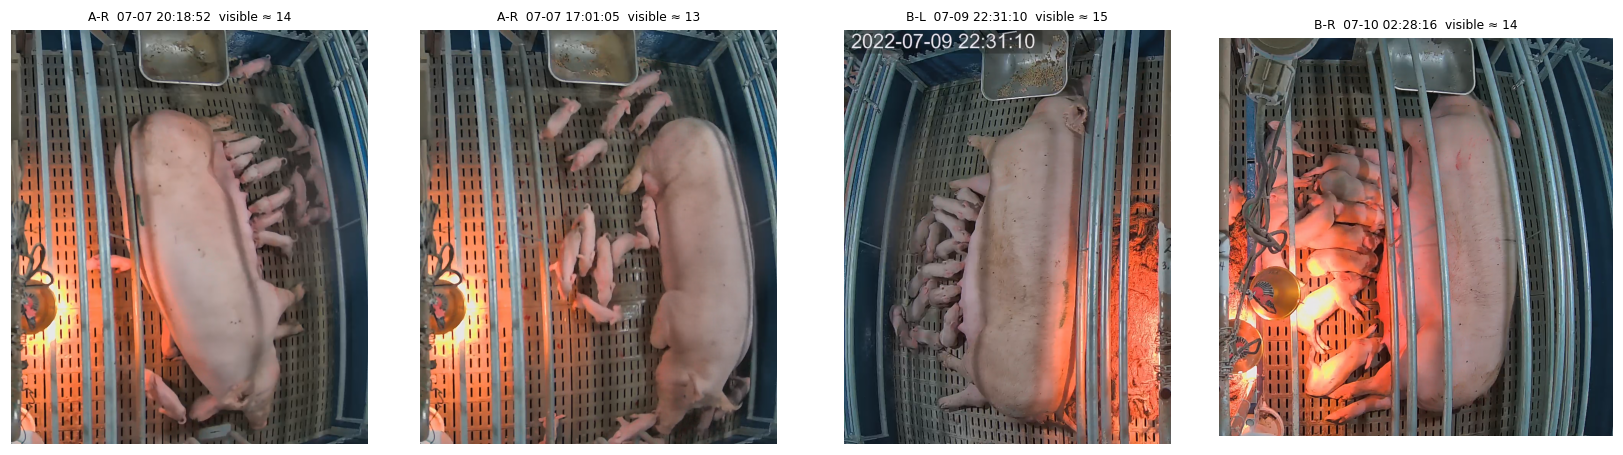

In [7]:
LITTERS = {"A-R": ("A", "R"), "B-L": ("B", "L"), "B-R": ("B", "R")}
CONTROL = {"A-L": ("A", "L")}
PEN_OF = {**LITTERS, **CONTROL}
RECS = {cam: [v for v in VIDEOS if VIDEOS[v]["kind"] == "raw" and VIDEOS[v]["camera"] == cam] for cam in "AB"}

def litter_count_table(conf=0.25, tag=""):
    rows = []
    for lit, (cam, pen) in PEN_OF.items():
        for r in RECS[cam]:
            n = count_series(r, conf=conf, pen=pen, camera=cam, tag=tag)
            ns = rolling_median_int(n, int(round(FPS[r])))
            rows.append(dict(pen=lit, rec=r, start=START[r], hours=len(n) / FPS[r] / 3600, max_visible_1s=int(ns.max()),
                             p95_visible=float(np.quantile(ns, 0.95)), median_visible=float(np.median(ns))))
    return pd.DataFrame(rows)

LCT = litter_count_table()
display(LCT.pivot_table(index="pen", values=["hours", "max_visible_1s", "p95_visible"],
                        aggfunc={"hours": "sum", "max_visible_1s": "max", "p95_visible": "max"}).round(2))
save_table(LCT, "S2_visible_count_per_pen_recording")

LITTER_VISUAL = pd.DataFrame([
    dict(pen="A-R", rec="A_f269", t_s=28.1, clock="2022-07-07 20:18:52", visible=14,
         note="14 piglets visible + 1 piglet hidden under the sow (TR1, onset 4 s earlier) -> at least 15"),
    dict(pen="A-R", rec="A_f257", t_s=710.3, clock="2022-07-07 17:01:05", visible=13,
         note="sow standing, piglets spread; 1 detection = sow leg (false positive); red spots (likely blood) on the floor"),
    dict(pen="B-L", rec="B_f442", t_s=1032.3, clock="2022-07-09 22:31:10", visible=15,
         note="nursing row + huddle, counted at 2.2x zoom (range 14-16); 1 detection = sow hind leg (false positive)"),
    dict(pen="B-R", rec="B_f456", t_s=579.6, clock="2022-07-10 02:28:16", visible=14,
         note="huddle under the heat lamp, overlapping piglets (range 13-15)"),
])
LITTER_EST = pd.DataFrame([
    dict(pen="A-R", detector_max_1s=int(LCT[LCT.pen == "A-R"].max_visible_1s.max()), visual_count="15-16", reported_estimate="15-17"),
    dict(pen="B-L", detector_max_1s=int(LCT[LCT.pen == "B-L"].max_visible_1s.max()), visual_count="14-16", reported_estimate="14-17"),
    dict(pen="B-R", detector_max_1s=int(LCT[LCT.pen == "B-R"].max_visible_1s.max()), visual_count="13-15", reported_estimate="13-15"),
])
display(LITTER_VISUAL); display(LITTER_EST)
save_table(LITTER_VISUAL, "T1c_litter_size_visual_counts"); save_table(LITTER_EST, "T1d_litter_size_estimates")

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, r in zip(axes, LITTER_VISUAL.itertuples()):
    cam, pen = LITTERS[r.pen]; x0, x1 = PEN_ROI[cam][pen]
    img = read_frame(r.rec, r.t_s)
    ax.imshow(img[:, x0:x1]); ax.axis("off")
    ax.set_title(f"{r.pen}  {r.clock[5:]}  visible ≈ {r.visible}", fontsize=8)
fig.tight_layout(); save_fig(fig, "S_F1_litter_count_frames"); plt.show()

### 2.4 Event ledger
The 11 manuscript cases were placed on the **time axis of the continuous recordings** using the clip alignment, and the pen (litter) in which each occurred was determined from the data.
Basis for the pen: the change in the number of visible piglets per pen and the maximum sow activity per pen (§5.5) within ±10 s of the event — the pen with the larger value in both is the event pen,
which agreed with visual inspection (frames before and after the event).

In [8]:
EV_DEF = [
    # id, manuscript label, clip, type, onset (s within the clip), hidden, visible, crushed, manuscript description
    ("TR1", "Trapping case 1 (Fig 2a)", "T1", "trapping", 24.0, 1, 0, np.nan, "1 hidden trapped piglet"),
    ("TR2", "Trapping case 2 (Fig 2b)", "T2", "trapping", 13.0, 1, 0, np.nan, "1 hidden trapped piglet"),
    ("TR3", "Trapping case 3 (Fig 2c)", "T3", "trapping", 30.0, 1, 1, np.nan, "1 hidden + 1 visible"),
    ("TR4", "Trapping case 4 (Fig 2d)", "T4", "trapping", 30.0, 1, 1, np.nan, "1 hidden + 1 visible"),
    ("TR5", "Trapping case 5 (Fig 2e)", "T5", "trapping", 30.0, 1, 1, np.nan, "1 hidden + 1 visible"),
    ("TR6", "Trapping case 6 (Fig 2f)", "T6", "trapping", 30.0, 8, 0, np.nan, "8 hidden (sow rolled over litter)"),
    ("CR1", "Crushing case 1 (Fig 1a)", "C1", "crushing", 30.0, np.nan, np.nan, 1, "lateral->sternal, ~90% visible"),
    ("CR2", "Crushing case 2 (Fig 1b)", "C2", "crushing", 30.0, np.nan, np.nan, 1, "head trapped, ~70% visible"),
    ("CR3", "Crushing case 3 (Fig 1c)", "C3", "crushing", 30.0, np.nan, np.nan, 1, "under rump, ~30% visible"),
    ("CR4", "Crushing case 4 (Fig 1d)", "C4", "crushing", 30.0, np.nan, np.nan, 2, "sow rolled, 2 piglets"),
    ("CR5", "Crushing case 5 (Fig 1e)", "C5", "crushing", 30.0, np.nan, np.nan, 2, "lateral->sternal, 2 piglets"),
]
EV = pd.DataFrame(EV_DEF, columns=["event_id", "manuscript", "clip", "type", "onset_in_clip_s", "n_hidden", "n_visible",
                                   "n_crushed", "description"])
EV = EV.merge(ALIGN[["clip", "source", "offset_s"]], on="clip").rename(columns={"source": "rec"})
EV["camera"] = EV.rec.str[0]
EV["onset_s"] = (EV.offset_s + EV.onset_in_clip_s).round(2)          # time within the continuous recording
EV["onset_abs"] = [START[r] + pd.to_timedelta(s, unit="s") for r, s in zip(EV.rec, EV.onset_s)]
EV["n_trapped_total"] = EV.n_hidden + EV.n_visible

# --- data-driven pen assignment -------------------------------------------------------------
def pen_evidence(r, cam, onset_s, w=10.0):
    out = {}
    for pen in PEN_ROI[cam]:
        n = count_series(r, pen=pen, camera=cam); f = FPS[r]; k = int(onset_s * f)
        before = np.median(n[max(0, k - int(w * f)):k]); after = np.median(n[k:k + int(w * f)])
        mot = pen_motion(r, pen, cam); peak = mot[max(0, k - int(15 * f)):k + int(15 * f)].max()
        out[pen] = (after - before, peak)
    return out

ev_pen = []
for e in EV.itertuples():
    pe = pen_evidence(e.rec, e.camera, e.onset_s)
    best = max(pe, key=lambda p: abs(pe[p][0]) + 50 * pe[p][1])
    ev_pen.append(dict(event_id=e.event_id, **{f"dCount_{p}": v[0] for p, v in pe.items()},
                       **{f"motionPeak_{p}": round(v[1], 3) for p, v in pe.items()}, pen=best))
EVP = pd.DataFrame(ev_pen)
display(EVP)
EV = EV.merge(EVP[["event_id", "pen"]], on="event_id")
EV["litter"] = EV.camera + "-" + EV.pen

# --- relation between events of the same litter (independence) -------------------------------
EV = EV.sort_values("onset_abs").reset_index(drop=True)
EPISODE_GAP_S = 180          # pre-specified: events < 3 min apart in the same litter = same episode
ep, rel = [], []
cur = 0
for i, e in EV.iterrows():
    prev = EV[(EV.litter == e.litter) & (EV.onset_abs < e.onset_abs)]
    if len(prev):
        p = prev.iloc[-1]; gap = (e.onset_abs - p.onset_abs).total_seconds()
        rel.append(f"{gap:.0f} s after {p.event_id}")
        if gap <= EPISODE_GAP_S:
            ep.append(ep[prev.index[-1]]); continue
    else:
        rel.append("")
    cur += 1; ep.append(f"EP{cur}")
EV["previous_event_same_litter"] = rel
EV["episode"] = ep
EV["used_for"] = "test only (thresholds selected on other litters, §9)"
EV["sow_id"] = "not recorded (pen label used)"
FARROW_CONTEXT = {   # video evidence, see §11
    "A-R": "farrowing activity at 16:49-17:01 on 07-07 (person handling piglets, red spots - likely blood - on the floor); completion time unknown",
    "B-L": "07-09 13:47-14:01 only ~8-9 piglets visible (vs ~15 from 22:13), reddened teats, dark wet object at the hindquarters -> farrowing probably in progress",
}
EV["farrowing_context"] = [FARROW_CONTEXT["B-L"] if (e.litter == "B-L" and e.onset_abs < pd.Timestamp("2022-07-09 15:00"))
                           else (FARROW_CONTEXT["A-R"] if e.litter == "A-R" else "after farrowing (litter ~15 visible)")
                           for e in EV.itertuples()]
for c in ["piglet_ids", "trapping_end_time", "outcome(survived/died)", "death_confirmation"]:
    EV[c] = "not recorded"
LEDGER = EV[["event_id", "manuscript", "litter", "episode", "type", "clip", "rec", "onset_s", "onset_abs", "n_hidden",
             "n_visible", "n_crushed", "description", "previous_event_same_litter", "used_for", "sow_id", "farrowing_context",
             "piglet_ids", "trapping_end_time", "outcome(survived/died)", "death_confirmation"]]
save_table(LEDGER, "T1_event_ledger")
display(LEDGER.iloc[:, :15])

,event_id,dCount_L,dCount_R,motionPeak_L,motionPeak_R,pen
0,TR1,0.0,2.0,0.001,0.146,R
1,TR2,0.0,5.0,0.000,0.287,R
2,TR3,0.0,0.0,0.077,0.235,R
3,TR4,-4.0,1.0,0.186,0.056,L
4,TR5,6.0,0.0,0.225,0.207,L
5,TR6,-3.0,0.0,0.187,0.022,L
6,CR1,0.0,2.0,0.013,0.154,R
7,CR2,0.0,0.0,0.024,0.090,R
8,CR3,1.0,1.0,0.036,0.004,L
9,CR4,1.0,-2.0,0.277,0.094,L


,event_id,manuscript,litter,episode,type,clip,rec,onset_s,onset_abs,n_hidden,n_visible,n_crushed,description,previous_event_same_litter,used_for
0,TR2,Trapping case 2 (Fig 2b),A-R,EP1,trapping,T2,A_kt1958,13.00,2022-07-07 19:26:20.000,1.0,0.0,NaN,1 hidden trapped piglet,,test only (thresholds selected on other litter...
1,TR1,Trapping case 1 (Fig 2a),A-R,EP2,trapping,T1,A_f269,24.00,2022-07-07 20:18:48.000,1.0,0.0,NaN,1 hidden trapped piglet,3148 s after TR2,test only (thresholds selected on other litter...
2,CR1,Crushing case 1 (Fig 1a),A-R,EP2,crushing,C1,A_f269,154.47,2022-07-07 20:20:58.470,NaN,NaN,1.0,"lateral->sternal, ~90% visible",130 s after TR1,test only (thresholds selected on other litter...
3,TR3,Trapping case 3 (Fig 2c),A-R,EP3,trapping,T3,A_kt2044,464.79,2022-07-08 00:47:32.790,1.0,1.0,NaN,1 hidden + 1 visible,15994 s after CR1,test only (thresholds selected on other litter...
4,CR2,Crushing case 2 (Fig 1b),A-R,EP3,crushing,C2,A_kt2044,502.00,2022-07-08 00:48:10.000,NaN,NaN,1.0,"head trapped, ~70% visible",37 s after TR3,test only (thresholds selected on other litter...
5,TR4,Trapping case 4 (Fig 2d),B-L,EP4,trapping,T4,B_f413,250.20,2022-07-09 13:51:56.200,1.0,1.0,NaN,1 hidden + 1 visible,,test only (thresholds selected on other litter...
6,CR3,Crushing case 3 (Fig 1c),B-L,EP5,crushing,C3,B_f413,801.29,2022-07-09 14:01:07.290,NaN,NaN,1.0,"under rump, ~30% visible",551 s after TR4,test only (thresholds selected on other litter...
7,CR4,Crushing case 4 (Fig 1d),B-L,EP6,crushing,C4,B_f442,84.38,2022-07-09 22:15:21.380,NaN,NaN,2.0,"sow rolled, 2 piglets",29654 s after CR3,test only (thresholds selected on other litter...
8,TR5,Trapping case 5 (Fig 2e),B-L,EP6,trapping,T5,B_f442,160.47,2022-07-09 22:16:37.470,1.0,1.0,NaN,1 hidden + 1 visible,76 s after CR4,test only (thresholds selected on other litter...
9,CR5,Crushing case 5 (Fig 1e),B-L,EP7,crushing,C5,B_f449,239.21,2022-07-10 00:20:14.210,NaN,NaN,2.0,"lateral->sternal, 2 piglets",7417 s after TR5,test only (thresholds selected on other litter...


In [9]:
n_lit = EV.litter.nunique(); n_ep = EV.episode.nunique()
summary_ds = pd.DataFrame({
    "item": ["annotated events (manuscript)", "litters with events", "independent episodes (gap > 3 min)",
             "trapped piglets (sum over trapping cases)", "crushed piglets (sum over crushing cases)",
             "litters monitored without annotated events", "pens without litter (control)"],
    "value": [len(EV), n_lit, n_ep, int(EV.n_trapped_total.sum()), int(EV.n_crushed.sum()),
              ", ".join(sorted(set(LITTERS) - set(EV.litter))), ", ".join(CONTROL)]})
display(summary_ds); save_table(summary_ds, "T1b_dataset_structure")
display(Markdown(tr(f"""
**핵심 사실 (R1-1)**: 원고의 11개 사례는 **{n_lit}개 복(A-R, B-L)** 에서만 나왔고, 3분 이내로 붙어 있는 사례를 묶으면
**{n_ep}개 에피소드**다. 특히 T3와 C2는 같은 원본에서 37초 차이(구간이 겹침), T1과 C1은 130초 차이, C4와 T5는 76초 차이다.
원고의 '5마리 모돈 모두에서 압사 발생' 서술은 이 영상들과 맞지 않는다. 모돈 번호가 기록되지 않았으므로 논문에는 펜 이름(A-R, B-L, B-R)으로
복을 구분하고, '2개 복에서 8개 독립 에피소드(11개 클립)'로 표본 구조를 고쳐 써야 한다. 압사 클립이 트래핑 클립의 결과인지(같은 새끼인지)는
영상만으로 확정할 수 없으므로, 3분 이내 사례를 같은 에피소드로 묶어 독립성 문제를 피했다.
연속 녹화에는 사건이 주석되지 않은 복(B-R)과 산자가 없는 펜(A-L)도 있어, 이들은 오경보 추정에 쓴다.
""", f"""
**Key facts (R1-1)**: the 11 manuscript cases come from only **{n_lit} litters (A-R, B-L)**; grouping cases less than 3 min apart gives
**{n_ep} episodes**. T3 and C2 are 37 s apart in the same recording (overlapping windows), T1 and C1 130 s, and C4 and T5 76 s.
The manuscript's statement that 'crushing occurred in all five sows' does not match these videos. Sow IDs were not recorded, so the paper should identify the litters by pen name
(A-R, B-L, B-R) and describe the sample as '8 independent episodes (11 clips) from 2 litters'. Whether a crushing clip is the outcome of a trapping clip (the same piglet)
cannot be established from the video alone, so cases less than 3 min apart were grouped into one episode to avoid the independence problem.
The continuous recordings also contain a litter without annotated events (B-R) and a pen without a litter (A-L); these are used to estimate false alarms.
""")))

,item,value
0,annotated events (manuscript),11
1,litters with events,2
2,independent episodes (gap > 3 min),8
3,trapped piglets (sum over trapping cases),16
4,crushed piglets (sum over crushing cases),7
5,litters monitored without annotated events,B-R
6,pens without litter (control),A-L



**Key facts (R1-1)**: the 11 manuscript cases come from only **2 litters (A-R, B-L)**; grouping cases less than 3 min apart gives
**8 episodes**. T3 and C2 are 37 s apart in the same recording (overlapping windows), T1 and C1 130 s, and C4 and T5 76 s.
The manuscript's statement that 'crushing occurred in all five sows' does not match these videos. Sow IDs were not recorded, so the paper should identify the litters by pen name
(A-R, B-L, B-R) and describe the sample as '8 independent episodes (11 clips) from 2 litters'. Whether a crushing clip is the outcome of a trapping clip (the same piglet)
cannot be established from the video alone, so cases less than 3 min apart were grouped into one episode to avoid the independence problem.
The continuous recordings also contain a litter without annotated events (B-R) and a pen without a litter (A-L); these are used to estimate false alarms.


### 2.5 Unannotated candidate event windows (excluded windows)
The result videos of the previous study [9] (`piglet crushing result/results3.avi`, `results4.avi`) used two windows that are not in the manuscript (07-07 22:11 and 07-08 02:12, both A-R)
as event windows. Visually the sow lies down among the piglets, but the manuscript has no annotation for them, so they are treated as **excluded windows** in the continuous-video evaluation
(alerts inside them are counted neither as TP nor as FP).

In [10]:
EXCLUDE = pd.DataFrame([
    dict(rec="A_kt1959", pen="R", start_s=504.0, end_s=504.0 + 214.0, source="prior study results3.avi (07-07 22:11:19)"),
    dict(rec="A_kt2001", pen="R", start_s=314.0, end_s=314.0 + 164.0, source="prior study results4.avi (07-08 02:12:08)"),
])
display(EXCLUDE)

,rec,pen,start_s,end_s,source
0,A_kt1959,R,504.0,718.0,prior study results3.avi (07-07 22:11:19)
1,A_kt2001,R,314.0,478.0,prior study results4.avi (07-08 02:12:08)


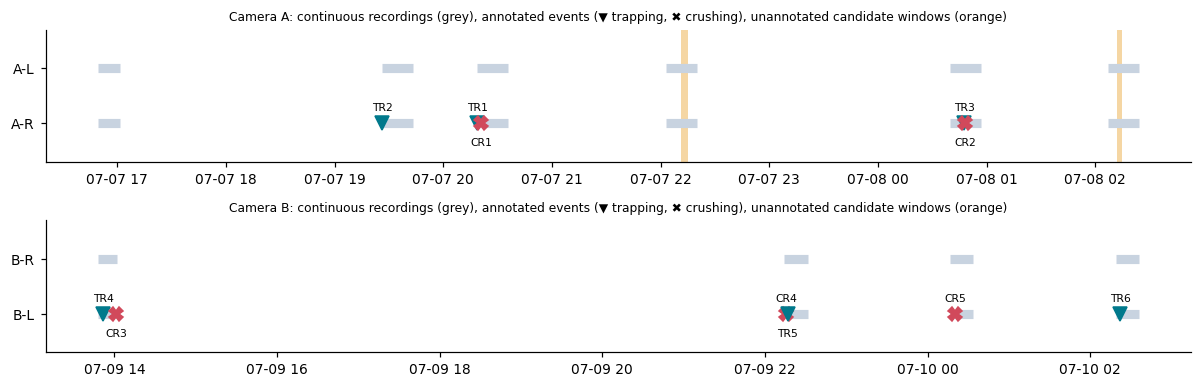

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(11, 3.6), sharey=False)
for ax, cam in zip(axes, "AB"):
    for r in RECS[cam]:
        t0 = START[r]; t1 = t0 + pd.to_timedelta(NFR[r] / FPS[r], unit="s")
        for j, (lit, (c, p)) in enumerate([(k, v) for k, v in PEN_OF.items() if v[0] == cam]):
            ax.plot([t0, t1], [j, j], lw=6, color="#c8d3e0", solid_capstyle="butt")
    labs = [k for k, v in PEN_OF.items() if v[0] == cam]
    last_t = None; up = True
    for e in EV[EV.camera == cam].sort_values("onset_abs").itertuples():
        j = labs.index(e.litter)
        ax.plot(e.onset_abs, j, marker="v" if e.type == "trapping" else "X", ms=9,
                color="#d1495b" if e.type == "crushing" else "#00798c")
        close = last_t is not None and (e.onset_abs - last_t).total_seconds() < 1800
        up = (not up) if close else True; last_t = e.onset_abs
        ax.annotate(e.event_id, (e.onset_abs, j), xytext=(0, 8 if up else -15), textcoords="offset points", ha="center", fontsize=7)
    for x in EXCLUDE.itertuples():
        if x.rec in RECS[cam]:
            a = START[x.rec] + pd.to_timedelta(x.start_s, unit="s"); b = START[x.rec] + pd.to_timedelta(x.end_s, unit="s")
            ax.axvspan(a, b, color="#edae49", alpha=.5, lw=0)
    ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs); ax.set_ylim(-0.7, len(labs) - 0.3)
    ax.set_title(f"Camera {cam}: continuous recordings (grey), annotated events (▼ trapping, ✖ crushing), unannotated candidate windows (orange)", fontsize=8)
fig.tight_layout(); save_fig(fig, "F1_event_timeline"); plt.show()

### 2.6 Target population: litters in the neonatal (high crushing risk) period (R1-5, scope of the results)
Crushing and trapping are concentrated in the first days after farrowing (especially the first 3–4 days) and become rare as the piglets grow. The **intended use of the system is monitoring during that period**,
so the target population of the evaluation was defined as 'litters in the neonatal period'. Litters were classified **independently of the alert results**, on two grounds only:
1. **Evidence of farrowing on the recording day** (§11.1): A-R (07-07 16:49–17:01 farrowing management, blood stains), B-L (07-09 13:47–14:01 signs of ongoing farrowing). No farrowing evidence for B-R.
2. **Piglet length ÷ sow length** (a size index independent of camera height and lens): the sow length is the mean of two snout–tail-base measurements per pen on frames in which the sow lies straight
   (lines in the figure below); the piglet length is the median diagonal of piglet boxes (conf ≥ 0.5) that do not overlap any other box (all continuous recordings, every 1 s).

B-R piglets are about 1.4 times longer relative to the sow (about 3 times heavier, length cubed) and there is no farrowing evidence, so B-R was classified as **a litter past the high-risk period**.
The main results are reported for the target population (A-R + B-L); results for all three litters including B-R are given as a **sensitivity analysis**.
(The manuscript's description 'recorded for 24 h from the start of farrowing' does not fit B-R, so the Methods must state the nature of this litter.)

,litter,rec,t_s,snout_x,snout_y,tail_x,tail_y,sow_length_px
0,A-R,A_kt1959,600,1410,175,1450,1000,826.0
1,A-R,A_kt2001,600,1385,180,1615,955,808.0
2,B-L,B_f413,100,595,195,370,915,754.0
3,B-L,B_f442,900,610,180,450,1005,840.0
4,B-R,B_f442,300,1490,120,1450,1005,886.0
5,B-R,B_f449,500,1500,150,1555,1015,867.0


,litter,n_isolated_piglet_boxes,piglet_diag_median_px,sow_length_px,farrowing_evidence_on_recording_day,piglet_to_sow_length,relative_to_newborn_litters,approx_body_mass_ratio,group
0,A-R,15958,139.360,817.0,yes,0.171,0.995,0.985,target: neonatal (high-risk) litter
1,B-L,8788,137.293,797.0,yes,0.172,1.005,1.015,target: neonatal (high-risk) litter
2,B-R,6801,215.695,876.5,no,0.246,1.436,2.959,older litter (sensitivity analysis only)


target litters: ['A-R', 'B-L'] | all litters (sensitivity): ['A-R', 'B-L', 'B-R']


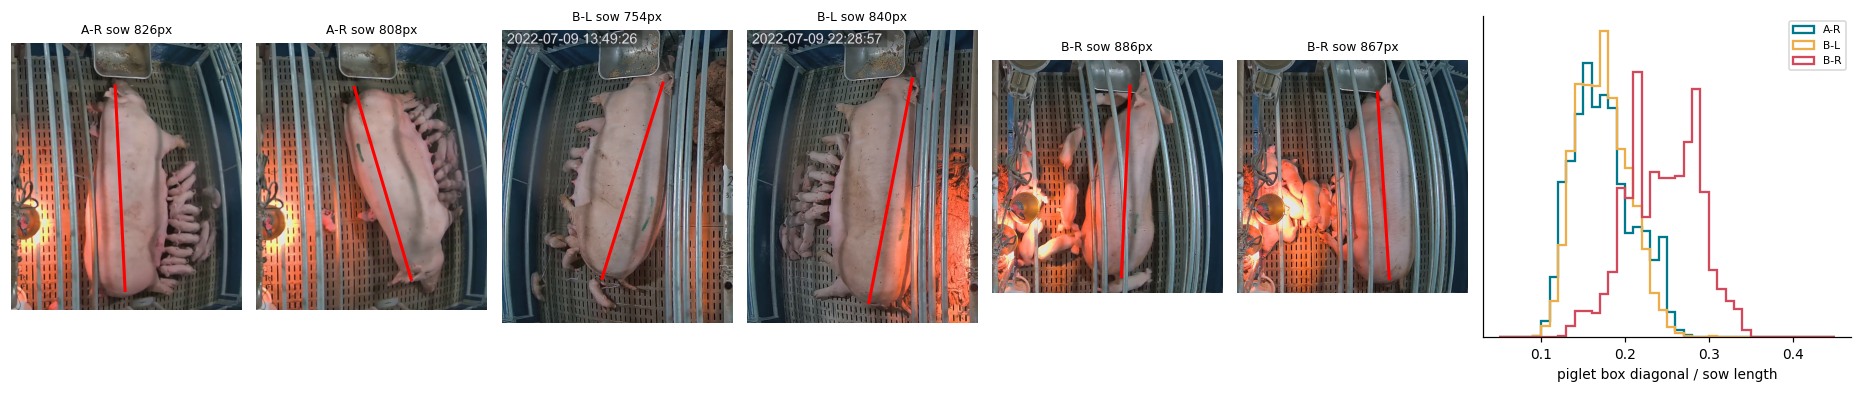

In [12]:
SOW_MEASURE = pd.DataFrame([   # snout -> tail base (1920x1080 px), sow lying straight
    ("A-R", "A_kt1959", 600, 1410, 175, 1450, 1000), ("A-R", "A_kt2001", 600, 1385, 180, 1615, 955),
    ("B-L", "B_f413", 100, 595, 195, 370, 915), ("B-L", "B_f442", 900, 610, 180, 450, 1005),
    ("B-R", "B_f442", 300, 1490, 120, 1450, 1005), ("B-R", "B_f449", 500, 1500, 150, 1555, 1015)],
    columns=["litter", "rec", "t_s", "snout_x", "snout_y", "tail_x", "tail_y"])
SOW_MEASURE["sow_length_px"] = np.hypot(SOW_MEASURE.snout_x - SOW_MEASURE.tail_x, SOW_MEASURE.snout_y - SOW_MEASURE.tail_y).round(0)

def isolated_piglet_diag(lit):
    cam, pen = LITTERS[lit]; out = []
    for r in RECS[cam]:
        fr = frames_dets(r, conf=0.5, classes=(0,), pen=pen, camera=cam)
        for k in range(0, len(fr), int(round(FPS[r]))):
            d = fr[k]
            if len(d) == 0:
                continue
            if len(d) == 1:
                out.append(float(np.hypot(d[0, 2] - d[0, 0], d[0, 3] - d[0, 1]))); continue
            b = d[:, :4]
            ix = np.clip(np.minimum(b[:, None, 2], b[None, :, 2]) - np.maximum(b[:, None, 0], b[None, :, 0]), 0, None)
            iy = np.clip(np.minimum(b[:, None, 3], b[None, :, 3]) - np.maximum(b[:, None, 1], b[None, :, 1]), 0, None)
            ar = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
            iou = ix * iy / (ar[:, None] + ar[None, :] - ix * iy + 1e-9); np.fill_diagonal(iou, 0)
            iso = iou.max(1) < 0.05
            out += list(np.hypot(d[iso, 2] - d[iso, 0], d[iso, 3] - d[iso, 1]))
    return np.array(out)

PIG_DIAG = cached("isolated_piglet_diag", lambda: {lit: isolated_piglet_diag(lit) for lit in LITTERS})
SIZE = pd.DataFrame([dict(litter=lit, n_isolated_piglet_boxes=len(PIG_DIAG[lit]),
                          piglet_diag_median_px=float(np.median(PIG_DIAG[lit])),
                          sow_length_px=float(SOW_MEASURE[SOW_MEASURE.litter == lit].sow_length_px.mean()),
                          farrowing_evidence_on_recording_day={"A-R": "yes", "B-L": "yes", "B-R": "no"}[lit]) for lit in LITTERS])
SIZE["piglet_to_sow_length"] = SIZE.piglet_diag_median_px / SIZE.sow_length_px
ref = SIZE[SIZE.farrowing_evidence_on_recording_day == "yes"].piglet_to_sow_length.mean()
SIZE["relative_to_newborn_litters"] = SIZE.piglet_to_sow_length / ref
SIZE["approx_body_mass_ratio"] = SIZE.relative_to_newborn_litters ** 3
SIZE["group"] = np.where(SIZE.farrowing_evidence_on_recording_day == "yes", "target: neonatal (high-risk) litter",
                         "older litter (sensitivity analysis only)")
display(SOW_MEASURE); display(SIZE.round(3))
save_table(SOW_MEASURE, "S9_sow_length_measurements"); save_table(SIZE.round(4), "T1e_litter_age_proxy")
TARGET_LITTERS = list(SIZE[SIZE.group.str.startswith("target")].litter)
ALL_LITTERS = list(LITTERS)
print("target litters:", TARGET_LITTERS, "| all litters (sensitivity):", ALL_LITTERS)

fig, axes = plt.subplots(1, 7, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1, 1, 1.6]))
for ax, r in zip(axes[:6], SOW_MEASURE.itertuples()):
    cam, pen = LITTERS[r.litter]; x0, x1 = PEN_ROI[cam][pen]
    fr = read_frame(r.rec, r.t_s)
    ax.imshow(fr[:, x0:x1]); ax.plot([r.snout_x - x0, r.tail_x - x0], [r.snout_y, r.tail_y], "r-", lw=2)
    ax.axis("off"); ax.set_title(f"{r.litter} sow {r.sow_length_px:.0f}px", fontsize=8)
for lit, col in zip(LITTERS, ["#00798c", "#edae49", "#d1495b"]):
    axes[6].hist(PIG_DIAG[lit] / SIZE[SIZE.litter == lit].sow_length_px.iloc[0], bins=np.linspace(0.05, 0.45, 41),
                 histtype="step", lw=1.5, density=True, color=col, label=lit)
axes[6].set_xlabel("piglet box diagonal / sow length"); axes[6].legend(fontsize=7); axes[6].set_yticks([])
fig.tight_layout(); save_fig(fig, "F12_piglet_to_sow_size"); plt.show()

## 3. Detector training data: leakage check and leakage-free detectors (R1-3)

The manuscript only states that the detector was taken from the previous study [9]. The YOLOv5s weights used in the manuscript are lost; the weights left in the zip (`train/weights/best.pt`) are a
**YOLOv8s** (Ultralytics 8.0.137, trained 2023-07-19, imgsz 416, 3 classes: piglet / crushing (= visible trapping) / crushed).
YOLOv5s was therefore retrained (§3.2). The 204 labelled images in `new data origin` are the **complete set of originals** of the training data of [9] and of the provided detector
(confirmed with the GitHub repositories of [9], §3.3). Each original was compared with every frame of the continuous recordings to trace **which recording and which second it came from** (`prep_04_align.py`).

In [13]:
TRM = pd.read_csv(ROOT / "meta/train_image_matches.csv")
TRM["matched"] = TRM.mad < 5
TRM["group"] = [VIDEOS[v]["camera"] if m else "other farm (side-view crates, not in any video)"
                for v, m in zip(TRM.best_video, TRM.matched)]
TRM["t_s"] = [f / FPS[v] if m else np.nan for f, v, m in zip(TRM.best_frame, TRM.best_video, TRM.matched)]

def train_img_status(r):
    if not r.matched:
        return pd.Series(dict(in_eval_clip="", dist_to_event_s=np.nan, in_candidate_window=False))
    clips = [c.clip for c in ALIGN.itertuples() if c.source == r.best_video and c.offset_s <= r.t_s <= c.offset_s + c.clip_len_s]
    e = EV[EV.rec == r.best_video]
    d = float((e.onset_s - r.t_s).abs().min()) if len(e) else np.inf
    cw = any((x.rec == r.best_video) and (x.start_s <= r.t_s <= x.end_s) for x in EXCLUDE.itertuples())
    return pd.Series(dict(in_eval_clip=",".join(clips), dist_to_event_s=d, in_candidate_window=cw))

TRM = pd.concat([TRM, TRM.apply(train_img_status, axis=1)], axis=1)
save_table(TRM, "S3_training_image_provenance")
TRM_M = TRM[TRM.matched]
leak = pd.DataFrame({
    "item": ["detector-training originals ([9] / provided YOLOv8s, complete set)", "  from other farm (not in evaluation videos)", "  from July-2022 evaluation cameras",
             "  ... inside an evaluation clip window", "  ... within ±60 s of an annotated event",
             "  ... from the same continuous recording as an annotated event", "  ... inside an unannotated candidate window"],
    "n": [len(TRM), int((~TRM.matched).sum()), len(TRM_M), int((TRM_M.in_eval_clip != "").sum()), int((TRM_M.dist_to_event_s <= 60).sum()),
          int(TRM_M.best_video.isin(EV.rec).sum()), int(TRM_M.in_candidate_window.sum())]})
display(leak); save_table(leak, "T2_detector_training_leakage")
display(TRM_M[TRM_M.in_eval_clip != ""].groupby("in_eval_clip").size().rename("n_training_images_inside_clip").to_frame().T)
display(Markdown(tr("""
**해석**: 학습 원본 204장 중 51장이 평가 클립 구간 안의 프레임이다(T1, T2, C2, C4, C5). §3.3 에서 보듯 이 51장은 모두 [9]와 제공 검출기의
학습 분할에 (증강본으로) 들어갔다. 원 학습 실행의
`val_batch*_labels.jpg` 모자이크에도 2022-07-07 19:26:30(T2 구간), 2022-07-08 02:12–02:13 같은 평가 카메라 시각이 보인다.
따라서 원고의 결과는 **resubstitution(재대입) 결과**에 해당하며(R1-3 마지막 문단), 검증 성능으로 제시하면 안 된다.
→ 아래에서 평가 카메라를 뺀 이미지로 같은 레시피로 재학습한 **누수 없는 검출기**를 만들고, 주요 결과를 그 검출기로도 다시 계산한다.
""", """
**Interpretation**: 51 of the 204 training originals are frames from inside evaluation-clip windows (T1, T2, C2, C4, C5). As shown in §3.3, all 51 were in the
training split of [9] and of the provided detector (as augmented copies). The `val_batch*_labels.jpg` mosaics of the original training run
also show evaluation-camera times such as 2022-07-07 19:26:30 (T2 window) and 2022-07-08 02:12–02:13.
The manuscript's results are therefore **resubstitution results** (last paragraph of R1-3) and must not be presented as validation performance.
→ Below, **leakage-free detectors** are retrained with the same recipe on images without the evaluation cameras, and the main results are recomputed with them.
""")))

,item,n
0,detector-training originals ([9] / provided YO...,204
1,from other farm (not in evaluation videos),102
2,from July-2022 evaluation cameras,102
3,... inside an evaluation clip window,51
4,... within ±60 s of an annotated event,65
5,... from the same continuous recording as an...,68
6,... inside an unannotated candidate window,32


in_eval_clip,C2,C4,C5,T1,T2
n_training_images_inside_clip,8,9,7,10,17



**Interpretation**: 51 of the 204 training originals are frames from inside evaluation-clip windows (T1, T2, C2, C4, C5). As shown in §3.3, all 51 were in the
training split of [9] and of the provided detector (as augmented copies). The `val_batch*_labels.jpg` mosaics of the original training run
also show evaluation-camera times such as 2022-07-07 19:26:30 (T2 window) and 2022-07-08 02:12–02:13.
The manuscript's results are therefore **resubstitution results** (last paragraph of R1-3) and must not be presented as validation performance.
→ Below, **leakage-free detectors** are retrained with the same recipe on images without the evaluation cameras, and the main results are recomputed with them.


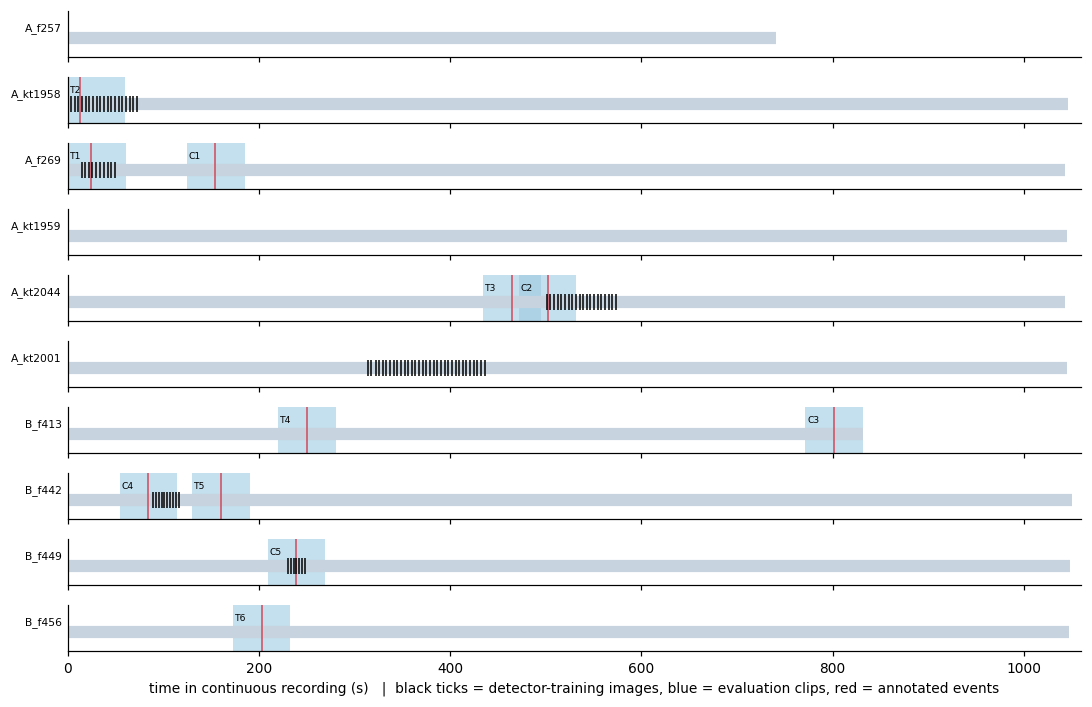

In [14]:
fig, axes = plt.subplots(len(RECS["A"]) + len(RECS["B"]), 1, figsize=(10, 6.5), sharex=False)
for ax, r in zip(axes, RECS["A"] + RECS["B"]):
    dur = NFR[r] / FPS[r]
    ax.plot([0, dur], [0, 0], color="#c8d3e0", lw=8, solid_capstyle="butt")
    ax.set_ylim(-0.6, 0.9)                  # fixed y-range so that the clip labels stay inside their own row
    for c in ALIGN[ALIGN.source == r].itertuples():
        ax.axvspan(c.offset_s, c.offset_s + c.clip_len_s, color="#9ecae1", alpha=.6, lw=0)
        ax.text(c.offset_s + 2, 0.45, c.clip, fontsize=6, va="center")
    for e in EV[EV.rec == r].itertuples():
        ax.axvline(e.onset_s, color="#d1495b", lw=1)
    tt = TRM_M[TRM_M.best_video == r].t_s
    ax.plot(tt, np.zeros(len(tt)), "|", color="k", ms=10)
    ax.set_yticks([]); ax.set_xlim(0, 1060); ax.set_ylabel(r, rotation=0, ha="right", fontsize=7)
    if ax is not axes[-1]:
        ax.tick_params(labelbottom=False)
axes[-1].set_xlabel("time in continuous recording (s)   |  black ticks = detector-training images, blue = evaluation clips, red = annotated events")
fig.tight_layout(); save_fig(fig, "F2_training_image_leakage"); plt.show()

### 3.1 Performance of the leakage-free detectors (camera hold-out)
`prep_05_train_lolo_detectors.py` retrained YOLOv8s with the same base settings as the original training (COCO-pretrained YOLOv8s, imgsz 416, batch 16, seed 0) for up to 100 epochs (patience 20).
The original training generated 48 offline augmented copies per original and trained for 50 epochs (§3.3); here only the originals were used, without offline augmentation. A retraining with exactly the recipe of [9] is in §3.4.
- **holdA**: trained without any camera-A image → for evaluation on camera A (A-R)
- **holdB**: trained without any camera-B image → for evaluation on camera B (B-L, B-R)
- **ctrl**: all 204 images (including the leakage) — control with the same recipe

Camera-B images show both B-L and B-R, so a split by litter is impossible; the split is by camera.
The table below evaluates each detector on the **camera-A images / camera-B images** (holdA→A and holdB→B are the leakage-free performance).
The original detector (original) and ctrl were trained on these images, so their values are in-sample.

In [15]:
FOLDS = json.load(open(ROOT / "cache/detector_training/folds.json"))
display(pd.DataFrame({k: dict(n_images=v["n_images"], **{f"n_{s}": n for s, n in v["split"].items()}) for k, v in FOLDS["folds"].items()}).T)

def heldout_eval():
    from ultralytics import YOLO
    import shutil
    src = ROOT / "data/new data origin"
    rows = []
    for cam in "AB":
        d = ROOT / f"cache/detector_training/heldout_{cam}"
        if d.exists():
            shutil.rmtree(d)
        (d / "images/val").mkdir(parents=True); (d / "labels/val").mkdir(parents=True)
        for im in TRM[TRM.group == cam].image:
            stem = im[:-4]; safe = stem.replace(" ", "_").replace("(", "").replace(")", "")
            os.symlink(src / im, d / "images/val" / f"{safe}.jpg")
            lab = src / f"{stem}.txt"
            (d / "labels/val" / f"{safe}.txt").write_text(lab.read_text() if lab.exists() else "")
        (d / "data.yaml").write_text(f"path: {d}\ntrain: images/val\nval: images/val\nnames:\n  0: piglet\n  1: crushing\n  2: crushed\n")
        dets = {"original": ROOT / "extracted/train/train/weights/best.pt", "ctrl": ROOT / FOLDS["folds"]["ctrl"]["weights"],
                f"hold{cam} (leakage-free)": ROOT / FOLDS["folds"][f"hold{cam}"]["weights"]}
        for name, w in dets.items():
            r = YOLO(str(w)).val(data=str(d / "data.yaml"), imgsz=416, batch=16, verbose=False, plots=False, device=0,
                                 project=str(ROOT / "cache/detector_training/val_runs"), name=f"{cam}_{name.split()[0]}", exist_ok=True)
            row = dict(test_images=f"camera {cam} (n={len(TRM[TRM.group == cam])})", detector=name,
                       P=r.box.mp, R=r.box.mr, mAP50=r.box.map50, mAP50_95=r.box.map)
            for ci, cn in r.names.items():
                if ci in list(r.box.ap_class_index):
                    j = list(r.box.ap_class_index).index(ci); row[f"AP50_{cn}"] = r.box.ap50[j]
            rows.append(row)
    return pd.DataFrame(rows)

HELD = cached("heldout_detector_eval", heldout_eval, needs_raw=True)
display(HELD.round(3)); save_table(HELD.round(4), "T3_detector_heldout_performance")

,n_images,n_val,n_train
holdA,120,18,102
holdB,187,28,159
ctrl,204,31,173


,test_images,detector,P,R,mAP50,mAP50_95,AP50_piglet,AP50_crushing,AP50_crushed
0,camera A (n=84),original,0.995,0.991,0.995,0.863,0.995,0.995,0.995
1,camera A (n=84),ctrl,0.964,0.957,0.987,0.672,0.974,0.992,0.994
2,camera A (n=84),holdA (leakage-free),0.355,0.542,0.369,0.180,0.584,0.318,0.204
3,camera B (n=17),original,0.980,0.975,0.991,0.885,0.983,0.995,0.995
4,camera B (n=17),ctrl,0.919,0.920,0.962,0.693,0.935,0.968,0.984
5,camera B (n=17),holdB (leakage-free),0.314,0.407,0.292,0.127,0.496,0.116,0.264


,test_images,detector,P,R,mAP50,mAP50_95,AP50_piglet,AP50_crushing,AP50_crushed
0,camera A (n=84),original,0.9954,0.9910,0.9949,0.8633,0.9947,0.9950,0.9950
1,camera A (n=84),ctrl,0.9636,0.9569,0.9870,0.6721,0.9744,0.9922,0.9945
2,camera A (n=84),holdA (leakage-free),0.3555,0.5419,0.3686,0.1798,0.5843,0.3178,0.2038
3,camera B (n=17),original,0.9797,0.9752,0.9909,0.8855,0.9828,0.9950,0.9950
4,camera B (n=17),ctrl,0.9192,0.9198,0.9623,0.6932,0.9347,0.9683,0.9840
5,camera B (n=17),holdB (leakage-free),0.3139,0.4074,0.2920,0.1268,0.4962,0.1158,0.2639


### 3.2 YOLOv5s retraining and detector selection
The YOLOv5s weights used in the manuscript are lost. YOLOv5s was retrained on all 204 training originals with the **original (anchor-based) YOLOv5 code** (ultralytics/yolov5, COCO-pretrained `yolov5s.pt`,
the default YOLOv5 schedule of 300 epochs, patience 50; `prep_06_train_yolov5.py`) and compared with YOLOv8s on the same splits (ctrl / holdA / holdB) and input sizes (416, 640).

**Detector selection rule (pre-specified, without looking at the evaluation events)**: for each hold-out fold, the (architecture, input size) with the highest mAP50-95 on the **validation split made from that fold's training-camera images**
is chosen (smaller input on ties). The selected fold detectors are the **main detector** of the revised analysis (`_best`: camera-A videos ← holdA model, camera B ← holdB model).
Choosing the detector whose event results look best would be choosing on the test data, so this was not done. Instead, the results of every detector are reported in §8 and §9.

In [16]:
V5DIR = ROOT / "cache/detector_training_v5"
VS = pd.read_csv(V5DIR / "val_summary.csv")
SEL = json.load(open(V5DIR / "selected.json"))
display(VS[["fold", "arch", "imgsz", "val_mAP50", "val_mAP50_95", "best_epoch", "epochs_run"]].round(3))
save_table(VS.drop(columns=["run"]).round(4), "T3b_detector_training_validation")
display(Markdown(tr("**선택 결과** — ", "**Selected** — ") + ", ".join(f"{k}: {v['arch']} @ {v['imgsz']} (val mAP50-95 {float(v['val_mAP50_95']):.3f})"
                                                  for k, v in SEL.items())))

def heldout_eval_all():
    """every detector on the held-out camera images (holdX -> camera X is the leakage-free number)"""
    import shutil, subprocess
    from ultralytics import YOLO
    rows = []
    for cam in "AB":
        d8 = ROOT / f"cache/detector_training/heldout_{cam}"            # built in §3.1
        d5 = V5DIR / f"heldout_{cam}"                                   # separate copy for YOLOv5 label caches
        if not (d5 / "data.yaml").exists():
            (d5 / "images/val").mkdir(parents=True, exist_ok=True); (d5 / "labels/val").mkdir(parents=True, exist_ok=True)
            for im in (d8 / "images/val").iterdir():
                os.symlink(os.path.realpath(im), d5 / "images/val" / im.name)
                shutil.copy(d8 / "labels/val" / (im.stem + ".txt"), d5 / "labels/val" / (im.stem + ".txt"))
            (d5 / "data.yaml").write_text(f"path: {d5}\ntrain: images/val\nval: images/val\nnames:\n  0: piglet\n  1: crushing\n  2: crushed\n")
        models = [("provided YOLOv8s", "provided (all data)", "v8s", 416, str(ROOT / "extracted/train/train/weights/best.pt"))]
        for r in VS[VS.fold.isin(["ctrl", f"hold{cam}"])].itertuples():
            models.append((f"{r.arch}-{r.imgsz}", "leakage-free" if r.fold.startswith("hold") else "ctrl (all 204 images)", r.arch, r.imgsz,
                           str(ROOT / r.weights)))
        for name, training, arch, imgsz, w in models:
            if arch == "v8s":
                m = YOLO(w).val(data=str(d8 / "data.yaml"), imgsz=int(imgsz), batch=16, verbose=False, plots=False, device=0,
                                project=str(V5DIR / "val_tmp"), name="u", exist_ok=True).box
                res = dict(P=m.mp, R=m.mr, mAP50=m.map50, mAP50_95=m.map)
            else:
                out = subprocess.run([sys.executable, str(ROOT / "analysis/v5_val.py"), w, str(d5 / "data.yaml"), str(int(imgsz))],
                                     capture_output=True, text=True, cwd=str(ROOT / "third_party/yolov5")).stdout
                res = json.loads([l for l in out.splitlines() if l.startswith("RESULT ")][-1][7:])
            rows.append(dict(test_camera=cam, detector=name, training=training, **res))
    return pd.DataFrame(rows)

HELD_ALL = cached("heldout_detector_eval_all", heldout_eval_all, needs_raw=True)
piv = HELD_ALL.pivot_table(index=["training", "detector"], columns="test_camera", values=["mAP50", "mAP50_95"]).round(3)
display(piv); save_table(HELD_ALL.round(4), "T3c_detector_heldout_all")
display(Markdown(tr("""
`leakage-free` 행만이 '처음 보는 카메라' 성능이다. `provided`·`ctrl` 은 평가 카메라 이미지를 학습에 쓴 in-sample 값이다.
""", """
Only the `leakage-free` rows show performance on an 'unseen camera'. `provided` and `ctrl` were trained on images of the evaluation cameras (in-sample values).
""")))

DETECTORS = {
    "provided YOLOv8s (training incl. evaluation frames)": "",
    "YOLOv8s-416 leakage-free": "_lolo",
    "YOLOv5s-416 leakage-free": "_v5lolo",
    "selected leakage-free (pre-specified rule)": "_best",
}
MAIN_TAG = "_best"
MAIN_NAME = "selected leakage-free detector (" + ", ".join(f"{k}: {v['arch']}@{v['imgsz']}" for k, v in SEL.items()) + ")"
print("main detector for §7-§13:", MAIN_NAME)

,fold,arch,imgsz,val_mAP50,val_mAP50_95,best_epoch,epochs_run
0,ctrl,v5s,416,0.968,0.675,217,268
1,ctrl,v8s,416,0.967,0.677,43,64
2,ctrl,v5s,640,0.981,0.698,184,235
3,ctrl,v8s,640,0.968,0.680,14,35
4,holdA,v5s,416,0.970,0.665,115,166
5,holdA,v8s,416,0.978,0.668,77,98
6,holdA,v5s,640,0.920,0.586,54,105
7,holdA,v8s,640,0.958,0.568,39,60
8,holdB,v5s,416,0.986,0.668,161,212
9,holdB,v8s,416,0.983,0.668,55,76


**Selected** — holdA: v8s @ 416 (val mAP50-95 0.668), holdB: v8s @ 640 (val mAP50-95 0.688)

mAP50        mAP50_95       
test_camera                                 A      B        A      B
training              detector                                      
ctrl (all 204 images) v5s-416           0.987  0.976    0.676  0.660
                      v5s-640           0.995  0.993    0.713  0.717
                      v8s-416           0.987  0.962    0.672  0.693
                      v8s-640           0.983  0.980    0.658  0.647
leakage-free          v5s-416           0.484  0.227    0.218  0.090
                      v5s-640           0.257  0.440    0.087  0.184
                      v8s-416           0.369  0.292    0.180  0.127
                      v8s-640           0.386  0.276    0.177  0.129
provided (all data)   provided YOLOv8s  0.995  0.991    0.863  0.885


Only the `leakage-free` rows show performance on an 'unseen camera'. `provided` and `ctrl` were trained on images of the evaluation cameras (in-sample values).


main detector for §7-§13: selected leakage-free detector (holdA: v8s@416, holdB: v8s@640)


### 3.3 Training data and split of the previous study [9] (4 GitHub repository archives)
The manuscript's detector came from the previous study [9]. Its 4 GitHub repositories (`image_augmentation`, `yolov4/5/8_piglet_crushing`) were audited with `prep_11_previous_study_dataset.py`.
- **Augmentation**: 1 original → original + 4 colour variants (ColorJitter brightness 3, contrast 2, saturation 2, hue 0.3) + 3 with a random-noise rectangle = 8 images → each rotated by 90/180/270° and flipped left–right and top–bottom
  → **48 images per original, 9792 in total**.
- **Split**: the 9792 images were shuffled and split 70:30 at random (`train_test_split(test_size=0.3, random_state=1000)`), not grouped by original.
  For YOLOv4, every third image of the augmented-image folder was likewise held out for testing.
- **Mapping to the originals**: the original of augmented image `train (N)[_rotation]` is `train ((N−1)//8+1)`. All boxes of the 9792 images in the repository's YOLOv5 label caches match the boxes of the corresponding original
  (with the rotation/flip applied), which confirms this mapping and that the 204 images of 'new data origin' are the complete set of training originals.

In [17]:
PREV = json.load(open(ROOT / "meta/previous_study_summary.json"))
PREV_IMG = pd.read_csv(ROOT / "meta/previous_study_images.csv")
PREV_ORIG = pd.read_csv(ROOT / "meta/previous_study_originals.csv").merge(
    TRM.assign(original=TRM.image.str[:-4])[["original", "group", "best_video", "t_s", "in_eval_clip"]], on="original", how="left")
assert len(PREV_ORIG) == len(TRM) == 204 and PREV["label_check"]["labels_match_original"] == PREV["label_check"]["images_in_label_caches"]

def prev_split_rows(repo):
    s_ = PREV[f"split_{repo}"]
    n_tr = PREV_ORIG.set_index("original")[f"{repo}_train"]
    c = n_tr.loc[PREV_IMG[(PREV_IMG.split_list == repo) & (PREV_IMG.split == "val")].original].to_numpy()
    ev = PREV_ORIG[PREV_ORIG.in_eval_clip.fillna("") != ""][f"{repo}_train"]
    return [f"{s_['n_train']} / {s_['n_val']}",
            f"{s_['originals_with_train_copies']} / {s_['originals_with_val_copies']} / {s_['originals_only_in_val']}",
            f"{int((c > 0).sum())} / {len(c)} ({100 * (c > 0).mean():.0f}%)",
            f"{np.median(c):.0f} ({c.min()}–{c.max()})",
            f"{int((ev > 0).sum())} of {len(ev)} / {ev.median():.0f} ({ev.min()}–{ev.max()})"]

g_ = PREV_ORIG.group.where(PREV_ORIG.group.isin(["A", "B", "N"]), "other farm")
same = lambda v: [v, v]
prev_tab = pd.DataFrame(
    [["originals (= data/new data origin, complete set)", *same(f"{len(PREV_ORIG)} (labels of all {PREV['label_check']['images_in_label_caches']} augmented images verified)")],
     ["  other farm / camera A / camera B / camera N", *same(" / ".join(str(int((g_ == k).sum())) for k in ["other farm", "A", "B", "N"]))],
     ["  inside an evaluation clip (by clip)", *same(f"{int((PREV_ORIG.in_eval_clip.fillna('') != '').sum())} ("
                                                     + ", ".join(f"{k} {v}" for k, v in PREV_ORIG[PREV_ORIG.in_eval_clip.fillna('') != ''].in_eval_clip.value_counts().sort_index().items()) + ")")],
     ["augmented images per original / total", *same(f"48 (8 colour/noise copies x 6 rotations/flips) / {PREV['split_yolov5']['n_train'] + PREV['split_yolov5']['n_val']}")],
     ["split unit", *same("augmented image (random 70/30, seed 1000), not the original frame")]]
    + [[lab, *vals] for lab, vals in zip(
        ["augmented images: train / val", "originals with copies in train / in val / only in val",
         "val images with other copies of the same frame in train", "train copies of the same frame per val image: median (range)",
         "evaluation-clip originals in train: n / median copies (range)"],
        zip(prev_split_rows("yolov5"), prev_split_rows("yolov8")))],
    columns=["item", "[9] YOLOv5 split", "[9] YOLOv8 split (data of the provided YOLOv8s)"])
display(prev_tab); save_table(prev_tab, "T2b_previous_study_dataset")

nbk, pv, dv = PREV["notebooks"], PREV["provided_yolov8s"], PREV["demo_video_test_video1"]
fv = lambda repo, k: nbk[repo]["final_validation"][k]["metrics"]["all"]
aug_ = PREV["augmentation"]
settings = pd.DataFrame([
    ("archives (commit, last change)", "; ".join(f"{k} {v['commit'][:7]} ({v['date']})" for k, v in PREV["archives"].items())),
    ("offline augmentation", f"ColorJitter {', '.join(aug_['color_jitter'])}; {aug_['noise_patches']['n']} noise patches in the top-left "
                             f"{aug_['noise_patches']['region_px']} px; {', '.join(aug_['geometric'])}; JPEG {aug_['jpeg_save']}"),
    ("split (YOLOv5 / YOLOv8 notebooks)", nbk["yolov5"]["split"][0]),
    ("split (YOLOv4)", PREV["yolov4"]["split_rule"]),
    ("YOLOv5s training", nbk["yolov5"]["train"][0].lstrip("!")),
    ("YOLOv5s final validation (2938 val images): mAP50 / mAP50-95", f"{fv('yolov5', 0)['mAP50']:.3f} / {fv('yolov5', 0)['mAP50_95']:.3f}"),
    ("YOLOv5s val.py at img 640: mAP50 / mAP50-95", f"{fv('yolov5', 1)['mAP50']:.3f} / {fv('yolov5', 1)['mAP50_95']:.3f}"),
    ("YOLOv8s notebook training", nbk["yolov8"]["train"][0]),
    ("YOLOv8s notebook final validation: mAP50 / mAP50-95", f"{fv('yolov8', 0)['mAP50']:.3f} / {fv('yolov8', 0)['mAP50_95']:.3f}"),
    ("provided YOLOv8s (train zip): args", ", ".join(f"{k}={v}" for k, v in pv["args"].items())),
    ("provided YOLOv8s: final validation mAP50 / mAP50-95 (its own validation list)", f"{pv['final_val']['mAP50']:.3f} / {pv['final_val']['mAP50_95']:.3f}"),
    ("provided YOLOv8s: args.yaml data = yolov8 archive's data.yaml", f"{pv['uses_yolov8_archive_dataset']} (Ultralytics label cache in the archive = YOLOv8 val list: "
                                                                       f"{PREV['ultralytics_label_cache']['equals_yolov8_val_list']})"),
    ("YOLOv4 (darknet) cfg", ", ".join(f"{k}={v}" for k, v in PREV["yolov4"]["cfg"].items())),
    ("demo video test_video1.mp4", f"{dv['best']['video']} {dv['window_s'][0]:.1f}–{dv['window_s'][1]:.1f} s ({dv['window_clock'][0]} – {dv['window_clock'][1][11:]}); "
                                   f"overlaps clips {', '.join(dv['overlapping_clips'])}; training originals from this window: {dv['training_originals_inside'][0]}–{dv['training_originals_inside'][-1]}"),
], columns=["item", "value"])
display(settings); save_table(settings, "T2c_previous_study_settings")
s5 = PREV["split_yolov5"]
display(Markdown(tr(f"""
**해석**: [9]의 검증 이미지 {s5['n_val']}장 모두에 대해 같은 프레임의 다른 증강본이 학습 쪽에 있었다(중앙값 {s5['train_copies_per_val_image']['median']:.0f}장).
즉 [9]의 검증은 **같은 사진의 회전·색 변형본을 맞히는 시험**이어서, [9]와 원고가 인용한 검출 정확도(원고 333행 AP 0.993/0.998, mAP 0.997; 694행 99.8%)는
독립 검증값이 아니다. 평가 클립 안의 원본 51장도 모두 학습 쪽에 들어갔다. 제공 YOLOv8s 는 같은 데이터 폴더(YOLOv8 분할)로 50 epoch 학습되었다
(args.yaml). 그때의 분할 목록이 저장소의 목록과 같은지는 확인할 수 없지만, 원본당 48장을 70:30 으로 무작위로 나누면 한 원본의 48장이 모두 검증 쪽에 갈 확률은
0.3^48 ≈ 10^-25 이므로 '모든 원본이 학습에 들어갔다'는 결론은 같다.
[9]의 시연 영상(test_video1)은 평가 클립 T1·C1 과 같은 녹화 구간이고, 학습 원본 train (1)–(10) 이 이 구간에서 뽑혔다.
→ 리뷰어 R1-3 의 요구(겹침 공개, 무작위 프레임 분할의 문제)에 대한 근거. 누수 없는 검출 성능은 §3.1–3.2(카메라 hold-out)와 §3.4 에 있다.
""", f"""
**Interpretation**: for every one of the {s5['n_val']} validation images of [9], other augmented copies of the same frame were in the training split (median {s5['train_copies_per_val_image']['median']:.0f}).
The validation of [9] was therefore **a test of recognising rotated and colour-shifted copies of the same photographs**, and the detection accuracies cited by [9] and by the manuscript (manuscript line 333: AP 0.993/0.998, mAP 0.997; line 694: 99.8%)
are not independent validation values. All 51 originals from inside the evaluation clips were in the training split as well. The provided YOLOv8s was trained for 50 epochs on the same data folder (YOLOv8 split)
(args.yaml). Whether its split lists were the same as those in the repository cannot be checked, but when the 48 copies of an original are split 70:30 at random, the probability that all 48 go to validation is
0.3^48 ≈ 10^-25, so the conclusion 'every original was in the training data' is the same.
The demo video of [9] (test_video1) is the same recording window as evaluation clips T1 and C1, and the training originals train (1)–(10) were sampled from this window.
→ Evidence for reviewer comment R1-3 (disclosure of the overlap, problem of a random frame-level split). Leakage-free detection performance is in §3.1–3.2 (camera hold-out) and §3.4.
""")))

,item,[9] YOLOv5 split,[9] YOLOv8 split (data of the provided YOLOv8s)
0,"originals (= data/new data origin, complete set)",204 (labels of all 9792 augmented images verif...,204 (labels of all 9792 augmented images verif...
1,other farm / camera A / camera B / camera N,102 / 84 / 17 / 1,102 / 84 / 17 / 1
2,inside an evaluation clip (by clip),"51 (C2 8, C4 9, C5 7, T1 10, T2 17)","51 (C2 8, C4 9, C5 7, T1 10, T2 17)"
3,augmented images per original / total,48 (8 colour/noise copies x 6 rotations/flips)...,48 (8 colour/noise copies x 6 rotations/flips)...
4,split unit,"augmented image (random 70/30, seed 1000), not...","augmented image (random 70/30, seed 1000), not..."
5,augmented images: train / val,6854 / 2938,6854 / 2938
6,originals with copies in train / in val / only...,204 / 204 / 0,204 / 204 / 0
7,val images with other copies of the same frame...,2938 / 2938 (100%),2938 / 2938 (100%)
8,train copies of the same frame per val image: ...,33 (25–41),33 (24–41)
9,evaluation-clip originals in train: n / median...,51 of 51 / 34 (27–41),51 of 51 / 33 (25–41)


,item,value
0,"archives (commit, last change)",augmentation 415ab12 (2023-12-21); yolov4 c582...
1,offline augmentation,"ColorJitter brightness=3, contrast=2, saturati..."
2,split (YOLOv5 / YOLOv8 notebooks),"train_img_list, val_img_list = train_test_spli..."
3,split (YOLOv4),process.py: 1 of every 3 images (file-system o...
4,YOLOv5s training,python train.py --img 416 --batch 16 --epochs ...
5,YOLOv5s final validation (2938 val images): mA...,0.992 / 0.742
6,YOLOv5s val.py at img 640: mAP50 / mAP50-95,0.994 / 0.725
7,YOLOv8s notebook training,model.train(data='/mydrive/yolov8_piglet_crush...
8,YOLOv8s notebook final validation: mAP50 / mAP...,0.989 / 0.703
9,provided YOLOv8s (train zip): args,"model=yolov8s.pt, data=/mydrive/yolov8_piglet_..."



**Interpretation**: for every one of the 2938 validation images of [9], other augmented copies of the same frame were in the training split (median 33).
The validation of [9] was therefore **a test of recognising rotated and colour-shifted copies of the same photographs**, and the detection accuracies cited by [9] and by the manuscript (manuscript line 333: AP 0.993/0.998, mAP 0.997; line 694: 99.8%)
are not independent validation values. All 51 originals from inside the evaluation clips were in the training split as well. The provided YOLOv8s was trained for 50 epochs on the same data folder (YOLOv8 split)
(args.yaml). Whether its split lists were the same as those in the repository cannot be checked, but when the 48 copies of an original are split 70:30 at random, the probability that all 48 go to validation is
0.3^48 ≈ 10^-25, so the conclusion 'every original was in the training data' is the same.
The demo video of [9] (test_video1) is the same recording window as evaluation clips T1 and C1, and the training originals train (1)–(10) were sampled from this window.
→ Evidence for reviewer comment R1-3 (disclosure of the overlap, problem of a random frame-level split). Leakage-free detection performance is in §3.1–3.2 (camera hold-out) and §3.4.


### 3.4 The training recipe of [9] reproduced — how much does removing the leakage change the performance? (sensitivity analysis)
`prep_12_train_previous_recipe.py` reproduces the recipe of [9]: 48 offline augmented copies per original (the same operations as the code of [9], fixed random seeds), YOLOv5s (`models/yolov5s.yaml` + COCO `yolov5s.pt`),
input 416, batch 16, 50 epochs, default hyperparameters (hyp.scratch-low), seed 0. Four runs that differ only in the split:

| Run | Originals used for training | Split | Meaning |
|---|---|---|---|
| r9_split | all 204 | [9]'s own split lists (random over augmented images) | reproduces [9]'s validation values — augmented copies of the same frame on both sides |
| r9_ctrl | all 204 | by original (the same 173/31 originals as ctrl in §3.1) | removes only the duplicated copies — recordings and cameras are shared |
| r9_holdA | 120 (camera A removed) | by original (the same originals as holdA in §3.1) | leakage-free for camera A (A-R) |
| r9_holdB | 187 (camera B removed) | by original (the same originals as holdB in §3.1) | leakage-free for camera B (B-L, B-R) |

The splits by original use the same originals as the fold detectors of §3.1–3.2, so the only difference from those detectors is the **training recipe**.
**The main detector (pre-specified rule, §3.2) is not changed**: choosing a detector after seeing these results would mean choosing on the evaluation data. Instead, the leakage-free detector with the recipe of [9]
(camera-A videos ← r9_holdA, camera-B videos ← r9_holdB, tag `_r9lolo`) is added to `DETECTORS` and reported in §8.3 and §9.

In [18]:
R9DIR = ROOT / "cache/detector_training_r9"
R9 = pd.read_csv(R9DIR / "val_summary.csv")

def heldout_eval_r9():
    """[9]-recipe detectors (and, for comparison, the §3.2 YOLOv5s-416 fold detectors) on the original camera images of §3.1;
    held out only for r9_holdX / v5s holdX -> camera X"""
    import subprocess
    models = [(r.run, r.weights) for r in R9.itertuples()] + [
        (f"v5s-416 hold{c} (§3.2 recipe)", VS[(VS.fold == f"hold{c}") & (VS.arch == "v5s") & (VS.imgsz == 416)].weights.iloc[0]) for c in "AB"]
    jobs = [(run, w, "own val", R9DIR / "data" / run / "data.yaml") for run, w in models if run in ("r9_split", "r9_ctrl")]
    jobs += [(run, w, "fold val (originals)", V5DIR / "data" / run[3:] / "data.yaml") for run, w in models if run in ("r9_ctrl", "r9_holdA", "r9_holdB")]
    jobs += [(run, w, cam, V5DIR / f"heldout_{cam}/data.yaml") for cam in "AB" for run, w in models if "hold" not in run or f"hold{cam}" in run]
    rows = []
    for run, w, test, data in jobs:
        out = subprocess.run([sys.executable, str(ROOT / "analysis/v5_val.py"), str(ROOT / w), str(data), "416"],
                             capture_output=True, text=True, cwd=str(ROOT / "third_party/yolov5")).stdout
        res = json.loads([l for l in out.splitlines() if l.startswith("RESULT ")][-1][7:])
        rows.append(dict(test_camera=test, run=run, camera_in_training=("hold" not in run) if test in ("A", "B") else None, **res))
    return pd.DataFrame(rows)

HELD_R9 = cached("heldout_detector_eval_r9", heldout_eval_r9, needs_raw=True)
R9V = R9.set_index("run")
R9H = HELD_R9.set_index(["run", "test_camera"])
n_cam = {c: len(TRM[TRM.group == c]) for c in "AB"}
_r9row = lambda setting, run, on, r: dict(setting=setting, run=run, evaluated_on=on, mAP50=r["mAP50"], mAP50_95=r["mAP50_95"],
                                        AP50_piglet=r.get("AP50_piglet", np.nan))
ladder = pd.DataFrame(
    [_r9row("[9] split (augmented images at random): own validation", "r9_split", f"{int(R9V.loc['r9_split', 'n_val'])} val images", R9H.loc[("r9_split", "own val")]),
     _r9row("[9] original run (notebook output, for comparison): own validation", "[9]", "2938 val images",
          dict(fv("yolov5", 0), AP50_piglet=nbk["yolov5"]["final_validation"][0]["metrics"]["piglet"]["mAP50"])),
     _r9row("split by original (same cameras): own validation", "r9_ctrl", f"{int(R9V.loc['r9_ctrl', 'n_val'])} val images (31 originals x 48)",
          R9H.loc[("r9_ctrl", "own val")])]
    + [_r9row(f"camera {c} held out: unseen camera {c}", f"r9_hold{c}", f"camera {c} originals (n={n_cam[c]})", R9H.loc[(f"r9_hold{c}", c)])
       for c in "AB"]
    + [_r9row(f"for comparison, §3.2 recipe: YOLOv5s-416 leakage-free, unseen camera {c}", f"v5s-416 hold{c}", f"camera {c} originals (n={n_cam[c]})",
            R9H.loc[(f"v5s-416 hold{c} (§3.2 recipe)", c)]) for c in "AB"]
    + [_r9row(f"for comparison, §3.1 recipe: YOLOv8s-416 leakage-free, unseen camera {c}", f"v8s-416 hold{c}", f"camera {c} originals (n={n_cam[c]})",
            HELD[(HELD.detector == f"hold{c} (leakage-free)") & HELD.test_images.str.startswith(f"camera {c}")].iloc[0]) for c in "AB"]
    + [_r9row(f"for comparison: {r} on camera {c} images (camera in training)", r, f"camera {c} originals (n={n_cam[c]})", R9H.loc[(r, c)])
       for c in "AB" for r in ("r9_split", "r9_ctrl")])
display(ladder.round(3)); save_table(ladder.round(4), "T3d_previous_recipe_leakage_ladder")
display(R9.drop(columns="weights").round(3))
# the criterion of the pre-specified selection rule (§3.2): mAP50-95 on the fold's own validation ORIGINALS (unaugmented)
fold_val = pd.concat([
    VS[VS.fold.isin(["ctrl", "holdA", "holdB"])][["fold", "arch", "imgsz", "val_mAP50", "val_mAP50_95"]].assign(recipe="§3.1–3.2 (originals only)"),
    pd.DataFrame([dict(fold=r[3:], arch="v5s", imgsz=416, val_mAP50=R9H.loc[(r, "fold val (originals)"), "mAP50"],
                       val_mAP50_95=R9H.loc[(r, "fold val (originals)"), "mAP50_95"], recipe="[9] (x48 offline augmentation, 50 epochs)")
                  for r in ("r9_ctrl", "r9_holdA", "r9_holdB")])]).sort_values(["fold", "val_mAP50_95"], ascending=[True, False])
display(fold_val.round(3)); save_table(fold_val.round(4), "T3e_fold_validation_with_previous_recipe")
_rule = {f: fold_val[fold_val.fold == f].sort_values(["val_mAP50_95", "imgsz"], ascending=[False, True]).iloc[0] for f in ("holdA", "holdB")}
_r9f = {f: fold_val[(fold_val.fold == f) & fold_val.recipe.str.startswith("[9]")].iloc[0] for f in ("holdA", "holdB")}
_would = [f for f in ("holdA", "holdB") if _rule[f].recipe.startswith("[9]")]
_v5 = lambda c, k: R9H.loc[(f"v5s-416 hold{c} (§3.2 recipe)", c), k]
_v8 = lambda c, k: HELD[(HELD.detector == f"hold{c} (leakage-free)") & HELD.test_images.str.startswith(f"camera {c}")].iloc[0][k]
display(Markdown(tr(f"""
**해석**
- **분할의 효과(같은 학습 방식)**: [9]처럼 증강본을 무작위로 나누면 검증 mAP50 {R9H.loc[('r9_split', 'own val'), 'mAP50']:.3f}
  ([9] 원 실행 {fv('yolov5', 0)['mAP50']:.3f}), 원본 단위로 나누면 {R9H.loc[('r9_ctrl', 'own val'), 'mAP50']:.3f},
  처음 보는 카메라에서는 A {R9H.loc[('r9_holdA', 'A'), 'mAP50']:.3f} / B {R9H.loc[('r9_holdB', 'B'), 'mAP50']:.3f} 이다.
  [9]의 검증값은 같은 사진의 증강본을 맞힌 값이라 처음 보는 카메라에서의 성능을 대표하지 못한다.
- **학습 방식의 효과(같은 카메라 hold-out)**: 처음 보는 카메라에서 [9] 방식은 mAP50 A {R9H.loc[('r9_holdA', 'A'), 'mAP50']:.2f} / B {R9H.loc[('r9_holdB', 'B'), 'mAP50']:.2f},
  새끼(piglet) AP50 A {R9H.loc[('r9_holdA', 'A'), 'AP50_piglet']:.2f} / B {R9H.loc[('r9_holdB', 'B'), 'AP50_piglet']:.2f} 이다.
  §3.1–3.2 방식은 YOLOv5s-416 mAP50 A {_v5('A', 'mAP50'):.2f} / B {_v5('B', 'mAP50'):.2f}, 새끼 AP50 A {_v5('A', 'AP50_piglet'):.2f} / B {_v5('B', 'AP50_piglet'):.2f};
  YOLOv8s-416 mAP50 A {_v8('A', 'mAP50'):.2f} / B {_v8('B', 'mAP50'):.2f}, 새끼 AP50 A {_v8('A', 'AP50_piglet'):.2f} / B {_v8('B', 'AP50_piglet'):.2f} 이다.
  어느 방식이든 처음 보는 카메라에서는 검증값보다 크게 낮다.
- **주 검출기**: 사전 규칙의 기준(fold 검증 원본의 mAP50-95)으로 [9] 방식은 holdA {_r9f['holdA'].val_mAP50_95:.3f}
  (규칙이 고른 {_rule['holdA'].arch}@{_rule['holdA'].imgsz} {_rule['holdA'].val_mAP50_95:.3f}), holdB {_r9f['holdB'].val_mAP50_95:.3f}
  ({_rule['holdB'].arch}@{_rule['holdB'].imgsz} {_rule['holdB'].val_mAP50_95:.3f}) 이므로,
  {"후보에 있었더라도 선택되지 않았다. 주 검출기는 그대로 둔다." if not _would else "규칙상 " + ", ".join(_would) + " 에서 선택되었을 것이다. 다만 이 검출기는 주 검출기를 정한 뒤에 만든 것이므로 주 검출기는 그대로 두고 민감도 분석으로 보고한다."}
  [9] 방식 누수 없는 검출기의 사건 단위 결과는 §8.3·§9 에 함께 보고한다.
""", f"""
**Interpretation**
- **Effect of the split (same recipe)**: splitting augmented copies at random as in [9] gives a validation mAP50 of {R9H.loc[('r9_split', 'own val'), 'mAP50']:.3f}
  (original run of [9]: {fv('yolov5', 0)['mAP50']:.3f}); splitting by original gives {R9H.loc[('r9_ctrl', 'own val'), 'mAP50']:.3f},
  and on an unseen camera A {R9H.loc[('r9_holdA', 'A'), 'mAP50']:.3f} / B {R9H.loc[('r9_holdB', 'B'), 'mAP50']:.3f}.
  The validation values of [9] measure the recognition of augmented copies of the same photographs and do not represent performance on an unseen camera.
- **Effect of the recipe (same camera hold-out)**: on an unseen camera the [9] recipe gives mAP50 A {R9H.loc[('r9_holdA', 'A'), 'mAP50']:.2f} / B {R9H.loc[('r9_holdB', 'B'), 'mAP50']:.2f},
  piglet AP50 A {R9H.loc[('r9_holdA', 'A'), 'AP50_piglet']:.2f} / B {R9H.loc[('r9_holdB', 'B'), 'AP50_piglet']:.2f}.
  The §3.1–3.2 recipe gives YOLOv5s-416 mAP50 A {_v5('A', 'mAP50'):.2f} / B {_v5('B', 'mAP50'):.2f}, piglet AP50 A {_v5('A', 'AP50_piglet'):.2f} / B {_v5('B', 'AP50_piglet'):.2f};
  YOLOv8s-416 mAP50 A {_v8('A', 'mAP50'):.2f} / B {_v8('B', 'mAP50'):.2f}, piglet AP50 A {_v8('A', 'AP50_piglet'):.2f} / B {_v8('B', 'AP50_piglet'):.2f}.
  With either recipe, performance on an unseen camera is far below the validation values.
- **Main detector**: by the criterion of the pre-specified rule (mAP50-95 on the fold's validation originals) the [9] recipe scores holdA {_r9f['holdA'].val_mAP50_95:.3f}
  (chosen by the rule: {_rule['holdA'].arch}@{_rule['holdA'].imgsz} {_rule['holdA'].val_mAP50_95:.3f}) and holdB {_r9f['holdB'].val_mAP50_95:.3f}
  ({_rule['holdB'].arch}@{_rule['holdB'].imgsz} {_rule['holdB'].val_mAP50_95:.3f}), so
  {"it would not have been selected even as a candidate; the main detector is kept." if not _would else "the rule would have selected it for " + ", ".join(_would) + ". This detector was built after the main detector had been chosen, so the main detector is kept and the [9] recipe is reported as a sensitivity analysis."}
  Event-level results of the leakage-free detector with the [9] recipe are reported in §8.3 and §9.
""")))
DETECTORS["YOLOv5s-416 [9] recipe, leakage-free"] = "_r9lolo"

,setting,run,evaluated_on,mAP50,mAP50_95,AP50_piglet
0,[9] split (augmented images at random): own va...,r9_split,2938 val images,0.992,0.743,0.987
1,"[9] original run (notebook output, for compari...",[9],2938 val images,0.992,0.742,0.985
2,split by original (same cameras): own validation,r9_ctrl,1488 val images (31 originals x 48),0.976,0.662,0.942
3,camera A held out: unseen camera A,r9_holdA,camera A originals (n=84),0.380,0.154,0.669
4,camera B held out: unseen camera B,r9_holdB,camera B originals (n=17),0.426,0.184,0.706
5,"for comparison, §3.2 recipe: YOLOv5s-416 leaka...",v5s-416 holdA,camera A originals (n=84),0.484,0.218,0.568
6,"for comparison, §3.2 recipe: YOLOv5s-416 leaka...",v5s-416 holdB,camera B originals (n=17),0.227,0.090,0.548
7,"for comparison, §3.1 recipe: YOLOv8s-416 leaka...",v8s-416 holdA,camera A originals (n=84),0.369,0.180,0.584
8,"for comparison, §3.1 recipe: YOLOv8s-416 leaka...",v8s-416 holdB,camera B originals (n=17),0.292,0.127,0.496
9,for comparison: r9_split on camera A images (c...,r9_split,camera A originals (n=84),0.992,0.751,0.986


,run,n_train,n_val,val_mAP50,val_mAP50_95,best_epoch,epochs_run,last_val_mAP50,last_val_mAP50_95
0,r9_holdA,4896,864,0.957,0.530,15,50,0.958,0.462
1,r9_holdB,7632,1344,0.984,0.664,42,50,0.985,0.656
2,r9_split,6854,2938,0.992,0.743,49,50,0.992,0.743
3,r9_ctrl,8304,1488,0.976,0.662,48,50,0.976,0.660


,fold,arch,imgsz,val_mAP50,val_mAP50_95,recipe
2,ctrl,v5s,640,0.981,0.698,§3.1–3.2 (originals only)
0,ctrl,v5s,416,0.970,0.683,"[9] (x48 offline augmentation, 50 epochs)"
3,ctrl,v8s,640,0.968,0.680,§3.1–3.2 (originals only)
1,ctrl,v8s,416,0.967,0.677,§3.1–3.2 (originals only)
0,ctrl,v5s,416,0.968,0.675,§3.1–3.2 (originals only)
5,holdA,v8s,416,0.978,0.668,§3.1–3.2 (originals only)
4,holdA,v5s,416,0.970,0.665,§3.1–3.2 (originals only)
6,holdA,v5s,640,0.920,0.586,§3.1–3.2 (originals only)
7,holdA,v8s,640,0.958,0.568,§3.1–3.2 (originals only)
1,holdA,v5s,416,0.973,0.564,"[9] (x48 offline augmentation, 50 epochs)"



**Interpretation**
- **Effect of the split (same recipe)**: splitting augmented copies at random as in [9] gives a validation mAP50 of 0.992
  (original run of [9]: 0.992); splitting by original gives 0.976,
  and on an unseen camera A 0.380 / B 0.426.
  The validation values of [9] measure the recognition of augmented copies of the same photographs and do not represent performance on an unseen camera.
- **Effect of the recipe (same camera hold-out)**: on an unseen camera the [9] recipe gives mAP50 A 0.38 / B 0.43,
  piglet AP50 A 0.67 / B 0.71.
  The §3.1–3.2 recipe gives YOLOv5s-416 mAP50 A 0.48 / B 0.23, piglet AP50 A 0.57 / B 0.55;
  YOLOv8s-416 mAP50 A 0.37 / B 0.29, piglet AP50 A 0.58 / B 0.50.
  With either recipe, performance on an unseen camera is far below the validation values.
- **Main detector**: by the criterion of the pre-specified rule (mAP50-95 on the fold's validation originals) the [9] recipe scores holdA 0.564
  (chosen by the rule: v8s@416 0.668) and holdB 0.681
  (v8s@640 0.688), so
  it would not have been selected even as a candidate; the main detector is kept.
  Event-level results of the leakage-free detector with the [9] recipe are reported in §8.3 and §9.


## 4. Pen ROIs and the masking effect of two pens in one view (R1-8, R2 L90–92)

The manuscript implementation counted N_Tot and N_Det over the whole frame (the `Objects Count` of the original result-video overlay is the sum of two litters).
The revised analysis defines one ROI per pen, separated at the central partition post (by box-centre x), and keeps **N_Tot, N_Det, the HPA state and the tracks separately for each pen**.

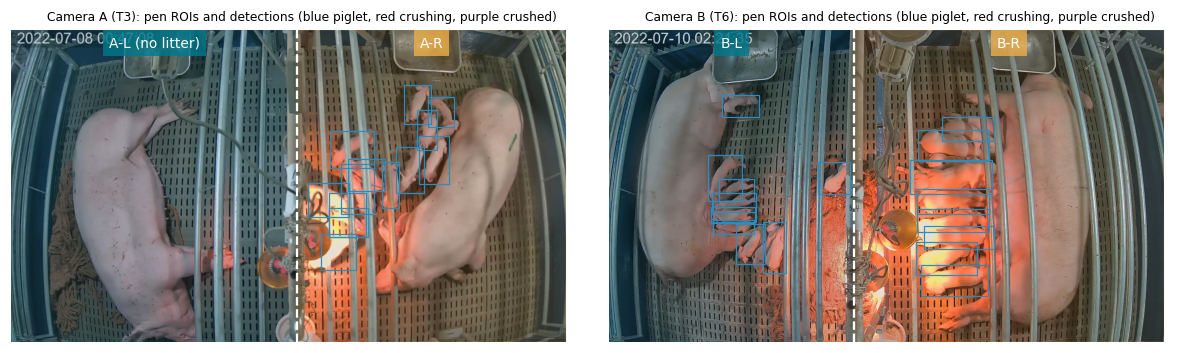

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (vid, t, cam) in zip(axes, [("T3", 5, "A"), ("T6", 5, "B")]):
    ax.imshow(read_frame(vid, t))
    cols = {"L": "#00798c", "R": "#edae49"}
    for pen, (x0, x1) in PEN_ROI[cam].items():
        ax.axvspan(x0, x1, color=cols[pen], alpha=.12)
        lab = f"{cam}-{pen}" + (" (no litter)" if (cam, pen) == ("A", "L") else "")
        ax.text((x0 + x1) / 2, 60, lab, color="w", ha="center", fontsize=9, bbox=dict(fc=cols[pen], alpha=.8, lw=0))
    ax.axvline(PEN_ROI[cam]["L"][1], color="w", lw=1.5, ls="--")
    d = load_dets(vid); d = d[(d.frame == int(t * FPS[vid])) & (d.conf >= .25)]
    for b in d.itertuples():
        ax.add_patch(plt.Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False, lw=.8,
                                   ec={0: "#2b8cbe", 1: "#e34a33", 2: "#984ea3"}[b.cls]))
    ax.set_title(f"Camera {cam} ({vid}): pen ROIs and detections (blue piglet, red crushing, purple crushed)", fontsize=8)
    ax.axis("off")
fig.tight_layout(); save_fig(fig, "F3_pen_rois"); plt.show()

**Masking when two pens are counted together**: the per-pen changes in the number of visible piglets over 5-s intervals (ΔL, ΔR) in the camera-B continuous recordings show
how often piglets disappear in one pen while others appear in the other pen, so that the whole-frame change (ΔL+ΔR) becomes smaller or zero.

In [20]:
def masking_stats(step_s=5.0):
    rows = []
    for r in RECS["B"]:
        f = FPS[r]
        L = rolling_median_int(count_series(r, pen="L", camera="B"), int(f))
        R = rolling_median_int(count_series(r, pen="R", camera="B"), int(f))
        idx = np.arange(0, len(L), int(step_s * f))
        dL, dR = np.diff(L[idx]), np.diff(R[idx]); dW = dL + dR
        changed = (dL != 0) | (dR != 0)
        rows.append(dict(rec=r, n_intervals=len(dL), any_pen_change=int(changed.sum()),
                         opposite_sign=int(((dL * dR) < 0).sum()),
                         whole_frame_smaller=int((np.abs(dW) < np.maximum(np.abs(dL), np.abs(dR))).sum()),
                         whole_frame_zero_but_pen_changed=int(((dW == 0) & changed).sum())))
    df = pd.DataFrame(rows)
    tot = df.drop(columns="rec").sum(); tot["rec"] = "total"
    return pd.concat([df, tot.to_frame().T], ignore_index=True)

MASK = masking_stats()
display(MASK); save_table(MASK, "S4_two_pen_masking")
t = MASK.iloc[-1]
display(Markdown(tr(f"카메라 B 의 5초 구간 중 펜별 가시 두수가 바뀐 {t.any_pen_change}개 구간에서 **{t.whole_frame_smaller}개"
                    f"({100 * t.whole_frame_smaller / t.any_pen_change:.0f}%)** 는 화면 전체 합으로 보면 변화가 작아지고, "
                    f"**{t.whole_frame_zero_but_pen_changed}개({100 * t.whole_frame_zero_but_pen_changed / t.any_pen_change:.0f}%)** 는 완전히 상쇄된다."
                    " → 화면 전체 계수는 HPA 의 전제(한 펜의 두수 보존)를 깨므로 펜별 처리가 필수다.",
                    f"Of the {t.any_pen_change} 5-s intervals of camera B in which the visible count of a pen changed, **{t.whole_frame_smaller} "
                    f"({100 * t.whole_frame_smaller / t.any_pen_change:.0f}%)** show a smaller change in the whole-frame sum, and "
                    f"**{t.whole_frame_zero_but_pen_changed} ({100 * t.whole_frame_zero_but_pen_changed / t.any_pen_change:.0f}%)** cancel out completely."
                    " → Whole-frame counting breaks the premise of HPA (conservation of the count within one pen), so per-pen processing is required.")))

,rec,n_intervals,any_pen_change,opposite_sign,whole_frame_smaller,whole_frame_zero_but_pen_changed
0,B_f413,167,149,40,40,27
1,B_f442,210,187,53,53,22
2,B_f449,210,179,43,43,25
3,B_f456,210,172,37,37,23
4,total,797,687,173,173,97


Of the 687 5-s intervals of camera B in which the visible count of a pen changed, **173 (25%)** show a smaller change in the whole-frame sum, and **97 (14%)** cancel out completely. → Whole-frame counting breaks the premise of HPA (conservation of the count within one pen), so per-pen processing is required.

## 5. Algorithm implementation

### 5.1 SORT tracker (tracking part of the manuscript's Algorithm 1)
SORT (Bewley et al. 2016) implemented as published: constant-velocity Kalman filter on the state $[u, v, s, r, \dot u, \dot v, \dot s]$ + IoU-based Hungarian matching.
Manuscript values: IoU threshold 0.3, $t_\text{expire}=1$ (an unmatched track is not kept for more than one frame).
**Note (R2 L56–57)**: IoU is not used to 'classify' objects but to **associate** predicted tracks with detection boxes.
ByteTrack (Zhang et al. 2022) is compared by feeding the cached detections to the Ultralytics implementation (§7, §13).

In [21]:
def iou_matrix(a, b):
    """IoU between boxes a [N,4] and b [M,4] (x1,y1,x2,y2)"""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    xx1 = np.maximum(a[:, None, 0], b[None, :, 0]); yy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    xx2 = np.minimum(a[:, None, 2], b[None, :, 2]); yy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)


def _z(b):      # box -> measurement [u, v, s, r]
    w = b[:, 2] - b[:, 0]; h = b[:, 3] - b[:, 1]
    return np.stack([b[:, 0] + w / 2, b[:, 1] + h / 2, w * h, w / np.maximum(h, 1e-6)], 1)


def _box(x):    # state -> box
    s = np.clip(x[:, 2], 1e-6, None); r = np.clip(x[:, 3], 1e-6, None)
    w = np.sqrt(s * r); h = s / np.maximum(w, 1e-6)
    return np.stack([x[:, 0] - w / 2, x[:, 1] - h / 2, x[:, 0] + w / 2, x[:, 1] + h / 2], 1)


class SortTracker:
    """SORT (Bewley et al. 2016): constant-velocity Kalman filter on [u,v,s,r] + Hungarian IoU
    association.  Vectorised over tracks.  Parameters follow the manuscript:
    iou_thr = 0.3 (Algorithm 1, line 9), max_age = t_expire (frames a track may stay unmatched)."""
    F = np.eye(7); F[0, 4] = F[1, 5] = F[2, 6] = 1
    H = np.eye(4, 7)
    Q = np.eye(7); Q[-1, -1] *= 0.01; Q[4:, 4:] *= 0.01
    R = np.eye(4); R[2:, 2:] *= 10.0

    def __init__(self, iou_thr=0.3, max_age=1):
        self.iou_thr, self.max_age = iou_thr, max_age
        self.X = np.zeros((0, 7)); self.P = np.zeros((0, 7, 7))
        self.ids = np.zeros(0, int); self.age = np.zeros(0, int); self.miss = np.zeros(0, int)
        self.next_id = 1

    def step(self, dets):
        """dets [N,>=4]; returns (matches [(det_idx, track_id)], new_ids [(det_idx, track_id)],
        removed_ids, boxes_of_live_tracks dict id->box)"""
        # --- predict
        if len(self.X):
            neg = (self.X[:, 6] + self.X[:, 2]) <= 0
            self.X[neg, 6] = 0
            self.X = self.X @ self.F.T
            self.P = np.einsum("ij,njk,lk->nil", self.F, self.P, self.F) + self.Q
        pred = _box(self.X) if len(self.X) else np.zeros((0, 4))
        # --- associate
        iou = iou_matrix(dets[:, :4], pred) if len(dets) else np.zeros((0, len(pred)))
        matches = []
        if iou.size:
            r, c = linear_sum_assignment(-iou)
            matches = [(i, j) for i, j in zip(r, c) if iou[i, j] >= self.iou_thr]
        md = {i for i, _ in matches}; mt = {j for _, j in matches}
        # --- update matched
        if matches:
            di = np.array([i for i, _ in matches]); tj = np.array([j for _, j in matches])
            z = _z(dets[di, :4])
            Pm = self.P[tj]; Xm = self.X[tj]
            S = np.einsum("ij,njk,lk->nil", self.H, Pm, self.H) + self.R
            K = np.einsum("nij,kj,nkl->nil", Pm, self.H, np.linalg.inv(S))
            y = z - Xm @ self.H.T
            self.X[tj] = Xm + np.einsum("nij,nj->ni", K, y)
            self.P[tj] = np.einsum("nij,njk->nik", np.eye(7)[None] - K @ self.H, Pm)
        self.miss += 1
        self.age += 1
        if matches:
            self.miss[tj] = 0
        # --- delete expired tracks (unmatched for more than max_age frames)
        keep = self.miss <= self.max_age
        removed = self.ids[~keep].tolist()
        out_matches = [(i, int(self.ids[j])) for i, j in matches]
        self.X, self.P, self.ids = self.X[keep], self.P[keep], self.ids[keep]
        self.age, self.miss = self.age[keep], self.miss[keep]
        # --- create tracks for unmatched detections
        new = [i for i in range(len(dets)) if i not in md]
        new_ids = []
        if new:
            z = _z(dets[new, :4])
            Xn = np.zeros((len(new), 7)); Xn[:, :4] = z
            Pn = np.tile(np.eye(7) * 10.0, (len(new), 1, 1)); Pn[:, 4:, 4:] *= 1000.0
            ids = np.arange(self.next_id, self.next_id + len(new)); self.next_id += len(new)
            self.X = np.vstack([self.X, Xn]); self.P = np.concatenate([self.P, Pn])
            self.ids = np.concatenate([self.ids, ids]); self.age = np.concatenate([self.age, np.zeros(len(new), int)])
            self.miss = np.concatenate([self.miss, np.zeros(len(new), int)])
            new_ids = list(zip(new, ids.tolist()))
        return out_matches, new_ids, removed


def run_tracker(frames, iou_thr=0.3, max_age=1, tracker="sort", fps=30.0):
    """runs a tracker over a list of per-frame detection arrays.
    Returns a long DataFrame: frame, tid, cx, cy, w, h, cls, conf, is_new"""
    rows = []
    if tracker == "sort":
        tr = SortTracker(iou_thr, max_age)
        for k, d in enumerate(frames):
            matches, new_ids, _ = tr.step(d)
            for i, tid in matches:
                b = d[i]; rows.append((k, tid, (b[0] + b[2]) / 2, (b[1] + b[3]) / 2, b[2] - b[0], b[3] - b[1], b[5], b[4], 0))
            for i, tid in new_ids:
                b = d[i]; rows.append((k, tid, (b[0] + b[2]) / 2, (b[1] + b[3]) / 2, b[2] - b[0], b[3] - b[1], b[5], b[4], 1))
    elif tracker == "bytetrack":
        rows = _run_bytetrack(frames, fps=fps)
    return pd.DataFrame(rows, columns=["frame", "tid", "cx", "cy", "w", "h", "cls", "conf", "is_new"])


def _run_bytetrack(frames, fps=30, track_buffer_s=1.0):
    """ByteTrack (Zhang et al. 2022) via the Ultralytics implementation, fed with cached detections.
    Ultralytics defaults except the lost-track buffer, which is set in seconds (track_buffer_s)."""
    from ultralytics.engine.results import Boxes
    from ultralytics.trackers.byte_tracker import BYTETracker
    from ultralytics.utils import IterableSimpleNamespace
    args = IterableSimpleNamespace(tracker_type="bytetrack", track_high_thresh=0.25, track_low_thresh=0.1,
                                   new_track_thresh=0.25, track_buffer=int(round(track_buffer_s * fps)),
                                   match_thresh=0.8, fuse_score=True)
    bt = BYTETracker(args)
    seen = set()
    rows = []
    for k, d in enumerate(frames):
        d = d if len(d) else np.zeros((0, 6))
        out = bt.update(Boxes(d.astype(np.float32), (1080, 1920)).cpu().numpy())
        for o in out:   # x1,y1,x2,y2,id,score,cls,idx
            tid = int(o[4])
            rows.append((k, tid, (o[0] + o[2]) / 2, (o[1] + o[3]) / 2, o[2] - o[0], o[3] - o[1], o[6], o[5],
                         int(tid not in seen)))
            seen.add(tid)
    return rows

### 5.2 Manuscript HPA (Algorithm 2, as written)
- `d_list` stores $N_{Tot}-N_{Det}$ in every frame; if $N_{Tot}-N_{Det}>0$ then $D{+}{=}1$, else $D{=}0,\ N_{Tot}{=}N_{Det}$ → **$N_{Tot}$ is the running maximum of the detection count**.
- If $D>d$ then $P_{HT}=1$ (`P_HP` in the manuscript's Algorithm 2 is the same variable as $P_{HT}$ in the text — the notation must be unified, Editor's comment).
- $M_{cur}$ = mode of `d_list` over the last $t$ frames, updated only when the frame number is a multiple of $t/2$.
- If $M_{cur}>M_{prev}$ and $P_{HT}=1$ then $N_{HT}{+}{=}1$; otherwise, if $P_{HT}=0$, $N_{HT}{-}{=}1$ — **±1 regardless of the size of the change** (the cause of R1-6's comment).

In [22]:
def hpa_original(n_det, t=300, d=150):
    """Algorithm 2 of the submitted manuscript, implemented verbatim (frame-based).
    n_det: per-frame number of detected objects (whole frame or one pen).
    Returns DataFrame with N_Tot, N_Det, M_cur, P_HT, N_HT per frame.
    Notes reproduced from the original: N_Tot is the running maximum of N_Det; M_cur (mode of
    N_Tot-N_Det over the last t frames) is refreshed every t/2 frames; N_HT changes by +/-1 only."""
    N_Tot = 0; D = 0; M_cur = 0; M_prev = 0; C_prev = 0; N_HT = 0
    d_list = []
    half = t // 2
    out = np.zeros((len(n_det), 5), dtype=np.int32)
    for k, nd in enumerate(n_det):
        nd = int(nd)
        d_list.append(N_Tot - nd)
        if N_Tot - nd > 0:
            D += 1
        else:
            D = 0
            N_Tot = nd
        P_HT = 1 if D > d else 0
        L = len(d_list)
        if L > half and L % half == 0:
            M_prev = M_cur
            win = d_list[-t:]
            M_cur = Counter(win).most_common(1)[0][0]     # 'max(count(d_list[-t:]))' = mode
            C_prev = 1
        if M_cur > M_prev:
            if P_HT == 1 and C_prev == 1:
                N_HT += 1; C_prev = 0
        else:
            if P_HT == 0 and C_prev == 1:
                N_HT -= 1; C_prev = 0
        if N_HT < 0:
            N_HT = 0
        out[k] = (N_Tot, nd, M_cur, P_HT, N_HT)
    return pd.DataFrame(out, columns=["N_Tot", "N_Det", "M_cur", "P_HT", "N_HT"])

### 5.3 Manuscript CDA (handling of $T_{new}$ in Algorithm 1)
A new track created from an unmatched detection ($T_{new}$) is followed for $f$ frames; if its displacement is $\le m$ pixels then $N_{CR}{+}{=}1$.
The manuscript gives neither the value of $f$ nor the definition of displacement (R1-7); matching against the overlay of the original result videos (§5.4) showed that **$f=300$ frames (10 s)** and
**displacement = path length of the centre trajectory** reproduce the original output best (also consistent with the green trajectories of the overlay). `start_frame=1` is a variant that removes the
start-up error of the original implementation, which counts piglets already visible in frame 0 as 'newly appeared piglets'.

In [23]:
def cda_original(tracks, f=300, m=200.0, movement="displacement", start_frame=0):
    """Algorithm 1 (CDA) of the submitted manuscript: every track created from an unmatched
    detection (T_new) is followed for f frames; if it moved <= m pixels, N_CR += 1.
    Tracks that disappear before f frames are discarded.  'start_frame': tracks born before this
    frame are ignored (0 = original behaviour, which also evaluates the tracks created on frame 0).
    Returns DataFrame of crushing decisions: tid, birth_frame, decision_frame, movement."""
    if len(tracks) == 0:
        return pd.DataFrame(columns=["tid", "birth", "decision", "move", "cx", "cy", "diag"])
    g = tracks.sort_values(["tid", "frame"]).groupby("tid", sort=False)
    rows = []
    for tid, tr in g:
        b = int(tr.frame.iloc[0])
        if b < start_frame:
            continue
        sub = tr[tr.frame <= b + f]
        if int(sub.frame.iloc[-1]) < b + f:      # track lost before the decision time
            continue
        x, y = sub.cx.to_numpy(), sub.cy.to_numpy()
        if movement == "displacement":
            mv = float(np.hypot(x[-1] - x[0], y[-1] - y[0]))
        elif movement == "max_displacement":
            mv = float(np.max(np.hypot(x - x[0], y - y[0])))
        else:   # path length
            mv = float(np.sum(np.hypot(np.diff(x), np.diff(y))))
        diag = float(np.median(np.hypot(sub.w, sub.h)))
        rows.append((tid, b, b + f, mv, x[-1], y[-1], diag))
    df = pd.DataFrame(rows, columns=["tid", "birth", "decision", "move", "cx", "cy", "diag"])
    df["crushed"] = df.move <= m
    return df


def cda_series(dec, n_frames):
    """cumulative N_CR per frame from CDA decisions"""
    s = np.zeros(n_frames, int)
    for k in dec.loc[dec.crushed, "decision"]:
        if k < n_frames:
            s[int(k)] += 1
    return np.cumsum(s)

### 5.4 Check against the original output (overlay of the result videos)
The overlay numbers of the original result videos (C1–C5) were read frame by frame (`prep_03_ocr_overlay.py`). The original code is lost, so
this is the only evidence of how the original implementation behaved.

,clip,fps,ocr_Mcur_change_times_s,algorithm2_update_times_s,ocr_NTot_monotone,ocr_NCR_change,NDet_exact_agree,NDet_MAE,NDet_corr_1s
0,C1,29.97,"[10.0, 20.0, 25.0, 35.0, 45.0, 60.1]","[10.0, 15.0, 20.0, 25.0, 30.0, 35.0]",0.998,"[(10.0, 2), (36.3, 3)]",0.294,1.060,0.763
1,C2,24.00,"[12.5, 18.8, 25.0, 31.2, 56.2]","[12.5, 18.7, 25.0, 31.2, 37.5, 43.7]",1.000,"[(40.5, 1)]",0.512,0.670,0.792
2,C3,29.97,"[10.0, 15.0, 20.0, 35.0, 40.0, 45.0]","[10.0, 15.0, 20.0, 25.0, 30.0, 35.0]",1.000,[],0.201,1.588,0.699
3,C4,29.97,"[10.0, 15.0, 20.0, 25.0, 35.0]","[10.0, 15.0, 20.0, 25.0, 30.0, 35.0]",1.000,"[(47.3, 1)]",0.229,1.488,0.745
4,C5,29.97,"[10.0, 15.0, 20.0, 30.0, 35.0, 40.0]","[10.0, 15.0, 20.0, 25.0, 30.0, 35.0]",1.000,"[(10.0, 2), (37.9, 3)]",0.174,1.890,0.888


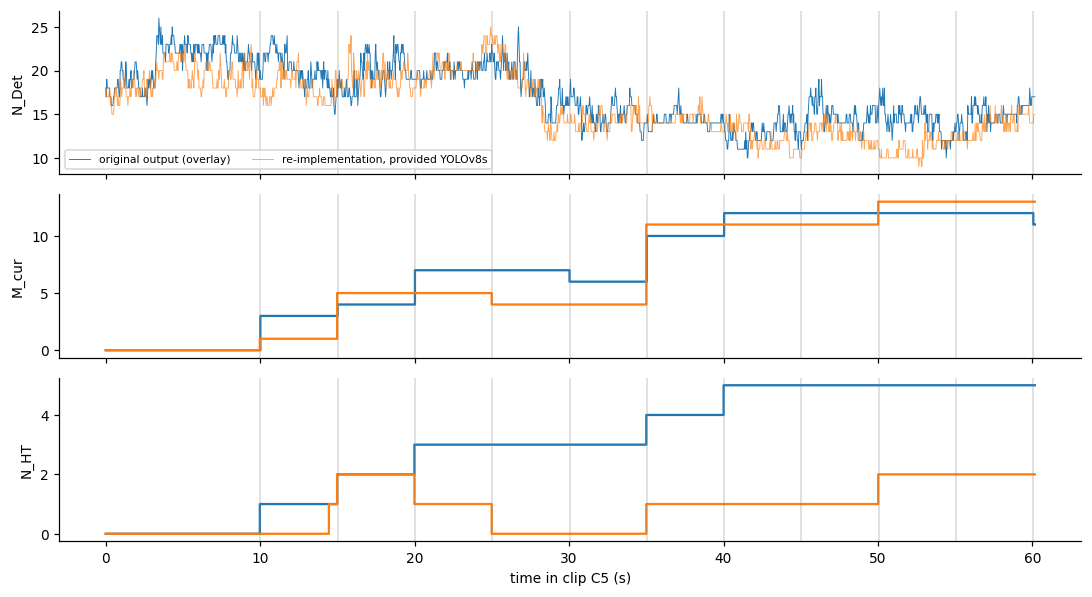


**Check results**
1. The $M_{cur}$ update times of the original output agree **exactly** with the update rule of Algorithm 2 (frame number a multiple of $t/2=150$, first update at frame 300)
   (30 fps: 10, 15, 20 … s / 24 fps: 12.5, 18.75 … s). $N_{Tot}$ increases monotonically (running maximum) → the re-implementation of Algorithm 2 matches the original implementation.
2. $N_{CR}$ of the original output jumps from 0 to 2 at exactly 10.0 s (= 300 frames) in C1 and C5: **a start-up error that took piglets already visible (resting) in frame 0 as 'newly appeared piglets'
   and counted them as crushed 10 s later because they had moved little**.
3. $N_{Det}$ of the original output agrees with the detection count of the provided YOLOv8s in only 20–30% of the frames (correlation of 1-s means 0.7–0.9). The original analysis was therefore run with **different detector weights**
   (YOLOv5s according to the manuscript). Those weights are lost, so a frame-exact reproduction of the manuscript values is impossible; the reproduction below (§6) uses the provided detector.
4. The final $N_{CR}$ of the original result videos is **3, 1, 0, 1, 3** for C1–C5, which differs from the predicted values **1, 1, 0, 3, 3** in Table 2 of the manuscript.


In [24]:
OCR = {c: pd.read_csv(ROOT / f"cache/ocr/{c}.csv") for c in ["C1", "C2", "C3", "C4", "C5"]}

def changepoints(s, fps):
    s = pd.Series(s).rolling(5, center=True, min_periods=1).median().to_numpy()
    idx = np.where(np.diff(s) != 0)[0] + 1
    return [(round(i / fps, 1), int(s[i])) for i in idx]

rows = []
for c, o in OCR.items():
    f = FPS[c]
    n = count_series(c)[:len(o)]
    h = hpa_original(n)
    ocr_m = [t for t, _ in changepoints(o.M_cur, f)]
    my_m_updates = [round(k / f, 1) for k in range(len(o)) if k + 1 > 150 and (k + 1) % 150 == 0]
    ntot = o.N_Tot.rolling(5, center=True, min_periods=1).median()
    rows.append(dict(clip=c, fps=round(f, 2),
                     ocr_Mcur_change_times_s=ocr_m[:6], algorithm2_update_times_s=my_m_updates[:6],
                     ocr_NTot_monotone=float((ntot.diff().fillna(0) >= 0).mean()),
                     ocr_NCR_change=changepoints(o.N_CR, f),
                     NDet_exact_agree=float(np.mean(n == o.N_Det.to_numpy())),
                     NDet_MAE=float(np.mean(np.abs(n - o.N_Det.to_numpy()))),
                     NDet_corr_1s=float(np.corrcoef(pd.Series(n).rolling(int(f), center=True, min_periods=1).mean(),
                                                    o.N_Det.rolling(int(f), center=True, min_periods=1).mean())[0, 1])))
VER = pd.DataFrame(rows)
display(VER.round(3)); save_table(VER.round(3), "S5_original_overlay_verification")

fig, axes = plt.subplots(3, 1, figsize=(10, 5.5), sharex=True)
c = "C5"; o = OCR[c]; f = FPS[c]; n = count_series(c)[:len(o)]; h = hpa_original(n); tt = np.arange(len(o)) / f
axes[0].plot(tt, o.N_Det, lw=.6, label="original output (overlay)"); axes[0].plot(tt, n, lw=.6, alpha=.7, label="re-implementation, provided YOLOv8s")
axes[0].set_ylabel("N_Det"); axes[0].legend(fontsize=7, ncol=2)
axes[1].step(tt, o.M_cur, where="post", label="original"); axes[1].step(tt, h.M_cur, where="post", label="re-implementation"); axes[1].set_ylabel("M_cur")
axes[2].step(tt, o.N_HT, where="post"); axes[2].step(tt, h.N_HT, where="post"); axes[2].set_ylabel("N_HT"); axes[2].set_xlabel(f"time in clip {c} (s)")
for ax in axes:
    for x in np.arange(300, len(o), 150) / f:
        ax.axvline(x, color="grey", lw=.3)
fig.tight_layout(); save_fig(fig, "S_F4_overlay_vs_reimplementation"); plt.show()
display(Markdown(tr("""
**검증 결과**
1. $M_{cur}$ 갱신 시점(원 출력)이 Algorithm 2 의 갱신 규칙(프레임 수가 $t/2=150$ 의 배수, 첫 갱신은 300프레임)과 **정확히 일치**한다
   (30 fps: 10, 15, 20 … s / 24 fps: 12.5, 18.75 … s). $N_{Tot}$ 은 단조 증가(누적 최댓값)다 → Algorithm 2 재구현이 원 구현과 같다.
2. 원 출력의 $N_{CR}$ 은 C1·C5 에서 정확히 10.0 s(=300프레임)에 0→2 로 뛴다: **0번 프레임에 이미 보이던(쉬고 있던) 새끼를 '새로 나타난 새끼'로 보고
   10 s 뒤 움직임이 적다고 압사로 센 시작 오류**다.
3. 원 출력의 $N_{Det}$ 은 제공된 YOLOv8s 검출 수와 프레임 단위로 20–30%만 일치한다(1 s 평균 상관 0.7–0.9). 즉 원 분석은 **다른 검출기 가중치**
   (원고 서술대로라면 YOLOv5s)로 수행됐다. 그 가중치가 없으므로 원고 수치의 프레임 단위 완전 재현은 불가능하며, 아래 재현(§6)은 제공된 검출기로 한 것이다.
4. 원 결과 영상의 최종 $N_{CR}$ 은 C1–C5 = **3, 1, 0, 1, 3** 으로, 원고 Table 2 의 예측값 **1, 1, 0, 3, 3** 과 다르다.
""", """
**Check results**
1. The $M_{cur}$ update times of the original output agree **exactly** with the update rule of Algorithm 2 (frame number a multiple of $t/2=150$, first update at frame 300)
   (30 fps: 10, 15, 20 … s / 24 fps: 12.5, 18.75 … s). $N_{Tot}$ increases monotonically (running maximum) → the re-implementation of Algorithm 2 matches the original implementation.
2. $N_{CR}$ of the original output jumps from 0 to 2 at exactly 10.0 s (= 300 frames) in C1 and C5: **a start-up error that took piglets already visible (resting) in frame 0 as 'newly appeared piglets'
   and counted them as crushed 10 s later because they had moved little**.
3. $N_{Det}$ of the original output agrees with the detection count of the provided YOLOv8s in only 20–30% of the frames (correlation of 1-s means 0.7–0.9). The original analysis was therefore run with **different detector weights**
   (YOLOv5s according to the manuscript). Those weights are lost, so a frame-exact reproduction of the manuscript values is impossible; the reproduction below (§6) uses the provided detector.
4. The final $N_{CR}$ of the original result videos is **3, 1, 0, 1, 3** for C1–C5, which differs from the predicted values **1, 1, 0, 3, 3** in Table 2 of the manuscript.
""")))

### 5.5 Revised algorithms (addressing R1-5, R1-6, R1-7, R1-8, R1-9)

All quantities are defined **per pen $p$** and all thresholds **in seconds** (the same meaning for 24 and 30 fps videos). $\varphi$ = video fps.

| Symbol | Definition | Manuscript counterpart |
|---|---|---|
| $n_p(k)$ | number of detections inside ROI$_p$ (box centre) in frame $k$ (all classes, conf ≥ $c$) | $N_{Det}$ (whole frame) |
| $\tilde n_p(k)$ | causal 1-s median of $n_p$ (removes single-frame false and missed detections) | – |
| $N^{Tot}_p(k)$ | $\max_{k-W<j\le k}\tilde n_p(j)$, $W$ = 10 min (or the litter size from farm records) | $N_{Tot}$ (running maximum from the start of the video) |
| $M_p(k)$ | $\max(0, N^{Tot}_p - \tilde n_p)$ — **number of detections currently not visible** | element of `d_list` |
| $\bar M_p(k)$ | mode of $M_p$ over the last $t$ seconds — stabilised missing level | $M_{cur}$ |
| $L_p$ | last confirmed missing level (baseline) | $M_{prev}$ |
| $H_p(k)$ | **current estimate of hidden (possibly trapped) piglets** | (none) |
| $E_p(k)$ | **cumulative number of hidden-trapping events (alerts)** | $N_{HT}$ |
| $a_p(k)$ | sow-activity index: share of pen pixels whose brightness changed by ≥ 20 within 1 s (64×36 thumbnails) | (none) |
| $V_p(k)$ | 1-s median of the number of image-based 'visible trapping' boxes (crushing class) | $N_{VT}$ |

**Hidden-trapping rule (HPA-v2)** — keeps the logic of the original HPA (a sustained rise of the missing level = hidden, a sustained fall = reappearance) but evaluates every frame and accounts for the size of the change:
- $\bar M_p \ge L_p + s_{min}$ for $d$ consecutive seconds → **alert**, $\Delta H=\operatorname{mode}(\bar M_p)-L_p$, $H_p \mathrel{+}= \Delta H$, $E_p \mathrel{+}=1$, $L_p\leftarrow$ new level
- $\bar M_p \le L_p - 1$ for $d$ consecutive seconds → reappearance, $H_p\leftarrow\max(0, H_p-(L_p-\text{new level}))$, $L_p\leftarrow$ new level
- (optional) **sow-activity gate**: alert only if $\max a_p \ge \theta_a$ within $[\text{onset}-20\,\text{s},\ \text{alert}]$ (trapping happens when the sow lies down or rolls over)

**TPA fusion (R1-6)**: $N^{trap}_p(k) = V_p(k) + H_p(k)$; trapping alert = HPA alert $\lor$ visible-trapping alert ($V_p\ge1$ for 2 s).
A partly visible trapped piglet is a detection box, so it is included in $\tilde n_p$ and not in $M_p$ → it contributes only to $V_p$; a completely hidden piglet contributes only to $H_p$ → **no double counting**.

**CDA-v2 → "suspected-crushing (immobility) alert" (R1-9)**: only new tracks born within an HPA event window $[\text{onset}, \text{end}+30\,\text{s}]$ (end = first reappearance, at most 120 s after the alert) — i.e. piglets reappearing from under the sow — are candidates;
an alert is raised if the maximum displacement of the centre during the first $f$ seconds is at most $m\times$ (median box diagonal) (normalised by **body size**, not pixels, R1-7).
Optionally, a 'crushed'-class detection on the track can be required. HPA decides the candidates of CDA — a **causal integration** —
while the Kalman prediction and association steps themselves are not affected by HPA (the manuscript figure showed parallel outputs — R1-6).
This alert does not confirm death; it is a **post hoc detection of immobility**.

In [25]:
def hpa_v2(n_det, fps, d_s=5.0, t_s=5.0, step_min=1, smooth_s=1.0, tot_window_s=600.0,
           warmup_s=30.0, known_total=None, max_event_s=120.0, max_total=None):
    """Revised hidden-trapping detector for ONE pen (all thresholds in seconds, frame-rate free).
    It keeps the logic of the original HPA (a sustained rise of the stabilised missing count is a
    hidden-trapping event, a sustained fall means hidden piglets re-appeared) but
      * evaluates every frame instead of every t/2 frames,
      * counts piglets by the MAGNITUDE of the step (original: +/-1 per update),
      * uses one variable per concept (reviewer comment 6):
          n_s   stabilised visible count          = causal median of N_Det over smooth_s
          N_Tot expected litter size              = causal max of n_s over tot_window_s (or known_total;
                                                    max_total caps the rolling max, e.g. at the counted litter size)
          M     current number of missing detections = max(0, N_Tot - n_s)
          M_st  stabilised missing level          = causal mode of M over t_s
          L     last confirmed missing level (reference)
          H     current estimated number of hidden(-trapped) piglets
          E     cumulative number of hidden-trapping events (= alerts)
    Rule: if M_st >= L + step_min for d_s seconds -> alert, dH = mode(M_st over those d_s) - L,
          H += dH, E += 1, L <- new level;  if M_st <= L - 1 for d_s seconds -> re-appearance,
          H <- max(0, H - (L - new level)), L <- new level (no alert)."""
    n = len(n_det)
    n_s = rolling_median_int(n_det, max(1, int(round(smooth_s * fps))))
    if known_total is None:
        N_Tot = pd.Series(n_s).rolling(max(1, int(tot_window_s * fps)), min_periods=1).max().to_numpy().astype(int)
        if max_total is not None:
            N_Tot = np.minimum(N_Tot, int(max_total))
    else:
        N_Tot = np.full(n, int(known_total))
    M = np.clip(N_Tot - n_s, 0, None)
    M_st = rolling_mode_int(M, max(1, int(round(t_s * fps))))
    d_f = max(1, int(round(d_s * fps))); warm = int(warmup_s * fps)
    H = np.zeros(n, int); E = np.zeros(n, int); Lr = np.zeros(n, int)
    L = int(M_st[min(warm, n - 1)]) if n else 0
    up = down = 0; h = 0; cnt = 0
    alerts, reapp = [], []
    for k in range(n):
        if k >= warm:
            m = int(M_st[k])
            up = up + 1 if m >= L + step_min else 0
            down = down + 1 if m <= L - 1 else 0
            if up >= d_f:
                seg = M_st[k - d_f + 1:k + 1]
                new = int(np.bincount(seg).argmax())
                dh = max(step_min, new - L)
                h += dh; cnt += 1
                alerts.append(dict(onset_frame=k - d_f + 1, alert_frame=k, level_before=L, level_after=new,
                                   dH=dh, H_after=h, N_Tot=int(N_Tot[k])))
                L = new; up = down = 0
            elif down >= d_f:
                seg = M_st[k - d_f + 1:k + 1]
                new = int(np.bincount(seg).argmax())          # most frequent missing level over the last d seconds
                dr = L - new
                if h > 0:
                    reapp.append(dict(frame=k, dR=min(dr, h), H_after=max(0, h - dr)))
                h = max(0, h - dr); L = new; up = down = 0
        else:
            L = int(M_st[k])
        H[k] = h; E[k] = cnt; Lr[k] = L
    ts = pd.DataFrame(dict(n_det=np.asarray(n_det, int), n_s=n_s, N_Tot=N_Tot, M=M, M_st=M_st, L=Lr, H=H, E=E))
    evs = pd.DataFrame(alerts, columns=["onset_frame", "alert_frame", "level_before", "level_after", "dH",
                                        "H_after", "N_Tot"])
    # end of an event = first re-appearance step after the alert, at most max_event_s after the alert
    ends = []
    rf = np.array([r["frame"] for r in reapp]) if reapp else np.zeros(0, int)
    cap = int(round(max_event_s * fps))
    for r in evs.itertuples():
        nxt = rf[rf > r.alert_frame]
        ends.append(int(min(nxt[0] if len(nxt) else n - 1, r.alert_frame + cap, n - 1)))
    evs["end_frame"] = ends
    for c in ("onset_frame", "alert_frame", "end_frame"):
        evs[c.replace("_frame", "_s")] = evs[c] / fps
    return ts, evs


def visible_trap_v2(n_vt, fps, smooth_s=1.0, d_s=2.0):
    """image-based visible-trapping channel: stabilised count of 'crushing'-class boxes and
    sustained-presence alerts (>= d_s seconds)"""
    vt = rolling_median_int(n_vt, max(1, int(round(smooth_s * fps))))
    on = vt >= 1
    events = []
    k = 0; n = len(vt); d_f = int(round(d_s * fps))
    while k < n:
        if on[k]:
            j = k
            while j < n and on[j]:
                j += 1
            if j - k >= d_f:
                events.append(dict(onset_frame=k, alert_frame=k + d_f - 1, end_frame=j - 1,
                                   n_max=int(vt[k:j].max())))
            k = j
        else:
            k += 1
    evs = pd.DataFrame(events, columns=["onset_frame", "alert_frame", "end_frame", "n_max"])
    for c in ("onset_frame", "alert_frame", "end_frame"):
        evs[c.replace("_frame", "_s")] = evs[c] / fps
    return vt, evs


def tpa_v2(ts_hpa, vt):
    """TPA fusion (per pen, per frame):  N_trap(k) = N_VT(k) + H(k).
    Partially visible trapped piglets are detected boxes (counted in N_Det, hence never 'missing'),
    so they can contribute to N_VT only; fully hidden piglets contribute to H only -> no double count."""
    return np.asarray(vt, int) + ts_hpa["H"].to_numpy()

In [26]:
def cda_v2(tracks, fps, hpa_events=None, f_s=10.0, m_rel=0.5, gate_after_s=30.0, warmup_s=30.0,
           crushed_boxes=None, require_crushed=False):
    """Revised suspected-crushing (immobility) alert.
    Candidate = track newly created after warm-up; if hpa_events is given, only tracks created during
    a hidden-trapping event or within gate_after_s after it ends (i.e. piglets re-appearing from
    under the sow) are considered (HPA-gated CDA).  Immobile = maximum displacement of the box centre
    during the first f_s seconds <= m_rel x median box diagonal (size-normalised threshold).
    Optionally require a 'crushed'-class detection on the track (image-based confirmation)."""
    if len(tracks) == 0:
        return pd.DataFrame(columns=["tid", "birth", "decision", "move_rel", "crushed"])
    f = int(round(f_s * fps)); warm = int(warmup_s * fps)
    gates = None
    if hpa_events is not None:
        gates = [(int(r.onset_frame), int(r.end_frame + gate_after_s * fps)) for r in hpa_events.itertuples()]
    rows = []
    for tid, tr in tracks.groupby("tid", sort=False):
        b = int(tr.frame.iloc[0])
        if b < warm:
            continue
        if gates is not None and not any(g0 <= b <= g1 for g0, g1 in gates):
            continue
        sub = tr[tr.frame <= b + f]
        if int(sub.frame.iloc[-1]) < b + f - int(0.2 * f):    # must be observed until (almost) f
            continue
        x, y = sub.cx.to_numpy(), sub.cy.to_numpy()
        diag = float(np.median(np.hypot(sub.w, sub.h)))
        mv = float(np.max(np.hypot(x - x[0], y - y[0]))) / max(diag, 1.0)
        n_crushed_cls = int((sub.cls == CLS_CRUSHED).sum())
        ok = mv <= m_rel and (n_crushed_cls > 0 if require_crushed else True)
        rows.append((tid, b, b + f, mv, n_crushed_cls, ok))
    return pd.DataFrame(rows, columns=["tid", "birth", "decision", "move_rel", "n_crushed_cls", "crushed"])


def track_summary(tracks, fps, f_list_s=(1, 3, 5, 10, 20, 30), f_list_frames=(30, 90, 150, 300, 600)):
    """Per-track features used by both CDA versions, so that CDA thresholds can be varied without
    re-tracking.  For each window length f (seconds for CDA-v2, frames for the original CDA):
      full_*  : track still alive (observed) at birth + f (original: exactly; v2: >= 80% of f)
      mrel_*  : max displacement of the box centre within f, divided by the median box diagonal (v2)
      path_*  : path length (px) of the centre within f (original CDA movement)
      ncr_*   : number of frames with a 'crushed'-class box on the track within f"""
    if len(tracks) == 0:
        return pd.DataFrame()
    tr = tracks.sort_values(["tid", "frame"])
    fr = tr.frame.to_numpy(); tid = tr.tid.to_numpy(); cx = tr.cx.to_numpy(); cy = tr.cy.to_numpy()
    dg = np.hypot(tr.w.to_numpy(), tr.h.to_numpy()); cl = tr.cls.to_numpy()
    starts = np.r_[0, np.where(np.diff(tid) != 0)[0] + 1]; ends = np.r_[starts[1:], len(tid)]
    rows = []
    for a, b in zip(starts, ends):
        f0 = fr[a]; x = cx[a:b]; y = cy[a:b]; ff = fr[a:b] - f0
        rec = dict(tid=int(tid[a]), birth=int(f0), last=int(fr[b - 1]), n_obs=int(b - a), cx0=float(x[0]), cy0=float(y[0]),
                   diag=float(np.median(dg[a:b])))
        disp = np.hypot(x - x[0], y - y[0]); step = np.r_[0, np.hypot(np.diff(x), np.diff(y))]; cum = np.cumsum(step)
        for fs in f_list_s:
            n = int(round(fs * fps)); j = np.searchsorted(ff, n, side="right")
            rec[f"full_s{fs}"] = bool(ff[-1] >= 0.8 * n)
            rec[f"mrel_s{fs}"] = float(disp[:j].max() / max(rec["diag"], 1.0))
            rec[f"ncr_s{fs}"] = int((cl[a:a + j] == CLS_CRUSHED).sum())
        for fn in f_list_frames:
            j = np.searchsorted(ff, fn, side="right")
            rec[f"full_f{fn}"] = bool(ff[-1] >= fn)
            rec[f"path_f{fn}"] = float(cum[j - 1])
            rec[f"disp_f{fn}"] = float(disp[j - 1])
        rows.append(rec)
    return pd.DataFrame(rows)


def cda_orig_from_summary(ts_, f=300, m=200.0, movement="path", start_frame=0):
    """original CDA decisions from a track summary (frames / pixels)"""
    if len(ts_) == 0:
        return ts_
    d = ts_[(ts_.birth >= start_frame) & ts_[f"full_f{f}"]].copy()
    d["decision"] = d.birth + f
    d["crushed"] = d[f"{'path' if movement == 'path' else 'disp'}_f{f}"] <= m
    return d[d.crushed]


def cda_v2_from_summary(ts_, fps, f_s=10, m_rel=0.5, gates=None, warmup_s=30.0, require_crushed=False):
    """revised CDA (suspected crushing / immobility alert) from a track summary.
    gates: list of (start_frame, end_frame) windows in which candidate tracks must be born (HPA gating)"""
    if len(ts_) == 0:
        return ts_
    d = ts_[(ts_.birth >= warmup_s * fps) & ts_[f"full_s{f_s}"] & (ts_[f"mrel_s{f_s}"] <= m_rel)].copy()
    if require_crushed:
        d = d[d[f"ncr_s{f_s}"] > 0]
    if gates is not None:
        b = d.birth.to_numpy()
        ok = np.zeros(len(d), bool)
        for g0, g1 in gates:
            ok |= (b >= g0) & (b <= g1)
        d = d[ok]
    d["decision"] = d.birth + int(round(f_s * fps))
    return d


def mot_proxies(tracks, fps):
    """tracking-quality proxies that need no ground truth"""
    if len(tracks) == 0:
        return {}
    g = tracks.groupby("tid").frame.agg(["min", "max", "size"])
    dur = (g["max"] - g["min"] + 1) / fps
    minutes = (tracks.frame.max() + 1) / fps / 60
    det_per_frame = len(tracks) / (tracks.frame.max() + 1)
    long_ids = g.index[dur >= 10]
    return dict(n_tracks=len(g), births_per_min=len(g) / minutes,
                births_per_piglet_per_min=len(g) / minutes / max(det_per_frame, 1e-9),
                mean_track_s=float(dur.mean()), median_track_s=float(dur.median()),
                frac_dets_in_tracks_ge10s=float(tracks.tid.isin(long_ids).mean()))

In [27]:
def r2(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    sst = ((y - y.mean()) ** 2).sum()
    return float(1 - ((y - p) ** 2).sum() / sst) if sst > 0 else float("nan")


def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y, float) - np.asarray(p, float))))


def match_alerts(alerts, gt, pre_s=10.0, post_s=60.0, exclude=None):
    """Event-level matching with a PRE-SPECIFIED temporal window.
    An alert at time a (s) matches GT event g of the same recording and pen if
        onset_g - pre_g <= a <= onset_g + post_g
    (pre_g/post_g from gt columns 'pre_s'/'post_s' if present, else the defaults).  Alerts with
    pen == 'ALL' (whole-frame methods) may match an event in any pen of that recording.
    Alerts are processed in time order: the first alert matched to an event is a TP, further ones
    are duplicates (DUP; an alert prefers a not-yet-detected event if several are possible);
    unmatched alerts are FP unless inside an 'exclude' window (unannotated candidate events ->
    EXCLUDED); events without alert are FN.
    alerts: DataFrame[rec, pen, alert_s]; gt: DataFrame[event_id, rec, pen, onset_s]"""
    alerts = alerts.sort_values("alert_s", kind="stable").reset_index(drop=True)
    gt = gt.copy().reset_index(drop=True)
    if "pre_s" not in gt:
        gt["pre_s"] = pre_s
    if "post_s" not in gt:
        gt["post_s"] = post_s
    n = len(alerts)
    status = np.array(["FP"] * n, dtype=object); match = np.array([None] * n, dtype=object)
    first = np.full(len(gt), np.nan); n_al = np.zeros(len(gt), int)
    if n and len(gt):
        ar, ap, at = alerts.rec.to_numpy(), alerts.pen.to_numpy(), alerts.alert_s.to_numpy()
        cand = ((ar[:, None] == gt.rec.to_numpy()[None]) &
                ((ap[:, None] == gt.pen.to_numpy()[None]) | (ap[:, None] == "ALL")) &
                (at[:, None] >= (gt.onset_s - gt.pre_s).to_numpy()[None]) &
                (at[:, None] <= (gt.onset_s + gt.post_s).to_numpy()[None]))
        on = gt.onset_s.to_numpy()
        for i in np.where(cand.any(1))[0]:
            js = np.where(cand[i])[0]
            free = js[n_al[js] == 0]
            pool = free if len(free) else js
            j = pool[np.argmin(np.abs(on[pool] - at[i]))]
            match[i] = gt.event_id.iat[j]
            if n_al[j] == 0:
                status[i] = "TP"; first[j] = at[i]
            else:
                status[i] = "DUP"
            n_al[j] += 1
    if exclude is not None and n and len(exclude):
        ar, ap, at = alerts.rec.to_numpy(), alerts.pen.to_numpy(), alerts.alert_s.to_numpy()
        ex = ((ar[:, None] == exclude.rec.to_numpy()[None]) &
              ((ap[:, None] == exclude.pen.to_numpy()[None]) | (ap[:, None] == "ALL")) &
              (at[:, None] >= exclude.start_s.to_numpy()[None]) & (at[:, None] <= exclude.end_s.to_numpy()[None])).any(1)
        status[(status == "FP") & ex] = "EXCLUDED"
    alerts["match"] = match; alerts["status"] = status
    gt["first_alert_s"] = first; gt["n_alerts"] = n_al
    gt["detected"] = gt.n_alerts > 0
    gt["latency_s"] = gt.first_alert_s - gt.onset_s
    return alerts, gt


def window_confusion(alerts, gt, recs_pens, fps_of, nfr_of, win_s=60.0, exclude=None):
    """time-window confusion matrix (gives specificity / NPV): every pen-recording is cut into
    consecutive win_s windows; a window is GT-positive if it contains an annotated onset, predicted
    positive if it contains >= 1 alert; windows overlapping an exclude window are dropped."""
    tp = fp = fn = tn = 0
    for rec, pen in recs_pens:
        dur = nfr_of[rec] / fps_of[rec]
        edges = np.arange(0, dur + win_s, win_s)
        g = gt[(gt.rec == rec) & (gt.pen == pen)].onset_s.to_numpy()
        a = alerts[(alerts.rec == rec) & ((alerts.pen == pen) | (alerts.pen == "ALL"))].alert_s.to_numpy()
        for w0, w1 in zip(edges[:-1], edges[1:]):
            if exclude is not None and len(exclude[(exclude.rec == rec) & (exclude.pen == pen) &
                                                   (exclude.start_s < w1) & (exclude.end_s > w0)]):
                continue
            pos = bool(((g >= w0) & (g < w1)).any()); pred = bool(((a >= w0) & (a < w1)).any())
            tp += pos and pred; fp += (not pos) and pred; fn += pos and (not pred); tn += (not pos) and (not pred)
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, sensitivity=tp / (tp + fn) if tp + fn else np.nan,
                specificity=tn / (tn + fp) if tn + fp else np.nan, PPV=tp / (tp + fp) if tp + fp else np.nan,
                NPV=tn / (tn + fn) if tn + fn else np.nan)


def event_metrics(alerts, gt, hours):
    tp = int((alerts.status == "TP").sum()); fp = int((alerts.status == "FP").sum())
    dup = int((alerts.status == "DUP").sum()); fn = int((~gt.detected).sum())
    prec = tp / (tp + fp) if tp + fp else float("nan")
    rec = tp / (tp + fn) if tp + fn else float("nan")
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) and not np.isnan(prec + rec) else float("nan")
    return dict(TP=tp, FP=fp, FN=fn, DUP=dup, precision=prec, recall=rec, F1=f1,
                FA_per_pen_h=fp / hours if hours else float("nan"),
                dup_rate=dup / (tp + dup) if tp + dup else float("nan"),
                latency_median_s=float(gt.latency_s.median()) if gt.detected.any() else float("nan"),
                latency_max_s=float(gt.latency_s.max()) if gt.detected.any() else float("nan"))


def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))

## 6. Reproduction of the submitted manuscript's results (Tables 2–4, Figs 9–11)

Conditions as in the manuscript: **whole frame**, state reset at the start of each clip (cold start), $t=300$, $d=150$ frames, SORT (IoU 0.3, $t_\text{expire}=1$),
CDA $f=300$ frames, $m=200$ px (path length). Detector: the provided YOLOv8s.
- **default**: Ultralytics defaults (conf 0.25, all three classes counted as 'detected objects').
- **closest**: the detection setting closest to the manuscript values, found by a search (conf ∈ 0.20–0.60, combinations of counted classes) — **for reproduction only**; a setting chosen this way
  must not be reported as performance (it is tuned on the test data).
- **YOLOv5s (retrained)**: YOLOv5s, the architecture used in the manuscript, retrained on all 204 training originals (evaluation frames included — the same originals as the original training, but without the 48× offline augmentation) (§3.2, conf 0.25, NMS IoU 0.45).
  The original weights were trained on the same originals with 48× offline augmentation (§3.3), so this is also an approximate reproduction.
- **YOLOv5s ([9] recipe)**: YOLOv5s reproducing the augmentation, split and training settings of [9] (§3.4 `r9_split`, conf 0.25, NMS IoU 0.45). Only the augmentation random numbers differ,
  so this is the closest reconstruction of the lost manuscript YOLOv5s (which run of [9] produced the manuscript weights is unknown).

Outputs as defined in the manuscript: HPA prediction = $N_{HT}$ at the end of the clip, counting model = maximum $M_{cur}$ within the clip, image model = maximum of the 1-s median of the 'crushing' class
within the clip, TPA = $N_{HT}+N_{VT}$, CDA = $N_{CR}$ at the end of the clip, detection latency = time from the event onset to the first increase of $N_{HT}$.

In [28]:
PAPER_T = pd.DataFrame(dict(case=range(1, 7), clip=[f"T{i}" for i in range(1, 7)],
                            hidden_gt=[1, 1, 1, 1, 1, 8], visible_gt=[0, 0, 1, 1, 1, 0], total_gt=[1, 1, 2, 2, 2, 8],
                            hpa_paper=[1, 2, 1, 1, 2, 4], image_paper=[0, 0, 1, 1, 1, 0], counting_paper=[5, 4, 3, 3, 4, 13],
                            tpa_paper=[1, 2, 2, 2, 3, 4], latency_paper=[10, 1, 9, 9, 12, 6]))
PAPER_C = pd.DataFrame(dict(case=range(1, 6), clip=[f"C{i}" for i in range(1, 6)], crushed_gt=[1, 1, 1, 2, 2],
                            cda_paper=[1, 1, 0, 3, 3],
                            cda_original_overlay=[int(OCR[c].N_CR.rolling(5, center=True, min_periods=1).median().iloc[-1])
                                                  for c in ["C1", "C2", "C3", "C4", "C5"]]))
ONSET_IN_CLIP = dict(zip(EV["clip"], EV.onset_in_clip_s))

# --- R² of manuscript Table 4 recomputed from the manuscript's predicted values (check of the table) ---
chk = []
for model, col in [("Image-based", "image_paper"), ("Counting", "counting_paper"), ("HPA", "hpa_paper"), ("TPA", "tpa_paper")]:
    chk.append(dict(model=model, R2_visible=r2(PAPER_T.visible_gt, PAPER_T[col]), R2_hidden=r2(PAPER_T.hidden_gt, PAPER_T[col]),
                    R2_all=r2(PAPER_T.total_gt, PAPER_T[col]), MAE_all=mae(PAPER_T.total_gt, PAPER_T[col]),
                    MAE_hidden=mae(PAPER_T.hidden_gt, PAPER_T[col])))
CHK = pd.DataFrame(chk)
display(Markdown(tr("**원고 Table 4 검증** (원고의 예측값으로 R² 재계산; 원고 값: image 1.00/−0.69/−0.95, counting −150.34/−0.64/−0.58, HPA −13.60/0.56/0.46, TPA –/–/0.49)",
                    "**Check of manuscript Table 4** (R² recomputed from the manuscript's predicted values; manuscript values: image 1.00/−0.69/−0.95, counting −150.34/−0.64/−0.58, HPA −13.60/0.56/0.46, TPA –/–/0.49)")))
display(CHK.round(2))

**Check of manuscript Table 4** (R² recomputed from the manuscript's predicted values; manuscript values: image 1.00/−0.69/−0.95, counting −150.34/−0.64/−0.58, HPA −13.60/0.56/0.46, TPA –/–/0.49)

,model,R2_visible,R2_hidden,R2_all,MAE_all,MAE_hidden
0,Image-based,1.00,-0.62,-0.95,2.17,1.67
1,Counting,-150.33,-0.64,-0.58,2.67,3.17
2,HPA,-13.67,0.56,0.46,1.17,1.00
3,TPA,-17.00,0.44,0.49,1.00,1.50


In [29]:
def reproduce_trap_clip(clip, conf=0.25, classes=(0, 1, 2), t=300, d=150, tag="", pen=None):
    f = FPS[clip]; cam = VIDEOS[clip]["camera"]
    n = count_series(clip, conf=conf, classes=classes, pen=pen, camera=cam, tag=tag)
    h = hpa_original(n, t=t, d=d)
    vt = rolling_median_int(count_series(clip, conf=conf, classes=(1,), pen=pen, camera=cam, tag=tag), int(round(f)))
    on = int(ONSET_IN_CLIP[clip] * f)
    inc = np.where(np.diff(h.N_HT.to_numpy()) > 0)[0] + 1
    after = inc[inc >= on]
    return dict(clip=clip, hpa=int(h.N_HT.iloc[-1]), counting=int(h.M_cur.max()), image=int(vt.max()),
                tpa=int(h.N_HT.iloc[-1] + vt.max()), latency=(after[0] - on) / f if len(after) else np.nan,
                first_increment_s=round(inc[0] / f, 2) if len(inc) else np.nan, first_update_s=round(t / f, 2))


def reproduce_crush_clip(clip, conf=0.25, classes=(0, 1, 2), f=300, m=200.0, iou=0.3, max_age=1, tag="", pen=None):
    cam = VIDEOS[clip]["camera"]
    tr = run_tracker(frames_dets(clip, conf=conf, classes=classes, pen=pen, camera=cam, tag=tag), iou_thr=iou, max_age=max_age)
    s = track_summary(tr, FPS[clip], f_list_frames=(f,))
    return dict(clip=clip, cda=len(cda_orig_from_summary(s, f=f, m=m)),
                cda_no_startup=len(cda_orig_from_summary(s, f=f, m=m, start_frame=1)))


def reproduce_all(conf=0.25, classes=(0, 1, 2), tag="", pen_mode=False):
    T = pd.DataFrame([reproduce_trap_clip(c, conf, classes, tag=tag) for c in PAPER_T["clip"]])
    C = pd.DataFrame([reproduce_crush_clip(c, conf, classes, tag=tag) for c in PAPER_C["clip"]])
    return T, C

REP_T, REP_C = reproduce_all()
REP5_T, REP5_C = reproduce_all(tag="_v5ctrl")
REP9_T, REP9_C = reproduce_all(tag="_r9split")

def closest_search():
    rows = []
    for conf in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]:
        for classes in [(0,), (0, 1), (0, 1, 2)]:
            T, C = reproduce_all(conf, classes)
            dist = int(np.abs(T.hpa - PAPER_T.hpa_paper).sum() + np.abs(C.cda_no_startup - PAPER_C.cda_paper).sum())
            rows.append(dict(conf=conf, classes=str(classes), dist_to_manuscript=dist, T=T, C=C))
    return rows

SEARCH = cached("repro_closest_search", closest_search)
best = min(SEARCH, key=lambda r: (r["dist_to_manuscript"], abs(r["conf"] - 0.25)))
display(pd.DataFrame([{k: v for k, v in r.items() if k not in ("T", "C")} for r in SEARCH]).pivot(index="conf", columns="classes",
                     values="dist_to_manuscript").style.set_caption("Σ|reproduced − manuscript| (HPA 6 cases + CDA 5 cases)"))
CL_T, CL_C = best["T"], best["C"]
print("closest configuration:", best["conf"], best["classes"], "distance", best["dist_to_manuscript"])

classes,"(0, 1)","(0, 1, 2)","(0,)"
conf,,,
0.200000,18,17,21
0.250000,15,11,17
0.300000,12,11,16
0.350000,9,9,10
0.400000,14,13,13
0.450000,14,12,15
0.500000,12,10,12
0.550000,16,14,17
0.600000,12,12,16


closest configuration: 0.35 (0, 1) distance 9


In [30]:
T6 = PAPER_T[["case", "clip", "hidden_gt", "visible_gt", "total_gt", "hpa_paper"]].copy()
T6["hpa_repro_default"] = REP_T.hpa; T6["hpa_repro_closest"] = CL_T.hpa
T6["counting_paper"] = PAPER_T.counting_paper; T6["counting_repro_default"] = REP_T.counting; T6["counting_repro_closest"] = CL_T.counting
T6["image_paper"] = PAPER_T.image_paper; T6["image_repro_default"] = REP_T.image; T6["image_repro_closest"] = CL_T.image
T6["tpa_paper"] = PAPER_T.tpa_paper; T6["tpa_repro_default"] = REP_T.tpa; T6["tpa_repro_closest"] = CL_T.tpa
T6["latency_paper_s"] = PAPER_T.latency_paper; T6["latency_repro_default_s"] = REP_T.latency.round(1)
T6["latency_repro_closest_s"] = CL_T.latency.round(1)
for c in ["hpa", "counting", "image", "tpa"]:
    T6[f"{c}_repro_yolov5s"] = REP5_T[c]
T6["latency_repro_yolov5s_s"] = REP5_T.latency.round(1)
for c in ["hpa", "counting", "image", "tpa"]:
    T6[f"{c}_repro_yolov5s_r9"] = REP9_T[c]
T6["latency_repro_yolov5s_r9_s"] = REP9_T.latency.round(1)
display(T6); save_table(T6, "T4_reproduction_trapping_cases")

C6 = PAPER_C.copy()
C6["cda_repro_default"] = REP_C.cda; C6["cda_repro_default_no_startup"] = REP_C.cda_no_startup
C6["cda_repro_closest_no_startup"] = CL_C.cda_no_startup
C6["cda_repro_yolov5s"] = REP5_C.cda; C6["cda_repro_yolov5s_no_startup"] = REP5_C.cda_no_startup
C6["cda_repro_yolov5s_r9"] = REP9_C.cda; C6["cda_repro_yolov5s_r9_no_startup"] = REP9_C.cda_no_startup
display(C6); save_table(C6, "T5_reproduction_crushing_cases")

def r2_table(T, tgt_cols=("visible_gt", "hidden_gt", "total_gt")):
    rows = []
    for model in ["image", "counting", "hpa", "tpa"]:
        rows.append(dict(model=model, **{f"R2_{c.split('_')[0]}": r2(PAPER_T[c], T[model]) for c in tgt_cols},
                         MAE_hidden=mae(PAPER_T.hidden_gt, T[model]), MAE_total=mae(PAPER_T.total_gt, T[model])))
    return pd.DataFrame(rows)

R2X = pd.concat([CHK.assign(source="manuscript predictions").rename(columns={"R2_all": "R2_total"}).assign(model=lambda d: d.model.str.lower().str.replace("-based", "")),
                 r2_table(REP_T).assign(source="reproduced (default)"), r2_table(CL_T).assign(source="reproduced (closest)"),
                 r2_table(REP5_T).assign(source="reproduced (YOLOv5s retrained)"),
                 r2_table(REP9_T).assign(source="reproduced (YOLOv5s, [9] recipe and split)")])
R2X = R2X[["source", "model", "R2_visible", "R2_hidden", "R2_total", "MAE_hidden"]]
display(R2X.round(2)); save_table(R2X.round(3), "T6_reproduction_R2")
cm = pd.DataFrame(dict(source=["manuscript", "reproduced default", "reproduced default (no start-up artefact)",
                               "reproduced YOLOv5s", "reproduced YOLOv5s (no start-up artefact)",
                               "reproduced YOLOv5s [9] recipe", "reproduced YOLOv5s [9] recipe (no start-up artefact)", "original overlay"],
                       CDA_MAE=[mae(C6.crushed_gt, C6.cda_paper), mae(C6.crushed_gt, C6.cda_repro_default),
                                mae(C6.crushed_gt, C6.cda_repro_default_no_startup), mae(C6.crushed_gt, C6.cda_repro_yolov5s),
                                mae(C6.crushed_gt, C6.cda_repro_yolov5s_no_startup), mae(C6.crushed_gt, C6.cda_repro_yolov5s_r9),
                                mae(C6.crushed_gt, C6.cda_repro_yolov5s_r9_no_startup), mae(C6.crushed_gt, C6.cda_original_overlay)]))
display(cm.round(2))

,case,clip,hidden_gt,visible_gt,total_gt,hpa_paper,hpa_repro_default,hpa_repro_closest,counting_paper,counting_repro_default,counting_repro_closest,image_paper,image_repro_default,image_repro_closest,tpa_paper,tpa_repro_default,tpa_repro_closest,latency_paper_s,latency_repro_default_s,latency_repro_closest_s,hpa_repro_yolov5s,counting_repro_yolov5s,image_repro_yolov5s,tpa_repro_yolov5s,latency_repro_yolov5s_s,hpa_repro_yolov5s_r9,counting_repro_yolov5s_r9,image_repro_yolov5s_r9,tpa_repro_yolov5s_r9,latency_repro_yolov5s_r9_s
0,1,T1,1,0,1,1,1,1,5,4,3,0,1,1,1,2,2,10,6.0,6.0,2,5,1,3,9.1,2,5,1,3,9.1
1,2,T2,1,0,1,2,4,2,4,8,7,0,1,1,2,5,3,1,19.9,30.7,1,6,1,2,12.0,2,7,1,3,12.0
2,3,T3,1,1,2,1,3,1,3,6,4,1,2,2,2,5,3,9,7.5,10.5,2,9,4,6,1.2,0,5,3,3,7.5
3,4,T4,1,1,2,1,2,2,3,11,10,1,0,0,2,2,2,9,5.0,0.0,0,12,2,2,0.0,2,12,0,2,5.0
4,5,T5,1,1,2,2,3,4,4,13,9,1,2,2,3,5,6,12,10.0,10.0,1,8,4,5,15.0,6,11,1,7,5.3
5,6,T6,8,0,8,4,5,3,13,10,9,0,0,0,4,5,3,6,5.0,5.0,0,8,3,3,20.0,0,5,1,1,13.5


,case,clip,crushed_gt,cda_paper,cda_original_overlay,cda_repro_default,cda_repro_default_no_startup,cda_repro_closest_no_startup,cda_repro_yolov5s,cda_repro_yolov5s_no_startup,cda_repro_yolov5s_r9,cda_repro_yolov5s_r9_no_startup
0,1,C1,1,1,3,3,1,0,3,1,3,1
1,2,C2,1,1,1,1,1,1,2,2,1,1
2,3,C3,1,0,0,3,2,1,0,0,0,0
3,4,C4,2,3,1,2,1,1,1,0,0,0
4,5,C5,2,3,3,5,3,2,1,0,1,1


,source,model,R2_visible,R2_hidden,R2_total,MAE_hidden
0,manuscript predictions,image,1.00,-0.62,-0.95,1.67
1,manuscript predictions,counting,-150.33,-0.64,-0.58,3.17
2,manuscript predictions,hpa,-13.67,0.56,0.46,1.00
3,manuscript predictions,tpa,-17.00,0.44,0.49,1.50
0,reproduced (default),image,-2.33,-0.64,-0.92,1.83
1,reproduced (default),counting,-298.33,-7.11,-6.92,6.50
2,reproduced (default),hpa,-33.00,0.34,0.43,1.83
3,reproduced (default),tpa,-57.00,-0.44,-0.25,2.83
0,reproduced (closest),image,-2.33,-0.64,-0.92,1.83
1,reproduced (closest),counting,-194.33,-3.78,-3.47,4.83


,source,CDA_MAE
0,manuscript,0.6
1,reproduced default,1.4
2,reproduced default (no start-up artefact),0.6
3,reproduced YOLOv5s,1.2
4,reproduced YOLOv5s (no start-up artefact),1.2
5,reproduced YOLOv5s [9] recipe,1.2
6,reproduced YOLOv5s [9] recipe (no start-up art...,0.8
7,original overlay,1.0


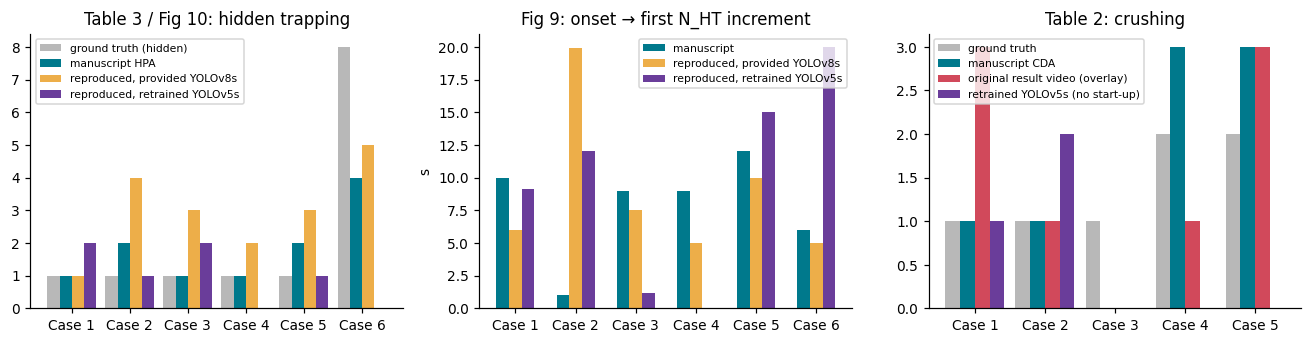

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
x = np.arange(6); w = .21
axes[0].bar(x - 1.5 * w, T6.hidden_gt, w, label="ground truth (hidden)", color="#b8b8b8")
axes[0].bar(x - .5 * w, T6.hpa_paper, w, label="manuscript HPA", color="#00798c")
axes[0].bar(x + .5 * w, T6.hpa_repro_default, w, label="reproduced, provided YOLOv8s", color="#edae49")
axes[0].bar(x + 1.5 * w, T6.hpa_repro_yolov5s, w, label="reproduced, retrained YOLOv5s", color="#6a3d9a")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"Case {i}" for i in range(1, 7)]); axes[0].legend(fontsize=7); axes[0].set_title("Table 3 / Fig 10: hidden trapping")
axes[1].bar(x - w, T6.latency_paper_s, w, label="manuscript", color="#00798c")
axes[1].bar(x, T6.latency_repro_default_s, w, label="reproduced, provided YOLOv8s", color="#edae49")
axes[1].bar(x + w, T6.latency_repro_yolov5s_s, w, label="reproduced, retrained YOLOv5s", color="#6a3d9a")
axes[1].set_xticks(x); axes[1].set_xticklabels([f"Case {i}" for i in range(1, 7)]); axes[1].set_ylabel("s"); axes[1].legend(fontsize=7)
axes[1].set_title("Fig 9: onset → first N_HT increment")
x5 = np.arange(5)
axes[2].bar(x5 - 1.5 * w, C6.crushed_gt, w, color="#b8b8b8", label="ground truth")
axes[2].bar(x5 - .5 * w, C6.cda_paper, w, color="#00798c", label="manuscript CDA")
axes[2].bar(x5 + .5 * w, C6.cda_original_overlay, w, color="#d1495b", label="original result video (overlay)")
axes[2].bar(x5 + 1.5 * w, C6.cda_repro_yolov5s_no_startup, w, color="#6a3d9a", label="retrained YOLOv5s (no start-up)")
axes[2].set_xticks(x5); axes[2].set_xticklabels([f"Case {i}" for i in range(1, 6)]); axes[2].legend(fontsize=7); axes[2].set_title("Table 2: crushing")
fig.tight_layout(); save_fig(fig, "S_F5_reproduction"); plt.show()

### 6.1 Start-up error and detection latency when the state is reset for each clip (Fig 9) (R1-7)
When the state starts from 0 in every clip, at the first $M_{cur}$ update ($t$ frames = 10 s at 30 fps, 12.5 s at 24 fps) $M_{cur}$ jumps from 0
to the usual missing level (a few piglets are always hidden by overlapping), and $N_{Tot}$ is the maximum so far, so $D>d$ may already hold →
**$N_{HT}$ can increase at the first update regardless of any event**. In the table below (default reproduction), $N_{HT}$ increases at the first update in several of the 11 clips.
In manuscript Case 2 the event is at 13 s, right after the first update (12.5 s), so the manuscript's '1-s latency' probably coincides with this start-up error (it cannot be confirmed without the original detector).
The manuscript's latency values are therefore **values for an algorithm without information from before the event (cold start)**; the revised analysis (§7–§8) measures the latency again on the continuous recordings
with the state kept (warm start). This latency is the **algorithmic latency** from event onset to alert, separate from the computational latency (§14) (R1-11).

In [32]:
su = []
for c in list(PAPER_T["clip"]) + list(PAPER_C["clip"]):
    f = FPS[c]; h = hpa_original(count_series(c))
    inc = np.where(np.diff(h.N_HT.to_numpy()) > 0)[0] + 1
    su.append(dict(clip=c, fps=round(f, 2), first_update_s=round(300 / f, 2), first_NHT_increment_s=round(inc[0] / f, 2) if len(inc) else np.nan,
                   increment_at_first_update=bool(len(inc) and abs(inc[0] - 300) <= 1), onset_in_clip_s=ONSET_IN_CLIP.get(c)))
SU = pd.DataFrame(su); display(SU); save_table(SU, "S6_startup_artefact")
print(f"{SU.increment_at_first_update.sum()} / {len(SU)} clips: N_HT increases exactly at the first M_cur update (start-up artefact)")

,clip,fps,first_update_s,first_NHT_increment_s,increment_at_first_update,onset_in_clip_s
0,T1,29.97,10.01,11.95,False,24.0
1,T2,24.00,12.50,32.88,False,13.0
2,T3,24.00,12.50,12.46,True,30.0
3,T4,29.97,10.01,9.98,True,30.0
4,T5,29.97,10.01,9.98,True,30.0
5,T6,29.97,10.01,19.99,False,30.0
6,C1,29.97,10.01,9.98,True,30.0
7,C2,24.00,12.50,12.46,True,30.0
8,C3,29.97,10.01,42.18,False,30.0
9,C4,29.97,10.01,28.19,False,30.0


5 / 11 clips: N_HT increases exactly at the first M_cur update (start-up artefact)


## 7. Runs on the continuous recordings (per pen, state kept) and baseline comparison on the same clips and targets (R1-10, R2 L296–300)

Every method of the revised analysis processes **the whole continuous recording per pen** (information from before the event kept = warm start). Clip-level comparisons read these outputs within each event's clip window.
The detector is the **leakage-free detector** chosen by the pre-specified rule of §3.2 (`MAIN_TAG`); results with the other detectors are reported in the table of §8.3.
Three trackers are compared: `sort_orig` (manuscript setting, $t_\text{expire}$ = 1 frame), `sort_1s` (tracks kept for 1 s) and `bytetrack`.

In [33]:
TRACKERS = {
    "sort_orig": dict(tracker="sort", iou_thr=0.3, max_age_frames=1),
    "sort_1s": dict(tracker="sort", iou_thr=0.3, max_age_s=1.0),
    "bytetrack": dict(tracker="bytetrack"),
}
PEN_JOBS = [(r, cam, pen) for cam in "AB" for r in RECS[cam] for pen in PEN_ROI[cam]]
LIT_OF = {(c, p): lit for lit, (c, p) in PEN_OF.items()}

def _pen_track_job(args):
    rec, cam, pen, conf, tag, tname, iou, max_age_s = args
    cfg = TRACKERS[tname]; f = FPS[rec]
    fr = frames_dets(rec, conf=conf, pen=pen, camera=cam, tag=tag)
    if cfg["tracker"] == "sort":
        ma = cfg.get("max_age_frames") if max_age_s is None and "max_age_frames" in cfg else \
            max(1, int(round((max_age_s if max_age_s is not None else cfg["max_age_s"]) * f)))
        tr = run_tracker(fr, iou_thr=iou if iou is not None else cfg["iou_thr"], max_age=ma, tracker="sort", fps=f)
    else:
        tr = run_tracker(fr, tracker="bytetrack", fps=f)
    return (rec, pen, tname), dict(summary=track_summary(tr, f), mot=mot_proxies(tr, f))

def track_all(conf=0.25, tag="", trackers=("sort_orig", "sort_1s", "bytetrack"), iou=None, max_age_s=None, jobs=None):
    args = [(r, c, p, conf, tag, t, iou, max_age_s) for (r, c, p) in (jobs or PEN_JOBS) for t in trackers]
    with mp.get_context("fork").Pool(N_WORKERS) as pool:
        res = pool.map(_pen_track_job, args, chunksize=1)
    return dict(res)

TRK_BY = {}

def get_trk(tag):
    """tracks of every pen-recording for one detector (cached on disk)"""
    if tag not in TRK_BY:
        TRK_BY[tag] = cached("tracks_default" if tag == "" else f"tracks{tag}", lambda: track_all(tag=tag))
    return TRK_BY[tag]

TRK = get_trk(MAIN_TAG)
MOTION = {(r, p): pen_motion(r, p, c) for (r, c, p) in PEN_JOBS}

def count_runs(conf=0.25, tag=""):
    """per pen-recording count series used by all count-based methods"""
    out = {}
    for (r, c, p) in PEN_JOBS:
        f = FPS[r]
        n = count_series(r, conf=conf, pen=p, camera=c, tag=tag)
        out[(r, p)] = dict(n=n, vt=rolling_median_int(count_series(r, conf=conf, classes=(1,), pen=p, camera=c, tag=tag), int(round(f))),
                           cr=rolling_median_int(count_series(r, conf=conf, classes=(2,), pen=p, camera=c, tag=tag), int(round(f))),
                           orig=hpa_original(n))
    return out

CNT = count_runs(tag=MAIN_TAG)

def hpa_v2_runs(cnt, **kw):
    return {k: hpa_v2(v["n"], FPS[k[0]], **kw) for k, v in cnt.items()}

# DEVELOPMENT SETTING (not pre-specified): d_s, t_s are the manuscript d = 150 and t/2 = 150 frames at 30 fps, but the
# gate threshold and the other design values were chosen during development on these recordings and the manuscript
# events -> the §8 numbers can be optimistic; the out-of-sample estimate is the leave-one-litter-out CV of §9
HPA_DEFAULT = dict(d_s=5.0, t_s=5.0, step_min=1)
GATE_DEFAULT = 0.08
H2 = hpa_v2_runs(CNT, **HPA_DEFAULT)

In [34]:
def _rows(rec, pen, frames_or_s, extra=None, is_frames=True):
    f = FPS[rec]
    out = []
    for i, v in enumerate(frames_or_s):
        d = dict(rec=rec, pen=pen, alert_s=(v / f if is_frames else v))
        if extra is not None:
            d.update({k: extra[k][i] for k in extra})
        out.append(d)
    return out

def alerts_hpa_orig(cnt):
    rows = []
    for (r, p), v in cnt.items():
        inc = np.where(np.diff(v["orig"].N_HT.to_numpy()) > 0)[0] + 1
        rows += _rows(r, p, inc)
    return pd.DataFrame(rows, columns=["rec", "pen", "alert_s"])

def alerts_hpa_orig_wholeframe(conf=0.25, tag=""):
    rows = []
    for cam in "AB":
        for r in RECS[cam]:
            h = hpa_original(count_series(r, conf=conf, tag=tag))
            inc = np.where(np.diff(h.N_HT.to_numpy()) > 0)[0] + 1
            rows += [dict(rec=r, pen="ALL", alert_s=k / FPS[r]) for k in inc]
    return pd.DataFrame(rows, columns=["rec", "pen", "alert_s"])

def alerts_hpa_v2(h2, gate=None, gate_pre_s=20.0, motion=None):
    motion = motion or MOTION
    rows = []
    for (r, p), (ts, ev) in h2.items():
        if gate is not None and len(ev):
            ev = gate_alerts(ev, motion[(r, p)], FPS[r], thr=gate, pre_s=gate_pre_s)
        for e in ev.itertuples():
            rows.append(dict(rec=r, pen=p, alert_s=e.alert_s, onset_s=e.onset_s, end_s=e.end_s, dH=e.dH,
                             onset_frame=e.onset_frame, end_frame=e.end_frame))
    return pd.DataFrame(rows, columns=["rec", "pen", "alert_s", "onset_s", "end_s", "dH", "onset_frame", "end_frame"])

def alerts_vt(cnt, d_s=2.0):
    rows = []
    for (r, p), v in cnt.items():
        _, ev = visible_trap_v2(v["vt"], FPS[r], smooth_s=1.0, d_s=d_s)   # vt is already 1-s smoothed
        rows += [dict(rec=r, pen=p, alert_s=e.alert_s) for e in ev.itertuples()]
    return pd.DataFrame(rows, columns=["rec", "pen", "alert_s"])

def alerts_union(*als, merge_s=10.0):
    a = pd.concat([x[["rec", "pen", "alert_s"]] for x in als]).sort_values(["rec", "pen", "alert_s"])
    keep, last = [], {}
    for r in a.itertuples():
        k = (r.rec, r.pen)
        keep.append(not (k in last and r.alert_s - last[k] <= merge_s))
        if keep[-1]:
            last[k] = r.alert_s
    return a[np.array(keep, bool)].reset_index(drop=True)

def gates_from(al_h, rec, pen, after_s=30.0):
    f = FPS[rec]; s = al_h[(al_h.rec == rec) & (al_h.pen == pen)]
    return [(int(o), int(e + after_s * f)) for o, e in zip(s.onset_frame, s.end_frame)]

def alerts_cda_orig(trk, f=300, m=200.0, start_frame=0, tracker="sort_orig"):
    rows = []
    for (r, c, p) in PEN_JOBS:
        s = trk[(r, p, tracker)]["summary"]
        d = cda_orig_from_summary(s, f=f, m=m, start_frame=start_frame)
        rows += [dict(rec=r, pen=p, alert_s=k / FPS[r], birth_s=b / FPS[r]) for k, b in zip(d.decision, d.birth)] if len(d) else []
    return pd.DataFrame(rows, columns=["rec", "pen", "alert_s", "birth_s"])

def alerts_cda_v2(trk, tracker="sort_1s", f_s=10, m_rel=0.5, gate_alerts_df=None, require_crushed=False):
    rows = []
    for (r, c, p) in PEN_JOBS:
        s = trk[(r, p, tracker)]["summary"]
        gates = gates_from(gate_alerts_df, r, p) if gate_alerts_df is not None else None
        d = cda_v2_from_summary(s, FPS[r], f_s=f_s, m_rel=m_rel, gates=gates, require_crushed=require_crushed)
        rows += [dict(rec=r, pen=p, alert_s=k / FPS[r], birth_s=b / FPS[r], cx=x, cy=y)
                 for k, b, x, y in zip(d.decision, d.birth, d.cx0, d.cy0)] if len(d) else []
    return pd.DataFrame(rows, columns=["rec", "pen", "alert_s", "birth_s", "cx", "cy"])

### 7.1 Comparison on the same clips and targets (the 11 manuscript cases, per pen, warm start)
- Trapping cases (6): target = hidden / visible / total number of trapped piglets. Reading window = [event onset −5 s, end of clip].
  - **image-only**: maximum of the 1-s median of the 'crushing' class (the visible-trapping detector alone)
  - **raw running-max diff**: (running maximum of the detection count since the start of the recording − current count), maximum within the window − pre-event baseline (no smoothing)
  - **counting (orig $M_{cur}$)**: maximum of the original HPA's $M_{cur}$ within the window − value at the start of the window (no step logic)
  - **HPA-orig (pen)**: number of $N_{HT}$ increases within the window when the original HPA is run per pen
  - **HPA-v2**, **HPA-v2+gate**: sum of $\Delta H$ of the alerts within the window (estimated number of newly hidden piglets)
  - **TPA**: image-only + each HPA
- Crushing cases (5): target = number of crushed piglets. Reading window = the clip.
  - **image-only crushed**: maximum of the 1-s median of the 'crushed' class
  - **CDA-orig (pen)**: `sort_orig`, $f$ = 300 frames, $m$ = 200 px (path)
  - **CDA-v2 (no HPA)** = tracker only (no gate), **CDA-v2 (HPA-gated)**, **+ crushed check**, **ByteTrack** versions

In [35]:
AL_H2 = alerts_hpa_v2(H2)
AL_H2G = alerts_hpa_v2(H2, gate=GATE_DEFAULT)
CLIPWIN = {r.clip: (r.offset_s, r.offset_s + r.clip_len_s) for r in ALIGN.itertuples()}

def clip_readout(cnt, h2_al, h2g_al, trk, cda_kw=dict(f_s=10, m_rel=0.5)):
    cda_sets = {
        "cda_orig_pen": alerts_cda_orig(trk),
        "cda_v2_noHPA": alerts_cda_v2(trk, **cda_kw),
        "cda_v2_gated": alerts_cda_v2(trk, gate_alerts_df=h2_al, **cda_kw),
        "cda_v2_gated_gate": alerts_cda_v2(trk, gate_alerts_df=h2g_al, **cda_kw),
        "cda_v2_gated_crushedcls": alerts_cda_v2(trk, gate_alerts_df=h2_al, require_crushed=True, **cda_kw),
        "cda_v2_gated_bytetrack": alerts_cda_v2(trk, tracker="bytetrack", gate_alerts_df=h2_al, **cda_kw),
    }
    rows = []
    for e in EV.itertuples():
        r, p, f = e.rec, e.pen, FPS[e.rec]
        c0, c1 = CLIPWIN[e.clip]
        v = cnt[(r, p)]
        if e.type == "trapping":
            w0, w1 = max(0.0, e.onset_s - 5), c1
            k0, k1 = int(w0 * f), int(w1 * f)
            n = v["n"]; D = np.maximum.accumulate(n) - n
            base = np.median(D[max(0, int((e.onset_s - 15) * f)):int((e.onset_s - 5) * f)]) if e.onset_s > 6 else D[0]
            Mc = v["orig"].M_cur.to_numpy(); NH = v["orig"].N_HT.to_numpy()
            img = int(v["vt"][k0:k1].max())
            h_orig = int((np.diff(NH[k0:k1]) > 0).sum())
            sel = lambda al: al[(al.rec == r) & (al.pen == p) & (al.alert_s >= w0) & (al.alert_s <= w1)]
            h2 = int(sel(h2_al).dH.sum()); h2g = int(sel(h2g_al).dH.sum())
            rows.append(dict(event_id=e.event_id, clip=e.clip, type=e.type, hidden_gt=e.n_hidden, visible_gt=e.n_visible,
                             total_gt=e.n_trapped_total, image_only=img,
                             raw_runmax_diff=int(max(0, D[k0:k1].max() - base)),
                             counting_orig=int(max(0, Mc[k0:k1].max() - Mc[k0])),
                             hpa_orig_pen=h_orig, hpa_v2=h2, hpa_v2_gate=h2g,
                             tpa_orig_pen=img + h_orig, tpa_v2=img + h2, tpa_v2_gate=img + h2g))
        else:
            k0, k1 = int(c0 * f), int(c1 * f)
            row = dict(event_id=e.event_id, clip=e.clip, type=e.type, crushed_gt=e.n_crushed,
                       image_only_crushed=int(v["cr"][k0:k1].max()))
            for name, df in cda_sets.items():
                t_col = "alert_s" if name == "cda_orig_pen" else "birth_s"
                row[name] = int(((df.rec == r) & (df.pen == p) & (df[t_col] >= c0) & (df[t_col] <= c1)).sum())
            rows.append(row)
    return pd.DataFrame(rows)

CR = clip_readout(CNT, AL_H2, AL_H2G, TRK)
CR_T = CR[CR.type == "trapping"].dropna(axis=1, how="all"); CR_C = CR[CR.type == "crushing"].dropna(axis=1, how="all")
display(CR_T); display(CR_C)
save_table(CR_T, "T7_same_clip_trapping_predictions"); save_table(CR_C, "T8_same_clip_crushing_predictions")

def same_target_metrics(df, methods, target):
    rows = []
    for mth in methods:
        y, p = df[target].astype(float), df[mth].astype(float)
        rows.append(dict(method=mth, target=target, MAE=mae(y, p), R2=r2(y, p), missed_events=int((p == 0).sum()), n=len(df),
                         count_errors=list((p - y).astype(int))))
    return pd.DataFrame(rows)

M7 = pd.concat([
    same_target_metrics(CR_T, ["image_only"], "visible_gt"),
    same_target_metrics(CR_T, ["raw_runmax_diff", "counting_orig", "hpa_orig_pen", "hpa_v2", "hpa_v2_gate"], "hidden_gt"),
    same_target_metrics(CR_T, ["image_only", "tpa_orig_pen", "tpa_v2", "tpa_v2_gate"], "total_gt"),
    same_target_metrics(CR_C, ["image_only_crushed", "cda_orig_pen", "cda_v2_noHPA", "cda_v2_gated", "cda_v2_gated_gate",
                               "cda_v2_gated_crushedcls", "cda_v2_gated_bytetrack"], "crushed_gt")])
display(M7.round(2)); save_table(M7.round(3), "T9_same_clip_ablation_metrics")
display(Markdown(tr("""
**읽는 법**: 같은 클립·같은 대상으로 비교한 결과다. 'image-only 를 전체 트래핑 두수에 대해 평가하면 당연히 나쁘다'(R1-10)는 지적에 맞춰
image-only 는 **가시 트래핑 두수**에 대해서도 따로 평가했다. 모든 값은 양성 사례만으로 계산한 **계수 정확도**이며, 오경보는 §8 에서 다룬다.
`missed_events` 는 예측이 0 인 사례 수(R2: 놓친 사건 비율을 MAE 와 함께 제시)다.
""", """
**How to read**: comparison on the same clips and the same targets. Following the comment that 'image-only is bound to look bad when evaluated against the total number of trapped piglets' (R1-10),
image-only is also evaluated separately against the **number of visibly trapped piglets**. All values are **counting accuracy** computed on positive cases only; false alarms are dealt with in §8.
`missed_events` is the number of cases with a prediction of 0 (R2: proportion of missed events reported together with the MAE).
""")))

,event_id,clip,type,hidden_gt,visible_gt,total_gt,image_only,raw_runmax_diff,counting_orig,hpa_orig_pen,hpa_v2,hpa_v2_gate,tpa_orig_pen,tpa_v2,tpa_v2_gate
0,TR2,T2,trapping,1.0,0.0,1.0,1.0,10.0,9.0,3.0,1.0,0.0,4.0,2.0,1.0
1,TR1,T1,trapping,1.0,0.0,1.0,1.0,9.0,5.0,3.0,5.0,5.0,4.0,6.0,6.0
3,TR3,T3,trapping,1.0,1.0,2.0,1.0,8.0,7.0,3.0,5.0,5.0,4.0,6.0,6.0
5,TR4,T4,trapping,1.0,1.0,2.0,1.0,7.0,5.0,2.0,6.0,6.0,3.0,7.0,7.0
8,TR5,T5,trapping,1.0,1.0,2.0,1.0,5.0,1.0,4.0,9.0,9.0,5.0,10.0,10.0
10,TR6,T6,trapping,8.0,0.0,8.0,1.0,8.0,5.0,2.0,4.0,4.0,3.0,5.0,5.0


,event_id,clip,type,crushed_gt,image_only_crushed,cda_orig_pen,cda_v2_noHPA,cda_v2_gated,cda_v2_gated_gate,cda_v2_gated_crushedcls,cda_v2_gated_bytetrack
2,CR1,C1,crushing,1.0,1.0,2.0,19.0,17.0,11.0,0.0,14.0
4,CR2,C2,crushing,1.0,0.0,0.0,11.0,7.0,7.0,0.0,7.0
6,CR3,C3,crushing,1.0,0.0,0.0,3.0,3.0,3.0,0.0,3.0
7,CR4,C4,crushing,2.0,0.0,0.0,10.0,10.0,8.0,0.0,15.0
9,CR5,C5,crushing,2.0,0.0,1.0,12.0,12.0,3.0,0.0,11.0


,method,target,MAE,R2,missed_events,n,count_errors
0,image_only,visible_gt,0.50,-1.00,0,6,"[1, 1, 0, 0, 0, 1]"
0,raw_runmax_diff,hidden_gt,5.67,-5.02,0,6,"[9, 8, 7, 6, 4, 0]"
1,counting_orig,hidden_gt,4.17,-2.45,0,6,"[8, 4, 6, 4, 0, -3]"
2,hpa_orig_pen,hidden_gt,2.67,-0.42,0,6,"[2, 2, 2, 1, 3, -6]"
3,hpa_v2,hidden_gt,4.17,-2.36,0,6,"[0, 4, 4, 5, 8, -4]"
4,hpa_v2_gate,hidden_gt,4.33,-2.38,1,6,"[-1, 4, 4, 5, 8, -4]"
0,image_only,total_gt,1.67,-0.47,0,6,"[0, 0, -1, -1, -1, -7]"
1,tpa_orig_pen,total_gt,2.83,-0.61,0,6,"[3, 3, 2, 1, 3, -5]"
2,tpa_v2,total_gt,4.33,-2.96,0,6,"[1, 5, 4, 5, 8, -3]"
3,tpa_v2_gate,total_gt,4.17,-2.93,0,6,"[0, 5, 4, 5, 8, -3]"



**How to read**: comparison on the same clips and the same targets. Following the comment that 'image-only is bound to look bad when evaluated against the total number of trapped piglets' (R1-10),
image-only is also evaluated separately against the **number of visibly trapped piglets**. All values are **counting accuracy** computed on positive cases only; false alarms are dealt with in §8.
`missed_events` is the number of cases with a prediction of 0 (R2: proportion of missed events reported together with the MAE).


## 8. Evaluation on continuous (unedited) recordings — false alarms, precision, recall (Editor, R1-2, R2 L101–106, L273–284, L328)

**Evaluation rules**
- Scope: 10 continuous recordings of July 2022 × 3 pens with litters (A-R, B-L, B-R) = the pen-hours below the table. A-L (no litter) is reported separately as a control.
- GT: the 11 manuscript events (§2.4). Matching windows — trapping events: [onset −10 s, +60 s]; crushing events (time at which death was confirmed / exposed): [−60 s, +60 s]
  (trapping precedes the exposure of the dead piglet). The CDA evaluation uses only the crushing events, with [−60 s, +70 s].
- The first alert for an event = TP, further alerts for the same event = duplicates (DUP), unmatched alerts = FP, events without an alert = FN.
  Alerts inside the excluded windows of §2.5 (unannotated candidate events) are not counted (EXCLUDED).
- The parameters are a **development setting**: $d_s$ = 5 s and $t_s$ = 5 s are the manuscript values ($d$ = 150, $t/2$ = 150 frames) converted to seconds at 30 fps, but
  the sow-activity gate threshold 0.08 and the other design values (gate window 20 s, visible channel 2 s, alert merging 10 s, etc.) **were set during development while looking at the same recordings and the manuscript events**.
  Recall and false alarms in this section may therefore be optimistic and cannot be called 'pre-specified'. The performance of thresholds chosen without seeing the data is estimated in §9 (cross-validation).
- The matching windows, the episode definition (events < 3 min apart in the same litter = one episode) and the detector selection rule were fixed before the evaluation (pre-specified).
- The 11 manuscript events belong to 8 episodes and are not independent, so **episode-level recall** (an episode is detected if any of its events is) is reported as well.
- Time-window confusion matrix: each pen-recording is divided into 60-s windows, GT event present × alert present → specificity and NPV.

**Important limitation**: the GT contains only the events annotated in the manuscript. There may be more short, unannotated trappings, so the FP here are an **upper bound**.
The complete alert list and review images for every alert were therefore exported (§8.2) for independent labelling by two observers — once the labels are entered, rerunning this section updates the metrics.

In [36]:
GT_ALL = EV[["event_id", "rec", "pen", "onset_s", "type", "litter", "episode"]].copy()
GT_ALL["pre_s"] = np.where(GT_ALL.type == "trapping", 10.0, 60.0); GT_ALL["post_s"] = 60.0
GT_CR = GT_ALL[GT_ALL.type == "crushing"].copy(); GT_CR["pre_s"] = 60.0; GT_CR["post_s"] = 70.0
LITTER_RP = {lit: [(r, p) for r in RECS[c]] for lit, (c, p) in PEN_OF.items()}
PEN_HOURS = {lit: sum(NFR[r] / FPS[r] / 3600 for r, _ in rp) for lit, rp in LITTER_RP.items()}
display(pd.Series(PEN_HOURS, name="pen-hours").round(2).to_frame().T)

def scope_lits(scope):
    if scope == "target":
        return TARGET_LITTERS
    if scope == "all":
        return ALL_LITTERS
    return ["A-L"] if scope.startswith("A-L") else [scope]

def episode_recall(g2):
    """events of one episode (< 3 min apart, same litter) are not independent: an episode counts as detected if any of its events is"""
    if "episode" not in g2 or not len(g2):
        return dict(n_episodes=np.nan, episodes_detected=np.nan, recall_episode=np.nan)
    e = g2.groupby("episode").detected.any()
    return dict(n_episodes=len(e), episodes_detected=int(e.sum()), recall_episode=float(e.mean()))

LAT_LIMITS = (10, 30, 60)

def recall_within(g2, limits=LAT_LIMITS):
    """recall counting an event only if its FIRST alert came within a fixed delay after the onset
    (alerts up to 10 s before the onset count as delay <= 0). Long matching windows (known end of a trapping)
    otherwise let very late alerts count as detections."""
    if not len(g2):
        return {f"recall_le{L}s": np.nan for L in limits}
    return {f"recall_le{L}s": float((g2.detected & (g2.latency_s <= L)).mean()) for L in limits}

def evaluate(alerts, gt, scopes=("target", "all", "A-R", "B-L", "B-R"), control=True, exclude=EXCLUDE):
    """scope 'target' = neonatal litters (main result), 'all' = all three litters (sensitivity);
    exclude = windows whose alerts are not counted (manuscript: unannotated candidate windows; full annotation: 'uncertain' marks)"""
    rows, statuses = [], []
    for scope in list(scopes) + (["A-L (no litter)"] if control else []):
        lits = scope_lits(scope)
        rp = [x for lit in lits for x in LITTER_RP[lit]]
        recs_scope = {r for r, _ in rp}
        al = alerts[np.array([((r, p) in rp) or (p == "ALL" and r in recs_scope) for r, p in zip(alerts.rec, alerts.pen)], dtype=bool)]
        g = gt[gt.litter.isin(lits)]
        a2, g2 = match_alerts(al, g, exclude=exclude)
        hours = sum(PEN_HOURS[l] for l in lits)
        m = event_metrics(a2, g2, hours)
        wc = window_confusion(a2, g2, rp, FPS, NFR, exclude=exclude)
        rows.append(dict(scope=scope, pen_hours=round(hours, 2), n_events=len(g2), n_alerts=len(al), **m, **episode_recall(g2), **recall_within(g2),
                         **{f"win_{k}": v for k, v in wc.items()}))
        if scope == "all":          # complete alert list over all litters (review sheets use it)
            statuses = a2
    return pd.DataFrame(rows), statuses

AL_VT = alerts_vt(CNT)
TRAP_METHODS = {
    "HPA-orig, whole frame (manuscript)": alerts_hpa_orig_wholeframe(tag=MAIN_TAG),
    "HPA-orig, per pen": alerts_hpa_orig(CNT),
    "HPA-v2": AL_H2,
    "HPA-v2 + sow-activity gate": AL_H2G,
    "Visible trapping (image-only)": AL_VT,
    "TPA-v2 (HPA-v2 OR visible)": alerts_union(AL_H2, AL_VT),
    "TPA-v2 + gate": alerts_union(AL_H2G, AL_VT),
}
res, ALERT_STATUS = [], {}
for name, al in TRAP_METHODS.items():
    df, st = evaluate(al, GT_ALL)
    res.append(df.assign(method=name)); ALERT_STATUS[name] = st
CONT = pd.concat(res)
CONT["paper_name"] = CONT.method.map(pname)
cols = ["method", "paper_name", "scope", "pen_hours", "n_events", "n_alerts", "TP", "FN", "FP", "DUP", "precision", "recall",
        "n_episodes", "episodes_detected", "recall_episode", "F1",
        "FA_per_pen_h", "dup_rate", "latency_median_s", "latency_max_s", "win_specificity", "win_NPV"]
display(pd.Series(PAPER_NAME, name="paper name").rename_axis("name in this notebook").to_frame().head(14))
display(Markdown(tr("**주 결과 — 목표 집단(신생 자돈 복: ", "**Main result — target population (neonatal litters: ") + " + ".join(TARGET_LITTERS) + ")**"))
display(CONT[CONT.scope == "target"][cols].round(3))
display(Markdown(tr("**민감도 분석 — 전체 3개 복(고위험기를 지난 B-R 포함)**", "**Sensitivity analysis — all 3 litters (including B-R, past the high-risk period)**")))
display(CONT[CONT.scope == "all"][cols].round(3))
display(CONT[~CONT.scope.isin(["target", "all"]) & ~CONT.method.str.contains("whole frame")][cols].round(3))
save_table(CONT[cols].round(4), "T10_continuous_trapping_detection")
CAM_HOURS = sum(NFR[r] / FPS[r] / 3600 for cam in "AB" for r in RECS[cam])
wf = CONT[(CONT.method.str.contains("whole frame")) & (CONT.scope == "all")].iloc[0]
display(Markdown(tr(f"""
- 'HPA-orig, whole frame' 은 경보를 펜에 귀속시킬 수 없어(화면 = 펜 2개) 표의 `FA_per_pen_h` 는 산자 있는 펜-시간({wf.pen_hours} h)으로 나눈 값이다.
  **카메라-시간({CAM_HOURS:.2f} h) 기준으로는 {wf.FP / CAM_HOURS:.0f} 회/h** 이다. 이 방법의 복별 행(A-R, B-L, B-R, A-L)은 같은 카메라의 경보를 공유하므로 해석하지 않는다.
- 전체 경보·상태 목록은 `outputs/tables/T11_all_alerts_<method>.csv` 로 저장했다(R1-2: complete list of all generated alerts).
""", f"""
- 'HPA-orig, whole frame' cannot attribute alerts to a pen (one view = 2 pens), so `FA_per_pen_h` in the table is divided by the pen-hours with litters ({wf.pen_hours} h).
  **Per camera-hour ({CAM_HOURS:.2f} h) it is {wf.FP / CAM_HOURS:.0f} alerts/h**. The per-litter rows of this method (A-R, B-L, B-R, A-L) share the alerts of the same camera and are not interpreted.
- The complete lists of alerts and their status are saved as `outputs/tables/T11_all_alerts_<method>.csv` (R1-2: complete list of all generated alerts).
""")))

,A-R,B-L,B-R,A-L
pen-hours,1.66,1.1,1.1,1.66


,paper name
name in this notebook,
"HPA-orig, whole frame (manuscript)",HDA-original (whole frame)
"HPA-orig, per pen",HDA-original (per pen)
HPA-v2,HDA
HPA-v2 + sow-activity gate,HDA-G
Visible trapping (image-only),Visible trapping (image only)
TPA-v2 (HPA-v2 OR visible),TDA
TPA-v2 + gate,TDA-G
"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=200 px)",SCA-original
CDA-orig without start-up tracks,SCA-original (no start-up tracks)


**Main result — target population (neonatal litters: A-R + B-L)**

,method,paper_name,scope,pen_hours,n_events,n_alerts,TP,FN,FP,DUP,precision,recall,n_episodes,episodes_detected,recall_episode,F1,FA_per_pen_h,dup_rate,latency_median_s,latency_max_s,win_specificity,win_NPV
0,"HPA-orig, whole frame (manuscript)",HDA-original (whole frame),target,2.76,11,541,10,1,479,39,0.020,0.909,8.0,8.0,1.000,0.040,173.497,0.796,-9.497,12.417,0.033,0.714
0,"HPA-orig, per pen",HDA-original (per pen),target,2.76,11,496,11,0,436,36,0.025,1.000,8.0,8.0,1.000,0.048,157.922,0.766,-2.332,12.417,0.020,0.750
0,HPA-v2,HDA,target,2.76,11,439,11,0,387,28,0.028,1.000,8.0,8.0,1.000,0.054,140.174,0.718,-8.309,26.333,0.046,0.778
0,HPA-v2 + sow-activity gate,HDA-G,target,2.76,11,89,10,1,66,13,0.132,0.909,8.0,7.0,0.875,0.230,23.906,0.565,0.396,19.246,0.778,0.967
0,Visible trapping (image-only),Visible trapping (image only),target,2.76,11,79,6,5,66,7,0.083,0.545,8.0,5.0,0.625,0.145,23.906,0.538,2.915,48.163,0.804,0.953
0,TPA-v2 (HPA-v2 OR visible),TDA,target,2.76,11,374,11,0,329,24,0.032,1.000,8.0,8.0,1.000,0.063,119.166,0.686,-0.707,46.458,0.046,0.875
0,TPA-v2 + gate,TDA-G,target,2.76,11,120,10,1,94,16,0.096,0.909,8.0,8.0,1.000,0.174,34.047,0.615,0.396,4.164,0.627,0.990


**Sensitivity analysis — all 3 litters (including B-R, past the high-risk period)**

,method,paper_name,scope,pen_hours,n_events,n_alerts,TP,FN,FP,DUP,precision,recall,n_episodes,episodes_detected,recall_episode,F1,FA_per_pen_h,dup_rate,latency_median_s,latency_max_s,win_specificity,win_NPV
1,"HPA-orig, whole frame (manuscript)",HDA-original (whole frame),all,3.87,11,541,10,1,479,39,0.020,0.909,8.0,8.0,1.000,0.040,123.915,0.796,-9.497,12.417,0.032,0.778
1,"HPA-orig, per pen",HDA-original (per pen),all,3.87,11,702,11,0,642,36,0.017,1.000,8.0,8.0,1.000,0.033,166.083,0.766,-2.332,12.417,0.018,0.800
1,HPA-v2,HDA,all,3.87,11,601,11,0,549,28,0.020,1.000,8.0,8.0,1.000,0.039,142.024,0.718,-8.309,26.333,0.041,0.818
1,HPA-v2 + sow-activity gate,HDA-G,all,3.87,11,122,10,1,99,13,0.092,0.909,8.0,7.0,0.875,0.167,25.611,0.565,0.396,19.246,0.769,0.977
1,Visible trapping (image-only),Visible trapping (image only),all,3.87,11,126,6,5,113,7,0.050,0.545,8.0,5.0,0.625,0.092,29.233,0.538,2.915,48.163,0.756,0.965
1,TPA-v2 (HPA-v2 OR visible),TDA,all,3.87,11,527,11,0,482,24,0.022,1.000,8.0,8.0,1.000,0.044,124.691,0.686,-0.707,46.458,0.032,0.875
1,TPA-v2 + gate,TDA-G,all,3.87,11,182,10,1,156,16,0.060,0.909,8.0,8.0,1.000,0.113,40.357,0.615,0.396,4.164,0.602,0.993


,method,paper_name,scope,pen_hours,n_events,n_alerts,TP,FN,FP,DUP,precision,recall,n_episodes,episodes_detected,recall_episode,F1,FA_per_pen_h,dup_rate,latency_median_s,latency_max_s,win_specificity,win_NPV
2,"HPA-orig, per pen",HDA-original (per pen),A-R,1.66,5,291,5,0,262,11,0.019,1.0,3.0,3.0,1.000,0.037,158.197,0.688,-2.332,12.417,0.022,0.667
3,"HPA-orig, per pen",HDA-original (per pen),B-L,1.10,6,205,6,0,174,25,0.033,1.0,5.0,5.0,1.000,0.065,157.510,0.806,-19.161,5.038,0.016,1.000
4,"HPA-orig, per pen",HDA-original (per pen),B-R,1.10,0,206,0,0,206,0,0.000,NaN,NaN,NaN,NaN,NaN,186.477,NaN,NaN,NaN,0.015,1.000
5,"HPA-orig, per pen",HDA-original (per pen),A-L (no litter),1.66,0,134,0,0,134,0,0.000,NaN,NaN,NaN,NaN,NaN,80.910,NaN,NaN,NaN,0.243,1.000
2,HPA-v2,HDA,A-R,1.66,5,278,5,0,251,9,0.020,1.0,3.0,3.0,1.000,0.038,151.555,0.643,-0.707,26.333,0.044,0.800
3,HPA-v2,HDA,B-L,1.10,6,161,6,0,136,19,0.042,1.0,5.0,5.0,1.000,0.081,123.111,0.760,-18.455,1.966,0.048,0.750
4,HPA-v2,HDA,B-R,1.10,0,162,0,0,162,0,0.000,NaN,NaN,NaN,NaN,NaN,146.647,NaN,NaN,NaN,0.029,1.000
5,HPA-v2,HDA,A-L (no litter),1.66,0,131,0,0,131,0,0.000,NaN,NaN,NaN,NaN,NaN,79.099,NaN,NaN,NaN,0.243,1.000
2,HPA-v2 + sow-activity gate,HDA-G,A-R,1.66,5,58,4,1,51,3,0.073,0.8,3.0,2.0,0.667,0.133,30.794,0.429,0.846,19.246,0.769,0.972
3,HPA-v2 + sow-activity gate,HDA-G,B-L,1.10,6,31,6,0,15,10,0.286,1.0,5.0,5.0,1.000,0.444,13.578,0.625,0.396,3.870,0.790,0.961



- 'HPA-orig, whole frame' cannot attribute alerts to a pen (one view = 2 pens), so `FA_per_pen_h` in the table is divided by the pen-hours with litters (3.87 h).
  **Per camera-hour (2.76 h) it is 173 alerts/h**. The per-litter rows of this method (A-R, B-L, B-R, A-L) share the alerts of the same camera and are not interpreted.
- The complete lists of alerts and their status are saved as `outputs/tables/T11_all_alerts_<method>.csv` (R1-2: complete list of all generated alerts).


In [37]:
CDA_METHODS = {
    "CDA-orig (sort, t_expire=1 frame, f=300 fr, m=200 px)": alerts_cda_orig(TRK),
    "CDA-orig without start-up tracks": alerts_cda_orig(TRK, start_frame=int(30 * 30)),
    "CDA-v2, no HPA (tracker only)": alerts_cda_v2(TRK),
    "CDA-v2, HPA-gated": alerts_cda_v2(TRK, gate_alerts_df=AL_H2),
    "CDA-v2, HPA+gate-gated": alerts_cda_v2(TRK, gate_alerts_df=AL_H2G),
    "CDA-v2, HPA-gated + crushed class": alerts_cda_v2(TRK, gate_alerts_df=AL_H2, require_crushed=True),
    "CDA-v2, HPA-gated, ByteTrack": alerts_cda_v2(TRK, tracker="bytetrack", gate_alerts_df=AL_H2),
}
res = []
for name, al in CDA_METHODS.items():
    df, st = evaluate(al, GT_CR)
    res.append(df.assign(method=name)); ALERT_STATUS[name] = st
CONT_CDA = pd.concat(res); CONT_CDA["paper_name"] = CONT_CDA.method.map(pname)
display(CONT_CDA[CONT_CDA.scope.isin(["target", "all"])][cols].round(3))
save_table(CONT_CDA[cols].round(4), "T12_continuous_crushing_alerts")
for name, st in ALERT_STATUS.items():
    safe = "".join(ch if ch.isalnum() else "_" for ch in name)[:60]
    st.to_csv(OUT / "tables" / f"T11_all_alerts_{safe}.csv", index=False)

,method,paper_name,scope,pen_hours,n_events,n_alerts,TP,FN,FP,DUP,precision,recall,n_episodes,episodes_detected,recall_episode,F1,FA_per_pen_h,dup_rate,latency_median_s,latency_max_s,win_specificity,win_NPV
0,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",SCA-original,target,2.76,5,165,3,2,158,3,0.019,0.6,5.0,3.0,0.6,0.036,57.229,0.500,4.171,14.978,0.478,0.950
1,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",SCA-original,all,3.87,5,320,3,2,313,3,0.009,0.6,5.0,3.0,0.6,0.019,80.972,0.500,4.171,14.978,0.410,0.959
0,CDA-orig without start-up tracks,SCA-original (no start-up tracks),target,2.76,5,156,3,2,149,3,0.020,0.6,5.0,3.0,0.6,0.038,53.969,0.500,4.171,14.978,0.509,0.953
1,CDA-orig without start-up tracks,SCA-original (no start-up tracks),all,3.87,5,308,3,2,301,3,0.010,0.6,5.0,3.0,0.6,0.019,77.867,0.500,4.171,14.978,0.441,0.962
0,"CDA-v2, no HPA (tracker only)",SCA (tracker only),target,2.76,5,3064,5,0,2796,113,0.002,1.0,5.0,5.0,1.0,0.004,1012.730,0.958,-53.394,-44.126,0.006,1.000
1,"CDA-v2, no HPA (tracker only)",SCA (tracker only),all,3.87,5,3982,5,0,3714,113,0.001,1.0,5.0,5.0,1.0,0.003,960.796,0.958,-53.394,-44.126,0.009,1.000
0,"CDA-v2, HPA-gated",SCA (HDA-gated),target,2.76,5,2877,5,0,2647,95,0.002,1.0,5.0,5.0,1.0,0.004,958.762,0.950,-52.083,-28.198,0.019,1.000
1,"CDA-v2, HPA-gated",SCA (HDA-gated),all,3.87,5,3751,5,0,3521,95,0.001,1.0,5.0,5.0,1.0,0.003,910.868,0.950,-52.083,-28.198,0.031,1.000
0,"CDA-v2, HPA+gate-gated",SCA-G (HDA-G-gated),target,2.76,5,556,5,0,501,43,0.010,1.0,5.0,5.0,1.0,0.020,181.466,0.896,9.239,25.859,0.679,0.991
1,"CDA-v2, HPA+gate-gated",SCA-G (HDA-G-gated),all,3.87,5,784,5,0,729,43,0.007,1.0,5.0,5.0,1.0,0.014,188.589,0.896,9.239,25.859,0.674,0.994


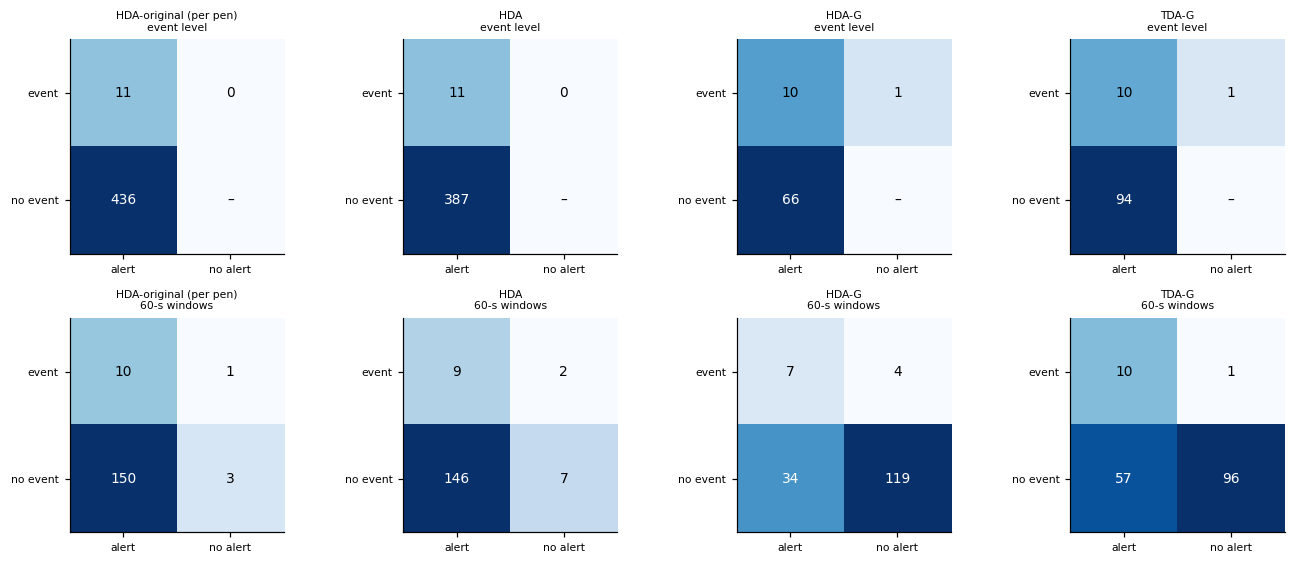

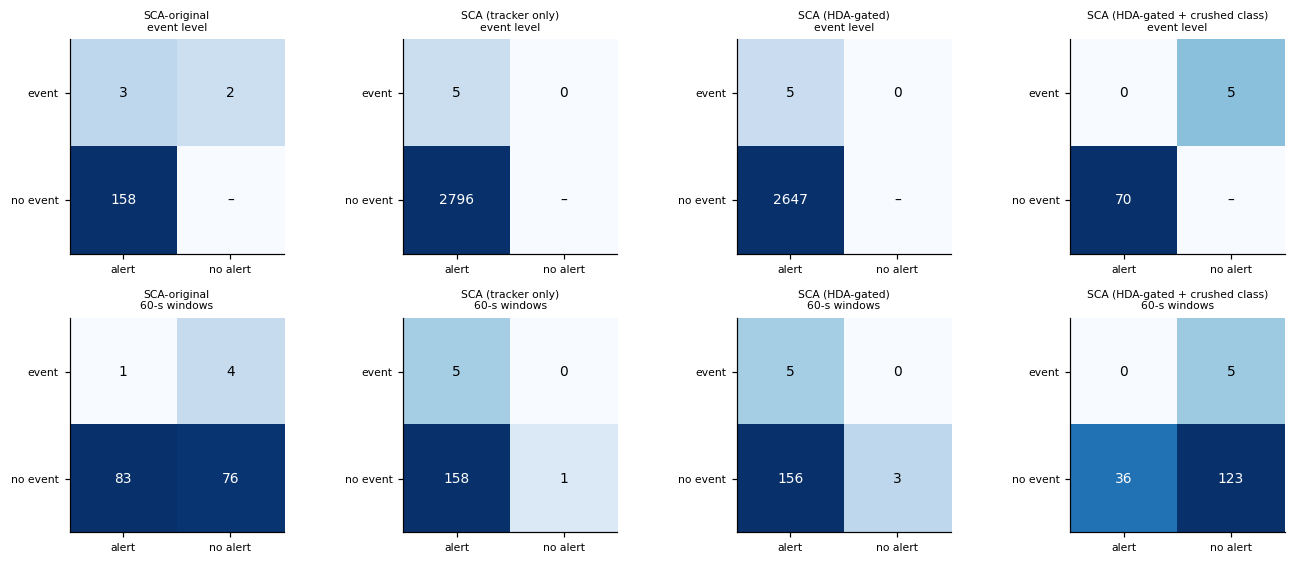

In [38]:
def plot_confusions(names, fname):
    fig, axes = plt.subplots(2, len(names), figsize=(3.1 * len(names), 5.2))
    for j, name in enumerate(names):
        src = CONT if name in TRAP_METHODS else CONT_CDA
        r = src[(src.method == name) & (src.scope == "target")].iloc[0]
        ev_m = np.array([[r.TP, r.FN], [r.FP, np.nan]])
        win_m = np.array([[r.win_TP, r.win_FN], [r.win_FP, r.win_TN]])
        for i, (mat, ttl, lab) in enumerate([(ev_m, "event level", ["alert", "no alert"]), (win_m, "60-s windows", ["alert", "no alert"])]):
            ax = axes[i, j]
            lm = np.nan_to_num(np.log1p(mat.astype(float)))
            ax.imshow(lm, cmap="Blues")
            for (a, b), v in np.ndenumerate(mat):
                ax.text(b, a, "–" if np.isnan(v) else int(v), ha="center", va="center", fontsize=9,
                        color="white" if lm[a, b] > 0.6 * lm.max() else "black")
            ax.set_xticks([0, 1]); ax.set_xticklabels(lab, fontsize=7); ax.set_yticks([0, 1])
            ax.set_yticklabels(["event", "no event"], fontsize=7)
            ax.set_title(f"{pname(name)[:34]}\n{ttl}", fontsize=7)
    fig.tight_layout(); save_fig(fig, fname); plt.show()

plot_confusions(["HPA-orig, per pen", "HPA-v2", "HPA-v2 + sow-activity gate", "TPA-v2 + gate"], "F4_confusion_trapping")
plot_confusions(["CDA-orig (sort, t_expire=1 frame, f=300 fr, m=200 px)", "CDA-v2, no HPA (tracker only)",
                 "CDA-v2, HPA-gated", "CDA-v2, HPA-gated + crushed class"], "F5_confusion_crushing")

### 8.1 Time-axis example — estimated hidden piglets and alerts
Visible piglets per pen ($\tilde n$), expected total ($N^{Tot}$), currently missing ($M$), stabilised missing level ($\bar M$), sow activity ($a$) and alerts plotted together.

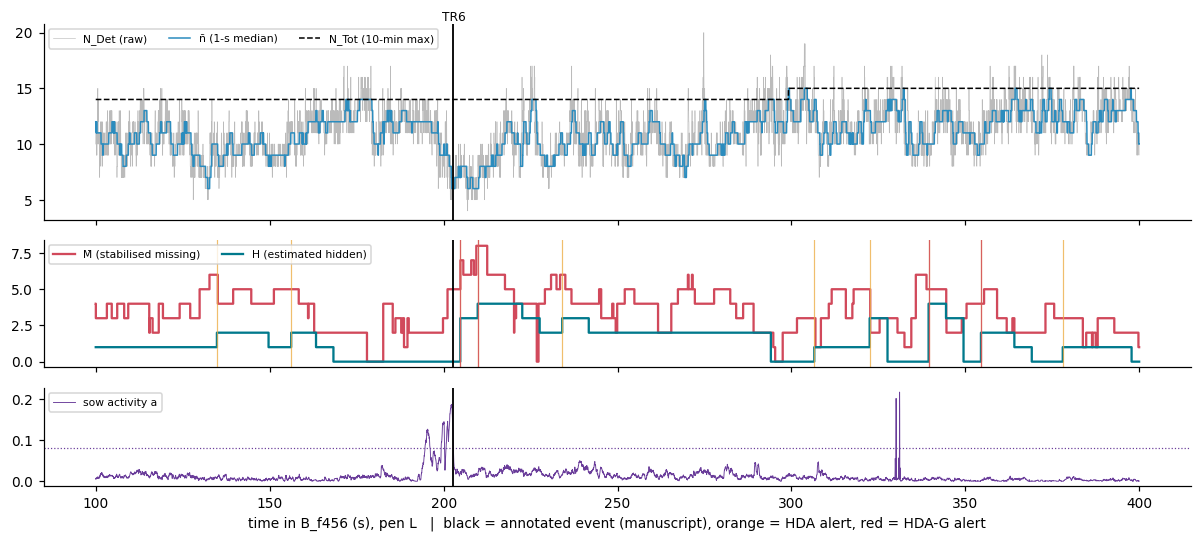

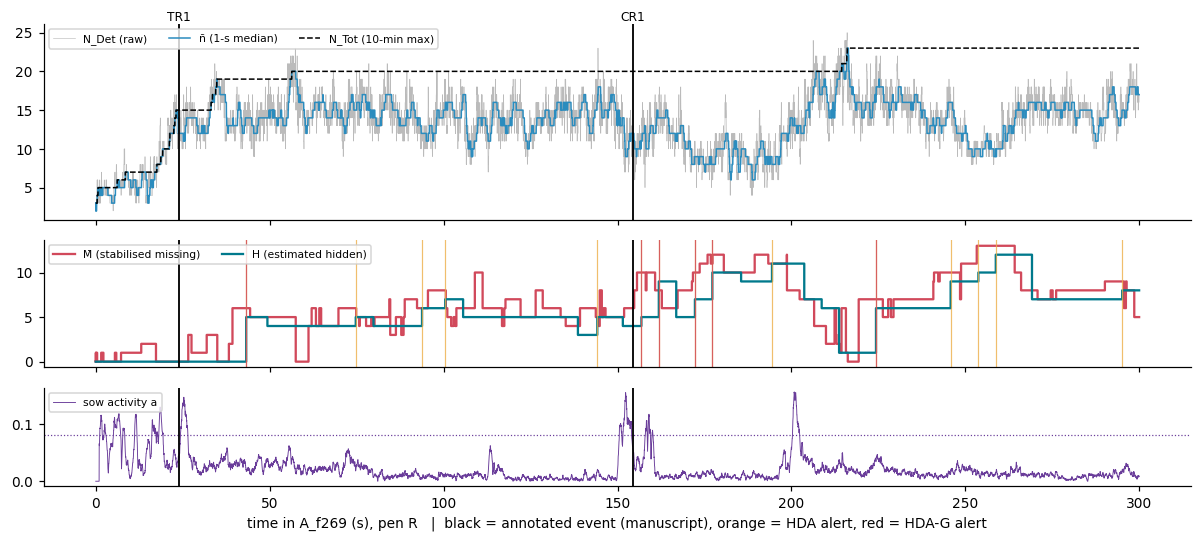

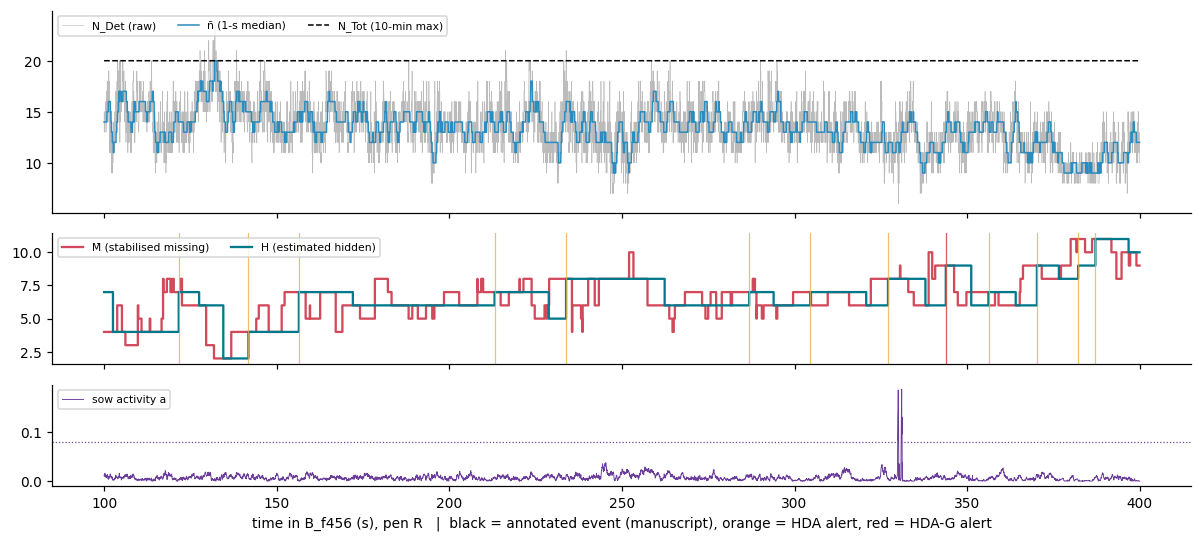

In [39]:
def plot_timeline(rec, pen, t0=None, t1=None, fname=None):
    f = FPS[rec]; ts, ev = H2[(rec, pen)]; mot = MOTION[(rec, pen)]
    tt = np.arange(len(ts)) / f
    sl = slice(int((t0 or 0) * f), int((t1 or tt[-1]) * f))
    fig, axes = plt.subplots(3, 1, figsize=(11, 5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1.3, 1]))
    axes[0].plot(tt[sl], ts.n_det[sl], color="#bbbbbb", lw=.4, label="N_Det (raw)")
    axes[0].plot(tt[sl], ts.n_s[sl], color="#2b8cbe", lw=1, label="ñ (1-s median)")
    axes[0].plot(tt[sl], ts.N_Tot[sl], color="k", lw=1, ls="--", label="N_Tot (10-min max)")
    axes[1].step(tt[sl], ts.M_st[sl], where="post", color="#d1495b", label="M̄ (stabilised missing)")
    axes[1].step(tt[sl], ts.H[sl], where="post", color="#00798c", label="H (estimated hidden)")
    axes[2].plot(tt[sl], mot[sl], color="#6a3d9a", lw=.6, label="sow activity a"); axes[2].axhline(GATE_DEFAULT, color="#6a3d9a", ls=":", lw=.8)
    for name, al, col in [("HDA", AL_H2, "#edae49"), ("HDA-G", AL_H2G, "#d1495b")]:
        s = al[(al.rec == rec) & (al.pen == pen)]
        for a in s.alert_s:
            if (t0 or 0) <= a <= (t1 or tt[-1]):
                axes[1].axvline(a, color=col, lw=.8, alpha=.8)
    for e in EV[(EV.rec == rec) & (EV.pen == pen)].itertuples():
        for ax in axes:
            ax.axvline(e.onset_s, color="k", lw=1.2)
        axes[0].text(e.onset_s, axes[0].get_ylim()[1], e.event_id, fontsize=8, ha="center", va="bottom")
    for ax in axes:
        ax.legend(fontsize=7, loc="upper left", ncol=3)
    axes[2].set_xlabel(f"time in {rec} (s), pen {pen}   |  black = annotated event (manuscript), orange = HDA alert, red = HDA-G alert")
    fig.tight_layout()
    if fname:
        save_fig(fig, fname)
    plt.show()

plot_timeline("B_f456", "L", 100, 400, "F6_timeline_TR6")
plot_timeline("A_f269", "R", 0, 300, "S_F7_timeline_TR1_CR1")
plot_timeline("B_f456", "R", 100, 400, "S_F8_timeline_BR_no_event")

### 8.2 Alert review package (for independent labelling by two observers)
For the alerts of the main methods — **all** trapping alerts (TPA-v2 + gate) and, because there are many, a **random sample of 150** suspected-crushing alerts (CDA-v2 with HPA + activity gate) — the pen-region images at −10, −5, 0, +5 and +10 s around the alert are combined into one image,
and a labelling CSV is created (columns `observer1`, `observer2`: `trapping`/`crushing`/`no_event`/`uncertain`). The comparison with the manuscript GT (answer columns) is
stored not in the labelling sheet but in a separate file, `review_key.csv`, so that opening the sheet does not break the blinding. When two observers fill it in without seeing each other's labels,
the agreement of §16 (pre-consensus κ) and the metrics of §8 can be recomputed from the actual labels.

In [40]:
def export_review(alerts, name, sample_n=None, seed=0):
    """all alerts (or a random sample of sample_n alerts, so that the labelled share is representative)"""
    d = OUT / "alert_review" / name; d.mkdir(parents=True, exist_ok=True)
    sheet = d / "review_sheet.csv"
    rows = []
    caps = {}
    n_total = len(alerts)
    sel = alerts.sample(n=sample_n, random_state=seed) if sample_n and n_total > sample_n else alerts
    for i, a in enumerate(sel.sort_values(["rec", "pen", "alert_s"]).itertuples()):
        fn = f"{i:04d}_{a.rec}_{a.pen}_{a.alert_s:07.1f}s.jpg"
        rows.append(dict(id=i, rec=a.rec, pen=a.pen, alert_s=round(a.alert_s, 1),
                         clock_time=str(START[a.rec] + pd.to_timedelta(a.alert_s, unit="s"))[:19],
                         status_vs_manuscript_GT=getattr(a, "status", ""), matched_event=getattr(a, "match", ""),
                         image=fn, n_alerts_total=n_total, observer1="", observer2="", consensus="", notes=""))
        if (d / fn).exists() or not (ROOT / VIDEOS[a.rec]["path"]).exists():     # stills need the video
            continue
        cam = a.rec[0]; x0, x1 = PEN_ROI[cam][a.pen] if a.pen in PEN_ROI[cam] else (0, 1920)
        if a.rec not in caps:
            caps[a.rec] = cv2.VideoCapture(str(ROOT / VIDEOS[a.rec]["path"]))
        cap = caps[a.rec]; tiles = []
        for dt in (-10, -5, 0, 5, 10):
            cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, int((a.alert_s + dt) * FPS[a.rec])))
            ok, fr = cap.read()
            fr = cv2.resize(fr, (1920, 1080))[:, x0:x1] if ok else np.zeros((1080, x1 - x0, 3), np.uint8)
            fr = cv2.resize(fr, (int(360 * (x1 - x0) / 1080), 360))
            cv2.putText(fr, f"{dt:+d}s", (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2)
            tiles.append(fr)
        img = np.hstack(tiles)
        cv2.putText(img, f"#{i} {a.rec} pen {a.pen} t={a.alert_s:.1f}s", (8, 352), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        cv2.imwrite(str(d / fn), img, [cv2.IMWRITE_JPEG_QUALITY, 70])
    for c in caps.values():
        c.release()
    df = pd.DataFrame(rows)
    # the comparison with the manuscript GT goes to a separate answer-key file, so that the sheet the observers work in is blind
    key_cols = ["status_vs_manuscript_GT", "matched_event"]
    df[["id", "image"] + key_cols].to_csv(d / "review_key.csv", index=False)
    df = df.drop(columns=key_cols)
    if sheet.exists():                       # keep every label column already entered by the observers
        old = pd.read_csv(sheet, dtype=str).fillna("").set_index("image")
        for c in old.columns:
            if c.startswith("observer") or c in ("consensus", "notes"):
                df[c] = df.image.map(old[c]).fillna("")
    df.to_csv(sheet, index=False)
    return df.merge(pd.read_csv(d / "review_key.csv", dtype=str).fillna("")[["image"] + key_cols], on="image", how="left")

REV1 = export_review(ALERT_STATUS["TPA-v2 + gate"], "TPA_v2_gate")
REV2 = export_review(ALERT_STATUS["CDA-v2, HPA+gate-gated"], "CDA_v2_HPA_activity_gated", sample_n=150)
print(len(REV1), "trapping alerts (all) and", len(REV2), "of", int(REV2.n_alerts_total.iloc[0]) if len(REV2) else 0,
      "suspected-crushing alerts (random sample) exported to", OUT / "alert_review")
display(REV1.status_vs_manuscript_GT.value_counts().to_frame().T)

182 trapping alerts (all) and 150 of 784 suspected-crushing alerts (random sample) exported to outputs/alert_review


status_vs_manuscript_GT,FP,DUP,TP
count,156,16,10


### 8.3 Comparison between detectors (same development-setting parameters)
Key metrics when only the detector is changed, with the same algorithms and parameters. The provided YOLOv8s was trained on the evaluation frames, so its values are for reference only.

In [41]:
def key_methods_for(tag):
    cnt = count_runs(tag=tag); trk = get_trk(tag)
    h2 = hpa_v2_runs(cnt, **HPA_DEFAULT)
    al_h2 = alerts_hpa_v2(h2); al_h2g = alerts_hpa_v2(h2, gate=GATE_DEFAULT); al_vt = alerts_vt(cnt)
    trap = {"HPA-orig, per pen": alerts_hpa_orig(cnt), "HPA-v2": al_h2, "HPA-v2 + sow-activity gate": al_h2g,
            "Visible trapping (image-only)": al_vt, "TPA-v2 + gate": alerts_union(al_h2g, al_vt)}
    crush = {"CDA-orig": alerts_cda_orig(trk), "CDA-v2, HPA+gate-gated": alerts_cda_v2(trk, gate_alerts_df=al_h2g),
             "CDA-v2, HPA-gated + crushed class": alerts_cda_v2(trk, gate_alerts_df=al_h2, require_crushed=True)}
    rows = []
    for name, al in trap.items():
        df, _ = evaluate(al, GT_ALL, scopes=("target", "all"), control=False); rows.append(df.assign(method=name, target="trapping events (11)"))
    for name, al in crush.items():
        df, _ = evaluate(al, GT_CR, scopes=("target", "all"), control=False); rows.append(df.assign(method=name, target="crushing events (5)"))
    return pd.concat(rows)

DETCMP = pd.concat([key_methods_for(tag).assign(detector=name) for name, tag in DETECTORS.items()])
DETCMP_V = DETCMP.pivot_table(index=["scope", "target", "method"], columns="detector", values=["recall", "precision", "FA_per_pen_h"], sort=False)
display(DETCMP_V.round(3))
save_table(DETCMP[["detector", "scope", "target", "method", "TP", "FN", "FP", "DUP", "precision", "recall", "F1", "FA_per_pen_h",
                   "latency_median_s"]].round(4), "T10b_detector_comparison_continuous")

recall                                                    \
detector                                                      provided YOLOv8s (training incl. evaluation frames) YOLOv8s-416 leakage-free YOLOv5s-416 leakage-free   
scope  target               method                                                                                                                                    
target trapping events (11) HPA-orig, per pen                                                              1.000                     1.000                    1.000   
                            HPA-v2                                                                         0.909                     1.000                    1.000   
                            HPA-v2 + sow-activity gate                                                     0.636                     0.909                    0.909   
                            Visible trapping (image-only)                                                  0.727                     0.364                    0.545   
                            TPA-v2 + gate                                                                  1.000                     0.909                    1.000   
       crushing events (5)  CDA-orig                                                                       0.800                     0.400                    0.400   
                            CDA-v2, HPA+gate-gated                                                         1.000                     1.000                    1.000   
                            CDA-v2, HPA-gated + crushed class                                              0.800                     0.000                    0.400   
all    trapping events (11) HPA-orig, per pen                                                              1.000                     1.000                    1.000   
                            HPA-v2                                                                         0.909                     1.000                    1.000   
                            HPA-v2 + sow-activity gate                                                     0.636                     0.909                    0.909   
                            Visible trapping (image-only)                                                  0.727                     0.364                    0.545   
                            TPA-v2 + gate                                                                  1.000                     0.909                    1.000   
       crushing events (5)  CDA-orig                                                                       0.800                     0.400                    0.400   
                            CDA-v2, HPA+gate-gated                                                         1.000                     1.000                    1.000   
                            CDA-v2, HPA-gated + crushed class                                              0.800                     0.000                    0.400   

                                                                                                                                                                                        precision  \
detector                                                      selected leakage-free (pre-specified rule) YOLOv5s-416 [9] recipe, leakage-free provided YOLOv8s (training incl. evaluation frames)   
scope  target               method                                                                                                                                                                  
target trapping events (11) HPA-orig, per pen                                                      1.000                                1.000                                              0.029    
                            HPA-v2                                                                 1.000                                1.000    

,detector,scope,target,method,TP,FN,FP,DUP,precision,recall,F1,FA_per_pen_h,latency_median_s
0,provided YOLOv8s (training incl. evaluation fr...,target,trapping events (11),"HPA-orig, per pen",11,0,363,31,0.0294,1.0000,0.0571,131.4811,-2.6388
1,provided YOLOv8s (training incl. evaluation fr...,all,trapping events (11),"HPA-orig, per pen",11,0,511,31,0.0211,1.0000,0.0413,132.1935,-2.6388
0,provided YOLOv8s (training incl. evaluation fr...,target,trapping events (11),HPA-v2,10,1,344,28,0.0282,0.9091,0.0548,124.5992,-3.3307
1,provided YOLOv8s (training incl. evaluation fr...,all,trapping events (11),HPA-v2,10,1,473,28,0.0207,0.9091,0.0405,122.3631,-3.3307
0,provided YOLOv8s (training incl. evaluation fr...,target,trapping events (11),HPA-v2 + sow-activity gate,7,4,61,9,0.1029,0.6364,0.1772,22.0946,2.5692
1,provided YOLOv8s (training incl. evaluation fr...,all,trapping events (11),HPA-v2 + sow-activity gate,7,4,91,9,0.0714,0.6364,0.1284,23.5413,2.5692
0,provided YOLOv8s (training incl. evaluation fr...,target,trapping events (11),Visible trapping (image-only),8,3,43,5,0.1569,0.7273,0.2581,15.5749,-3.0693
1,provided YOLOv8s (training incl. evaluation fr...,all,trapping events (11),Visible trapping (image-only),8,3,43,5,0.1569,0.7273,0.2581,11.1239,-3.0693
0,provided YOLOv8s (training incl. evaluation fr...,target,trapping events (11),TPA-v2 + gate,11,0,77,10,0.1250,1.0000,0.2222,27.8899,-0.3697
1,provided YOLOv8s (training incl. evaluation fr...,all,trapping events (11),TPA-v2 + gate,11,0,102,10,0.0973,1.0000,0.1774,26.3870,-0.3697


### 8.4 Pen-boundary sensitivity — the central straw zone of camera B (R1-8)
Which pen the straw zone left of the partition post of camera B (x ≈ 640–850 px) belongs to could not be confirmed from a farm layout. Piglet trajectories break at the partition bars, so they did not help,
and piglets were rarely in the straw zone (0–0.4 per frame on average). The boundary was therefore set to x = 850 (straw zone → B-L, main analysis) and to x = 640 (straw zone → B-R)
to check whether the results of the count-based methods change.

In [42]:
def roi_sensitivity():
    rows = []
    base_roi = dict(PEN_ROI["B"])
    for label, xb in [("x=850: straw zone -> B-L (main)", 850), ("x=640: straw zone -> B-R", 640)]:
        PEN_ROI["B"] = {"L": (0, xb), "R": (xb, 1920)}
        try:
            mot = dict(MOTION)
            for r in RECS["B"]:
                for p in ("L", "R"):
                    mot[(r, p)] = pen_motion(r, p, "B")
            cnt = count_runs(tag=MAIN_TAG)
            h2 = hpa_v2_runs(cnt, **HPA_DEFAULT)
            al_h2g = alerts_hpa_v2(h2, gate=GATE_DEFAULT, motion=mot)
            for name, al in {"HPA-orig, per pen": alerts_hpa_orig(cnt), "HPA-v2 + sow-activity gate": al_h2g,
                             "TPA-v2 + gate": alerts_union(al_h2g, alerts_vt(cnt))}.items():
                for scope in ("B-L", "B-R"):
                    m_, _, _ = eval_lits_simple(al, GT_ALL, [scope])
                    rows.append(dict(boundary=label, method=name, litter=scope, **{k: m_[k] for k in ["TP", "FN", "FP", "recall", "FA_per_pen_h"]}))
        finally:
            PEN_ROI["B"] = base_roi
    return pd.DataFrame(rows)

def eval_lits_simple(alerts, gt, lits):
    rp = [x for lit in lits for x in LITTER_RP[lit]]
    al = alerts[np.array([(r, p) in rp for r, p in zip(alerts.rec, alerts.pen)], dtype=bool)]   # bool array: an empty list would select columns
    a2, g2 = match_alerts(al, gt[gt.litter.isin(lits)], exclude=EXCLUDE)
    return event_metrics(a2, g2, sum(PEN_HOURS[l] for l in lits)), a2, g2

ROIS = roi_sensitivity()
display(ROIS.pivot_table(index=["method", "litter"], columns="boundary", values=["recall", "FA_per_pen_h"]).round(2))
save_table(ROIS.round(4), "S7_pen_boundary_sensitivity")

FA_per_pen_h                                                   recall                                
boundary                          x=640: straw zone -> B-R x=850: straw zone -> B-L (main) x=640: straw zone -> B-R x=850: straw zone -> B-L (main)
method                     litter                                                                                                                  
HPA-orig, per pen          B-L                      159.32                          157.51                      1.0                             1.0
                           B-R                      190.10                          186.48                      NaN                             NaN
HPA-v2 + sow-activity gate B-L                       21.73                           13.58                      1.0                             1.0
                           B-R                       22.63                           29.87                      NaN                             NaN
TPA-v2 + gate              B-L                       30.78                           28.06                      1.0                             1.0
                           B-R                       51.60                           56.12                      NaN                             NaN

,boundary,method,litter,TP,FN,FP,recall,FA_per_pen_h
0,x=850: straw zone -> B-L (main),"HPA-orig, per pen",B-L,6,0,174,1.0,157.5099
1,x=850: straw zone -> B-L (main),"HPA-orig, per pen",B-R,0,0,206,NaN,186.4772
2,x=850: straw zone -> B-L (main),HPA-v2 + sow-activity gate,B-L,6,0,15,1.0,13.5784
3,x=850: straw zone -> B-L (main),HPA-v2 + sow-activity gate,B-R,0,0,33,NaN,29.8726
4,x=850: straw zone -> B-L (main),TPA-v2 + gate,B-L,6,0,31,1.0,28.0621
5,x=850: straw zone -> B-L (main),TPA-v2 + gate,B-R,0,0,62,NaN,56.1242
6,x=640: straw zone -> B-R,"HPA-orig, per pen",B-L,6,0,176,1.0,159.3203
7,x=640: straw zone -> B-R,"HPA-orig, per pen",B-R,0,0,210,NaN,190.0981
8,x=640: straw zone -> B-R,HPA-v2 + sow-activity gate,B-L,6,0,24,1.0,21.7255
9,x=640: straw zone -> B-R,HPA-v2 + sow-activity gate,B-R,0,0,25,NaN,22.6307


### 8.5 Alert labels (labelling notebook `outputs/alert_review/label_alerts_video.ipynb`)
When labels (`observer1`) have been entered, the precision of the alerts and the false alarms per hour are recomputed against the **labels** instead of the manuscript GT.
If only some alerts are labelled, the proportions are estimated from the labelled alerts and the hourly values are scaled to the total number of alerts. The counts of 'no_event' reasons are used to analyse the causes of false alarms (R1-2, R1-9).
(Recall cannot be obtained from alerts alone — events missed by the alerts can only be found by annotating the continuous video from the beginning.)

**Blinding record**: during the first labelling (`observer1`) on 2026-10-09 the labelling sheet still contained the columns comparing with the manuscript GT (`status_vs_manuscript_GT`, `matched_event`).
However, the labelling tool (`label_alerts_video.ipynb`) did not display these columns (code checked), and the observer did not open the CSV during labelling (confirmed by the observer, 2026-10-21).
These columns were later moved to `review_key.csv`.

**Caution in interpretation**: these labels judge, on ±15 s of video around the alert, whether 'there is a trapped or dead piglet in this scene' (a state), whereas the continuous annotation (§8.6) marks
'the moment a trapping started'. The agreement between the two criteria is low (§8.6), so the precision and false alarms of this section are **secondary results**; the main results are those against the blind full annotation of §8.6.

In [43]:
def labelled_metrics(name, col="observer1", lits=None, show=True):
    path = OUT / "alert_review" / name / "review_sheet.csv"
    sh = pd.read_csv(path, dtype=str).fillna("") if path.exists() else pd.DataFrame()
    keyp = path.parent / "review_key.csv"
    if len(sh) and keyp.exists() and "status_vs_manuscript_GT" not in sh:
        sh = sh.merge(pd.read_csv(keyp, dtype=str).fillna("")[["image", "status_vs_manuscript_GT"]], on="image", how="left")
    if col not in sh or (sh[col] != "").sum() == 0:
        print(tr(f"{name}: '{col}' 판정이 아직 없음 -> {path}", f"{name}: no '{col}' labels yet -> {path}"))
        return None
    lits = lits or TARGET_LITTERS
    n_sheet_all = len(sh)
    total_all = int(sh.n_alerts_total.iloc[0]) if "n_alerts_total" in sh else len(sh)
    sh = sh[[LIT_OF[(r[0], p)] in lits for r, p in zip(sh.rec, sh.pen)]]
    hours = sum(PEN_HOURS[l] for l in lits)
    lab = sh[sh[col] != ""]
    n_all = total_all * len(sh) / n_sheet_all        # sample sheets -> scale to all alerts of these litters
    n_lab = len(lab)
    pos = lab[col].isin(["trapping", "crushing"]).sum(); neg = (lab[col] == "no_event").sum(); unc = (lab[col] == "uncertain").sum()
    out = dict(sheet=name, litters="+".join(lits), labelled=f"{n_lab}/{len(sh)} in sheet (~{n_all:.0f} alerts in these litters)", event_confirmed=int(pos), no_event=int(neg), uncertain=int(unc),
               precision_verified=pos / (pos + neg) if pos + neg else np.nan,
               precision_95CI=wilson(int(pos), int(pos + neg)),
               FA_per_pen_h_verified=(neg / n_lab) * n_all / hours)
    if show:
        display(pd.DataFrame([out]).round(3))
        display(pd.crosstab(lab[col], lab.status_vs_manuscript_GT).rename_axis(index="label", columns="vs manuscript GT"))
        if (lab[col] == "no_event").any() and f"{col}_reason" in lab:
            display(lab[lab[col] == "no_event"][f"{col}_reason"].value_counts().rename("no_event reasons").to_frame())
    return out

display(Markdown(tr("**목표 집단(", "**Target population (") + " + ".join(TARGET_LITTERS) + ")**"))
LABELLED = {n: labelled_metrics(n, lits=TARGET_LITTERS) for n in ["TPA_v2_gate", "CDA_v2_HPA_activity_gated"]}
display(Markdown(tr("**전체 3개 복(민감도 분석)**", "**All 3 litters (sensitivity analysis)**")))
LABELLED_ALL = {n: labelled_metrics(n, lits=ALL_LITTERS) for n in ["TPA_v2_gate", "CDA_v2_HPA_activity_gated"]}

**Target population (A-R + B-L)**

,sheet,litters,labelled,event_confirmed,no_event,uncertain,precision_verified,precision_95CI,FA_per_pen_h_verified
0,TPA_v2_gate,A-R+B-L,120/120 in sheet (~120 alerts in these litters),72,48,0,0.6,"(0.5105585981828253, 0.6832373476059888)",17.386


vs manuscript GT,DUP,FP,TP
label,,,
crushing,7,14,2
no_event,3,45,0
trapping,6,35,8


,no_event reasons
observer1_reason,
piglets_overlapping_huddling_nursing,25
person_or_management,9
hidden_behind_or_beside_sow,9
detector_miss_light_or_bars,5


CDA_v2_HPA_activity_gated: no 'observer1' labels yet -> outputs/alert_review/CDA_v2_HPA_activity_gated/review_sheet.csv


**All 3 litters (sensitivity analysis)**

,sheet,litters,labelled,event_confirmed,no_event,uncertain,precision_verified,precision_95CI,FA_per_pen_h_verified
0,TPA_v2_gate,A-R+B-L+B-R,182/182 in sheet (~182 alerts in these litters),72,110,0,0.396,"(0.32742596738050733, 0.4680988236243053)",28.457


vs manuscript GT,DUP,FP,TP
label,,,
crushing,7,14,2
no_event,3,107,0
trapping,6,35,8


,no_event reasons
observer1_reason,
detector_miss_light_or_bars,50
piglets_overlapping_huddling_nursing,42
person_or_management,9
hidden_behind_or_beside_sow,9


CDA_v2_HPA_activity_gated: no 'observer1' labels yet -> outputs/alert_review/CDA_v2_HPA_activity_gated/review_sheet.csv


#### 8.5.1 Label details — precision per litter, causes of false alarms, events confirmed by the labels
The trapping-alert sheet was labelled **completely** (not a sample), so false alarms per hour can be computed per litter directly.
Alerts confirmed by the labels (trapping/crushing) of the same pen within 60 s of each other are grouped into 'label-confirmed events', and their overlap with the manuscript events is checked.
**Note**: this event list was found only among the alerts of this method (TPA-v2 + gate), so using it as GT for the recall of this method would be circular —
it is used only to show the precision and 'how many unannotated events there were'.

observer1,trapping,crushing,no_event,uncertain,confirmed,precision_verified,pen_hours,FA_per_pen_h_verified
litter,,,,,,,,
A-R,34.0,16.0,20.0,0.0,50.0,0.714,1.656,12.076
B-L,15.0,7.0,28.0,0.0,22.0,0.440,1.105,25.346
B-R,0.0,0.0,62.0,0.0,0.0,0.000,1.105,56.124
target (A-R+B-L),49.0,23.0,48.0,0.0,72.0,0.600,2.761,17.386
all litters,49.0,23.0,110.0,0.0,72.0,0.396,3.866,28.457


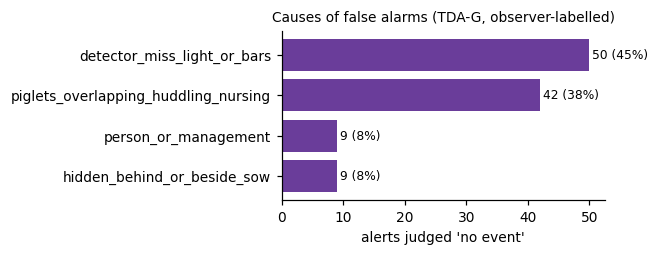

,confirmed_episodes,of_which_manuscript_events,episodes_per_pen_h
litter,,,
A-R,23.0,4.0,13.89
B-L,7.0,5.0,6.34
target litters,30.0,9.0,10.87


,rec,pen,litter,clock_start,start,end,n_alerts,labels,manuscript_event
0,A_f257,R,A-R,2022-07-07 16:59:06,591.1,602.0,2,crushing,
1,A_f257,R,A-R,2022-07-07 17:01:04,709.5,735.3,3,crushing+trapping,
2,A_f269,R,A-R,2022-07-07 20:18:52,28.2,38.3,2,crushing,TR1
3,A_f269,R,A-R,2022-07-07 20:21:00,156.9,224.3,4,crushing+trapping,CR1
4,A_f269,R,A-R,2022-07-07 20:23:23,299.3,299.3,1,trapping,
5,A_f269,R,A-R,2022-07-07 20:24:52,388.8,388.8,1,trapping,
6,A_f269,R,A-R,2022-07-07 20:26:01,457.7,457.7,1,trapping,
7,A_kt1958,R,A-R,2022-07-07 19:26:21,14.7,14.7,1,trapping,TR2
8,A_kt1958,R,A-R,2022-07-07 19:28:00,113.0,250.7,6,trapping,
9,A_kt1958,R,A-R,2022-07-07 19:31:47,340.2,480.3,7,trapping,


In [44]:
SHEET_PAPER = {"TPA_v2_gate": "TDA-G", "CDA_v2_HPA_activity_gated": "SCA-G"}

def labelled_detail(name="TPA_v2_gate", col="observer1", merge_s=60.0):
    path = OUT / "alert_review" / name / "review_sheet.csv"
    sh = pd.read_csv(path, dtype=str).fillna("") if path.exists() else pd.DataFrame()
    if col not in sh or (sh[col] != "").sum() == 0:
        print(tr("판정 없음", "no labels")); return None
    sh["alert_s"] = sh.alert_s.astype(float)
    sh["litter"] = [LIT_OF[(r[0], p)] for r, p in zip(sh.rec, sh.pen)]
    lab = sh[sh[col] != ""].copy()
    by = lab.groupby("litter")[col].value_counts().unstack(fill_value=0)
    for c in ["trapping", "crushing", "no_event", "uncertain"]:
        if c not in by:
            by[c] = 0
    by["confirmed"] = by.trapping + by.crushing
    by["precision_verified"] = by.confirmed / (by.confirmed + by.no_event)
    by["pen_hours"] = [PEN_HOURS[l] for l in by.index]
    full = len(lab) == len(sh) and "n_alerts_total" in sh and int(sh.n_alerts_total.iloc[0]) == len(sh)
    by["FA_per_pen_h_verified"] = by.no_event / by.pen_hours if full else np.nan
    for label, lits_ in (("target (" + "+".join(TARGET_LITTERS) + ")", TARGET_LITTERS), ("all litters", ALL_LITTERS)):
        sub = by.loc[[l for l in lits_ if l in by.index]]
        tot = sub[["trapping", "crushing", "no_event", "uncertain", "confirmed"]].sum()
        tot["precision_verified"] = tot.confirmed / (tot.confirmed + tot.no_event)
        tot["pen_hours"] = sum(PEN_HOURS[l] for l in lits_)
        tot["FA_per_pen_h_verified"] = tot.no_event / tot.pen_hours if full else np.nan
        by.loc[label] = tot
    by = by[["trapping", "crushing", "no_event", "uncertain", "confirmed", "precision_verified", "pen_hours", "FA_per_pen_h_verified"]]
    display(by.round(3)); save_table(by.round(4), f"T22_labelled_alerts_by_litter_{name}", index=True)
    # false-alarm causes
    rs = lab[lab[col] == "no_event"][f"{col}_reason"].replace("", "not given").value_counts()
    fig, ax = plt.subplots(figsize=(6, 2.4))
    ax.barh(rs.index[::-1], rs.values[::-1], color="#6a3d9a")
    for y, v in enumerate(rs.values[::-1]):
        ax.text(v + .5, y, f"{v} ({100 * v / rs.sum():.0f}%)", va="center", fontsize=8)
    ax.set_xlabel("alerts judged 'no event'"); ax.set_title(f"Causes of false alarms ({SHEET_PAPER.get(name, name)}, observer-labelled)", fontsize=9)
    fig.tight_layout(); save_fig(fig, f"F11_false_alarm_causes_{SHEET_PAPER.get(name, name)}"); plt.show()
    save_table(rs.rename("n").to_frame(), f"T23_false_alarm_causes_{name}", index=True)
    # confirmed alerts -> episodes
    conf = lab[lab[col].isin(["trapping", "crushing"])].sort_values(["rec", "pen", "alert_s"])
    eps, last = [], {}
    for r in conf.itertuples():
        k = (r.rec, r.pen)
        if k in last and r.alert_s - last[k][-1]["end"] <= merge_s:
            last[k][-1]["end"] = r.alert_s; last[k][-1]["n_alerts"] += 1
            last[k][-1]["labels"].add(getattr(r, col))
        else:
            e = dict(rec=r.rec, pen=r.pen, litter=r.litter, start=r.alert_s, end=r.alert_s, n_alerts=1, labels={getattr(r, col)})
            last.setdefault(k, []).append(e); eps.append(e)
    E = pd.DataFrame(eps)
    if len(E):
        E["labels"] = E.labels.apply(lambda x: "+".join(sorted(x)))
        def ms_event(r):
            g = EV[(EV.rec == r.rec) & (EV.pen == r.pen) & (EV.onset_s - 60 <= r.end) & (EV.onset_s + 60 >= r.start)]
            return ",".join(g.event_id)
        E["manuscript_event"] = E.apply(ms_event, axis=1)
        E["clock_start"] = [str(START[r] + pd.to_timedelta(t, unit="s"))[:19] for r, t in zip(E.rec, E.start)]
        summ = E.groupby("litter").agg(confirmed_episodes=("rec", "size"),
                                       of_which_manuscript_events=("manuscript_event", lambda x: int((x != "").sum())))
        summ["episodes_per_pen_h"] = summ.confirmed_episodes / [PEN_HOURS[l] for l in summ.index]
        summ.loc["target litters"] = [summ.loc[summ.index.isin(TARGET_LITTERS)].confirmed_episodes.sum(),
                                      summ.loc[summ.index.isin(TARGET_LITTERS)].of_which_manuscript_events.sum(),
                                      summ.loc[summ.index.isin(TARGET_LITTERS)].confirmed_episodes.sum() / sum(PEN_HOURS[l] for l in TARGET_LITTERS)]
        display(summ.round(2)); display(E[["rec", "pen", "litter", "clock_start", "start", "end", "n_alerts", "labels", "manuscript_event"]])
        save_table(E, f"T24_observer_confirmed_episodes_{name}")
        save_table(summ.round(3), f"T24b_observer_confirmed_episodes_summary_{name}", index=True)
    lab_t = lab[lab.litter.isin(TARGET_LITTERS)]
    rs_t = lab_t[lab_t[col] == "no_event"][f"{col}_reason"].replace("", "not given").value_counts()
    return dict(by_litter=by, reasons=rs, reasons_target=rs_t, episodes=E)

LDET = labelled_detail("TPA_v2_gate")

### 8.6 Evaluation against the full annotation of the continuous video (R1-2: recall including missed events)
The recall of §8 uses only the 11 manuscript events as the reference. Yet of the 30 episodes confirmed by the alert labels (§8.5.1) only 9 were annotated in the manuscript,
so the manuscript reference is incomplete. The **entire** continuous recordings of the target-population pens (A-R, B-L) were therefore annotated from the beginning with a tool that does not show the alerts
(`outputs/continuous_annotation/annotate_continuous.ipynb`: 2-min segments per pen viewed in time order, marking the time at which each trapping starts).

**Evaluation rules (fixed before looking at the annotation)**
- Reference events = the `trapping` and `crushing` marks of the annotation (`crushing` = time at which a piglet suspected dead started to be trapped).
  `uncertain` marks are neither reference events nor false alarms (alerts within their [−10, +60] s are EXCLUDED). The manuscript's candidate exclusion windows (§2.5) are not used.
- Matching window for trapping alerts (HDA/TDA family): [onset −10 s, +60 s] — as in §8. For events whose end (`e`, the piglet came out again) was marked by the annotator, the window is extended
  to [onset −10 s, max(onset +60 s, end +10 s)] — additional alerts while the trapping continues are duplicates (DUP) of the same event, not false alarms.
- Matching window for suspected-crushing alerts (SCA family): [−10 s, +180 s] around a `crushing` mark (trapping → reappearance → confirmation of immobility takes time).
- `trapping` and `crushing` marks of the same pen ≤ 5 s apart are merged into one event (a dead piglet marked with both `t` and `c`; `crushing` if either is).
- `found_at_release` (`r`: the moment of trapping was not seen; the piglet was revealed under the sow when she got up) has no known onset, so it is not in the recall denominator and is counted separately.
  Alerts within [revealed −120 s, +10 s] are not counted as false alarms (EXCLUDED), and whether there was an alert in that window is reported as a secondary result.
- Events < 3 min apart in the same litter = one episode → episode-level recall is reported as well.
- A litter enters the evaluation **only when all of its segments have been annotated** (avoids bias from partial annotation).
- The annotator had seen alert review videos before, so the annotation is not completely blind (to be stated in the paper).
- **Adjudication of discrepancies**: episodes confirmed as events by the alert labels but without any mark within 60 s in the continuous annotation were
  re-examined by the same observer (`prep_09_adjudication_items.py`, `adjudicate.ipynb`) and decided as 'continuation of an earlier event / missed new trapping / not trapping / cannot be judged'.
  **The main results use the blind continuous annotation (primary reference)** (evaluation rules fixed before annotating); the adjudicated reference is secondary.
  The adjudication re-examined only one direction — 'the alert says event but the continuous annotation has none' — so it may be biased in favour of the algorithm (discrepant-analysis bias);
  the difference between the two results is the maximum size of that effect. 18 of the 20 decisions were coded by the analyst from the observer's notes and explanations (`decision_source`).

In [45]:
from sklearn.metrics import cohen_kappa_score
FULL_DIR = OUT / "continuous_annotation"
FULL_ANNOTATOR = "observer1"

def _index_events(ev):
    """sort, number the events and group them into episodes (same litter, consecutive events <= EPISODE_GAP_S apart)"""
    ev = ev.copy()
    ev["onset_abs"] = [START[r] + pd.to_timedelta(t, unit="s") for r, t in zip(ev.rec, ev.onset_s)]
    ev = ev.sort_values(["litter", "onset_abs"]).reset_index(drop=True)
    ev["event_id"] = [f"F{i:03d}" for i in range(len(ev))]
    ep, k, last = [], 0, {}
    for l, t in zip(ev.litter, ev.onset_abs):
        if l not in last or (t - last[l]).total_seconds() > EPISODE_GAP_S:
            k += 1
        ep.append(f"FE{k:03d}"); last[l] = t
    ev["episode"] = ep
    return ev

def _windows(ev):
    """matching window after the onset: 60 s, or up to the end of the trapping (+10 s) when it is known"""
    ev = ev.copy()
    ev["duration_s"] = ev.end_s - ev.onset_s
    ev["post_s"] = np.where(ev.end_s.notna(), np.maximum(60.0, ev.duration_s + 10.0), 60.0)
    return ev

def load_full_annotation(annotator=FULL_ANNOTATOR):
    """-> events (trapping/crushing marks), 'uncertain' exclusion windows, coverage per target litter"""
    seg_p, ann_p = FULL_DIR / "segments.csv", FULL_DIR / "annotations.csv"
    seg = (pd.read_csv(seg_p).fillna({"reviewed_at": ""}) if seg_p.exists()
           else pd.DataFrame(columns=["annotator", "litter", "seg_start_s", "seg_end_s", "reviewed_at"]))
    seg = seg[(seg.annotator == annotator) & (seg.reviewed_at.astype(str) != "")]
    cov = pd.DataFrame([dict(litter=l, annotated_h=float((seg[seg.litter == l].seg_end_s - seg[seg.litter == l].seg_start_s).sum()) / 3600,
                             pen_hours=PEN_HOURS[l]) for l in TARGET_LITTERS])
    cov["coverage"] = cov.annotated_h / cov.pen_hours
    ann = (pd.read_csv(ann_p) if ann_p.exists()
           else pd.DataFrame(columns=["annotator", "litter", "rec", "pen", "type", "onset_s", "n_piglets"]))
    ann = ann[ann.annotator == annotator]
    # one event per trapping: trapping/crushing marks of the same pen <= 5 s apart are merged (crushing wins, n = max)
    tc = ann[ann.type.isin(["trapping", "crushing"])].sort_values(["rec", "pen", "onset_s"])
    rows = []
    for (r, pn), a_ in tc.groupby(["rec", "pen"], sort=False):
        cur = None
        for x in a_.itertuples():
            if cur is not None and x.onset_s - cur["last_s"] <= 5.0:
                cur["type"] = "crushing" if "crushing" in (cur["type"], x.type) else "trapping"
                cur["n_piglets"] = max(cur["n_piglets"], int(x.n_piglets)); cur["last_s"] = x.onset_s; cur["n_marks"] += 1
                continue
            if cur is not None:
                rows.append(cur)
            cur = dict(litter=x.litter, rec=r, pen=pn, type=x.type, onset_s=float(x.onset_s), last_s=float(x.onset_s),
                       n_piglets=int(x.n_piglets), n_marks=1)
        if cur is not None:
            rows.append(cur)
    ev = _index_events(pd.DataFrame(rows, columns=["litter", "rec", "pen", "type", "onset_s", "last_s", "n_piglets", "n_marks"]))
    # 'end' marks close the most recent still-open (merged) event of the same pen, as in the annotation tool
    ev["end_s"] = np.nan
    for (r, pn), en in ann[ann.type == "end"].groupby(["rec", "pen"]):
        for t in sorted(en.onset_s):
            open_ = ev[(ev.rec == r) & (ev.pen == pn) & (ev.onset_s < t) & ev.end_s.isna()]
            if len(open_):
                ev.loc[open_.onset_s.idxmax(), "end_s"] = t
    ev = _windows(ev)
    unc = ann[ann.type == "uncertain"]
    rel = ann[ann.type == "found_at_release"].reset_index(drop=True)
    unc_win = pd.concat([pd.DataFrame(dict(rec=unc.rec.to_numpy(), pen=unc.pen.to_numpy(), kind="uncertain",
                                           start_s=unc.onset_s.to_numpy() - 10.0, end_s=unc.onset_s.to_numpy() + 60.0)),
                         pd.DataFrame(dict(rec=rel.rec.to_numpy(), pen=rel.pen.to_numpy(), kind="found_at_release",
                                           start_s=rel.onset_s.to_numpy() - 120.0, end_s=rel.onset_s.to_numpy() + 10.0))],
                        ignore_index=True)
    return ev, unc_win, cov

ADJ_ITEMS, ADJ_FILE = FULL_DIR / "adjudication_items.csv", FULL_DIR / "adjudication.csv"

def apply_adjudication(ev, unc):
    """reference after the same observer re-checked the discrepancies between the two references
    (alert-confirmed episodes without any continuous-annotation mark within 60 s; prep_09 + adjudicate.ipynb).
    continuation -> the referenced event lasted at least until the end of the episode (its later alerts are duplicates);
    new_event -> a trapping/crushing missed in the continuous pass is added; not_trapping -> nothing (the alerts stay false alarms);
    unclear / preexisting_dead (a piglet already dead before the episode) -> the episode is excluded like an 'uncertain' mark;
    B_f413 check -> crushing kept or changed to trapping. decision_source: key in the tool / coded from the observer's note /
    follow-up question with video"""
    if not (ADJ_ITEMS.exists() and ADJ_FILE.exists()):
        return None
    items, adj = pd.read_csv(ADJ_ITEMS), pd.read_csv(ADJ_FILE)
    adj = adj[adj.decision.fillna("") != ""]
    if set(items["item"]) - set(adj["item"]):
        return None                                   # not finished yet
    ev, unc, new = ev.copy(), unc.copy(), []
    for a in adj.itertuples():
        sel = (ev.rec == a.rec) & (ev.pen == a.pen)
        if a.decision == "continuation" and a.ref_type in ("trapping", "crushing"):
            k = ev.index[sel & (np.abs(ev.onset_s - a.ref_onset_s) < 0.05)]
            ev.loc[k, "end_s"] = np.fmax(ev.loc[k, "end_s"], a.hi_end_s)
            if a.new_type == "crushing":              # the referenced trapping turned out to be a crushing (piglet dead afterwards)
                ev.loc[k, "type"] = "crushing"
        elif a.decision == "continuation":           # continuation of an 'uncertain' / 'found at release' mark: widen its exclusion
            off = 10.0 if a.ref_type == "uncertain" else 120.0
            k = unc.index[(unc.rec == a.rec) & (unc.pen == a.pen) & (np.abs(unc.start_s + off - a.ref_onset_s) < 0.05)]
            unc.loc[k, "end_s"] = np.fmax(unc.loc[k, "end_s"], a.hi_end_s + 10.0)
        elif a.decision == "new_event" and a.new_type == "found_at_release":
            unc = pd.concat([unc, pd.DataFrame([dict(rec=a.rec, pen=a.pen, kind="found_at_release",
                                                     start_s=a.new_onset_s - 120.0, end_s=a.new_onset_s + 10.0)])], ignore_index=True)
        elif a.decision == "new_event":
            new.append(dict(litter=LIT_OF[(a.rec[0], a.pen)], rec=a.rec, pen=a.pen, type=a.new_type, onset_s=float(a.new_onset_s),
                            last_s=float(a.new_onset_s), n_piglets=np.nan, n_marks=0, end_s=np.nan))
        elif a.decision in ("unclear", "preexisting_dead") and a.kind == "alert_episode":
            # unclear, or a piglet already dead before the episode (onset not in the footage): neither event nor false alarm
            unc = pd.concat([unc, pd.DataFrame([dict(rec=a.rec, pen=a.pen, kind=f"adjudicated_{a.decision}",
                                                     start_s=a.hi_start_s - 10.0, end_s=a.hi_end_s + 10.0)])], ignore_index=True)
        elif a.decision == "change_to_trapping":
            ev.loc[sel & (np.abs(ev.onset_s - a.hi_start_s) < 0.05), "type"] = "trapping"
    if new:
        ev = pd.concat([ev, pd.DataFrame(new)], ignore_index=True)
    ev["source"] = np.where(ev.n_marks == 0, "adjudication", "continuous annotation")
    return _windows(_index_events(ev)), unc, adj

FULL_EV, FULL_UNC, FULL_COV = load_full_annotation()
display(FULL_COV.round(3)); save_table(FULL_COV.round(4), "T25_full_annotation_coverage")
FULL_LITS = list(FULL_COV[FULL_COV.coverage >= 0.999].litter)
FULL_RES, FULL_AGREE, REFS = None, {}, {}
if FULL_LITS:
    REFS["blind"] = (FULL_EV, FULL_UNC)
    _adj = apply_adjudication(FULL_EV, FULL_UNC)
    if _adj is not None:
        REFS["adjudicated"] = _adj[:2]
        display(Markdown(tr("**불일치 재확인(adjudication) 결정**", "**Adjudication decisions**")))
        display(_adj[2].groupby(["kind", "decision"]).size().rename("n").to_frame())
        save_table(_adj[2], "T29_adjudication_decisions")
    else:
        print(tr("불일치 재확인(outputs/continuous_annotation/adjudicate.ipynb)이 아직 끝나지 않음 -> 블라인드 주석 기준만 계산",
                 "adjudication (outputs/continuous_annotation/adjudicate.ipynb) not finished yet -> blind annotation only"))
    scopes = (["target"] if set(FULL_LITS) == set(TARGET_LITTERS) else []) + FULL_LITS
    res, rel_rows, JN = [], [], {}
    sh = pd.read_csv(OUT / "alert_review" / "TPA_v2_gate" / "review_sheet.csv", dtype=str).fillna("")
    sh["alert_s"] = sh.alert_s.astype(float).round(1)
    for ref, (ev_, unc_) in REFS.items():
        gt_t = ev_.assign(pre_s=10.0)                                 # post_s: 60 s, or up to the end of the trapping + 10 s
        gt_c = ev_[ev_.type == "crushing"].assign(pre_s=10.0, post_s=lambda d: np.maximum(180.0, d.post_s))
        print(f"[{ref}] " + tr("사건:", "events:"), ev_.groupby(["litter", "type"]).size().to_dict(),
              tr("| 합쳐진 표시(t+c 등)", "| merged marks (t+c etc.)"), int((ev_.n_marks > 1).sum()), tr("| 에피소드", "| episodes"), ev_.episode.nunique(),
              tr("| 끝(또는 계속됨)이 알려진 사건", "| events with a known end (or continuation)"), int(ev_.end_s.notna().sum()),
              tr("| 제외 구간", "| excluded windows"), unc_.kind.value_counts().to_dict())
        for name, al in TRAP_METHODS.items():
            df, _ = evaluate(al, gt_t, scopes=scopes, control=False, exclude=unc_)
            res.append(df.assign(method=name, reference=ref, target_events="trapping + crushing"))
        for name, al in CDA_METHODS.items():
            df, _ = evaluate(al, gt_c, scopes=scopes, control=False, exclude=unc_)
            res.append(df.assign(method=name, reference=ref, target_events="crushing"))
        # trappings found only when the sow got up (onset unknown): any alert in [-120 s, +10 s]?
        rel = unc_[(unc_.kind == "found_at_release") & unc_.pen.isin(["L", "R"])]
        rel = rel[[LIT_OF[(r[0], p)] in FULL_LITS for r, p in zip(rel.rec, rel.pen)]]
        for name, al in (TRAP_METHODS.items() if len(rel) else []):
            hit = [bool(((al.rec == x.rec) & ((al.pen == x.pen) | (al.pen == "ALL")) & (al.alert_s >= x.start_s) & (al.alert_s <= x.end_s)).any())
                   for x in rel.itertuples()]
            rel_rows.append(dict(reference=ref, paper_name=pname(name), method=name, n_found_at_release=len(rel), with_alert_in_window=int(sum(hit))))
        # the two human references side by side: observer labels of the TDA-G alerts vs this reference
        al = TRAP_METHODS["TPA-v2 + gate"]
        al = al[[LIT_OF[(r[0], p)] in FULL_LITS for r, p in zip(al.rec, al.pen)]]
        a2, _ = match_alerts(al, gt_t[gt_t.litter.isin(FULL_LITS)], exclude=unc_)
        a2["alert_s"] = a2.alert_s.round(1)
        jn = a2.merge(sh[["rec", "pen", "alert_s", "observer1"]], on=["rec", "pen", "alert_s"], how="left")
        jn["reference_says"] = jn.status.map({"TP": "event", "DUP": "event", "FP": "no event", "EXCLUDED": "uncertain"})
        jn["alert_label"] = jn.observer1.map({"trapping": "event", "crushing": "event", "no_event": "no event", "uncertain": "uncertain"})
        display(Markdown(tr(f"**경보 판정(§8.5) vs {ref} 기준 — TDA-G 경보 {len(jn)}개**", f"**Alert labels (§8.5) vs the {ref} reference — {len(jn)} TDA-G alerts**")))
        display(pd.crosstab(jn.alert_label, jn.reference_says, margins=True))
        jj = jn[jn.alert_label.isin(["event", "no event"]) & jn.reference_says.isin(["event", "no event"])]
        FULL_AGREE[ref] = dict(n=len(jj), percent_agreement=float((jj.alert_label == jj.reference_says).mean()) if len(jj) else np.nan,
                               kappa=cohen_kappa_score(jj.alert_label, jj.reference_says) if jj.alert_label.nunique() > 1 else np.nan)
        save_table(jn.assign(reference=ref), f"T27_alert_labels_vs_{ref}_annotation"); JN[ref] = jn
    display(pd.DataFrame(FULL_AGREE).T.round(3))
    # why do the alert labels (state on a +/-15 s clip) and the blind continuous annotation (onsets) disagree? (kappa ~ 0.1)
    DISAGREE = None
    if "adjudicated" in JN:
        k_ = ["rec", "pen", "alert_s"]
        mm = JN["blind"][k_ + ["alert_label", "reference_says", "status"]].merge(
            JN["adjudicated"][k_ + ["reference_says", "status"]], on=k_, suffixes=("_blind", "_adj"))
        dis = mm[mm.alert_label.isin(["event", "no event"]) & mm.reference_says_blind.isin(["event", "no event"])
                 & (mm.alert_label != mm.reference_says_blind)].copy()
        evb = REFS["blind"][0]
        def _gap(r):       # distance (s) of the alert from the nearest blind matching window [onset - 10, onset + post]
            e = evb[(evb.rec == r.rec) & (evb.pen == r.pen)]
            if not len(e):
                return np.inf
            lo, hi = (e.onset_s - 10.0).to_numpy(), (e.onset_s + e.post_s).to_numpy()
            return float(np.min(np.maximum(0, np.maximum(lo - r.alert_s, r.alert_s - hi))))
        def _why(r):
            if r.alert_label == "no event":
                return "alert inside an annotated trapping, but its +/-15 s clip was labelled 'no event'"
            if r.status_adj == "DUP":
                return "alert while an annotated trapping was still going on (state vs onset; duplicate after re-check)"
            if r.status_adj == "EXCLUDED":
                return "piglet already dead before the episode, or unclear (excluded after re-check)"
            if r.status_adj == "TP":
                return "trapping missed in the continuous pass (found in the re-check)"
            return ("within 2 min of an annotated event but outside its matching window" if _gap(r) <= 120
                    else "no annotated event nearby (label not confirmed by the continuous annotation)")
        dis["reason"] = [_why(r) for r in dis.itertuples()]
        DISAGREE = dis.reason.value_counts().rename("n_alerts").to_frame()
        display(Markdown(tr(f"**경보 판정 vs 블라인드 연속 주석 — 불일치 {len(dis)}건의 원인**",
                            f"**Alert labels vs blind continuous annotation — causes of the {len(dis)} disagreements**"))); display(DISAGREE)
        save_table(dis, "T34_alert_labels_vs_blind_disagreements")
    FULL_RES = pd.concat(res); FULL_RES["paper_name"] = FULL_RES.method.map(pname)
    FULL_RES["EXCLUDED"] = FULL_RES.n_alerts - FULL_RES.TP - FULL_RES.FP - FULL_RES.DUP
    fcols = ["reference", "paper_name", "method", "target_events", "scope", "pen_hours", "n_events", "n_alerts", "TP", "FN", "FP", "DUP",
             "EXCLUDED", "precision", "recall", "recall_le10s", "recall_le30s", "recall_le60s", "n_episodes", "episodes_detected",
             "recall_episode", "F1", "FA_per_pen_h", "latency_median_s", "win_specificity", "win_NPV"]
    for ref in REFS:
        display(Markdown(tr(f"**{ref} 기준 — {scopes[0]}**", f"**{ref} reference — {scopes[0]}**")))
        display(FULL_RES[(FULL_RES.reference == ref) & (FULL_RES.scope == scopes[0])][fcols].round(3))
    save_table(FULL_RES[fcols].round(4), "T26_metrics_vs_full_annotation")
    if rel_rows:
        display(Markdown(tr("**시작을 못 본 깔림(모돈이 일어날 때 발견) — 드러나기 전 120 s 안에 경보가 있었나**",
                            "**Trappings whose onset was not seen (found when the sow got up) — was there an alert within the 120 s before they were revealed?**")))
        display(pd.DataFrame(rel_rows)); save_table(pd.DataFrame(rel_rows), "T26b_found_at_release_trappings")
    MAIN_REF = "blind"          # primary: rules fixed before the annotation; the one-directional adjudication is secondary
    GT_FULL_T = REFS[MAIN_REF][0].assign(pre_s=10.0)
    FULL_UNC_MAIN = REFS[MAIN_REF][1]
else:
    print(tr("전체 주석이 끝난 복이 아직 없음 -> outputs/continuous_annotation/annotate_continuous.ipynb (진행: ",
             "no litter fully annotated yet -> outputs/continuous_annotation/annotate_continuous.ipynb (progress: ")
          + f"{', '.join(f'{l} {c:.0%}' for l, c in zip(FULL_COV.litter, FULL_COV.coverage))})")

,litter,annotated_h,pen_hours,coverage
0,A-R,1.656,1.656,1.0
1,B-L,1.105,1.105,1.0


**Adjudication decisions**

n
kind          decision              
alert_episode continuation        13
              new_event            1
              preexisting_dead     4
              unclear              1
check_type    change_to_trapping   1

[blind] events: {('A-R', 'crushing'): 3, ('A-R', 'trapping'): 5, ('B-L', 'crushing'): 3, ('B-L', 'trapping'): 1} | merged marks (t+c etc.) 3 | episodes 9 | events with a known end (or continuation) 4 | excluded windows {'uncertain': 2}


**Alert labels (§8.5) vs the blind reference — 120 TDA-G alerts**

reference_says,event,no event,uncertain,All
alert_label,,,,
event,19,49,4,72
no event,8,40,0,48
All,27,89,4,120


... (6 outputs left out)

**blind reference — target**

,reference,paper_name,method,target_events,scope,pen_hours,n_events,n_alerts,TP,FN,FP,DUP,EXCLUDED,precision,recall,recall_le10s,recall_le30s,recall_le60s,n_episodes,episodes_detected,recall_episode,F1,FA_per_pen_h,latency_median_s,win_specificity,win_NPV
0,blind,HDA-original (whole frame),"HPA-orig, whole frame (manuscript)",trapping + crushing,target,2.76,12,541,12,0,468,53,8,0.025,1.000,0.750,1.000,1.000,9,9,1.000,0.049,169.513,1.438,0.045,1.000
0,blind,HDA-original (per pen),"HPA-orig, per pen",trapping + crushing,target,2.76,12,496,11,1,428,51,6,0.025,0.917,0.833,0.917,0.917,9,8,0.889,0.049,155.025,0.582,0.026,0.800
0,blind,HDA,HPA-v2,trapping + crushing,target,2.76,12,439,11,1,383,39,6,0.028,0.917,0.750,0.833,0.917,9,8,0.889,0.054,138.725,2.762,0.052,0.889
0,blind,HDA-G,HPA-v2 + sow-activity gate,trapping + crushing,target,2.76,12,89,9,3,55,20,5,0.141,0.750,0.583,0.750,0.750,9,6,0.667,0.237,19.921,2.762,0.806,0.977
0,blind,Visible trapping (image only),Visible trapping (image-only),trapping + crushing,target,2.76,12,79,4,8,71,3,1,0.053,0.333,0.167,0.167,0.333,9,3,0.333,0.092,25.717,24.926,0.806,0.940
0,blind,TDA,TPA-v2 (HPA-v2 OR visible),trapping + crushing,target,2.76,12,374,11,1,327,31,5,0.033,0.917,0.833,0.833,0.917,9,8,0.889,0.063,118.442,-0.120,0.045,0.875
0,blind,TDA-G,TPA-v2 + gate,trapping + crushing,target,2.76,12,120,9,3,89,18,4,0.092,0.750,0.750,0.750,0.750,9,6,0.667,0.164,32.236,-0.120,0.652,0.981
0,blind,SCA-original,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",crushing,target,2.76,6,165,4,2,145,12,4,0.027,0.667,0.167,0.500,0.500,5,4,0.800,0.052,52.520,15.155,0.503,0.964
0,blind,SCA-original (no start-up tracks),CDA-orig without start-up tracks,crushing,target,2.76,6,156,4,2,138,10,4,0.028,0.667,0.000,0.333,0.500,5,4,0.800,0.054,49.985,28.392,0.528,0.955
0,blind,SCA (tracker only),"CDA-v2, no HPA (tracker only)",crushing,target,2.76,6,3064,6,0,2749,287,22,0.002,1.000,0.667,1.000,1.000,5,5,1.000,0.004,995.707,-0.280,0.006,1.000


**adjudicated reference — target**

,reference,paper_name,method,target_events,scope,pen_hours,n_events,n_alerts,TP,FN,FP,DUP,EXCLUDED,precision,recall,recall_le10s,recall_le30s,recall_le60s,n_episodes,episodes_detected,recall_episode,F1,FA_per_pen_h,latency_median_s,win_specificity,win_NPV
0,adjudicated,HDA-original (whole frame),"HPA-orig, whole frame (manuscript)",trapping + crushing,target,2.76,13,541,13,0,339,137,52,0.037,1.000,0.692,1.000,1.000,10,10,1.00,0.071,122.788,2.294,0.052,1.000
0,adjudicated,HDA-original (per pen),"HPA-orig, per pen",trapping + crushing,target,2.76,13,496,12,1,314,127,43,0.037,0.923,0.769,0.923,0.923,10,9,0.90,0.071,113.733,1.020,0.030,0.800
0,adjudicated,HDA,HPA-v2,trapping + crushing,target,2.76,13,439,13,0,274,114,38,0.045,1.000,0.692,0.769,0.923,10,10,1.00,0.087,99.245,3.083,0.059,0.889
0,adjudicated,HDA-G,HPA-v2 + sow-activity gate,trapping + crushing,target,2.76,13,89,11,2,38,24,16,0.224,0.846,0.538,0.692,0.769,10,8,0.80,0.355,13.764,3.083,0.837,0.974
0,adjudicated,Visible trapping (image only),Visible trapping (image-only),trapping + crushing,target,2.76,13,79,7,6,36,32,4,0.163,0.538,0.154,0.154,0.385,10,6,0.60,0.250,13.039,48.633,0.800,0.923
0,adjudicated,TDA,TPA-v2 (HPA-v2 OR visible),trapping + crushing,target,2.76,13,374,13,0,227,101,33,0.054,1.000,0.769,0.769,0.923,10,10,1.00,0.103,82.221,2.762,0.052,0.875
0,adjudicated,TDA-G,TPA-v2 + gate,trapping + crushing,target,2.76,13,120,12,1,52,41,15,0.188,0.923,0.692,0.692,0.769,10,9,0.90,0.312,18.835,1.991,0.667,0.978
0,adjudicated,SCA-original,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",crushing,target,2.76,5,165,3,2,120,27,15,0.024,0.600,0.200,0.400,0.400,4,3,0.75,0.047,43.465,19.458,0.490,0.959
0,adjudicated,SCA-original (no start-up tracks),CDA-orig without start-up tracks,crushing,target,2.76,5,156,3,2,113,25,15,0.026,0.600,0.000,0.200,0.400,4,3,0.75,0.050,40.929,39.000,0.517,0.949
0,adjudicated,SCA (tracker only),"CDA-v2, no HPA (tracker only)",crushing,target,2.76,5,3064,5,0,2225,600,234,0.002,1.000,0.600,1.000,1.000,4,4,1.00,0.004,805.910,-4.704,0.007,1.000


#### 8.6.1 Crosswalk: manuscript events ↔ full annotation
For each of the 11 manuscript events, the full-annotation events (blind, adjudicated) of the same recording and pen within ±120 s and the time difference Δt (= annotation − manuscript) are listed.
The manuscript's crushing events were annotated at 'the time the dead piglet was revealed', so they are first matched to the **end** of an annotated event (time the piglet came out) within ±30 s, otherwise to its onset.
If there is no event, `uncertain` and `found_at_release` marks in the same range are shown. Full-annotation events that are not in the manuscript are listed below.

In [46]:
def mmss(t):
    return f"{int(t // 60)}:{t % 60:04.1f}"

XWALK, XNEW = None, None
if FULL_LITS:
    ann_b = pd.read_csv(FULL_DIR / "annotations.csv")
    ann_b = ann_b[(ann_b.annotator == FULL_ANNOTATOR) & ann_b.type.isin(["uncertain", "found_at_release"])]
    rows, used = [], {r: [] for r in REFS}
    for e in EV.sort_values("onset_abs").itertuples():
        row = dict(manuscript_event=e.event_id, type=e.type, litter=e.litter, rec=e.rec, pen=e.pen, onset=mmss(e.onset_s),
                   clock=str(e.onset_abs)[11:19])
        for ref, (ev_, unc_) in REFS.items():
            c = ev_[(ev_.rec == e.rec) & (ev_.pen == e.pen)]
            x, basis, dt = None, "", np.nan
            if e.type == "crushing":   # manuscript crushing time = dead piglet exposed -> compare with the end (piglet came out) first
                ce = c[c.end_s.notna() & ((c.end_s - e.onset_s).abs() <= 30)]
                if len(ce):
                    x = ce.loc[(ce.end_s - e.onset_s).abs().idxmin()]; basis = "end of annotated trapping"; dt = x.end_s - e.onset_s
            if x is None:
                co = c[(c.onset_s - e.onset_s).abs() <= 120]
                if len(co):
                    x = co.loc[(co.onset_s - e.onset_s).abs().idxmin()]; basis = "onset"; dt = x.onset_s - e.onset_s
            if x is not None:
                row[f"{ref}_event"] = f"{x.event_id} {x.type} @{mmss(x.onset_s)}" + (f"–{mmss(x.end_s)}" if x.end_s == x.end_s else "")
                row[f"{ref}_dt_s"] = round(dt, 1); row[f"{ref}_match_basis"] = basis
                used[ref].append(x.event_id)
            else:
                row[f"{ref}_event"] = ""; row[f"{ref}_dt_s"] = np.nan; row[f"{ref}_match_basis"] = ""
        m = ann_b[(ann_b.rec == e.rec) & (ann_b.pen == e.pen) & ((ann_b.onset_s - e.onset_s).abs() <= 120)]
        row["blind_other_marks"] = ", ".join(f"{t} @{mmss(o)}" for t, o in zip(m.type, m.onset_s))
        rows.append(row)
    XWALK = pd.DataFrame(rows)
    for ref in REFS:
        shared = {k for k in used[ref] if used[ref].count(k) > 1}
        XWALK[f"{ref}_status"] = [("matched (same annotated event as another manuscript event)" if ev.split(" ")[0] in shared else "matched")
                                  if ev else ("marked " + o.split(" @")[0] if o else "not in the annotation")
                                  for ev, o in zip(XWALK[f"{ref}_event"], XWALK.blind_other_marks)]
    display(XWALK); save_table(XWALK, "T30_manuscript_events_vs_full_annotation")
    print(tr("상태(블라인드):", "status (blind):"), XWALK.blind_status.value_counts().to_dict())
    ev_b = REFS["blind"][0]
    XNEW = ev_b[~ev_b.event_id.isin(used["blind"])][["event_id", "litter", "rec", "pen", "type", "onset_s", "end_s"]]
    display(Markdown(tr(f"**원고에 없는 블라인드 전체 주석 사건: {len(XNEW)}개**", f"**Blind full-annotation events not in the manuscript: {len(XNEW)}**"))); display(XNEW)

,manuscript_event,type,litter,rec,pen,onset,clock,blind_event,blind_dt_s,blind_match_basis,adjudicated_event,adjudicated_dt_s,adjudicated_match_basis,blind_other_marks,blind_status,adjudicated_status
0,TR2,trapping,A-R,A_kt1958,R,0:13.0,19:26:20,F000 crushing @0:30.0,17.0,onset,F001 crushing @0:30.0–17:17.1,17.0,onset,,matched,matched
1,TR1,trapping,A-R,A_f269,R,0:24.0,20:18:48,F001 crushing @0:30.0–2:33.0,6.0,onset,F002 crushing @0:30.0–2:33.0,6.0,onset,,matched (same annotated event as another manus...,matched (same annotated event as another manus...
2,CR1,crushing,A-R,A_f269,R,2:34.5,20:20:58,F001 crushing @0:30.0–2:33.0,-1.5,end of annotated trapping,F002 crushing @0:30.0–2:33.0,-1.5,end of annotated trapping,,matched (same annotated event as another manus...,matched (same annotated event as another manus...
3,TR3,trapping,A-R,A_kt2044,R,7:44.8,00:47:32,F006 crushing @7:41.0,-3.8,onset,F007 crushing @7:41.0–10:26.3,-3.8,onset,,matched (same annotated event as another manus...,matched (same annotated event as another manus...
4,CR2,crushing,A-R,A_kt2044,R,8:22.0,00:48:10,F006 crushing @7:41.0,-41.0,onset,F007 crushing @7:41.0–10:26.3,-41.0,onset,,matched (same annotated event as another manus...,matched (same annotated event as another manus...
5,TR4,trapping,B-L,B_f413,L,4:10.2,13:51:56,F008 crushing @4:17.0–10:20.0,6.8,onset,F009 trapping @4:17.0–10:20.0,6.8,onset,,matched,matched
6,CR3,crushing,B-L,B_f413,L,13:21.3,14:01:07,F009 trapping @12:55.0,-26.3,onset,F010 trapping @12:55.0,-26.3,onset,,matched,matched
7,CR4,crushing,B-L,B_f442,L,1:24.4,22:15:21,F010 crushing @1:23.0,-1.4,onset,F011 crushing @1:23.0,-1.4,onset,,matched,matched
8,TR5,trapping,B-L,B_f442,L,2:40.5,22:16:37,F011 crushing @2:40.0,-0.5,onset,F012 crushing @2:40.0,-0.5,onset,,matched,matched
9,CR5,crushing,B-L,B_f449,L,3:59.2,00:20:14,,NaN,,,NaN,,uncertain @3:58.0,marked uncertain,marked uncertain


status (blind): {'matched': 5, 'matched (same annotated event as another manuscript event)': 4, 'marked uncertain': 2}


**Blind full-annotation events not in the manuscript: 5**

,event_id,litter,rec,pen,type,onset_s,end_s
2,F002,A-R,A_f269,R,trapping,203.0,NaN
3,F003,A-R,A_kt1959,R,trapping,506.0,NaN
4,F004,A-R,A_kt2044,R,trapping,35.0,85.0
5,F005,A-R,A_kt2044,R,trapping,403.0,457.0
7,F007,A-R,A_kt2001,R,trapping,325.0,NaN


#### 8.6.2 Detection latency — recall within a fixed delay
For events with a known end the matching window was extended to end +10 s, so an alert raised long after the onset can still count as a 'detection'. To show its meaning as a safety alert,
the proportion of events whose first alert came within 0/10/30/60/120 s of the onset (delay–detection curve) is reported as well (alerts within 10 s before the onset have a delay ≤ 0).

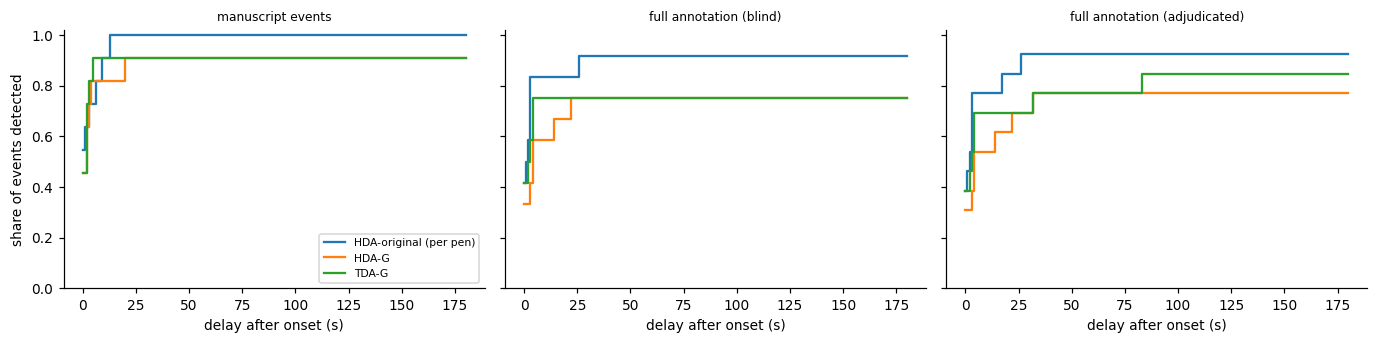

,reference,paper_name,n_events,recall_le0s,recall_le10s,recall_le30s,recall_le60s,recall_le120s,recall_any_delay
0,manuscript events,HDA-original (per pen),11,0.545,0.909,1.000,1.000,1.000,1.000
1,manuscript events,HDA-G,11,0.455,0.818,0.909,0.909,0.909,0.909
2,manuscript events,TDA-G,11,0.455,0.909,0.909,0.909,0.909,0.909
3,full annotation (blind),HDA-original (per pen),12,0.417,0.833,0.917,0.917,0.917,0.917
4,full annotation (blind),HDA-G,12,0.333,0.583,0.750,0.750,0.750,0.750
5,full annotation (blind),TDA-G,12,0.417,0.750,0.750,0.750,0.750,0.750
6,full annotation (adjudicated),HDA-original (per pen),13,0.385,0.769,0.923,0.923,0.923,0.923
7,full annotation (adjudicated),HDA-G,13,0.308,0.538,0.692,0.769,0.769,0.846
8,full annotation (adjudicated),TDA-G,13,0.385,0.692,0.692,0.769,0.846,0.923


In [47]:
LAT = None
if FULL_LITS:
    rp_t = [x for l in TARGET_LITTERS for x in LITTER_RP[l]]
    refs_lat = [("manuscript events", GT_ALL, EXCLUDE)] + [(f"full annotation ({r})", ev_.assign(pre_s=10.0), unc_) for r, (ev_, unc_) in REFS.items()]
    fig, axes = plt.subplots(1, len(refs_lat), figsize=(4.2 * len(refs_lat), 3.2), sharey=True)
    lat_rows = []
    for ax, (lab, gt_, ex_) in zip(axes, refs_lat):
        for name in ["HPA-orig, per pen", "HPA-v2 + sow-activity gate", "TPA-v2 + gate"]:
            al = TRAP_METHODS[name]; al = al[np.array([(r, p) in rp_t for r, p in zip(al.rec, al.pen)], dtype=bool)]
            _, g2 = match_alerts(al, gt_[gt_.litter.isin(TARGET_LITTERS)], exclude=ex_)
            xs = np.arange(0, 181)
            ax.step(xs, [float((g2.detected & (g2.latency_s <= x)).mean()) for x in xs], where="post", label=pname(name))
            lat_rows.append(dict(reference=lab, paper_name=pname(name), n_events=len(g2), **recall_within(g2, (0, 10, 30, 60, 120)),
                                 recall_any_delay=float(g2.detected.mean())))
        ax.set_title(lab, fontsize=8); ax.set_xlabel("delay after onset (s)"); ax.set_ylim(0, 1.02)
    axes[0].set_ylabel("share of events detected"); axes[0].legend(fontsize=7, loc="lower right")
    fig.tight_layout(); save_fig(fig, "F13_time_to_detection"); plt.show()
    LAT = pd.DataFrame(lat_rows); display(LAT.round(3)); save_table(LAT.round(4), "T26c_recall_by_delay")

### 8.7 Sensitivity to the expected total (N_Tot) — using the litter size counted on video (R1-5)
N_Tot built from the 10-min maximum, as in figure F9, can exceed the real litter size (13–17) because of false detections (20–26), which raises the 'missing' baseline and produces false alarms.
The litter size counted on video (range in §2.3) is used (a) as an upper bound of N_Tot (`max_total`) or (b) as a fixed value (`known_total`) to see how the results change.
Everything else is the TDA-G development setting. For B_f413, which was farrowing, a fixed value expects more piglets than there were, but alerts are raised only by **changes** in the missing level,
so a constant difference produces no alerts.

In [48]:
LSIZE = {r.pen: tuple(int(x) for x in r.reported_estimate.split("-")) for r in LITTER_EST.itertuples()}

def tda_g_with(per_litter_kw):
    h2 = {}
    for (rec, pen), v in CNT.items():
        h2[(rec, pen)] = hpa_v2(v["n"], FPS[rec], **HPA_DEFAULT, **per_litter_kw.get(LIT_OF.get((rec[0], pen)), {}))
    return alerts_union(alerts_hpa_v2(h2, gate=GATE_DEFAULT), AL_VT)

NTOT_VARIANTS = {
    "N_Tot = 10-min rolling max (development setting)": {},
    "N_Tot capped at the upper litter estimate": {l: dict(max_total=hi) for l, (lo, hi) in LSIZE.items()},
    "N_Tot fixed at the upper litter estimate": {l: dict(known_total=hi) for l, (lo, hi) in LSIZE.items()},
    "N_Tot fixed at the lower litter estimate": {l: dict(known_total=lo) for l, (lo, hi) in LSIZE.items()},
}
refs_kt = {"manuscript events": (GT_ALL, EXCLUDE)}
refs_kt.update({f"full annotation ({r})": (ev_.assign(pre_s=10.0), unc_) for r, (ev_, unc_) in REFS.items()})
rows = []
for vname, kw in NTOT_VARIANTS.items():
    al = tda_g_with(kw)
    for ref, (gt_, ex_) in refs_kt.items():
        df, _ = evaluate(al, gt_, scopes=("target",), control=False, exclude=ex_)
        rows.append(df.assign(variant=vname, reference=ref))
NTOT_SENS = pd.concat(rows)[["variant", "reference", "n_events", "n_alerts", "TP", "FN", "FP", "DUP", "recall", "recall_le30s",
                             "precision", "FA_per_pen_h"]]
display(NTOT_SENS.round(3)); save_table(NTOT_SENS.round(4), "T31_n_tot_sensitivity")

,variant,reference,n_events,n_alerts,TP,FN,FP,DUP,recall,recall_le30s,precision,FA_per_pen_h
0,N_Tot = 10-min rolling max (development setting),manuscript events,11,120,10,1,94,16,0.909,0.909,0.096,34.047
0,N_Tot = 10-min rolling max (development setting),full annotation (blind),12,120,9,3,89,18,0.750,0.750,0.092,32.236
0,N_Tot = 10-min rolling max (development setting),full annotation (adjudicated),13,120,12,1,52,41,0.923,0.692,0.188,18.835
0,N_Tot capped at the upper litter estimate,manuscript events,11,117,10,1,91,16,0.909,0.909,0.099,32.961
0,N_Tot capped at the upper litter estimate,full annotation (blind),12,117,9,3,87,17,0.750,0.750,0.094,31.512
0,N_Tot capped at the upper litter estimate,full annotation (adjudicated),13,117,11,2,51,40,0.846,0.692,0.177,18.473
0,N_Tot fixed at the upper litter estimate,manuscript events,11,117,10,1,91,16,0.909,0.909,0.099,32.961
0,N_Tot fixed at the upper litter estimate,full annotation (blind),12,117,9,3,87,17,0.750,0.750,0.094,31.512
0,N_Tot fixed at the upper litter estimate,full annotation (adjudicated),13,117,11,2,51,40,0.846,0.692,0.177,18.473
0,N_Tot fixed at the lower litter estimate,manuscript events,11,112,10,1,86,16,0.909,0.909,0.104,31.150


,variant,reference,n_events,n_alerts,TP,FN,FP,DUP,recall,recall_le30s,precision,FA_per_pen_h
0,N_Tot = 10-min rolling max (development setting),manuscript events,11,120,10,1,94,16,0.9091,0.9091,0.0962,34.0474
0,N_Tot = 10-min rolling max (development setting),full annotation (blind),12,120,9,3,89,18,0.7500,0.7500,0.0918,32.2364
0,N_Tot = 10-min rolling max (development setting),full annotation (adjudicated),13,120,12,1,52,41,0.9231,0.6923,0.1875,18.8348
0,N_Tot capped at the upper litter estimate,manuscript events,11,117,10,1,91,16,0.9091,0.9091,0.0990,32.9608
0,N_Tot capped at the upper litter estimate,full annotation (blind),12,117,9,3,87,17,0.7500,0.7500,0.0938,31.5120
0,N_Tot capped at the upper litter estimate,full annotation (adjudicated),13,117,11,2,51,40,0.8462,0.6923,0.1774,18.4726
0,N_Tot fixed at the upper litter estimate,manuscript events,11,117,10,1,91,16,0.9091,0.9091,0.0990,32.9608
0,N_Tot fixed at the upper litter estimate,full annotation (blind),12,117,9,3,87,17,0.7500,0.7500,0.0938,31.5120
0,N_Tot fixed at the upper litter estimate,full annotation (adjudicated),13,117,11,2,51,40,0.8462,0.6923,0.1774,18.4726
0,N_Tot fixed at the lower litter estimate,manuscript events,11,112,10,1,86,16,0.9091,0.9091,0.1042,31.1498


## 9. Separating threshold selection from testing: leave-one-litter-out cross-validation (LOLO-CV) (R1-3, R1-7)

- Folds: one **target-population litter (A-R, B-L)** is the test litter and the thresholds are chosen **on the continuous recordings of the other litter only** (§2.6).
  With two target litters this is **in effect a 2-fold** cross-validation (the thresholds of each fold are chosen on the other litter alone), hence the wide confidence intervals.
  A 3-litter cross-validation including B-R, a litter past the high-risk period, is reported as a sensitivity analysis (the B-R fold has no events, so only its false-alarm rate is meaningful).
- Search space for hidden trapping (TPA): $d$ ∈ {2, 3, 5, 8, 12} s, $t$ ∈ {2, 3, 5, 10} s, $s_{min}$ ∈ {1, 2}, sow-activity gate $\theta_a$ ∈ {none, 0.05, 0.08, 0.12},
  detection conf ∈ {0.25, 0.40}, with or without the visible-trapping channel → 640 combinations. Selection criterion: maximum event-level F1 on the training litters (fewest false alarms per hour on ties).
- Search space for suspected crushing (CDA-v2): $f$ ∈ {3, 5, 10, 20, 30} s, $m$ ∈ {0.1, 0.25, 0.5, 1.0} × diagonal, gate ∈ {none, HPA, HPA+activity}, with or without the crushed-class check.
- Detectors: the four of §3.2 (provided YOLOv8s — evaluation frames in its training; leakage-free YOLOv8s and YOLOv5s; the leakage-free detector chosen by the pre-specified rule).
  The leakage-free detectors give the result the reviewers asked for — 'test-event frames used neither for detector training nor for threshold selection' — and the **detector chosen by the pre-specified rule is the main result**.

In [49]:
def eval_lits(alerts, gt, lits, exclude=EXCLUDE):
    rp = [x for lit in lits for x in LITTER_RP[lit]]
    al = alerts[np.array([(r, p) in rp for r, p in zip(alerts.rec, alerts.pen)], dtype=bool)]   # bool array: an empty list would select columns
    a2, g2 = match_alerts(al, gt[gt.litter.isin(lits)], exclude=exclude)
    m = event_metrics(a2, g2, sum(PEN_HOURS[l] for l in lits))
    return m, a2, g2

def hpa_alert_grid(tag=""):
    out = {}
    for conf in [0.25, 0.4]:
        cnt = count_runs(conf, tag)
        al_vt = alerts_vt(cnt)
        for d in [2, 3, 5, 8, 12]:
            for t in [2, 3, 5, 10]:
                for s in [1, 2]:
                    h2 = hpa_v2_runs(cnt, d_s=d, t_s=t, step_min=s)
                    for g in [None, 0.05, 0.08, 0.12]:
                        al = alerts_hpa_v2(h2, gate=g)
                        out[(conf, d, t, s, g, False)] = al
                        out[(conf, d, t, s, g, True)] = alerts_union(al, al_vt)
    return out

KEYS = ["conf", "d_s", "t_s", "step_min", "gate", "with_visible"]

def run_cv(grid, gt, keys=None, lits=None, exclude=EXCLUDE):
    """leave-one-litter-out over `lits` (default: target litters; with the 2 target litters this is a 2-fold CV)"""
    keys = keys or KEYS
    lits = lits or TARGET_LITTERS
    folds, pooled = [], []
    for test in lits:
        train = [l for l in lits if l != test]
        scores = []
        for key, al in grid.items():
            m, _, _ = eval_lits(al, gt, train, exclude)
            scores.append((np.nan_to_num(m["F1"]), -m["FA_per_pen_h"], key))
        scores.sort(key=lambda x: (x[0], x[1]), reverse=True)
        best = scores[0][2]
        mt, a2, g2 = eval_lits(grid[best], gt, [test], exclude)
        mtr, _, _ = eval_lits(grid[best], gt, train, exclude)
        folds.append(dict(test_litter=test, **dict(zip(keys, best)), train_F1=mtr["F1"], train_FA_h=mtr["FA_per_pen_h"],
                          **{f"test_{k}": v for k, v in mt.items()}))
        pooled.append((a2, g2))
    a = pd.concat([x[0] for x in pooled]); g = pd.concat([x[1] for x in pooled])
    tp = int((a.status == "TP").sum()); fp = int((a.status == "FP").sum()); fn = int((~g.detected).sum())
    hours = sum(PEN_HOURS[l] for l in lits)
    summ = dict(TP=tp, FP=fp, FN=fn, DUP=int((a.status == "DUP").sum()),
                recall=tp / (tp + fn), recall_95CI=wilson(tp, tp + fn),
                precision=tp / (tp + fp) if tp + fp else np.nan, precision_95CI=wilson(tp, tp + fp),
                FA_per_pen_h=fp / hours, latency_median_s=float(g.latency_s.median()))
    ep = episode_recall(g)
    summ.update(ep, recall_episode_95CI=wilson(ep["episodes_detected"], ep["n_episodes"]) if ep["n_episodes"] == ep["n_episodes"] else (np.nan, np.nan))
    summ.update(recall_within(g))
    return pd.DataFrame(folds), summ

CV_RES = {}
CV_RES_ALL = {}
for det_name, tag in DETECTORS.items():
    grid = cached(f"cv_hpa_grid{tag}", lambda: hpa_alert_grid(tag))
    folds, summ = run_cv(grid, GT_ALL, lits=TARGET_LITTERS)
    CV_RES[det_name] = (folds, summ)
    CV_RES_ALL[det_name] = run_cv(grid, GT_ALL, lits=ALL_LITTERS)
    display(Markdown(tr(f"**{det_name}** — fold 별 선택 임계값과 테스트 성능", f"**{det_name}** — thresholds selected per fold and test performance")))
    display(folds.round(3))
    display(pd.DataFrame([summ]).round(3))
CVT = pd.concat([f.assign(detector=k) for k, (f, s) in CV_RES.items()])
save_table(CVT.round(4), "T13_lolo_cv_trapping")
save_table(pd.DataFrame([dict(detector=k, **s) for k, (f, s) in CV_RES.items()]), "T13b_lolo_cv_trapping_pooled")
display(Markdown(tr("**민감도 분석 — 전체 3개 복으로 한 교차검증(B-R 포함)**", "**Sensitivity analysis — cross-validation over all 3 litters (including B-R)**")))
CVA = pd.DataFrame([dict(detector=k, **s) for k, (f, s) in CV_RES_ALL.items()])
display(CVA.round(3)); save_table(CVA, "T13c_lolo_cv_trapping_all_litters")

**provided YOLOv8s (training incl. evaluation frames)** — thresholds selected per fold and test performance

,test_litter,conf,d_s,t_s,step_min,gate,with_visible,train_F1,train_FA_h,test_TP,test_FP,test_FN,test_DUP,test_precision,test_recall,test_F1,test_FA_per_pen_h,test_dup_rate,test_latency_median_s,test_latency_max_s
0,A-R,0.25,12,2,1,0.12,False,0.857,1.810,0,13,5,0,0.0,0.000,NaN,7.849,NaN,NaN,NaN
1,B-L,0.40,8,5,1,0.12,False,0.258,13.284,4,4,2,2,0.5,0.667,0.571,3.621,0.333,7.733,56.059


,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,4,17,7,2,0.364,"(0.15166223614131383, 0.6462032231083628)",0.19,"(0.07667440615177301, 0.40000986539273287)",6.158,7.733,8,4,0.5,"(0.21521252682444186, 0.7847874731755582)",0.273,0.273,0.364


**YOLOv8s-416 leakage-free** — thresholds selected per fold and test performance

,test_litter,conf,d_s,t_s,step_min,gate,with_visible,train_F1,train_FA_h,test_TP,test_FP,test_FN,test_DUP,test_precision,test_recall,test_F1,test_FA_per_pen_h,test_dup_rate,test_latency_median_s,test_latency_max_s
0,A-R,0.4,12,3,2,0.12,False,0.769,1.810,3,11,2,0,0.214,0.600,0.316,6.642,0.0,13.293,24.385
1,B-L,0.4,12,2,2,0.12,False,0.353,5.434,4,2,2,1,0.667,0.667,0.667,1.810,0.2,8.558,9.547


,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,7,13,4,1,0.636,"(0.35379677689163724, 0.8483377638586862)",0.35,"(0.18118954786794464, 0.5671494897805354)",4.709,9.547,8,6,0.75,"(0.40926987910258916, 0.9285223111419724)",0.364,0.636,0.636


... (8 outputs left out)

,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,5,22,6,0,0.455,"(0.21270957543988045, 0.7199122443100118)",0.185,"(0.0818058657428532, 0.36699056505191746)",7.969,8.676,8,5,0.625,"(0.30573785458380187, 0.863158240538479)",0.273,0.455,0.455


**Sensitivity analysis — cross-validation over all 3 litters (including B-R)**

,detector,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,provided YOLOv8s (training incl. evaluation fr...,4,31,7,2,0.364,"(0.15166223614131383, 0.6462032231083628)",0.114,"(0.0453510585448975, 0.2595179478812023)",8.020,7.733,8,4,0.500,"(0.21521252682444186, 0.7847874731755582)",0.273,0.273,0.364
1,YOLOv8s-416 leakage-free,7,16,4,1,0.636,"(0.35379677689163724, 0.8483377638586862)",0.304,"(0.15603828020972454, 0.5086612906057261)",4.139,9.547,8,6,0.750,"(0.40926987910258916, 0.9285223111419724)",0.364,0.636,0.636
2,YOLOv5s-416 leakage-free,3,20,8,0,0.273,"(0.09745880573921467, 0.5656502930102463)",0.130,"(0.04537576514344702, 0.32127897973018194)",5.174,18.328,8,3,0.375,"(0.13684175946152105, 0.6942621454161981)",0.000,0.273,0.273
3,selected leakage-free (pre-specified rule),7,21,4,2,0.636,"(0.35379677689163724, 0.8483377638586862)",0.250,"(0.12676334942200781, 0.433560252407046)",5.433,9.243,8,6,0.750,"(0.40926987910258916, 0.9285223111419724)",0.364,0.545,0.636
4,"YOLOv5s-416 [9] recipe, leakage-free",5,23,6,0,0.455,"(0.21270957543988045, 0.7199122443100118)",0.179,"(0.0787838582943011, 0.355917915485911)",5.950,8.676,8,5,0.625,"(0.30573785458380187, 0.863158240538479)",0.273,0.455,0.455


,detector,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,provided YOLOv8s (training incl. evaluation fr...,4,31,7,2,0.363636,"(0.15166223614131383, 0.6462032231083628)",0.114286,"(0.0453510585448975, 0.2595179478812023)",8.019566,7.733078,8,4,0.500,"(0.21521252682444186, 0.7847874731755582)",0.272727,0.272727,0.363636
1,YOLOv8s-416 leakage-free,7,16,4,1,0.636364,"(0.35379677689163724, 0.8483377638586862)",0.304348,"(0.15603828020972454, 0.5086612906057261)",4.139131,9.546863,8,6,0.750,"(0.40926987910258916, 0.9285223111419724)",0.363636,0.636364,0.636364
2,YOLOv5s-416 leakage-free,3,20,8,0,0.272727,"(0.09745880573921467, 0.5656502930102463)",0.130435,"(0.04537576514344702, 0.32127897973018194)",5.173914,18.328260,8,3,0.375,"(0.13684175946152105, 0.6942621454161981)",0.000000,0.272727,0.272727
3,selected leakage-free (pre-specified rule),7,21,4,2,0.636364,"(0.35379677689163724, 0.8483377638586862)",0.250000,"(0.12676334942200781, 0.433560252407046)",5.432609,9.242970,8,6,0.750,"(0.40926987910258916, 0.9285223111419724)",0.363636,0.545455,0.636364
4,"YOLOv5s-416 [9] recipe, leakage-free",5,23,6,0,0.454545,"(0.21270957543988045, 0.7199122443100118)",0.178571,"(0.0787838582943011, 0.355917915485911)",5.950001,8.675699,8,5,0.625,"(0.30573785458380187, 0.863158240538479)",0.272727,0.454545,0.454545


### 9.1 Cross-validation against the full annotation
The same leave-one-litter-out cross-validation with the full annotation of §8.6 as the reference (only when the annotation of both target litters is complete).
Threshold selection (maximum F1, fewest false alarms per hour on ties) also uses the full annotation, and alerts around 'uncertain' marks are not counted.

In [50]:
CV_FULL = {}
if FULL_LITS and set(FULL_LITS) == set(TARGET_LITTERS):
    for det_name, tag in DETECTORS.items():
        grid = cached(f"cv_hpa_grid{tag}", lambda: hpa_alert_grid(tag))
        for ref, (ev_, unc_) in REFS.items():
            CV_FULL[(ref, det_name)] = run_cv(grid, ev_.assign(pre_s=10.0), lits=TARGET_LITTERS, exclude=unc_)
        del grid
    CVF = pd.DataFrame([dict(reference=r, detector=k, **s) for (r, k), (f, s) in CV_FULL.items()])
    display(pd.concat([f.assign(reference=r, detector=k) for (r, k), (f, s) in CV_FULL.items()]).round(3))
    display(CVF.round(3)); save_table(CVF, "T28_lolo_cv_trapping_full_annotation")
else:
    print(tr("두 목표 집단 복의 전체 주석이 끝나면 계산한다.", "computed once the full annotation of both target litters is finished."))

,test_litter,conf,d_s,t_s,step_min,gate,with_visible,train_F1,train_FA_h,test_TP,test_FP,test_FN,test_DUP,test_precision,test_recall,test_F1,test_FA_per_pen_h,test_dup_rate,test_latency_median_s,test_latency_max_s,reference,detector
0,A-R,0.25,8,2,1,0.08,False,0.889,0.905,4,24,4,0,0.143,0.500,0.222,14.491,0.000,22.354,36.833,blind,provided YOLOv8s (training incl. evaluation fr...
1,B-L,0.40,12,5,1,0.08,False,0.387,10.265,1,4,3,3,0.200,0.250,0.222,3.621,0.750,2.944,2.944,blind,provided YOLOv8s (training incl. evaluation fr...
0,A-R,0.25,8,2,1,0.08,False,0.889,0.905,5,16,4,2,0.238,0.556,0.333,9.661,0.286,22.458,36.833,adjudicated,provided YOLOv8s (training incl. evaluation fr...
1,B-L,0.25,12,3,2,NaN,False,0.545,9.057,2,17,2,2,0.105,0.500,0.174,15.389,0.500,21.088,39.632,adjudicated,provided YOLOv8s (training incl. evaluation fr...
0,A-R,0.25,12,2,2,0.12,False,0.750,0.905,4,13,4,0,0.235,0.500,0.320,7.849,0.000,17.640,26.279,blind,YOLOv8s-416 leakage-free
1,B-L,0.25,12,3,2,0.08,False,0.345,9.661,3,1,1,1,0.750,0.750,0.750,0.905,0.250,2.309,11.496,blind,YOLOv8s-416 leakage-free
0,A-R,0.25,12,2,2,0.08,False,0.750,0.905,6,13,3,3,0.316,0.667,0.429,7.849,0.333,17.640,40.136,adjudicated,YOLOv8s-416 leakage-free
1,B-L,0.40,3,10,2,0.12,True,0.609,4.227,3,6,1,1,0.333,0.750,0.462,5.431,0.250,8.350,76.755,adjudicated,YOLOv8s-416 leakage-free
0,A-R,0.25,8,2,2,0.08,False,0.750,0.905,4,15,4,2,0.211,0.500,0.296,9.057,0.333,17.166,24.000,blind,YOLOv5s-416 leakage-free
1,B-L,0.40,3,10,2,0.08,True,0.387,10.265,3,5,1,5,0.375,0.750,0.500,4.526,0.625,5.439,13.064,blind,YOLOv5s-416 leakage-free


,reference,detector,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,blind,provided YOLOv8s (training incl. evaluation fr...,5,28,7,3,0.417,"(0.19325746190524656, 0.6804926643446272)",0.152,"(0.06650359257960956, 0.30920213138460484)",10.142,22.250,9,5,0.556,"(0.2666473457440297, 0.811224570528086)",0.083,0.333,0.417
1,adjudicated,provided YOLOv8s (training incl. evaluation fr...,7,33,6,4,0.538,"(0.2914343243183205, 0.7679424569851186)",0.175,"(0.08745302996883066, 0.3195029205439244)",11.953,22.458,10,7,0.700,"(0.39677321997956516, 0.892210712513788)",0.077,0.308,0.538
2,blind,YOLOv8s-416 leakage-free,7,14,5,1,0.583,"(0.3195073356553728, 0.8067425380947535)",0.333,"(0.17194536432683688, 0.5462692434278971)",5.071,11.496,9,5,0.556,"(0.2666473457440297, 0.811224570528086)",0.250,0.583,0.583
3,adjudicated,YOLOv8s-416 leakage-free,9,19,4,4,0.692,"(0.4236888781333764, 0.8731950283838191)",0.321,"(0.1793304754342074, 0.5066149544436882)",6.882,14.792,10,7,0.700,"(0.39677321997956516, 0.892210712513788)",0.308,0.538,0.615
4,blind,YOLOv5s-416 leakage-free,7,20,5,7,0.583,"(0.3195073356553728, 0.8067425380947535)",0.259,"(0.13170208422866778, 0.4467893040261568)",7.244,10.375,9,5,0.556,"(0.2666473457440297, 0.811224570528086)",0.250,0.583,0.583
5,adjudicated,YOLOv5s-416 leakage-free,8,16,5,3,0.615,"(0.35522480972268555, 0.8229055341876319)",0.333,"(0.17971978688379642, 0.5329404050591954)",5.795,23.979,10,6,0.600,"(0.3126695474501864, 0.8318224187964902)",0.154,0.462,0.538
6,blind,selected leakage-free (pre-specified rule),5,17,7,4,0.417,"(0.19325746190524656, 0.6804926643446272)",0.227,"(0.10122890794820358, 0.4344035606295935)",6.158,7.375,9,4,0.444,"(0.188775429471914, 0.7333526542559703)",0.250,0.417,0.417
7,adjudicated,selected leakage-free (pre-specified rule),9,22,4,10,0.692,"(0.4236888781333764, 0.8731950283838191)",0.290,"(0.1609562071843287, 0.4659265995754067)",7.969,7.375,10,7,0.700,"(0.39677321997956516, 0.892210712513788)",0.385,0.615,0.615
8,blind,"YOLOv5s-416 [9] recipe, leakage-free",7,16,5,2,0.583,"(0.3195073356553728, 0.8067425380947535)",0.304,"(0.15603828020972454, 0.5086612906057261)",5.795,9.917,9,6,0.667,"(0.35419734749908977, 0.879418401317257)",0.333,0.583,0.583
9,adjudicated,"YOLOv5s-416 [9] recipe, leakage-free",8,18,5,6,0.615,"(0.35522480972268555, 0.8229055341876319)",0.308,"(0.16501120939792674, 0.49988611514231246)",6.520,11.632,10,7,0.700,"(0.39677321997956516, 0.892210712513788)",0.308,0.462,0.615


In [51]:
GATESETS = {}
for tag in DETECTORS.values():
    _h2 = hpa_v2_runs(count_runs(0.25, tag), **HPA_DEFAULT)
    GATESETS[tag] = (alerts_hpa_v2(_h2), alerts_hpa_v2(_h2, gate=GATE_DEFAULT))

def cda_grid(trk, tag):
    g_h, g_hg = GATESETS[tag]
    out = {}
    for f_s in [3, 5, 10, 20, 30]:
        for m_rel in [0.1, 0.25, 0.5, 1.0]:
            for gname, gdf in [("none", None), ("HPA", g_h), ("HPA+activity", g_hg)]:
                for rc in [False, True]:
                    out[(f_s, m_rel, gname, rc)] = alerts_cda_v2(trk, tracker="sort_1s", f_s=f_s, m_rel=m_rel,
                                                                 gate_alerts_df=gdf, require_crushed=rc)
    return out

CDA_KEYS = ["f_s", "m_rel", "gating", "require_crushed_class"]
CV_CDA = {}
for det_name, tag in DETECTORS.items():
    trk = get_trk(tag)
    grid = cached(f"cv_cda_grid{tag}", lambda: cda_grid(trk, tag))
    folds, summ = run_cv(grid, GT_CR, keys=CDA_KEYS, lits=TARGET_LITTERS)
    CV_CDA[det_name] = (folds, summ)
    display(Markdown(tr(f"**{det_name}** — 압사 의심 경보(CDA-v2) fold 별 선택과 테스트", f"**{det_name}** — suspected-crushing alerts (CDA-v2): selection per fold and test")))
    display(folds.round(3)); display(pd.DataFrame([summ]).round(3))
save_table(pd.concat([f.assign(detector=k) for k, (f, s) in CV_CDA.items()]).round(4), "T14_lolo_cv_crushing")
display(Markdown(tr("""
**해석 지침**: 사건이 두 복(8개 에피소드)에만 있어 fold 당 테스트 사건이 5–6개뿐이다. 재현율·정밀도의 95% 신뢰구간(Wilson)이 매우 넓으므로,
이 값들은 '일반화 성능'이 아니라 **소규모 예비 평가(proof-of-concept)** 로만 보고해야 한다. 원 검출기 결과는 검출기 학습 누수가 남아 있으므로
사전 규칙으로 고른 누수 없는 검출기 결과를 주 결과로, 나머지는 참고로 제시하는 것을 권한다.
""", """
**Guidance for interpretation**: the events occur in only two litters (8 episodes), so each fold has only 5–6 test events. The 95% confidence intervals (Wilson) of recall and precision are very wide, so
these values should be reported only as a **small preliminary evaluation (proof of concept)**, not as 'generalisation performance'. The results with the original detector still contain the detector-training leakage,
so presenting the leakage-free detector chosen by the pre-specified rule as the main result, and the others for reference, is recommended.
""")))

**provided YOLOv8s (training incl. evaluation frames)** — suspected-crushing alerts (CDA-v2): selection per fold and test

,test_litter,f_s,m_rel,gating,require_crushed_class,train_F1,train_FA_h,test_TP,test_FP,test_FN,test_DUP,test_precision,test_recall,test_F1,test_FA_per_pen_h,test_dup_rate,test_latency_median_s,test_latency_max_s
0,A-R,10,0.1,HPA+activity,True,0.500,0.000,0,4,2,0,0.000,0.000,NaN,2.415,NaN,NaN,NaN
1,B-L,20,0.5,HPA+activity,True,0.444,3.019,1,6,2,1,0.143,0.333,0.2,5.431,0.5,18.328,18.328


,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,1,10,4,1,0.2,"(0.03622316096978745, 0.6244717358814613)",0.091,"(0.01623175226282597, 0.3773646254862038)",3.622,18.328,5,1,0.2,"(0.03622316096978745, 0.6244717358814613)",0.0,0.2,0.2


**YOLOv8s-416 leakage-free** — suspected-crushing alerts (CDA-v2): selection per fold and test

,test_litter,f_s,m_rel,gating,require_crushed_class,train_F1,train_FA_h,test_TP,test_FP,test_FN,test_DUP,test_precision,test_recall,test_F1,test_FA_per_pen_h,test_dup_rate,test_latency_median_s,test_latency_max_s
0,A-R,5,0.1,HPA+activity,False,0.273,14.484,2,63,0,4,0.031,1.0,0.06,38.04,0.667,-24.675,4.233
1,B-L,20,0.1,HPA+activity,True,0.667,0.000,0,0,3,0,NaN,0.0,NaN,0.00,NaN,NaN,NaN


,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,2,63,3,4,0.4,"(0.1176182311592533, 0.769280067791163)",0.031,"(0.008478819400945352, 0.10542905025926008)",22.819,-24.675,5,2,0.4,"(0.1176182311592533, 0.769280067791163)",0.4,0.4,0.4


... (6 outputs left out)

**YOLOv5s-416 [9] recipe, leakage-free** — suspected-crushing alerts (CDA-v2): selection per fold and test

,test_litter,f_s,m_rel,gating,require_crushed_class,train_F1,train_FA_h,test_TP,test_FP,test_FN,test_DUP,test_precision,test_recall,test_F1,test_FA_per_pen_h,test_dup_rate,test_latency_median_s,test_latency_max_s
0,A-R,3,0.10,none,True,0.500,0.0,0,1,2,0,0.0,0.0,NaN,0.604,NaN,NaN,NaN
1,B-L,10,0.25,none,True,0.667,0.0,0,4,3,0,0.0,0.0,NaN,3.621,NaN,NaN,NaN


,TP,FP,FN,DUP,recall,recall_95CI,precision,precision_95CI,FA_per_pen_h,latency_median_s,n_episodes,episodes_detected,recall_episode,recall_episode_95CI,recall_le10s,recall_le30s,recall_le60s
0,0,5,5,0,0.0,"(0.0, 0.43449149475208104)",0.0,"(0.0, 0.43449149475208104)",1.811,NaN,5,0,0.0,"(0.0, 0.43449149475208104)",0.0,0.0,0.0



**Guidance for interpretation**: the events occur in only two litters (8 episodes), so each fold has only 5–6 test events. The 95% confidence intervals (Wilson) of recall and precision are very wide, so
these values should be reported only as a **small preliminary evaluation (proof of concept)**, not as 'generalisation performance'. The results with the original detector still contain the detector-training leakage,
so presenting the leakage-free detector chosen by the pre-specified rule as the main result, and the others for reference, is recommended.


## 10. Sensitivity analysis (R1-7)
### 10.1 Original algorithms (manuscript conditions: whole frame, cold start per clip) — $d$, $t$, conf, $m$, $f$, IoU, $t_\text{expire}$
One parameter at a time; the others at the manuscript values ($t$ = 300, $d$ = 150 frames, conf 0.25, $m$ = 200 px, $f$ = 300 frames, IoU 0.3, $t_\text{expire}$ = 1).

,algorithm,parameter,value,MAE,predictions,median_latency_s
0,HPA (orig),d,30.00,2.000000,"[2, 5, 3, 2, 3, 6]",5.505500
1,HPA (orig),d,60.00,2.000000,"[2, 5, 3, 2, 3, 6]",5.505500
2,HPA (orig),d,90.00,2.000000,"[2, 5, 3, 2, 3, 6]",5.505500
3,HPA (orig),d,150.00,1.833333,"[1, 4, 3, 2, 3, 5]",6.732167
4,HPA (orig),d,210.00,1.833333,"[1, 4, 3, 2, 3, 5]",6.932367
5,HPA (orig),d,300.00,1.500000,"[1, 3, 3, 2, 2, 5]",11.236667
6,HPA (orig),t,60.00,5.833333,"[5, 9, 9, 9, 6, 10]",6.610167
7,HPA (orig),t,150.00,2.333333,"[1, 5, 5, 5, 3, 8]",2.806367
8,HPA (orig),t,300.00,1.833333,"[1, 4, 3, 2, 3, 5]",6.732167
9,HPA (orig),t,450.00,1.666667,"[2, 4, 1, 2, 1, 3]",13.513500


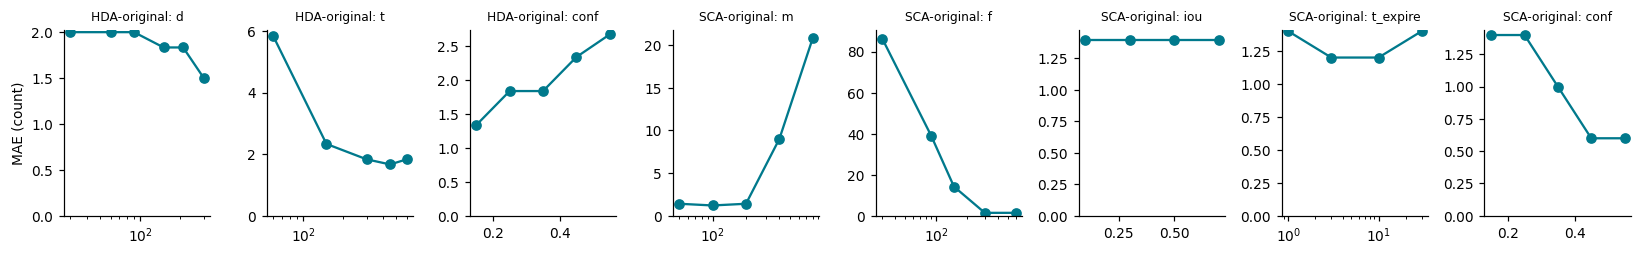

In [52]:
def sens_original():
    rows = []
    base = dict(conf=0.25, t=300, d=150)
    for par, vals in dict(d=[30, 60, 90, 150, 210, 300], t=[60, 150, 300, 450, 600],
                          conf=[0.15, 0.25, 0.35, 0.45, 0.55]).items():
        for v in vals:
            kw = {**base, par: v}
            T = pd.DataFrame([reproduce_trap_clip(c, conf=kw["conf"], t=kw["t"], d=kw["d"]) for c in PAPER_T["clip"]])
            rows.append(dict(algorithm="HPA (orig)", parameter=par, value=v, MAE=mae(PAPER_T.hidden_gt, T.hpa),
                             predictions=T.hpa.tolist(), median_latency_s=T.latency.median()))
    cbase = dict(conf=0.25, f=300, m=200.0, iou=0.3, max_age=1)
    for par, vals in dict(m=[50, 100, 200, 400, 800], f=[30, 90, 150, 300, 600], iou=[0.1, 0.3, 0.5, 0.7],
                          max_age=[1, 3, 10, 30], conf=[0.15, 0.25, 0.35, 0.45, 0.55]).items():
        for v in vals:
            kw = {**cbase, par: v}
            C = pd.DataFrame([reproduce_crush_clip(c, conf=kw["conf"], f=kw["f"], m=kw["m"], iou=kw["iou"], max_age=kw["max_age"])
                              for c in PAPER_C["clip"]])
            rows.append(dict(algorithm="CDA (orig)", parameter=("t_expire" if par == "max_age" else par), value=v,
                             MAE=mae(PAPER_C.crushed_gt, C.cda), predictions=C.cda.tolist()))
    return pd.DataFrame(rows)

SENS_O = cached("sens_original", sens_original)
display(SENS_O); save_table(SENS_O, "T15_sensitivity_original_algorithm")
fig, axes = plt.subplots(1, 8, figsize=(15, 2.4), sharey=False)
for ax, ((alg, par), g) in zip(axes, SENS_O.groupby(["algorithm", "parameter"], sort=False)):
    ax.plot(g.value, g.MAE, "o-", color="#00798c"); ax.set_title(f"{pname(alg)}: {par}", fontsize=8); ax.set_ylim(0, None)
    ax.set_xscale("log" if par in ("m", "f", "t_expire", "d", "t") else "linear")
axes[0].set_ylabel("MAE (count)")
fig.tight_layout(); save_fig(fig, "F7_sensitivity_original"); plt.show()

### 10.2 Revised algorithms (continuous recordings, target litters pooled, main detector) — HPA-v2 (+ gate) and CDA-v2

,algorithm,parameter,value,recall,precision,F1,FA_per_pen_h,latency_median_s
0,HPA-v2 + gate,d_s,1.000,0.909,0.069,0.128,48.898,-2.319
1,HPA-v2 + gate,d_s,2.000,0.909,0.079,0.146,42.016,-1.316
2,HPA-v2 + gate,d_s,3.000,0.909,0.092,0.167,35.858,-0.314
3,HPA-v2 + gate,d_s,5.000,0.909,0.132,0.230,23.906,0.396
4,HPA-v2 + gate,d_s,8.000,0.818,0.155,0.261,17.748,6.882
5,HPA-v2 + gate,d_s,12.000,0.727,0.195,0.308,11.953,18.121
6,HPA-v2 + gate,d_s,20.000,0.364,0.154,0.216,7.969,13.829
7,HPA-v2 + gate,d_s,30.000,0.455,0.238,0.312,5.795,27.392
8,HPA-v2 + gate,t_s,1.000,0.818,0.161,0.269,17.024,0.835
9,HPA-v2 + gate,t_s,2.000,0.818,0.141,0.240,19.921,3.022


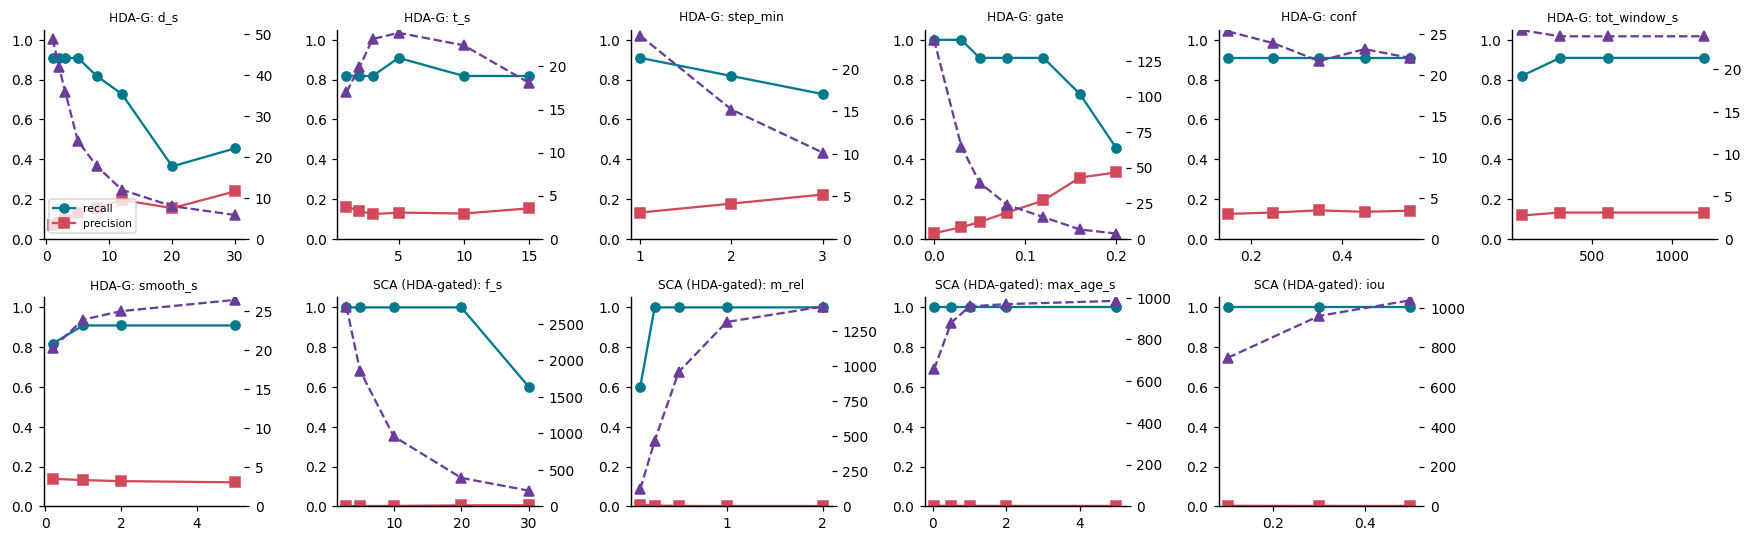

In [53]:
def sens_revised():
    rows = []
    base = dict(conf=0.25, d_s=5.0, t_s=5.0, step_min=1, gate=GATE_DEFAULT, tot_window_s=600.0, smooth_s=1.0)
    grid = dict(d_s=[1, 2, 3, 5, 8, 12, 20, 30], t_s=[1, 2, 3, 5, 10, 15], step_min=[1, 2, 3],
                gate=[0.0, 0.03, 0.05, 0.08, 0.12, 0.16, 0.2], conf=[0.15, 0.25, 0.35, 0.45, 0.55],
                tot_window_s=[60, 300, 600, 1200], smooth_s=[0.2, 1.0, 2.0, 5.0])
    cnt_cache = {}
    for par, vals in grid.items():
        for v in vals:
            kw = {**base, par: v}
            if kw["conf"] not in cnt_cache:
                cnt_cache[kw["conf"]] = count_runs(kw["conf"], MAIN_TAG)
            h2 = hpa_v2_runs(cnt_cache[kw["conf"]], d_s=kw["d_s"], t_s=kw["t_s"], step_min=kw["step_min"],
                             tot_window_s=kw["tot_window_s"], smooth_s=kw["smooth_s"])
            al = alerts_hpa_v2(h2, gate=kw["gate"] if kw["gate"] > 0 else None)
            m, _, _ = eval_lits(al, GT_ALL, TARGET_LITTERS)
            rows.append(dict(algorithm="HPA-v2 + gate", parameter=par, value=v, **{k: m[k] for k in
                             ["recall", "precision", "F1", "FA_per_pen_h", "latency_median_s"]}))
    # CDA-v2 (HPA-gated): thresholds from the track summary, tracker settings by re-tracking
    for par, vals in dict(f_s=[3, 5, 10, 20, 30], m_rel=[0.1, 0.25, 0.5, 1.0, 2.0]).items():
        for v in vals:
            kw = dict(f_s=10, m_rel=0.5); kw[par] = v
            al = alerts_cda_v2(TRK, gate_alerts_df=AL_H2, **kw)
            m, _, _ = eval_lits(al, GT_CR, TARGET_LITTERS)
            rows.append(dict(algorithm="CDA-v2 (HPA-gated)", parameter=par, value=v, **{k: m[k] for k in
                             ["recall", "precision", "F1", "FA_per_pen_h", "latency_median_s"]}))
    for par, vals in dict(max_age_s=[1 / 30, 0.5, 1.0, 2.0, 5.0], iou=[0.1, 0.3, 0.5]).items():
        for v in vals:
            trk = track_all(tag=MAIN_TAG, trackers=("sort_1s",), iou=(v if par == "iou" else None),
                            max_age_s=(v if par == "max_age_s" else None))
            al = alerts_cda_v2(trk, gate_alerts_df=AL_H2)
            m, _, _ = eval_lits(al, GT_CR, TARGET_LITTERS)
            rows.append(dict(algorithm="CDA-v2 (HPA-gated)", parameter=par, value=v, **{k: m[k] for k in
                             ["recall", "precision", "F1", "FA_per_pen_h", "latency_median_s"]}))
    return pd.DataFrame(rows)

SENS_R = cached(f"sens_revised{MAIN_TAG}_target", sens_revised)
display(SENS_R.round(3)); save_table(SENS_R.round(4), "T16_sensitivity_revised_algorithm")
groups = list(SENS_R.groupby(["algorithm", "parameter"], sort=False))
fig, axes = plt.subplots(2, int(np.ceil(len(groups) / 2)), figsize=(16, 5))
for ax, ((alg, par), g) in zip(axes.ravel(), groups):
    ax.plot(g.value, g.recall, "o-", label="recall", color="#00798c")
    ax.plot(g.value, g.precision, "s-", label="precision", color="#d1495b")
    ax2 = ax.twinx(); ax2.plot(g.value, g.FA_per_pen_h, "^--", color="#6a3d9a", label="FA / pen-h"); ax2.set_ylim(0, None)
    ax.set_ylim(0, 1.05); ax.set_title(f"{pname(alg)}: {par}", fontsize=8)
for ax in axes.ravel()[len(groups):]:
    ax.axis("off")
axes.ravel()[0].legend(fontsize=7, loc="lower left")
fig.tight_layout(); save_fig(fig, "F8_sensitivity_revised"); plt.show()

## 11. Checking the assumption of a constant total piglet count per litter (R1-5)
The original HPA uses the **running maximum** of the whole-frame detection count as the total count. Below, the number of visible piglets per pen (1-s median, every 5 s) is plotted against clock time.
- In A-R, at the start of the recording on 07-07 at 16:49, **a person is handling piglets inside the pen** → farrowing management was under way. The manuscript describes the recordings as '24 h from the start of farrowing',
  so the A-R events (07-07 19:26 – 07-08 00:48) may have occurred during or just after farrowing. The birth time of the last piglet and the management interventions should be reported from farm records.
- The detection-based maximum count differs between recordings (table below), so it is not a fixed value, and single false detections (e.g. sow legs) raise the running maximum permanently.
- The revised version (i) removes single-frame false detections with a 1-s median, (ii) uses the maximum of the last 10 min as the total so that it can change with births, removals and movements,
  and (iii) accepts the litter size from farm records (`known_total`).

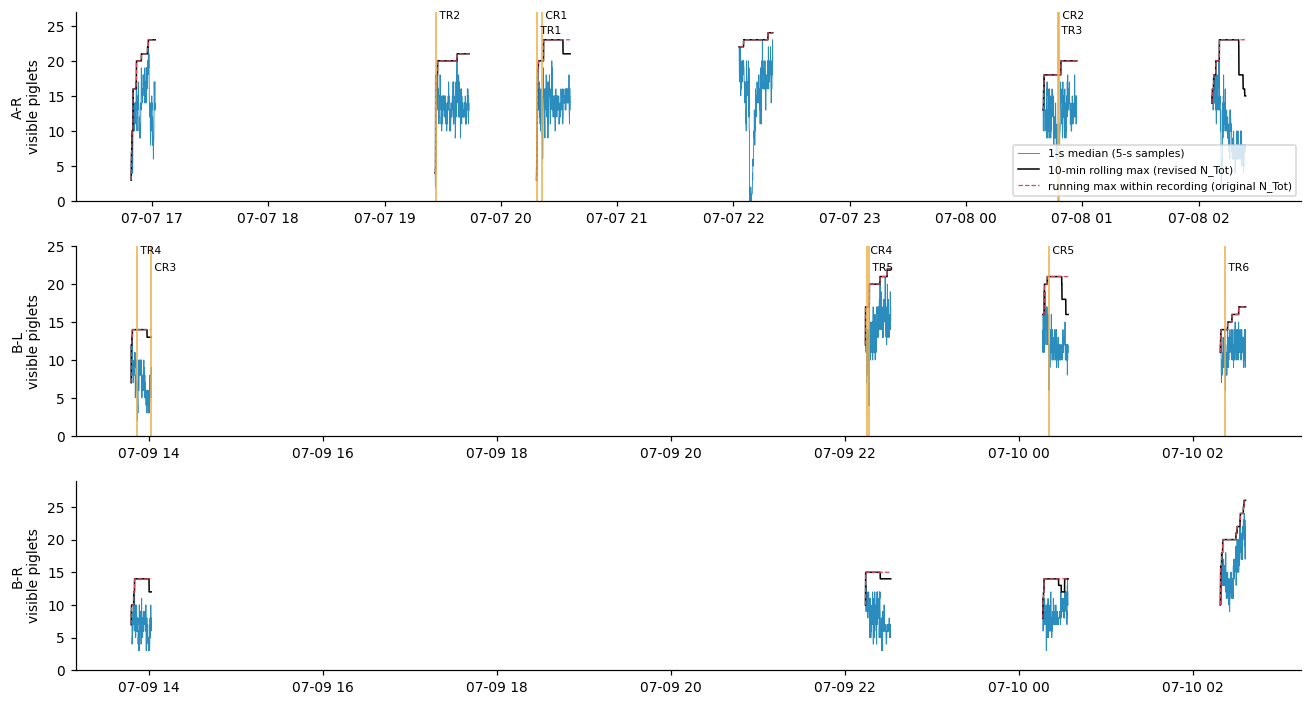

In [54]:
fig, axes = plt.subplots(3, 1, figsize=(12, 6.5))
for ax, lit in zip(axes, ["A-R", "B-L", "B-R"]):
    cam, pen = LITTERS[lit]
    for r in RECS[cam]:
        f = FPS[r]; n = CNT[(r, pen)]["n"]; ns = rolling_median_int(n, int(round(f)))
        idx = np.arange(0, len(ns), int(5 * f))
        t = [START[r] + pd.to_timedelta(i / f, unit="s") for i in idx]
        ax.plot(t, ns[idx], color="#2b8cbe", lw=.6)
        ax.plot(t, pd.Series(ns).rolling(int(600 * f), min_periods=1).max().to_numpy()[idx], color="k", lw=1)
        ax.plot(t, np.maximum.accumulate(ns)[idx], color="#d1495b", lw=.8, ls="--")
    ymax = max(np.maximum.accumulate(rolling_median_int(CNT[(r, pen)]["n"], int(round(FPS[r])))).max() for r in RECS[cam]) + 3
    ax.set_ylabel(f"{lit}\nvisible piglets"); ax.set_ylim(0, ymax)     # was fixed at 20 and cut the A-R counts
    for i, e in enumerate(EV[EV.litter == lit].sort_values("onset_abs").itertuples()):
        ax.axvline(e.onset_abs, color="#edae49", lw=1); ax.text(e.onset_abs, ymax - 1 - 2.2 * (i % 2), " " + e.event_id, fontsize=7)
axes[0].legend(["1-s median (5-s samples)", "10-min rolling max (revised N_Tot)", "running max within recording (original N_Tot)"],
               fontsize=7, loc="lower right")
fig.tight_layout(); save_fig(fig, "F9_litter_count_over_time"); plt.show()

### 11.1 Video evidence on the timing of farrowing
The birth time of the last piglet and the management interventions were not recorded (confirmed by the authors). The video shows the following.
- **A-R**: on 07-07 at 16:49 a person handles piglets inside the pen, and at 17:01 **red spots (apparently blood)** are scattered on the floor. From 19:26 on, the number of visible piglets is stable at 15–17.
- **B-L**: on 07-09 between 13:47 and 14:01 only 8–9 piglets are visible (about 15 from 22:13 on the same day), the teats are red and swollen, and near the sow's hind legs there is
  **a wet dark mass** (apparently afterbirth or a newborn piglet)
  → farrowing was probably **in progress or just finished** at that time. The cases in this period (TR4 13:51, CR3 14:01) fall in a period in which the constant-total assumption does not hold.
- **B-R**: the number of visible piglets is similar at all recorded times (maximum 11–14).

The paper should therefore (i) state that some cases occurred during or just after farrowing, (ii) state that the revised HPA updates the total count as the maximum of the last 10 min instead of a fixed value,
so that it can change with births and removals, and (iii) state as a limitation that, in principle, only the period after farrowing should be used, but this could not be separated without records.

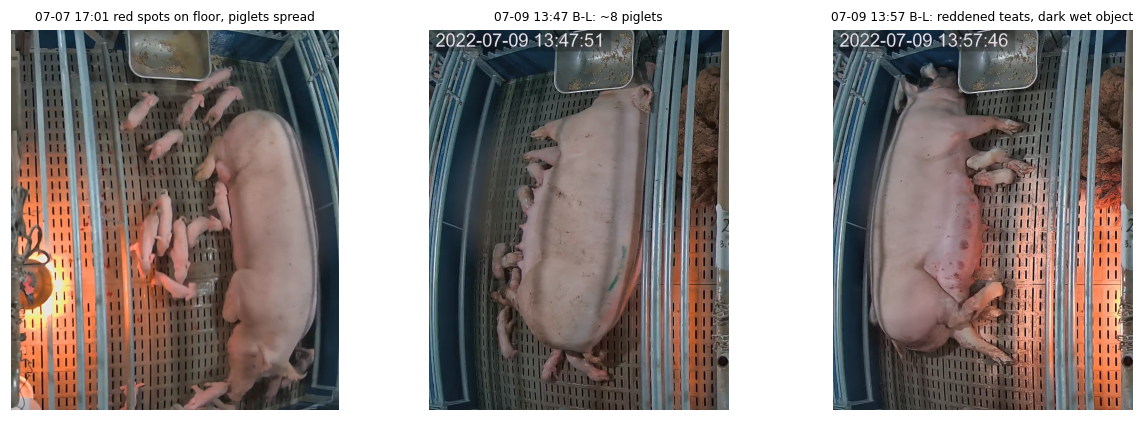

,pen,rec,start,max_visible_1s,p95_visible
0,A-R,A_f257,2022-07-07 16:49:15,16,14.0
1,A-R,A_kt1958,2022-07-07 19:26:07,15,12.0
2,A-R,A_f269,2022-07-07 20:18:24,16,13.0
3,A-R,A_kt1959,2022-07-07 22:02:55,17,15.0
4,A-R,A_kt2044,2022-07-08 00:39:48,16,14.0
5,A-R,A_kt2001,2022-07-08 02:06:54,15,13.0
6,B-L,B_f413,2022-07-09 13:47:46,9,7.0
7,B-L,B_f442,2022-07-09 22:13:57,17,14.0
8,B-L,B_f449,2022-07-10 00:16:15,16,13.0
9,B-L,B_f456,2022-07-10 02:18:37,12,10.0


,pen,rec,start,max_visible_1s,p95_visible
0,A-R,A_f257,2022-07-07 16:49:15,16,14.0
1,A-R,A_kt1958,2022-07-07 19:26:07,15,12.0
2,A-R,A_f269,2022-07-07 20:18:24,16,13.0
3,A-R,A_kt1959,2022-07-07 22:02:55,17,15.0
4,A-R,A_kt2044,2022-07-08 00:39:48,16,14.0
5,A-R,A_kt2001,2022-07-08 02:06:54,15,13.0
6,B-L,B_f413,2022-07-09 13:47:46,9,7.0
7,B-L,B_f442,2022-07-09 22:13:57,17,14.0
8,B-L,B_f449,2022-07-10 00:16:15,16,13.0
9,B-L,B_f456,2022-07-10 02:18:37,12,10.0


In [55]:
FARROW_EVIDENCE = [("A_f257", 710.3, "07-07 17:01 red spots on floor, piglets spread"),
                   ("B_f413", 5, "07-09 13:47 B-L: ~8 piglets"), ("B_f413", 600, "07-09 13:57 B-L: reddened teats, dark wet object")]
fig, axes = plt.subplots(1, len(FARROW_EVIDENCE), figsize=(3.75 * len(FARROW_EVIDENCE), 3.9))
for ax, (r, t, lab) in zip(axes, FARROW_EVIDENCE):
    cam = r[0]; pen = "R" if cam == "A" else "L"; x0, x1 = PEN_ROI[cam][pen]
    ax.imshow(read_frame(r, t)[:, x0:x1]); ax.axis("off"); ax.set_title(lab, fontsize=8)
fig.tight_layout(); save_fig(fig, "S_F11_farrowing_evidence"); plt.show()
mx = LCT[LCT.pen.isin(["A-R", "B-L", "B-R"])].sort_values(["pen", "start"])[["pen", "rec", "start", "max_visible_1s", "p95_visible"]]
display(mx); save_table(mx, "S8_max_visible_by_recording_time")

## 12. Specificity of 'immobility = crushing' (R1-9, R2 L141–147, L198–202)
For each CDA variant: the hourly frequency of suspected-crushing alerts on the continuous recordings and the proportion of them near a real crushing event (±60 s).
This quantifies the reviewers' point that the original CDA keeps counting resting piglets (especially under the heat lamp) as 'newly appeared immobile objects' and therefore has low specificity.

,method,scope,pen_hours,n_alerts,TP,FN,FP,DUP,recall,precision,FA_per_pen_h,alerts_per_pen_h
0,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",target,2.76,165,3,2,158,3,0.6,0.019,57.229,59.783
1,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",all,3.87,320,3,2,313,3,0.6,0.009,80.972,82.687
0,CDA-orig without start-up tracks,target,2.76,156,3,2,149,3,0.6,0.020,53.969,56.522
1,CDA-orig without start-up tracks,all,3.87,308,3,2,301,3,0.6,0.010,77.867,79.587
0,"CDA-v2, no HPA (tracker only)",target,2.76,3064,5,0,2796,113,1.0,0.002,1012.730,1110.145
1,"CDA-v2, no HPA (tracker only)",all,3.87,3982,5,0,3714,113,1.0,0.001,960.796,1028.941
0,"CDA-v2, HPA-gated",target,2.76,2877,5,0,2647,95,1.0,0.002,958.762,1042.391
1,"CDA-v2, HPA-gated",all,3.87,3751,5,0,3521,95,1.0,0.001,910.868,969.251
0,"CDA-v2, HPA+gate-gated",target,2.76,556,5,0,501,43,1.0,0.010,181.466,201.449
1,"CDA-v2, HPA+gate-gated",all,3.87,784,5,0,729,43,1.0,0.007,188.589,202.584


Suspected-crushing alerts in the pen without a litter (A-L) (all false alarms):

,method,n_alerts,FA_per_pen_h
5,"CDA-orig (sort, t_expire=1 frame, f=300 fr, m=...",69,41.66
5,CDA-orig without start-up tracks,64,38.64
5,"CDA-v2, no HPA (tracker only)",314,189.60
5,"CDA-v2, HPA-gated",274,165.44
5,"CDA-v2, HPA+gate-gated",64,38.64
5,"CDA-v2, HPA-gated + crushed class",30,18.11
5,"CDA-v2, HPA-gated, ByteTrack",228,137.67


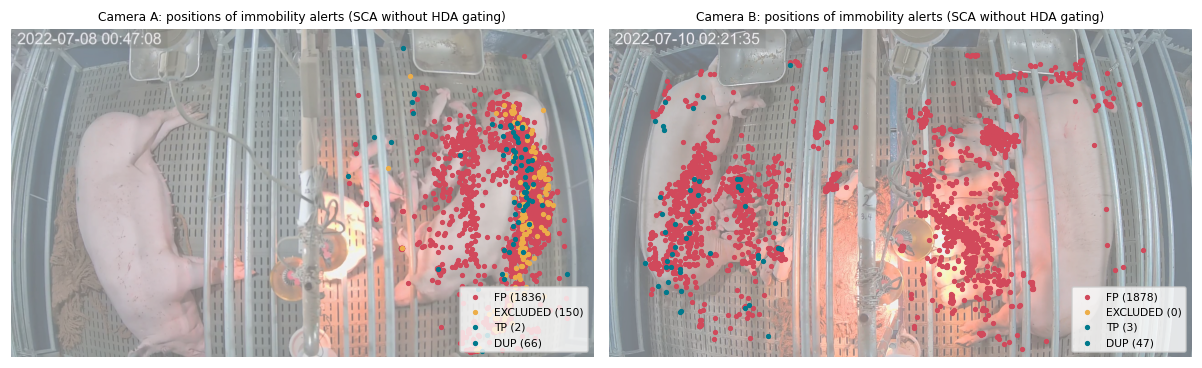


**Interpretation**: immobility alerts without the gate are almost all unrelated to events (FP) and are spread over the places where piglets usually stay — along the sow's udder and under the heat lamp
(the background image is a single moment, so the sow's position differs between moments). Resting or suckling live piglets are thus repeatedly detected as 'newly appeared immobile objects'. The HPA gate (only piglets reappearing from under the sow) and
the 'crushed'-class check greatly reduce the number of alerts, but these alerts should be called **'suspected-crushing (immobility) alerts' that do not confirm death**,
and without additional information such as respiratory movement, longer confirmation times or thermal/depth imaging they cannot be used to determine death.


In [56]:
cda_tab = CONT_CDA[CONT_CDA.scope.isin(["target", "all"])][["method", "scope", "pen_hours", "n_alerts", "TP", "FN", "FP", "DUP", "recall", "precision", "FA_per_pen_h"]]
cda_tab = cda_tab.assign(alerts_per_pen_h=cda_tab.n_alerts / cda_tab.pen_hours)
display(cda_tab.round(3)); save_table(cda_tab.round(4), "T17_cda_specificity")
ctrl = CONT_CDA[CONT_CDA.scope.str.startswith("A-L")][["method", "n_alerts", "FA_per_pen_h"]]
display(Markdown(tr("산자가 없는 펜(A-L)에서의 압사 의심 경보(전부 오경보):", "Suspected-crushing alerts in the pen without a litter (A-L) (all false alarms):"))); display(ctrl.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (cam, vid) in zip(axes, [("A", "T3"), ("B", "T6")]):
    ax.imshow(read_frame(vid, 5), alpha=.55)
    al = ALERT_STATUS["CDA-v2, no HPA (tracker only)"]
    al = al[al.rec.str[0] == cam]
    for st, col in [("FP", "#d1495b"), ("EXCLUDED", "#edae49"), ("TP", "#00798c"), ("DUP", "#00798c")]:
        s = al[al.status == st]; ax.scatter(s.cx, s.cy, s=6, color=col, label=f"{st} ({len(s)})")
    ax.legend(fontsize=7, loc="lower right"); ax.axis("off")
    ax.set_title(f"Camera {cam}: positions of immobility alerts (SCA without HDA gating)", fontsize=8)
fig.tight_layout(); save_fig(fig, "F10_immobility_alert_positions"); plt.show()
display(Markdown(tr("""
**해석**: 게이트가 없는 부동 경보는 거의 모두 사건과 무관하며(FP), 새끼가 평소 머무는 곳 — 어미 젖 줄을 따라, 보온등 아래 — 에 넓게 퍼져 있다
(배경 이미지는 한 시점이라 모돈 위치는 시점마다 다르다). 즉 쉬거나 젖을 먹는 살아 있는 새끼가 '새로 나타난 부동 객체'로 반복 검출된다. HPA 게이트(모돈 밑에서 다시 나타난 새끼만)와
'crushed' 클래스 확인으로 경보 수가 크게 줄지만, 이 경보는 **사망을 확인하지 않는 '압사 의심(부동) 경보'** 로 불러야 하며,
호흡 움직임·더 긴 확인 시간·열/깊이 영상 같은 추가 정보 없이는 사망 판정 도구로 쓸 수 없다.
""", """
**Interpretation**: immobility alerts without the gate are almost all unrelated to events (FP) and are spread over the places where piglets usually stay — along the sow's udder and under the heat lamp
(the background image is a single moment, so the sow's position differs between moments). Resting or suckling live piglets are thus repeatedly detected as 'newly appeared immobile objects'. The HPA gate (only piglets reappearing from under the sow) and
the 'crushed'-class check greatly reduce the number of alerts, but these alerts should be called **'suspected-crushing (immobility) alerts' that do not confirm death**,
and without additional information such as respiratory movement, longer confirmation times or thermal/depth imaging they cannot be used to determine death.
""")))

## 13. Tracking performance (R1-10: IDF1, MOTA, HOTA, ID switches, fragmentation)
MOT metrics require a **frame-by-frame box + identity ground truth**. The original data had none, so (i) proxy measures of tracking quality
that need no ground truth are reported for the three trackers. (ii) A tool to make the ground truth is included: boxes and identities are
pre-filled on 121 frames (0.5-s intervals) of pen B-L in clip T6 by the detector and a plain linker (`prep_13_mot_prefill.py`) and checked
and corrected frame by frame by an observer (`outputs/mot_annotation/annotate_mot.ipynb` → `annotations/mot_gt/T6_L.csv`). When the
ground-truth file exists, the cell below runs the trackers (manuscript SORT, SORT with a 1-s memory, ByteTrack) on every frame with the
detections inside the pen ROI, as in §7–§9, and computes MOTA, IDF1, ID switches and fragmentation (py-motmetrics) and HOTA, DetA and AssA
(Luiten et al. 2021; same computation as TrackEval) on the annotated frames, for the main (leakage-free) detector and, for reference, the
provided detector (trained on evaluation frames).

In [57]:
mot_rows = []
for (r, p, tname), v in TRK.items():
    if v["mot"] and LIT_OF.get((r[0], p)) in LITTERS:
        mot_rows.append(dict(tracker=tname, rec=r, pen=p, minutes=NFR[r] / FPS[r] / 60, **v["mot"]))
MOTP = pd.DataFrame(mot_rows)
MOT_SUM = MOTP.groupby("tracker").apply(lambda g: pd.Series({c: np.average(g[c], weights=g.minutes) for c in
                                         ["births_per_min", "births_per_piglet_per_min", "mean_track_s", "median_track_s",
                                          "frac_dets_in_tracks_ge10s"]})).reindex(["sort_orig", "sort_1s", "bytetrack"])
display(MOT_SUM.round(2)); save_table(MOT_SUM.round(3), "T18_tracking_proxies", index=True)
display(Markdown(tr("""
`births_per_piglet_per_min` = 가시 새끼 한 마리당 분당 새로 생기는 트랙 ID 수(이상적으로 ~0). 원고 설정(`sort_orig`, 1프레임만 놓쳐도 트랙 삭제)은
ID 가 극단적으로 자주 끊기며, 이것이 원 CDA 가 쉬는 새끼를 '새로 나타난 객체'로 반복해서 세는 직접 원인이다.
""", """
`births_per_piglet_per_min` = number of new track IDs per visible piglet per minute (ideally ~0). The manuscript setting (`sort_orig`, a track is deleted after a single missed frame)
breaks IDs extremely often, which is the direct reason why the original CDA repeatedly counts resting piglets as 'newly appeared objects'.
""")))

,births_per_min,births_per_piglet_per_min,mean_track_s,median_track_s,frac_dets_in_tracks_ge10s
tracker,,,,,
sort_orig,764.14,65.52,0.96,0.15,0.46
sort_1s,201.69,17.98,4.46,0.87,0.74
bytetrack,176.04,16.35,4.45,0.94,0.71



`births_per_piglet_per_min` = number of new track IDs per visible piglet per minute (ideally ~0). The manuscript setting (`sort_orig`, a track is deleted after a single missed frame)
breaks IDs extremely often, which is the direct reason why the original CDA repeatedly counts resting piglets as 'newly appeared objects'.


In [58]:
def mot_eval(gt_df, tr_df, iou_thr=0.5):
    """MOTA / IDF1 / ID switches / fragmentations with py-motmetrics; IoU distance computed here
    (motmetrics.distances.iou_matrix needs NumPy < 2). gt_df, tr_df: columns frame, id, x1, y1, x2, y2"""
    import motmetrics as mm
    acc = mm.MOTAccumulator(auto_id=True)
    xy = ["x1", "y1", "x2", "y2"]
    for f in sorted(set(gt_df.frame) | set(tr_df.frame)):
        g = gt_df[gt_df.frame == f]; t = tr_df[tr_df.frame == f]
        a, b = g[xy].to_numpy(float), t[xy].to_numpy(float)
        d = np.full((len(a), len(b)), np.nan)
        if len(a) and len(b):
            x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
            x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
            inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
            ar = lambda c: (c[:, 2] - c[:, 0]) * (c[:, 3] - c[:, 1])
            iou = inter / (ar(a)[:, None] + ar(b)[None, :] - inter)
            d = np.where(iou >= iou_thr, 1 - iou, np.nan)
        acc.update(g.id.tolist(), t.id.tolist(), d)
    mh = mm.metrics.create()
    return mh.compute(acc, metrics=["mota", "motp", "idf1", "num_switches", "num_fragmentations", "precision", "recall"], name="all")

def hota(gt_df, tr_df, frames, alphas=np.arange(0.05, 0.99, 0.05)):
    """HOTA, DetA, AssA, LocA (Luiten et al. 2021, IJCV), IoU similarity, averaged over the localisation thresholds alpha;
    follows the TrackEval implementation (global alignment score -> per-frame Hungarian matching -> per-alpha counts)"""
    XY = ["x1", "y1", "x2", "y2"]
    gid = {v: i for i, v in enumerate(sorted(gt_df.id.unique()))}; tid = {v: i for i, v in enumerate(sorted(tr_df.id.unique()))}
    G, T = dict(tuple(gt_df.groupby("frame"))), dict(tuple(tr_df.groupby("frame")))
    def iou_m(a, b):
        x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
        x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
        inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
        ar = lambda c: (c[:, 2] - c[:, 0]) * (c[:, 3] - c[:, 1])
        return inter / (ar(a)[:, None] + ar(b)[None, :] - inter)
    eps = np.finfo(float).eps
    steps, pot = [], np.zeros((len(gid), len(tid)))
    gcnt, tcnt = np.zeros((len(gid), 1)), np.zeros((1, len(tid)))
    for f in frames:
        g, t = G.get(f, gt_df.iloc[:0]), T.get(f, tr_df.iloc[:0])
        gi, ti = np.array([gid[v] for v in g.id], int), np.array([tid[v] for v in t.id], int)
        sim = iou_m(g[XY].to_numpy(float), t[XY].to_numpy(float)) if len(gi) and len(ti) else np.zeros((len(gi), len(ti)))
        if len(gi) and len(ti):
            den = sim.sum(0)[None, :] + sim.sum(1)[:, None] - sim
            pot[gi[:, None], ti[None, :]] += np.where(den > eps, sim / np.maximum(den, eps), 0)
        gcnt[gi] += 1; tcnt[0, ti] += 1
        steps.append((gi, ti, sim))
    gas = pot / (gcnt + tcnt - pot)
    A = len(alphas); TP, FN, FP, loc = np.zeros(A), np.zeros(A), np.zeros(A), np.zeros(A)
    mc = np.zeros((A, len(gid), len(tid)))
    for gi, ti, sim in steps:
        if not len(gi):
            FP += len(ti); continue
        if not len(ti):
            FN += len(gi); continue
        r, c = linear_sum_assignment(-(gas[gi[:, None], ti[None, :]] * sim))
        for a, al in enumerate(alphas):
            ok = sim[r, c] >= al - eps
            n = int(ok.sum()); TP[a] += n; FN[a] += len(gi) - n; FP[a] += len(ti) - n
            if n:
                loc[a] += sim[r[ok], c[ok]].sum(); mc[a][gi[r[ok]], ti[c[ok]]] += 1
    AssA = np.array([(m * m / np.maximum(1, gcnt + tcnt - m)).sum() / max(1.0, TP[a]) for a, m in enumerate(mc)])
    DetA = TP / np.maximum(1, TP + FN + FP)
    return dict(HOTA=float(np.sqrt(DetA * AssA).mean()), DetA=float(DetA.mean()), AssA=float(AssA.mean()),
                LocA=float((np.maximum(1e-10, loc) / np.maximum(1e-10, TP)).mean()))

MOT_GT = ROOT / "annotations" / "mot_gt"          # outputs/mot_annotation/annotate_mot.ipynb (prep_13_mot_prefill.py) -> <clip>_<pen>.csv
tmpl = OUT / "mot_annotation_template"
if not tmpl.exists() and all((ROOT / VIDEOS[c]["path"]).exists() for c in ["T6", "T4"]):
    for clip in ["T6", "T4"]:
        d = tmpl / clip; d.mkdir(parents=True, exist_ok=True)
        cap = cv2.VideoCapture(str(ROOT / VIDEOS[clip]["path"])); step = int(round(FPS[clip] / 2))   # 2 frames per second
        k = 0
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            if k % step == 0:
                cv2.imwrite(str(d / f"frame_{k:05d}.jpg"), fr, [cv2.IMWRITE_JPEG_QUALITY, 85])
            k += 1
        pd.DataFrame(columns=["frame", "id", "x1", "y1", "x2", "y2", "visibility(full/partial)"]).to_csv(d / "gt_template.csv", index=False)

def mot_table():
    """every tracker x detector against each finished ground truth (annotated frames only; the trackers run on every frame of the
    pen, as in §7-§9)"""
    rows = []
    for g in sorted(MOT_GT.glob("*.csv")):
        clip, pen = g.stem.split("_"); cam = VIDEOS[clip]["camera"]; f = FPS[clip]
        gt = pd.read_csv(g); meta = json.load(open(g.with_suffix(".json")))
        frames = meta["frames"]
        for dname, tag in [("selected leakage-free (pre-specified rule)", MAIN_TAG), ("provided YOLOv8s (training incl. evaluation frames)", "")]:
            fr = frames_dets(clip, pen=pen, camera=cam, tag=tag)
            for tname, cfg in TRACKERS.items():
                if cfg["tracker"] == "sort":
                    ma = cfg.get("max_age_frames") or int(round(cfg["max_age_s"] * f))
                    tr = run_tracker(fr, iou_thr=cfg["iou_thr"], max_age=ma, tracker="sort", fps=f)
                else:
                    tr = run_tracker(fr, tracker="bytetrack", fps=f)
                tr = tr.assign(x1=tr.cx - tr.w / 2, y1=tr.cy - tr.h / 2, x2=tr.cx + tr.w / 2, y2=tr.cy + tr.h / 2, id=tr.tid)
                tr = tr[tr.frame.isin(frames)]
                m = mot_eval(gt, tr).iloc[0]
                rows.append(dict(clip=clip, pen=pen, litter=LIT_OF.get((cam, pen)), detector=dname, tracker=tname,
                                 annotated_frames=len(frames), gt_boxes=len(gt), gt_identities=gt.id.nunique(),
                                 **hota(gt, tr, frames), MOTA=m.mota, IDF1=m.idf1, ID_switches=int(m.num_switches),
                                 fragmentations=int(m.num_fragmentations), MOTP_IoU=1 - m.motp, precision=m.precision, recall=m.recall,
                                 tracker_identities=tr.id.nunique()))
    return pd.DataFrame(rows)

MOT = mot_table() if MOT_GT.exists() and any(MOT_GT.glob("*.csv")) else None
if MOT is not None:
    display(MOT.round(3)); save_table(MOT.round(4), "T18b_mot_metrics")
    _g = MOT.iloc[0]
    _fmt = lambda s, d=2: ", ".join(f"{k} {v:.{d}f}" for k, v in s.items())
    _m = MOT[MOT.detector.str.startswith("selected")].set_index("tracker")
    _p = MOT[MOT.detector.str.startswith("provided")].set_index("tracker")
    display(Markdown(tr(
        f"""**해석** — 정답: {_g.clip} 클립 {_g.litter} 펜, 0.5초 간격 {_g.annotated_frames}장, 박스 {_g.gt_boxes}개, 자돈 번호 {_g.gt_identities}개
(관찰자 1명이 미리 채운 박스·번호를 프레임마다 고침, `prep_13_mot_prefill.py` → `annotate_mot.ipynb`).
- 주 검출기(누수 없음): HOTA {_fmt(_m.HOTA)} · IDF1 {_fmt(_m.IDF1)} · MOTA {_fmt(_m.MOTA)} · ID switch {_fmt(_m.ID_switches, 0)}
- 제공 검출기(평가 프레임으로 학습, 참고값): HOTA {_fmt(_p.HOTA)} · IDF1 {_fmt(_p.IDF1)} · MOTA {_fmt(_p.MOTA)}
- 60초 클립 하나, 관찰자 한 명의 정답이다. 완전히 가려졌다 다시 나온 자돈은 누구인지 확실할 때만 같은 번호로 이었으므로, ID 지표는 그 판단의 불확실성을 포함한다.""",
        f"""**Interpretation** — ground truth: clip {_g.clip}, pen {_g.litter}, {_g.annotated_frames} frames at 0.5-s intervals, {_g.gt_boxes} boxes,
{_g.gt_identities} piglet identities (one observer corrected pre-filled boxes and identities frame by frame; `prep_13_mot_prefill.py` →
`annotate_mot.ipynb`).
- Main (leakage-free) detector: HOTA {_fmt(_m.HOTA)} · IDF1 {_fmt(_m.IDF1)} · MOTA {_fmt(_m.MOTA)} · ID switches {_fmt(_m.ID_switches, 0)}
- Provided detector (trained on evaluation frames; reference only): HOTA {_fmt(_p.HOTA)} · IDF1 {_fmt(_p.IDF1)} · MOTA {_fmt(_p.MOTA)}
- One 60-s clip annotated by one observer. A piglet re-appearing after full occlusion kept its identity only when the observer was
  certain, so the identity metrics include the uncertainty of that judgement.""")))
else:
    print(tr("MOT 정답이 아직 없음 ->", "No MOT ground truth yet ->"), MOT_GT, "(outputs/mot_annotation/annotate_mot.ipynb)")

No MOT ground truth yet -> annotations/mot_gt (outputs/mot_annotation/annotate_mot.ipynb)


## 14. Computational performance and latency (R1-11)
Per-stage times were measured under **streaming conditions (batch 1, frame by frame)**, not as offline throughput. The latency here is computational latency,
different from the 'event onset → alert' latency of §8 (algorithmic latency, including the $d$-second wait). Alert delivery and human response times were not measured (no deployed system).

In [59]:
def benchmark(clip="T1", n=450, device=0, half=True, imgsz=416, weights=None, label="provided YOLOv8s", backend="ultralytics"):
    import resource
    from ultralytics import YOLO
    if backend == "yolov5":
        v5 = torch.hub.load(str(ROOT / "third_party/yolov5"), "custom", path=str(weights), source="local", verbose=False)
        v5.conf, v5.iou = 0.25, 0.45
        v5 = v5.to(0 if device != "cpu" else "cpu")

        class _V5:      # minimal adapter: same call signature as the Ultralytics model below
            def predict(self, fr, **kw):
                r = v5(fr[..., ::-1], size=imgsz).xyxy[0].cpu().numpy()

                class _B:
                    xyxy = torch.tensor(r[:, :4]); conf = torch.tensor(r[:, 4]); cls = torch.tensor(r[:, 5])

                    def __len__(self):
                        return len(r)

                class _R:
                    boxes = _B()
                return [_R()]
        model = _V5()
    else:
        model = YOLO(str(weights or ROOT / "extracted/train/train/weights/best.pt"))
    cap = cv2.VideoCapture(str(ROOT / VIDEOS[clip]["path"]))
    frames = []
    t_dec = []
    for _ in range(n):
        t0 = time.perf_counter(); ok, fr = cap.read(); t_dec.append(time.perf_counter() - t0)
        if not ok:
            break
        frames.append(fr)
    for fr in frames[:20]:                                       # warm-up
        model.predict(fr, imgsz=imgsz, conf=0.25, half=half, device=device, verbose=False)
    if device != "cpu":
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t_det, dets = [], []
    for fr in frames:
        t0 = time.perf_counter()
        r = model.predict(fr, imgsz=imgsz, conf=0.25, half=half, device=device, verbose=False)[0]
        if device != "cpu":
            torch.cuda.synchronize()
        t_det.append(time.perf_counter() - t0)
        b = r.boxes; dets.append(np.c_[b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()] if len(b) else np.zeros((0, 6)))
    # tracker per frame
    tr = SortTracker(0.3, int(round(FPS[clip]))); t_trk = []
    for d in dets:
        t0 = time.perf_counter(); tr.step(d); t_trk.append(time.perf_counter() - t0)
    nd = np.array([len(d) for d in dets])
    t0 = time.perf_counter(); hpa_original(nd); t_hpa_o = (time.perf_counter() - t0) / len(nd)
    t0 = time.perf_counter(); hpa_v2(nd, FPS[clip]); t_hpa_v2 = (time.perf_counter() - t0) / len(nd)
    t0 = time.perf_counter(); trk = run_tracker(dets, max_age=int(round(FPS[clip]))); s = track_summary(trk, FPS[clip])
    cda_v2_from_summary(s, FPS[clip]); t_cda = (time.perf_counter() - t0) / len(nd) - np.mean(t_trk)
    ms = lambda x: 1000 * float(np.mean(x))
    out = dict(detector=label, clip=clip, resolution=f"{video_meta(clip)['width']}x{video_meta(clip)['height']}",
               device=("GPU " + torch.cuda.get_device_name(0)) if device != "cpu" else f"CPU ({torch.get_num_threads()} threads)",
               precision=("FP16" if half and device != "cpu" else "FP32") if backend != "yolov5" else "FP32", imgsz=imgsz,
               frames=len(frames),
               decode_ms=ms(t_dec), detector_ms=ms(t_det), detector_p95_ms=1000 * float(np.quantile(t_det, .95)),
               tracker_ms=ms(t_trk), hpa_orig_ms=1000 * t_hpa_o, hpa_v2_ms=1000 * t_hpa_v2, cda_v2_ms=max(0.0, 1000 * t_cda))
    out["end_to_end_ms"] = out["decode_ms"] + out["detector_ms"] + out["tracker_ms"] + out["hpa_v2_ms"] + out["cda_v2_ms"]
    out["throughput_fps"] = 1000 / out["end_to_end_ms"]
    out["gpu_peak_mem_MB"] = torch.cuda.max_memory_allocated() / 1e6 if device != "cpu" else np.nan
    out["process_peak_RSS_MB"] = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e3
    return out

def run_benchmarks():
    rows = [benchmark("T1", device=0, half=True), benchmark("T1", device=0, half=False), benchmark("T2", device=0, half=True)]
    v5w = ROOT / VS[(VS.arch == "v5s") & (VS.fold == "ctrl") & (VS.imgsz == 416)].weights.iloc[0]
    rows.append(benchmark("T1", device=0, weights=v5w, label="YOLOv5s (retrained)", backend="yolov5"))
    sa = SEL["holdA"]
    rows.append(benchmark("T1", device=0, half=True, imgsz=int(sa["imgsz"]), weights=ROOT / sa["weights"],
                          label=f"selected {sa['arch']}@{sa['imgsz']}", backend="yolov5" if sa["arch"] == "v5s" else "ultralytics"))
    nthr = torch.get_num_threads(); torch.set_num_threads(8)
    rows.append(benchmark("T1", n=120, device="cpu", half=False))
    torch.set_num_threads(nthr)
    return pd.DataFrame(rows)

BENCH = cached("runtime_benchmark_v2", run_benchmarks, needs_raw=True)
display(BENCH.round(2)); save_table(BENCH.round(3), "T19_runtime")

,detector,clip,resolution,device,precision,imgsz,frames,decode_ms,detector_ms,detector_p95_ms,tracker_ms,hpa_orig_ms,hpa_v2_ms,cda_v2_ms,end_to_end_ms,throughput_fps,gpu_peak_mem_MB,process_peak_RSS_MB
0,provided YOLOv8s,T1,1920x1080,GPU NVIDIA H100 NVL,FP16,416,450,2.47,6.93,7.40,0.22,0.00,0.01,0.05,9.69,103.25,28.07,8122.80
1,provided YOLOv8s,T1,1920x1080,GPU NVIDIA H100 NVL,FP32,416,450,2.03,6.50,6.84,0.23,0.00,0.01,0.03,8.79,113.76,77.09,8187.01
2,provided YOLOv8s,T2,1280x720,GPU NVIDIA H100 NVL,FP16,416,450,0.68,6.80,7.36,0.24,0.00,0.01,0.04,7.77,128.62,72.91,8187.86
3,YOLOv5s (retrained),T1,1920x1080,GPU NVIDIA H100 NVL,FP32,416,450,1.37,15.55,16.32,0.26,0.00,0.01,0.04,17.23,58.05,137.60,8205.30
4,selected v8s@416,T1,1920x1080,GPU NVIDIA H100 NVL,FP16,416,450,1.91,6.72,6.81,0.26,0.00,0.01,0.04,8.92,112.12,158.80,8271.89
5,provided YOLOv8s,T1,1920x1080,CPU (8 threads),FP32,416,120,1.88,27.91,33.81,0.22,0.01,0.03,0.04,30.08,33.24,NaN,8299.37


,detector,clip,resolution,device,precision,imgsz,frames,decode_ms,detector_ms,detector_p95_ms,tracker_ms,hpa_orig_ms,hpa_v2_ms,cda_v2_ms,end_to_end_ms,throughput_fps,gpu_peak_mem_MB,process_peak_RSS_MB
0,provided YOLOv8s,T1,1920x1080,GPU NVIDIA H100 NVL,FP16,416,450,2.474,6.932,7.396,0.224,0.001,0.007,0.048,9.685,103.251,28.073,8122.800
1,provided YOLOv8s,T1,1920x1080,GPU NVIDIA H100 NVL,FP32,416,450,2.031,6.496,6.839,0.227,0.002,0.008,0.029,8.790,113.764,77.088,8187.008
2,provided YOLOv8s,T2,1280x720,GPU NVIDIA H100 NVL,FP16,416,450,0.683,6.804,7.362,0.244,0.001,0.007,0.036,7.775,128.621,72.910,8187.860
3,YOLOv5s (retrained),T1,1920x1080,GPU NVIDIA H100 NVL,FP32,416,450,1.372,15.552,16.317,0.256,0.002,0.009,0.037,17.225,58.054,137.596,8205.296
4,selected v8s@416,T1,1920x1080,GPU NVIDIA H100 NVL,FP16,416,450,1.905,6.716,6.813,0.256,0.001,0.007,0.036,8.919,112.117,158.803,8271.888
5,provided YOLOv8s,T1,1920x1080,CPU (8 threads),FP32,416,120,1.880,27.911,33.808,0.217,0.005,0.031,0.041,30.080,33.245,NaN,8299.368


## 15. Independent farm (2023, farrowing crates) and night recordings (R1-3 ③, R1-11)
The 5 recordings of the independent-farm archive (extracted to `data/apsa/`; 'apsa' = crushing in Korean) come from **another farm** (farrowing crates, oblique single-pen view) in February/March 2023, and the crushing times are noted in a text file of that archive.
Images of this view were not in the detector training (§3): the 102 'other farm' training images are side views of farrowing crates (green partitions), whereas X1–X5 show different equipment
(red heat lamps) viewed obliquely from above. The frame comparison (§3) also matched none of the X1–X5 frames (below). Whether the two are different pens of the same farm cannot be checked
because it was not recorded, so the paper describes them as 'cameras and pens not used for training'. The 2022-02-17 recording is a night (infrared) recording. The thresholds were applied unchanged (§7 development setting).
The detector is the provided YOLOv8s, which has the most training data — images of this farm and of the night recording were not in its training, so this evaluation has no leakage.

,rec,start,end,onset_s,end_s
0,X1,2023-03-03 11:44:05,2023-03-03 11:44:05,825.0,825.0
1,X2,2023-03-01 00:49:56,2023-03-01 00:50:00,898.0,902.0
2,X3,2023-03-01 09:11:20,2023-03-01 09:11:25,583.0,588.0
3,X4,2023-02-08 02:50:00,2023-02-08 02:56:00,241.0,601.0
4,X5,2023-02-08 04:50:00,2023-02-08 04:53:00,98.0,278.0


,rec,hours,median_visible,p95_visible,frac_frames_no_detection,mean_conf,hpa_v2_alerts,hpa_v2_gate_alerts,memo_event_detected,latency_s,false_alarms,FA_per_h
0,X1,0.294,0.0,0.0,0.973,0.448,2,0,False,NaN,0,0.000
1,X2,0.291,0.0,5.0,0.526,0.549,26,3,True,13.445,2,6.876
2,X3,0.282,0.0,3.0,0.727,0.582,16,0,False,NaN,0,0.000
3,X4,0.260,1.0,3.0,0.454,0.577,23,0,False,NaN,0,0.000
4,X5,0.221,1.0,3.0,0.165,0.593,15,12,True,-37.235,5,22.636


,rec,hours,median_visible,p95_visible,frac_frames_no_detection,mean_conf,hpa_v2_alerts,hpa_v2_gate_alerts
0,N_f51,0.292,16.0,19.0,0.0,0.672,35,0


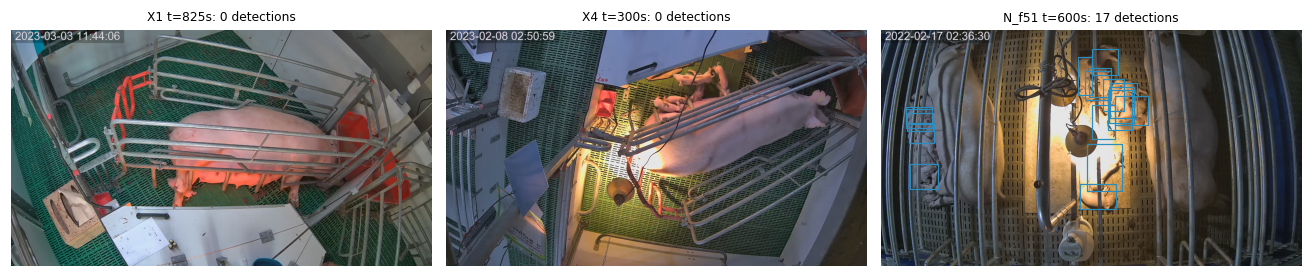

102 'other farm' training images — minimum mean absolute difference (MAD) to the frames of all recordings (incl. X1–X5): 38.9–43.5 (training images that did match: ≤ 1.7) -> no match with any frame of X1–X5


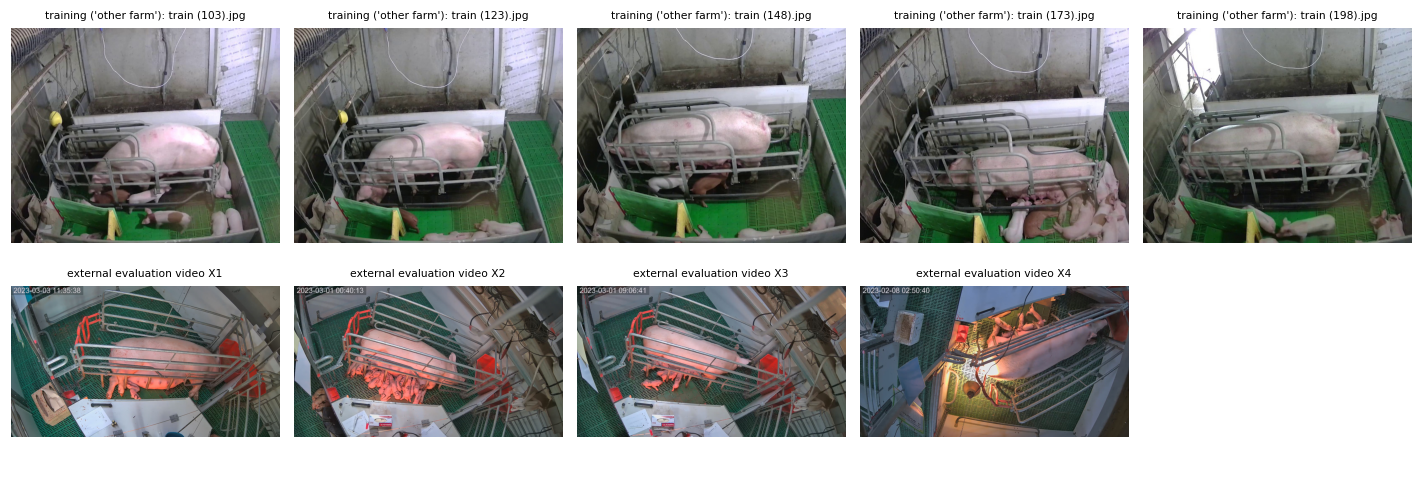

In [60]:
MEMO = pd.DataFrame([  # crushing memo of the independent-farm archive (clock time) -> seconds in each recording
    dict(rec="X1", start="2023-03-03 11:44:05", end="2023-03-03 11:44:05"),
    dict(rec="X2", start="2023-03-01 00:49:56", end="2023-03-01 00:50:00"),
    dict(rec="X3", start="2023-03-01 09:11:20", end="2023-03-01 09:11:25"),
    dict(rec="X4", start="2023-02-08 02:50:00", end="2023-02-08 02:56:00"),
    dict(rec="X5", start="2023-02-08 04:50:00", end="2023-02-08 04:53:00")])
MEMO["onset_s"] = [(pd.Timestamp(s) - START[r]).total_seconds() for s, r in zip(MEMO.start, MEMO.rec)]
MEMO["end_s"] = [(pd.Timestamp(s) - START[r]).total_seconds() for s, r in zip(MEMO.end, MEMO.rec)]
display(MEMO)

def external_eval(recs, gt, cam, tag=""):
    rows, al_all = [], []
    for r in recs:
        f = FPS[r]; n = count_series(r, pen="ALL", camera=cam, tag=tag)
        ts, ev = hpa_v2(n, f, **HPA_DEFAULT); mot = pen_motion(r, "ALL", cam)
        evg = gate_alerts(ev, mot, f, thr=GATE_DEFAULT) if len(ev) else ev
        d = load_dets(r, tag); d = d[d.conf >= .25]
        rows.append(dict(rec=r, hours=len(n) / f / 3600, median_visible=float(np.median(n)), p95_visible=float(np.quantile(n, .95)),
                         frac_frames_no_detection=float(np.mean(n == 0)), mean_conf=float(d.conf.mean()) if len(d) else np.nan,
                         hpa_v2_alerts=len(ev), hpa_v2_gate_alerts=len(evg)))
        al_all.append(pd.DataFrame(dict(rec=r, pen="ALL", alert_s=evg.alert_s if len(evg) else [])))
    return pd.DataFrame(rows), pd.concat(al_all)

XSTAT, XAL = external_eval(["X1", "X2", "X3", "X4", "X5"], MEMO, "X")
GTX = MEMO.assign(event_id=MEMO.rec + "_memo", pen="ALL", pre_s=60.0, post_s=(MEMO.end_s - MEMO.onset_s) + 60.0)
ax2, gx2 = match_alerts(XAL, GTX)
XSTAT["memo_event_detected"] = XSTAT.rec.map(dict(zip(gx2.rec, gx2.detected)))
XSTAT["latency_s"] = XSTAT.rec.map(dict(zip(gx2.rec, gx2.latency_s)))
XSTAT["false_alarms"] = XSTAT.rec.map(ax2[ax2.status == "FP"].groupby("rec").size()).fillna(0).astype(int)
XSTAT["FA_per_h"] = XSTAT.false_alarms / XSTAT.hours
NSTAT, NAL = external_eval(["N_f51"], None, "N")
display(XSTAT.round(3)); display(NSTAT.round(3))
save_table(pd.concat([XSTAT, NSTAT]).round(4), "T20_external_farm_and_night")
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, (v, t) in zip(axes, [("X1", 825), ("X4", 300), ("N_f51", 600)]):
    img = read_frame(v, t); ax.imshow(img)
    d = load_dets(v); d = d[(d.frame == int(t * FPS[v])) & (d.conf >= .25)]
    for b in d.itertuples():
        ax.add_patch(plt.Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False, lw=.8, ec="#2b8cbe"))
    ax.set_title(f"{v} t={t}s: {len(d)} detections", fontsize=8); ax.axis("off")
fig.tight_layout(); save_fig(fig, "S_F10_external_detections"); plt.show()

OTH = TRM[~TRM.matched]
print(tr(f"'다른 농장' 학습 이미지 {len(OTH)}장 — 모든 녹화(X1–X5 포함) 프레임과의 최소 평균 절대 차이(MAD): "
         f"{OTH.mad.min():.1f}–{OTH.mad.max():.1f} (실제로 일치한 학습 이미지는 ≤ {TRM[TRM.matched].mad.max():.1f}) -> X1–X5 의 어떤 프레임과도 일치하지 않음",
         f"{len(OTH)} 'other farm' training images — minimum mean absolute difference (MAD) to the frames of all recordings (incl. X1–X5): "
         f"{OTH.mad.min():.1f}–{OTH.mad.max():.1f} (training images that did match: ≤ {TRM[TRM.matched].mad.max():.1f}) -> no match with any frame of X1–X5"))
fig, axes = plt.subplots(2, 5, figsize=(13, 4.4))
for ax, im in zip(axes[0], OTH.image.iloc[[0, 20, 45, 70, 95]]):
    ax.imshow(read_image(Path("data") / "new data origin" / im))
    ax.set_title(f"training ('other farm'): {im}", fontsize=7); ax.axis("off")
for ax, v in zip(axes[1], ["X1", "X2", "X3", "X4"]):     # X5 is not shown: a person is in view
    ax.imshow(read_frame(v, 0.3 * NFR[v] / FPS[v])); ax.set_title(f"external evaluation video {v}", fontsize=7); ax.axis("off")
axes[1][4].axis("off")
fig.tight_layout(); save_fig(fig, "S_F12_external_vs_training_views"); plt.show()

## 16. Reliability of the reference annotation — observer agreement (Editor, R1-4, R2 L101–102)
The manuscript states only that two observers (T.Y.Y., J.Y.) annotated independently and reached consensus by discussion. The **agreement of the two observers before consensus** requested by the reviewers cannot be
computed retrospectively, because the original annotations were not kept (the function below computes it as soon as such a file exists). Instead, the following are reported (named precisely):
1. **Manuscript consensus annotation ↔ new blind continuous annotation**: how many of the 11 manuscript events were found again, and the time differences (agreement with a reference that involved both observers; not fully independent).
2. **Intra-observer agreement of the continuous annotation (test–retest)**: the same observer re-annotated a stratified sample of segments, in shuffled order, some time later (`annotate_retest.ipynb`).
3. **Intra-observer agreement of the alert labels (test–retest)**: relabelling after 12 days (κ, T21 below).
4. If a second observer becomes available, **inter-observer** agreement (`annotate_continuous_observer2.ipynb`).
All revised references (alert labels, continuous annotation, adjudication) were produced by **one observer**, who was also involved in developing the algorithm — to be stated in the Methods and limitations.
- Event occurrence (0/1 per window): Cohen's κ
- Hidden/visible/crushed counts: ICC(2,1) (two-way random, absolute agreement, single rater) and exact agreement
- Onset time: mean absolute difference, proportion within ±1 s and ±2 s
- When the alert review sheets of §8.2 (`observer1`, `observer2`) are filled in, alert-level κ is computed as well.

In [61]:
from sklearn.metrics import cohen_kappa_score

def icc2_1(x):
    """ICC(2,1): x = n_targets x k_raters"""
    x = np.asarray(x, float); n, k = x.shape
    gm = x.mean(); msr = k * ((x.mean(1) - gm) ** 2).sum() / (n - 1); msc = n * ((x.mean(0) - gm) ** 2).sum() / (k - 1)
    sse = ((x - x.mean(1, keepdims=True) - x.mean(0, keepdims=True) + gm) ** 2).sum(); mse = sse / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

def interobserver(df):
    out = {}
    if {"obs1_event", "obs2_event"} <= set(df):
        out["kappa_event"] = cohen_kappa_score(df.obs1_event, df.obs2_event)
        out["agreement_event"] = float((df.obs1_event == df.obs2_event).mean())
    for q in ["n_hidden", "n_visible", "n_crushed"]:
        a, b = f"obs1_{q}", f"obs2_{q}"
        if {a, b} <= set(df):
            s = df[[a, b]].dropna()
            if len(s) > 2:
                out[f"ICC21_{q}"] = icc2_1(s.to_numpy()); out[f"exact_{q}"] = float((s[a] == s[b]).mean())
    if {"obs1_onset_s", "obs2_onset_s"} <= set(df):
        dd = (df.obs1_onset_s - df.obs2_onset_s).abs().dropna()
        out.update(onset_MAD_s=float(dd.mean()), onset_within_1s=float((dd <= 1).mean()), onset_within_2s=float((dd <= 2).mean()))
    return out

IO_FILE = ROOT / "annotations" / "interobserver_preconsensus.csv"
tmpl_io = OUT / "tables" / "interobserver_preconsensus_TEMPLATE.csv"
pd.DataFrame(dict(event_or_window_id=list(EV.event_id), rec=list(EV.rec), pen=list(EV.pen),
                  obs1_event="", obs2_event="", obs1_onset_s="", obs2_onset_s="", obs1_n_hidden="", obs2_n_hidden="",
                  obs1_n_visible="", obs2_n_visible="", obs1_n_crushed="", obs2_n_crushed="",
                  ground_truth_basis="(video only / second camera / farm record / necropsy)",
                  annotation_confidence="(high / medium / low)")).to_csv(tmpl_io, index=False)
if IO_FILE.exists():
    display(pd.DataFrame([interobserver(pd.read_csv(IO_FILE))]).round(3))
else:
    print("pre-consensus annotations not found ->", IO_FILE, "\ntemplate written to", tmpl_io)
OBSERVER1_DATE = pd.Timestamp("2026-10-09")     # observer1 labelled all TPA alerts on this day (sheet saved 2026-10-09 11:57)
EVENT_LABELS = ["trapping", "crushing"]


def kappa_ci(x, y, n_boot=2000, seed=0):
    """Cohen's kappa with a percentile bootstrap 95 % CI (resampling alerts)."""
    x, y = np.asarray(x), np.asarray(y)
    k = cohen_kappa_score(x, y)
    rng = np.random.default_rng(seed)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")            # resamples with a single class give nan -> ignored
        bs = [cohen_kappa_score(x[i], y[i]) for i in rng.integers(0, len(x), (n_boot, len(x)))]
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    return float(k), float(lo), float(hi)


kap = []
for name in ["TPA_v2_gate", "CDA_v2_HPA_activity_gated"]:
    sh = pd.read_csv(OUT / "alert_review" / name / "review_sheet.csv", dtype=str).fillna("")
    for a, b, kind in [("observer1", "observer2", "inter-observer"), ("observer1", "observer1_repeat", "intra-observer (test-retest)")]:
        if a in sh and b in sh:
            lab = sh[(sh[a] != "") & (sh[b] != "")]
            if len(lab) >= 5:
                # 4 categories (trapping/crushing/no_event/uncertain) and the split that precision depends on:
                # event (trapping or crushing) vs no_event, alerts labelled 'uncertain' by either reading left out
                ev = lab[(lab[a] != "uncertain") & (lab[b] != "uncertain")]
                ev_a, ev_b = ev[a].isin(EVENT_LABELS), ev[b].isin(EVENT_LABELS)
                k4, k4_lo, k4_hi = kappa_ci(lab[a], lab[b])
                k2, k2_lo, k2_hi = kappa_ci(ev_a, ev_b)
                row = dict(sheet=name, agreement=kind, n=len(lab),
                           kappa=k4, kappa_lo=k4_lo, kappa_hi=k4_hi, percent_agreement=float((lab[a] == lab[b]).mean()),
                           n_event_split=len(ev), kappa_event=k2, kappa_event_lo=k2_lo, kappa_event_hi=k2_hi,
                           percent_agreement_event=float((ev_a == ev_b).mean()),
                           precision_first=float(ev_a.mean()), precision_second=float(ev_b.mean()))
                if b == "observer1_repeat" and f"{b}_time" in sh:       # actual interval -> report this, not a nominal '2 weeks'
                    days = (pd.to_datetime(lab[f"{b}_time"]).dt.normalize() - OBSERVER1_DATE).dt.days
                    row.update(interval_days_min=int(days.min()), interval_days_max=int(days.max()))
                kap.append(row)
                print(f"{name} — {kind}: rows = {a}, columns = {b}")
                display(pd.crosstab(lab[a], lab[b], margins=True))
                dis = lab[lab[a] != lab[b]]
                if len(dis):
                    display(dis[["id", "rec", "pen", "alert_s", a, f"{a}_reason", b, f"{b}_reason"]])
if kap:
    display(pd.DataFrame(kap).round(3)); save_table(pd.DataFrame(kap).round(4), "T21_alert_label_agreement")
else:
    print(tr("경보 판정 일치도: 아직 두 번째 판정(observer2 또는 observer1_repeat)이 없음 — label_alerts_video.ipynb 참고",
             "alert-label agreement: no second labelling yet (observer2 or observer1_repeat) — see label_alerts_video.ipynb"))

# continuous annotation (§8.6): agreement of two annotations of the same 2-min segments (a second observer, or the same observer's retest)
def match_onsets(ta, tb, match_s):
    """one-to-one matching of onsets <= match_s apart: as many pairs as possible, then the smallest total |difference|
    (matching greedily in onset order can pair the wrong marks when two onsets of one annotation are < match_s apart)"""
    ta, tb = np.asarray(ta, float), np.asarray(tb, float)
    if not len(ta) or not len(tb):
        return []
    d = np.abs(np.subtract.outer(ta, tb))
    i, j = linear_sum_assignment(np.where(d <= match_s, d, 1e6))
    return [(x, y) for x, y in zip(i, j) if d[x, y] <= match_s]


def kappa_ci_cluster(x, y, groups, n_boot=2000, seed=0):
    """percentile bootstrap 95 % CI of Cohen's kappa resampling whole groups (the 60-s windows of one 2-min segment are not independent)"""
    x, y, groups = np.asarray(x), np.asarray(y), np.asarray(groups)
    idx = [np.flatnonzero(groups == g) for g in pd.unique(groups)]
    rng = np.random.default_rng(seed)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")            # resamples with a single class give nan -> ignored
        bs = [cohen_kappa_score(x[k], y[k]) for k in (np.concatenate([idx[p] for p in pick])
                                                     for pick in rng.integers(0, len(idx), (n_boot, len(idx))))]
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    return float(lo), float(hi)


def cont_interobserver(a="observer1", b="observer2", win_s=60.0, match_s=60.0, extra_excl=()):
    """trapping/crushing onsets of annotations a and b on the 2-min segments both reviewed: 60-s windows with / without an onset (windows
    touching an 'uncertain' or 'found when the sow got up' exclusion window of either annotation, or one of extra_excl = (rec, pen, start_s,
    end_s), are left out) and onsets matched one-to-one <= match_s apart"""
    seg_p = FULL_DIR / "segments.csv"
    if not seg_p.exists():
        return None
    seg = pd.read_csv(seg_p).fillna({"reviewed_at": ""})
    seg = seg[seg.reviewed_at.astype(str) != ""]
    both = seg[seg.annotator == a].merge(seg[seg.annotator == b], on=["litter", "rec", "pen", "seg_start_s", "seg_end_s"])
    if not len(both):
        return None
    (evA, uncA, _), (evB, uncB, _) = load_full_annotation(a), load_full_annotation(b)
    ext = pd.DataFrame(list(extra_excl), columns=["rec", "pen", "start_s", "end_s"])
    inside = lambda ev, r: ev[(ev.rec == r.rec) & (ev.pen == r.pen) & (ev.onset_s >= r.seg_start_s) & (ev.onset_s < r.seg_end_s)]
    win, counts, n_crushing, pairs = [], [], np.zeros(2, int), []
    for k, r in enumerate(both.itertuples()):
        A, B = inside(evA, r), inside(evB, r)
        counts.append((len(A), len(B))); n_crushing += [(A.type == "crushing").sum(), (B.type == "crushing").sum()]
        for w0 in np.arange(r.seg_start_s, r.seg_end_s, win_s):
            w1 = min(w0 + win_s, r.seg_end_s)
            excl = any(((u.rec == r.rec) & (u.pen == r.pen) & (u.start_s < w1) & (u.end_s > w0)).any() for u in (uncA, uncB, ext))
            win.append(dict(seg=k, A=bool(((A.onset_s >= w0) & (A.onset_s < w1)).any()), B=bool(((B.onset_s >= w0) & (B.onset_s < w1)).any()),
                            excluded=excl))
        pairs += [dict(diff_s=B.onset_s.iloc[j] - A.onset_s.iloc[i], type_A=A.type.iloc[i], type_B=B.type.iloc[j],
                       same_n=A.n_piglets.iloc[i] == B.n_piglets.iloc[j]) for i, j in match_onsets(A.onset_s, B.onset_s, match_s)]
    W = pd.DataFrame(win); Wk = W[~W.excluded]
    P = pd.DataFrame(pairs, columns=["diff_s", "type_A", "type_B", "same_n"])
    cnt = np.array(counts)
    pp, nn = int((Wk.A & Wk.B).sum()), int((~Wk.A & ~Wk.B).sum()); disc = int((Wk.A != Wk.B).sum())
    ra = pd.to_datetime(both.reviewed_at_x).dt.normalize(); rb = pd.to_datetime(both.reviewed_at_y).dt.normalize()
    two = bool(len(Wk)) and (Wk.A.nunique() > 1 or Wk.B.nunique() > 1)
    k_lo, k_hi = kappa_ci_cluster(Wk.A, Wk.B, Wk.seg) if two else (np.nan, np.nan)
    changed = P[P.type_A != P.type_B].groupby(["type_A", "type_B"]).size()
    return dict(pair=f"{a} vs {b}", segments=len(both), hours=float((both.seg_end_s - both.seg_start_s).sum() / 3600),
                interval_days_median=float((rb - ra).dt.days.median()),
                positive_agreement=2 * pp / (2 * pp + disc) if pp + disc else np.nan,
                negative_agreement=2 * nn / (2 * nn + disc) if nn + disc else np.nan,
                events_A=int(cnt[:, 0].sum()), events_B=int(cnt[:, 1].sum()), matched_events=len(P),
                crushing_A=int(n_crushing[0]), crushing_B=int(n_crushing[1]),
                crushing_A_matched_as_crushing=int(((P.type_A == "crushing") & (P.type_B == "crushing")).sum()),
                matched_same_type=int((P.type_A == P.type_B).sum()), matched_same_n_piglets=int(P.same_n.sum()),
                matched_type_changes="; ".join(f"{x} -> {y}: {n}" for (x, y), n in changed.items()),
                onset_diff_median_s=float(P.diff_s.median()) if len(P) else np.nan,
                onset_absdiff_median_s=float(P.diff_s.abs().median()) if len(P) else np.nan,
                windows=len(Wk), windows_excluded=int(W.excluded.sum()),
                window_agreement=float((Wk.A == Wk.B).mean()) if len(Wk) else np.nan,
                window_kappa=cohen_kappa_score(Wk.A, Wk.B) if two else np.nan, window_kappa_lo=k_lo, window_kappa_hi=k_hi,
                count_icc21=icc2_1(cnt) if len(cnt) > 2 and cnt.std() > 0 else np.nan)


MARK = {"trapping": "t", "crushing": "c", "uncertain": "u", "found_at_release": "r", "end": "e"}

def cont_segment_table(a="observer1", b="observer1_retest", match_s=60.0):
    """per segment reviewed by both: all marks (t/c/u/r/e @ s, xN = piglets if > 1), events of a not yet ended at the segment start,
    matched onsets (a -> b) and the notes written in both passes"""
    seg = pd.read_csv(FULL_DIR / "segments.csv").fillna({"reviewed_at": "", "memo": ""})
    seg = seg[seg.reviewed_at.astype(str) != ""]
    both = seg[seg.annotator == a].merge(seg[seg.annotator == b], on=["litter", "rec", "pen", "seg_start_s", "seg_end_s"],
                                         suffixes=("_A", "_B"))
    ann = pd.read_csv(FULL_DIR / "annotations.csv").sort_values("onset_s")
    (evA, _, _), (evB, _, _) = load_full_annotation(a), load_full_annotation(b)
    def marks(who, r):
        m = ann[(ann.annotator == who) & (ann.rec == r.rec) & (ann.pen == r.pen) & (ann.onset_s >= r.seg_start_s) & (ann.onset_s < r.seg_end_s)]
        return " ".join(f"{MARK[x.type]}@{x.onset_s:g}" + (f"x{int(x.n_piglets)}" if x.type != "end" and x.n_piglets > 1 else "")
                        for x in m.itertuples())
    rows = []
    for r in both.itertuples():
        A, B = [ev[(ev.rec == r.rec) & (ev.pen == r.pen) & (ev.onset_s >= r.seg_start_s) & (ev.onset_s < r.seg_end_s)] for ev in (evA, evB)]
        m = match_onsets(A.onset_s, B.onset_s, match_s)
        op = evA[(evA.rec == r.rec) & (evA.pen == r.pen) & (evA.onset_s < r.seg_start_s) & ~(evA.end_s <= r.seg_start_s)]
        rows.append(dict(litter=r.litter, rec=r.rec, pen=r.pen, seg_start_s=r.seg_start_s, seg_end_s=r.seg_end_s,
                         events_A=len(A), events_B=len(B), matched=len(m), marks_A=marks(a, r), marks_B=marks(b, r),
                         matched_events=" ".join(f"{MARK[A.type.iloc[i]]}@{A.onset_s.iloc[i]:g}->{MARK[B.type.iloc[j]]}@{B.onset_s.iloc[j]:g}"
                                                 for i, j in m),
                         open_event_A_at_start=" ".join(f"{MARK[x.type]}@{x.onset_s:g}" for x in op.itertuples()),
                         note_A=r.memo_A, note_B=r.memo_B))
    return pd.DataFrame(rows)


CONT_IO = cont_interobserver("observer1", "observer2")              # inter-observer
CONT_RETEST = cont_interobserver("observer1", "observer1_retest")     # intra-observer, test-retest (stratified, shuffled segments)
CONT_RETEST_SENS, RETEST_SEG = None, None
if CONT_RETEST:
    RETEST_SEG = (pd.read_csv(FULL_DIR / "retest_items.csv")[["item", "stratum", "rec", "pen", "seg_start_s"]]
                  .merge(cont_segment_table("observer1", "observer1_retest"), on=["rec", "pen", "seg_start_s"]).sort_values("item")
                  .round({"seg_end_s": 1}))
    # retest notes (note_B) saying that a piglet already lay trapped when the clip began, onset not visible. The retest instruction asked
    # for an 'uncertain' or 'found when the sow got up' mark in that case; the observer wrote a note instead. Segments coded by hand from
    # the notes; sensitivity: their first 60-s window excluded, as such a mark at the segment start would have done.
    NOTED_TRAPPED_AT_START = [("A_kt1958", "R", 120), ("A_kt1959", "R", 600), ("A_kt1959", "R", 840), ("A_kt2001", "R", 480),
                              ("A_kt2001", "R", 720), ("A_kt2001", "R", 840), ("A_kt2044", "R", 720)]
    assert len(RETEST_SEG.merge(pd.DataFrame(NOTED_TRAPPED_AT_START, columns=["rec", "pen", "seg_start_s"]))) == len(NOTED_TRAPPED_AT_START)
    CONT_RETEST_SENS = cont_interobserver("observer1", "observer1_retest",
                                          extra_excl=[(r, p, s, s + 60.0) for r, p, s in NOTED_TRAPPED_AT_START])
    CONT_RETEST_SENS["pair"] += " (sensitivity: windows noted as already trapped at the clip start excluded)"
_io = [x for x in (CONT_IO, CONT_RETEST, CONT_RETEST_SENS) if x]
if _io:
    display(Markdown(tr("**연속 영상 주석의 일치도 (60 s 창 단위; 둘 다 주석한 2분 구간)**",
                        "**Agreement of the continuous-video annotation (60-s windows; 2-min segments annotated in both)**")))
    display(pd.DataFrame(_io).round(3)); save_table(pd.DataFrame(_io).round(4), "T32_continuous_annotation_agreement")
if CONT_RETEST:
    display(Markdown(tr("**재주석 구간별 비교** (A = 첫 주석, B = 재주석; t 깔림 · c 압사 · u 불확실 · r 모돈이 일어날 때 발견 · e 깔림 끝, @ 초, xN 마리)",
                        "**Re-annotation, segment by segment** (A = first annotation, B = re-annotation; t trapping · c crushing · u uncertain · r found when the sow got up · e end of trapping, @ seconds, xN piglets)")))
    display(RETEST_SEG); save_table(RETEST_SEG, "T32b_continuous_retest_segments")
    c_, s_, rs_ = CONT_RETEST, CONT_RETEST_SENS, RETEST_SEG
    miss_ = rs_[(rs_.matched < rs_.events_A) | (rs_.matched < rs_.events_B)]
    open_ = int((rs_.merge(pd.DataFrame(NOTED_TRAPPED_AT_START, columns=["rec", "pen", "seg_start_s"])).open_event_A_at_start != "").sum())
    display(Markdown(tr(f"""
**해석 (연속 주석의 관찰자 내 test–retest)** — 같은 관찰자가 첫 주석 {c_['interval_days_median']:.0f}일 뒤 층화 표본 {c_['segments']}개 구간
(첫 주석에 표시가 있던 {int((rs_.stratum == 'event segment').sum())}개 + 없던 {int((rs_.stratum == 'no-event segment').sum())}개,
{c_['hours'] * 60:.0f}분)을 섞인 순서로, 첫 주석을 보지 않고 다시 주석했다.
- 60 s 창 κ = **{c_['window_kappa']:.2f}** (95% CI {c_['window_kappa_lo']:.2f}–{c_['window_kappa_hi']:.2f}, 구간 단위 bootstrap), 양성 일치
  {c_['positive_agreement']:.2f}, 음성 일치 {c_['negative_agreement']:.2f} (창 {c_['windows']}개; 어느 한쪽의 u/r 표시와 겹친 {c_['windows_excluded']}개 제외).
- 첫 주석 사건 {c_['events_A']}개 중 **{c_['matched_events']}개를 60 s 안에서 다시 찾았고** (시작 시각 차 중앙값 {c_['onset_absdiff_median_s']:.1f} s),
  재주석 사건 {c_['events_B']}개 중 {c_['matched_events']}개가 첫 주석 사건과 짝지어졌다. 표시가 없던 구간 {int((rs_.stratum == 'no-event segment').sum())}개에서
  재주석의 사건 표시는 {int(rs_[rs_.stratum == 'no-event segment'].events_B.sum())}개.
- 짝지어진 {c_['matched_events']}개 중 유형(깔림/압사)이 같은 것은 **{c_['matched_same_type']}개** ({c_['matched_type_changes'] or '변화 없음'}),
  마리 수가 같은 것은 {c_['matched_same_n_piglets']}개. 첫 주석의 압사(c) 사건 {c_['crushing_A']}개 중 재주석에서도 압사로 표시된 것은
  **{c_['crushing_A_matched_as_crushing']}개** (재주석 전체의 압사 표시 {c_['crushing_B']}개) — 사건이 '언제 일어났는가'는 재현되지만 '죽었는가(압사)'와
  마리 수의 판단은 재현성이 낮다(재주석은 클립(앞 30초 맥락 + 2분)만 보므로 사망을 판단할 정보가 첫 주석보다 적었다는 점도 있다).
  압사 표시를 기준으로 하는 SCA 평가(§9)는 탐색적으로 해석한다.
- 짝이 맞지 않은 구간: """ + "; ".join(f"{r.rec} {r.pen} {r.seg_start_s:g}–{r.seg_end_s:g} s (A: {r.marks_A or '없음'} / B: {r.marks_B or '없음'})"
                                       for r in miss_.itertuples()) + f""".
- 재주석 메모 {len(NOTED_TRAPPED_AT_START)}개 구간은 '클립 시작부터 이미 깔려 있는 자돈'을 적었다(시작을 못 봄). 재주석 지침대로 u/r 로 표시했다면 그 구간의 첫 창이
  빠진다: κ = {s_['window_kappa']:.2f} ({s_['window_kappa_lo']:.2f}–{s_['window_kappa_hi']:.2f}). 이 {len(NOTED_TRAPPED_AT_START)}개 중 {open_}개는 첫 주석에서
  구간 전에 시작해 아직 끝나지 않은 사건이 있던 구간이다(T32b `open_event_A_at_start`) — 이어지던 같은 깔림으로 보이며, 두 주석 모두 시작 시각에서만 셌다.
- 재주석은 클립(앞 30초 맥락 + 2분)만 보므로 시작을 못 본 사건이 u/r 로 더 많이 표시된다 — 그래서 u/r 과 겹친 창은 κ 에서 뺀다.
""",
                        f"""
**Interpretation (intra-observer test–retest of the continuous annotation)** — {c_['interval_days_median']:.0f} days after the first annotation, the same observer re-annotated a stratified sample of {c_['segments']} segments
({int((rs_.stratum == 'event segment').sum())} with marks in the first annotation + {int((rs_.stratum == 'no-event segment').sum())} without,
{c_['hours'] * 60:.0f} min) in shuffled order, without seeing the first annotation.
- 60-s window κ = **{c_['window_kappa']:.2f}** (95% CI {c_['window_kappa_lo']:.2f}–{c_['window_kappa_hi']:.2f}, bootstrap over segments), positive agreement
  {c_['positive_agreement']:.2f}, negative agreement {c_['negative_agreement']:.2f} ({c_['windows']} windows; {c_['windows_excluded']} overlapping a u/r mark of either annotation excluded).
- Of the {c_['events_A']} events of the first annotation, **{c_['matched_events']} were found again within 60 s** (median onset difference {c_['onset_absdiff_median_s']:.1f} s),
  and {c_['matched_events']} of the {c_['events_B']} re-annotation events were paired with a first-annotation event. In the {int((rs_.stratum == 'no-event segment').sum())} segments without marks,
  the re-annotation marked {int(rs_[rs_.stratum == 'no-event segment'].events_B.sum())} events.
- Of the {c_['matched_events']} paired events, **{c_['matched_same_type']}** had the same type (trapping/crushing) ({c_['matched_type_changes'] or 'no change'})
  and {c_['matched_same_n_piglets']} the same number of piglets. Of the {c_['crushing_A']} crushing (c) events of the first annotation, **{c_['crushing_A_matched_as_crushing']}**
  were marked as crushing again (crushing marks in the whole re-annotation: {c_['crushing_B']}) — *when* an event happened is reproducible, but the judgement of *death* (crushing)
  and of the number of piglets is less so (the re-annotation showed only a clip — 30 s of context + 2 min — so there was also less information to judge death than in the first annotation).
  The SCA evaluation against crushing marks (§9) is therefore interpreted as exploratory.
- Segments without a match: """ + "; ".join(f"{r.rec} {r.pen} {r.seg_start_s:g}–{r.seg_end_s:g} s (A: {r.marks_A or 'none'} / B: {r.marks_B or 'none'})"
                                           for r in miss_.itertuples()) + f""".
- In {len(NOTED_TRAPPED_AT_START)} segments the re-annotation notes describe 'a piglet already trapped from the start of the clip' (onset not seen). Had these been marked u/r, as the re-annotation instructions asked, the first window
  of those segments would be excluded: κ = {s_['window_kappa']:.2f} ({s_['window_kappa_lo']:.2f}–{s_['window_kappa_hi']:.2f}). {open_} of these {len(NOTED_TRAPPED_AT_START)} segments had a first-annotation event that started
  before the segment and had not ended yet (T32b `open_event_A_at_start`) — apparently the same ongoing trapping, counted only at its onset in both annotations.
- The re-annotation shows only a clip (30 s of context + 2 min), so events whose onset was not seen are marked u/r more often — this is why windows overlapping u/r marks are excluded from κ.
""")))
if not CONT_IO:
    print(tr("관찰자 간(inter-observer): 두 번째 관찰자 주석이 아직 없음 -> outputs/continuous_annotation/annotate_continuous_observer2.ipynb",
             "inter-observer: no annotation by a second observer yet -> outputs/continuous_annotation/annotate_continuous_observer2.ipynb"))
if not CONT_RETEST:
    print(tr("관찰자 내(test-retest): 재주석이 아직 없음 -> outputs/continuous_annotation/annotate_retest.ipynb (첫 주석 후 2주 이상 지나서)",
             "intra-observer (test-retest): no re-annotation yet -> outputs/continuous_annotation/annotate_retest.ipynb (at least 2 weeks after the first annotation)"))

# agreement of the new blind continuous annotation with the original two-observer CONSENSUS annotation (manuscript events)
CONSENSUS_AGREE = None
if XWALK is not None:
    m_ = XWALK[XWALK.blind_status.str.startswith("matched")]
    dt_ = m_.blind_dt_s
    CONSENSUS_AGREE = dict(manuscript_events=len(XWALK), re_identified=len(m_),
                           distinct_annotated_events=m_.blind_event.str.split(" ").str[0].nunique(),
                           marked_uncertain=int(XWALK.blind_status.str.startswith("marked").sum()),
                           not_found=int((XWALK.blind_status == "not in the annotation").sum()),
                           onset_absdiff_median_s=float(dt_.abs().median()), onset_absdiff_q1_s=float(dt_.abs().quantile(.25)),
                           onset_absdiff_q3_s=float(dt_.abs().quantile(.75)), onset_diff_median_s=float(dt_.median()),
                           within_10s=int((dt_.abs() <= 10).sum()), within_30s=int((dt_.abs() <= 30).sum()))
    display(Markdown(tr("**원고 합의 주석(두 관찰자) ↔ 새 블라인드 연속 주석**", "**Manuscript consensus annotation (two observers) ↔ new blind continuous annotation**"))); display(pd.DataFrame([CONSENSUS_AGREE]).round(2))
    save_table(pd.DataFrame([CONSENSUS_AGREE]).round(3), "T33_consensus_vs_blind_annotation")
display(Markdown(tr("""
**원고 사건(11개)의 합의 전 일치도**는 원 주석이 남아 있지 않으면 소급해서 만들 수 없다. 정직한 대안은 (1) '합의 전 주석은 보존되지 않았다'고 밝히거나,
(2) 두 관찰자가 11개 사건 구간을 지금 서로 보지 않고 다시 주석해(템플릿 사용) 그 일치도를 **사후 재주석 일치도**로 명시해 보고하는 것이다.
""", """
**Pre-consensus agreement on the 11 manuscript events** cannot be reconstructed retrospectively without the original annotations. The honest alternatives are (1) to state that 'the pre-consensus annotations were not kept', or
(2) to have both observers re-annotate the 11 event windows now, independently (template provided), and report that agreement explicitly as **post hoc re-annotation agreement**.
""")))

pre-consensus annotations not found -> annotations/interobserver_preconsensus.csv 
template written to outputs/tables/interobserver_preconsensus_TEMPLATE.csv
TPA_v2_gate — intra-observer (test-retest): rows = observer1, columns = observer1_repeat


observer1_repeat,crushing,no_event,trapping,All
observer1,,,,
crushing,7,1,0,8
no_event,0,11,0,11
trapping,0,3,14,17
All,7,15,14,36


,id,rec,pen,alert_s,observer1,observer1_reason,observer1_repeat,observer1_repeat_reason
49,49,A_kt1959,R,314.1,crushing,,no_event,person_or_management
144,144,B_f449,L,72.5,trapping,,no_event,piglets_overlapping_huddling_nursing
145,145,B_f449,L,99.9,trapping,,no_event,piglets_overlapping_huddling_nursing
148,148,B_f449,L,165.3,trapping,,no_event,piglets_overlapping_huddling_nursing


,sheet,agreement,n,kappa,kappa_lo,kappa_hi,percent_agreement,n_event_split,kappa_event,kappa_event_lo,kappa_event_hi,percent_agreement_event,precision_first,precision_second,interval_days_min,interval_days_max
0,TPA_v2_gate,intra-observer (test-retest),36,0.828,0.648,0.958,0.889,36,0.762,0.526,0.943,0.889,0.694,0.583,12,12


**Agreement of the continuous-video annotation (60-s windows; 2-min segments annotated in both)**

,pair,segments,hours,interval_days_median,positive_agreement,negative_agreement,events_A,events_B,matched_events,crushing_A,crushing_B,crushing_A_matched_as_crushing,matched_same_type,matched_same_n_piglets,matched_type_changes,onset_diff_median_s,onset_absdiff_median_s,windows,windows_excluded,window_agreement,window_kappa,window_kappa_lo,window_kappa_hi,count_icc21
0,observer1 vs observer1_retest,26,0.864,15.0,0.857,0.968,12,9,8,6,0,0,4,5,crushing -> trapping: 4,0.0,1.5,38,14,0.947,0.826,0.591,1.0,0.668
1,observer1 vs observer1_retest (sensitivity: wi...,26,0.864,15.0,0.857,0.958,12,9,8,6,0,0,4,5,crushing -> trapping: 4,0.0,1.5,31,21,0.935,0.817,0.562,1.0,0.668


... (3 outputs left out)

inter-observer: no annotation by a second observer yet -> outputs/continuous_annotation/annotate_continuous_observer2.ipynb


**Manuscript consensus annotation (two observers) ↔ new blind continuous annotation**

,manuscript_events,re_identified,distinct_annotated_events,marked_uncertain,not_found,onset_absdiff_median_s,onset_absdiff_q1_s,onset_absdiff_q3_s,onset_diff_median_s,within_10s,within_30s
0,11,9,7,2,0,6.0,1.5,17.0,-1.4,6,8



**Pre-consensus agreement on the 11 manuscript events** cannot be reconstructed retrospectively without the original annotations. The honest alternatives are (1) to state that 'the pre-consensus annotations were not kept', or
(2) to have both observers re-annotate the 11 event windows now, independently (template provided), and report that agreement explicitly as **post hoc re-annotation agreement**.


## 17. Summary — key numbers for the revised paper

In [62]:
pooled = CONT[CONT.scope == "target"].set_index("method")
pooled_all = CONT[CONT.scope == "all"].set_index("method")
cda_pooled = CONT_CDA[CONT_CDA.scope == "target"].set_index("method")
cvo, cvs = CV_RES["provided YOLOv8s (training incl. evaluation frames)"][1], CV_RES["selected leakage-free (pre-specified rule)"][1]
FULL_KEY_ROWS = []
REF_ROLE = {"blind": "blind = PRIMARY", "adjudicated": "adjudicated = secondary"}
if FULL_RES is not None:
    FULL_KEY_ROWS.append(("Full annotation", "blind continuous annotation: pen-hours / events (trapping + crushing) / episodes / uncertain / found when the sow got up",
                          f"{FULL_COV.annotated_h.sum():.2f} / {len(FULL_EV)} / {FULL_EV.episode.nunique()} / "
                          f"{int((FULL_UNC.kind == 'uncertain').sum())} / {int((FULL_UNC.kind == 'found_at_release').sum())}"))
    for ref in REFS:
        r = FULL_RES[(FULL_RES.method == "TPA-v2 + gate") & (FULL_RES.reference == ref)].iloc[0]
        ci = wilson(int(r.TP), int(r.TP + r.FN))
        FULL_KEY_ROWS.append(("Full annotation", f"[{REF_ROLE[ref]}] TDA-G: events / recall (95% CI) / episode recall / precision / FA per pen-h",
                              f"{int(r.n_events)} / {r.recall:.2f} ({ci[0]:.2f}–{ci[1]:.2f}) / {r.recall_episode:.2f} / {r.precision:.2f} / {r.FA_per_pen_h:.1f}"))
        FULL_KEY_ROWS.append(("Full annotation", f"[{REF_ROLE[ref]}] TDA-G: recall with the first alert within 10 / 30 / 60 s of the onset",
                              f"{r.recall_le10s:.2f} / {r.recall_le30s:.2f} / {r.recall_le60s:.2f}"))
    for lab_, x_ in [("inter-observer", CONT_IO), ("intra-observer test-retest", CONT_RETEST)]:
        if x_:
            FULL_KEY_ROWS.append(("Reliability", f"{lab_} (continuous annotation): segments / interval d / 60-s window kappa (95% CI) / positive / "
                                  "negative agreement / events re-identified <= 60 s / median |onset diff| / matched with the same type (trapping vs crushing) / "
                                  "crushing events marked crushing again",
                                  f"{x_['segments']} / {x_['interval_days_median']:.0f} / {x_['window_kappa']:.2f} ({x_['window_kappa_lo']:.2f}–"
                                  f"{x_['window_kappa_hi']:.2f}) / {x_['positive_agreement']:.2f} / {x_['negative_agreement']:.2f} / "
                                  f"{x_['matched_events']} of {x_['events_A']} / {x_['onset_absdiff_median_s']:.1f} s / "
                                  f"{x_['matched_same_type']} of {x_['matched_events']} / {x_['crushing_A_matched_as_crushing']} of {x_['crushing_A']}"))
    if CONSENSUS_AGREE:
        c = CONSENSUS_AGREE
        FULL_KEY_ROWS.append(("Reliability", "original 2-observer consensus (11 events) vs new blind annotation: re-identified (distinct events) / uncertain / median |onset diff| (IQR)",
                              f"{c['re_identified']} ({c['distinct_annotated_events']}) / {c['marked_uncertain']} / "
                              f"{c['onset_absdiff_median_s']:.1f} s ({c['onset_absdiff_q1_s']:.1f}–{c['onset_absdiff_q3_s']:.1f})"))
    if DISAGREE is not None:
        FULL_KEY_ROWS.append(("Reliability", "alert labels vs blind annotation: disagreements by reason",
                              "; ".join(f"{k.split(' (')[0]} {v}" for k, v in DISAGREE.n_alerts.items())))
    for ref, v in FULL_AGREE.items():
        FULL_KEY_ROWS.append(("Full annotation", f"[{REF_ROLE[ref]}] TDA-G alert labels (§8.5) vs this reference: n / agreement / kappa",
                              f"{v['n']} / {v['percent_agreement']:.2f} / {v['kappa']:.2f}"))
for (r_, k_), (f_, c_) in CV_FULL.items():
    if k_ == "selected leakage-free (pre-specified rule)":
        FULL_KEY_ROWS.append(("Full annotation", f"[{REF_ROLE[r_]}] LOLO-CV, MAIN detector: recall (95% CI) / precision / FA per pen-h / recall within 30 s",
                              f"{c_['recall']:.2f} ({c_['recall_95CI'][0]:.2f}–{c_['recall_95CI'][1]:.2f}) / {c_['precision']:.2f} / {c_['FA_per_pen_h']:.1f}"
                              f" / {c_['recall_le30s']:.2f}"))
key = pd.DataFrame([
    ("Dataset", "annotated events / litters / independent episodes", f"{len(EV)} / {EV.litter.nunique()} / {EV.episode.nunique()}"),
    ("Dataset", "continuous footage analysed: target (neonatal) litters / + older litter B-R",
     f"{sum(PEN_HOURS[l] for l in TARGET_LITTERS):.2f} / {sum(PEN_HOURS[l] for l in ALL_LITTERS):.2f} pen-h"),
    ("Dataset", "piglet-to-sow length ratio A-R / B-L / B-R", " / ".join(f"{v:.3f}" for v in SIZE.piglet_to_sow_length)),
    ("Leakage", "detector-training originals ([9] = provided YOLOv8s, complete set) inside evaluation clips; of these in [9]'s training split",
     f"{int((TRM_M.in_eval_clip != '').sum())} of {len(TRM_M)} July-2022 originals; "
     f"{int((PREV_ORIG[PREV_ORIG.in_eval_clip.fillna('') != ''].yolov5_train > 0).sum())}"),
    ("Leakage", "[9] validation (random split of 9792 augmented images): val images with copies of the same frame in train; copies per val image median (range)",
     f"{PREV['split_yolov5']['val_images_with_same_frame_in_train']} of {PREV['split_yolov5']['n_val']}; "
     f"{PREV['split_yolov5']['train_copies_per_val_image']['median']:.0f} ({PREV['split_yolov5']['train_copies_per_val_image']['min']}–"
     f"{PREV['split_yolov5']['train_copies_per_val_image']['max']})"),
    ("Detector", "main detector (pre-specified rule)", MAIN_NAME),
    ("Detector", "YOLOv5s / YOLOv8s (416) mAP50 on unseen camera A | B",
     " | ".join(f"{HELD_ALL[(HELD_ALL.test_camera == c) & (HELD_ALL.training == 'leakage-free') & (HELD_ALL.detector == 'v5s-416')].mAP50.iloc[0]:.2f} / "
                f"{HELD_ALL[(HELD_ALL.test_camera == c) & (HELD_ALL.training == 'leakage-free') & (HELD_ALL.detector == 'v8s-416')].mAP50.iloc[0]:.2f}"
                for c in "AB")),
    ("Detector", "[9] recipe YOLOv5s mAP50: [9] split, own val / split by original, own val / unseen camera A | B",
     f"{R9H.loc[('r9_split', 'own val'), 'mAP50']:.2f} / {R9H.loc[('r9_ctrl', 'own val'), 'mAP50']:.2f} / "
     f"{R9H.loc[('r9_holdA', 'A'), 'mAP50']:.2f} | {R9H.loc[('r9_holdB', 'B'), 'mAP50']:.2f}"),
    ("Dataset", "litter size estimates A-R / B-L / B-R (video)", " / ".join(LITTER_EST.reported_estimate)),
    ("Pens", "camera-B 5-s intervals with cross-pen masking", f"{100 * MASK.iloc[-1].whole_frame_smaller / MASK.iloc[-1].any_pen_change:.0f}%"),
    ("Reproduction", "HPA MAE (manuscript / provided YOLOv8s / retrained YOLOv5s / YOLOv5s [9] recipe)",
     f"{mae(PAPER_T.hidden_gt, PAPER_T.hpa_paper):.2f} / {mae(PAPER_T.hidden_gt, REP_T.hpa):.2f} / {mae(PAPER_T.hidden_gt, REP5_T.hpa):.2f}"
     f" / {mae(PAPER_T.hidden_gt, REP9_T.hpa):.2f}"),
    ("Reproduction", "CDA MAE (manuscript / reproduced, no start-up artefact)", f"{mae(PAPER_C.crushed_gt, PAPER_C.cda_paper):.2f} / {mae(PAPER_C.crushed_gt, REP_C.cda_no_startup):.2f}"),
    ("Continuous", "HPA-orig per pen: recall / precision / FA per pen-h",
     f"{pooled.loc['HPA-orig, per pen', 'recall']:.2f} / {pooled.loc['HPA-orig, per pen', 'precision']:.3f} / {pooled.loc['HPA-orig, per pen', 'FA_per_pen_h']:.0f}"),
    ("Continuous", "TPA-v2 + gate: recall / precision / FA per pen-h (target | all litters)",
     f"{pooled.loc['TPA-v2 + gate', 'recall']:.2f} / {pooled.loc['TPA-v2 + gate', 'precision']:.3f} / {pooled.loc['TPA-v2 + gate', 'FA_per_pen_h']:.0f}  |  "
     f"{pooled_all.loc['TPA-v2 + gate', 'recall']:.2f} / {pooled_all.loc['TPA-v2 + gate', 'precision']:.3f} / {pooled_all.loc['TPA-v2 + gate', 'FA_per_pen_h']:.0f}"),
    ("Continuous", "TDA-G episode-level recall, manuscript events (episodes detected / episodes)",
     f"{int(pooled.loc['TPA-v2 + gate', 'episodes_detected'])} / {int(pooled.loc['TPA-v2 + gate', 'n_episodes'])}"),
    ("Continuous", "CDA-orig: immobility alerts per pen-h",
     f"{cda_pooled.loc['CDA-orig (sort, t_expire=1 frame, f=300 fr, m=200 px)', 'n_alerts'] / sum(PEN_HOURS[l] for l in TARGET_LITTERS):.0f}"),
    ("LOLO-CV (target litters)", "trapping recall (95% CI) / precision / FA per pen-h, provided detector",
     f"{cvo['recall']:.2f} ({cvo['recall_95CI'][0]:.2f}–{cvo['recall_95CI'][1]:.2f}) / {cvo['precision']:.2f} / {cvo['FA_per_pen_h']:.1f}"),
    ("LOLO-CV (target litters)", "trapping recall (95% CI) / precision / FA per pen-h, MAIN leakage-free detector",
     f"{cvs['recall']:.2f} ({cvs['recall_95CI'][0]:.2f}–{cvs['recall_95CI'][1]:.2f}) / {cvs['precision']:.2f} / {cvs['FA_per_pen_h']:.1f}"),
    ("LOLO-CV (target litters)", "MAIN leakage-free detector: episode-level recall (95% CI)",
     f"{cvs['episodes_detected']} / {cvs['n_episodes']} = {cvs['recall_episode']:.2f} ({cvs['recall_episode_95CI'][0]:.2f}–{cvs['recall_episode_95CI'][1]:.2f})"),
    ("Runtime", "end-to-end per frame, GPU FP16 (1080p)", f"{BENCH.iloc[0].end_to_end_ms:.1f} ms ({BENCH.iloc[0].throughput_fps:.0f} fps)"),
    ("Observer-verified", "alert review (secondary, state-based): TDA-G alerts precision (95% CI) / false alarms per pen-h, target litters",
     (f"{LABELLED['TPA_v2_gate']['precision_verified']:.2f} ({LABELLED['TPA_v2_gate']['precision_95CI'][0]:.2f}–"
      f"{LABELLED['TPA_v2_gate']['precision_95CI'][1]:.2f}) / {LABELLED['TPA_v2_gate']['FA_per_pen_h_verified']:.1f}")
     if LABELLED.get("TPA_v2_gate") else "not labelled"),
    ("Observer-verified", "same, all three litters (sensitivity)",
     (f"{LABELLED_ALL['TPA_v2_gate']['precision_verified']:.2f} ({LABELLED_ALL['TPA_v2_gate']['precision_95CI'][0]:.2f}–"
      f"{LABELLED_ALL['TPA_v2_gate']['precision_95CI'][1]:.2f}) / {LABELLED_ALL['TPA_v2_gate']['FA_per_pen_h_verified']:.1f}")
     if LABELLED_ALL.get("TPA_v2_gate") else "not labelled"),
    ("Observer-verified", "confirmed trapping/crushing episodes in the footage (of which annotated in the manuscript)",
     (f"{int(LDET['episodes'].shape[0])} ({int((LDET['episodes'].manuscript_event != '').sum())})" if LDET and len(LDET["episodes"]) else "n/a")),
    ("Observer-verified", "main false-alarm causes, target litters",
     (", ".join(f"{k} {v}" for k, v in LDET["reasons_target"].head(4).items()) if LDET else "n/a")),
] + [("Label agreement", f"{k['agreement']}, {k['sheet']}: n / kappa 4-class (95% CI) / kappa event vs no event (95% CI)"
      + (f" / interval {k['interval_days_min']}–{k['interval_days_max']} d" if "interval_days_min" in k else ""),
      f"{k['n']} / {k['kappa']:.2f} ({k['kappa_lo']:.2f}–{k['kappa_hi']:.2f}) / {k['kappa_event']:.2f} ({k['kappa_event_lo']:.2f}–{k['kappa_event_hi']:.2f})")
     for k in kap] + FULL_KEY_ROWS, columns=["area", "quantity", "value"])
display(key); save_table(key, "T0_key_numbers")
print("tables :", sorted(p.name for p in (OUT / "tables").glob("*.csv"))[:60])
print("figures:", sorted(p.name for p in (OUT / "figures").glob("*.png")))

,area,quantity,value
0,Dataset,annotated events / litters / independent episodes,11 / 2 / 8
1,Dataset,continuous footage analysed: target (neonatal)...,2.76 / 3.87 pen-h
2,Dataset,piglet-to-sow length ratio A-R / B-L / B-R,0.171 / 0.172 / 0.246
3,Leakage,detector-training originals ([9] = provided YO...,51 of 102 July-2022 originals; 51
4,Leakage,[9] validation (random split of 9792 augmented...,2938 of 2938; 33 (25–41)
5,Detector,main detector (pre-specified rule),selected leakage-free detector (holdA: v8s@416...
6,Detector,YOLOv5s / YOLOv8s (416) mAP50 on unseen camera...,0.48 / 0.37 | 0.23 / 0.29
7,Detector,"[9] recipe YOLOv5s mAP50: [9] split, own val /...",0.99 / 0.98 / 0.38 | 0.43
8,Dataset,litter size estimates A-R / B-L / B-R (video),15-17 / 14-17 / 13-15
9,Pens,camera-B 5-s intervals with cross-pen masking,25%


tables : ['S1_video_inventory.csv', 'S2_visible_count_per_pen_recording.csv', 'S3_training_image_provenance.csv', 'S4_two_pen_masking.csv', 'S5_original_overlay_verification.csv', 'S6_startup_artefact.csv', 'S7_pen_boundary_sensitivity.csv', 'S8_max_visible_by_recording_time.csv', 'S9_sow_length_measurements.csv', 'S_environment.csv', 'T0_key_numbers.csv', 'T10_continuous_trapping_detection.csv', 'T10b_detector_comparison_continuous.csv', 'T11_all_alerts_CDA_orig__sort__t_expire_1_frame__f_300_fr__m_200_px_.csv', 'T11_all_alerts_CDA_orig_without_start_up_tracks.csv', 'T11_all_alerts_CDA_v2__HPA_gate_gated.csv', 'T11_all_alerts_CDA_v2__HPA_gated.csv', 'T11_all_alerts_CDA_v2__HPA_gated__ByteTrack.csv', 'T11_all_alerts_CDA_v2__HPA_gated___crushed_class.csv', 'T11_all_alerts_CDA_v2__no_HPA__tracker_only_.csv', 'T11_all_alerts_HPA_orig__per_pen.csv', 'T11_all_alerts_HPA_orig__whole_frame__manuscript_.csv', 'T11_all_alerts_HPA_v2.csv', 'T11_all_alerts_HPA_v2___sow_activity_gate.csv', 'T11_al